# Quantum Network Percolation: CEP vs ConPT on (U,V)-Flower Sponges

## Theory Overview

### CEP vs ConPT (Pure vs Mixed)

**Classical Entanglement Percolation (CEP)**: Treats edges as classical probabilistic links. An edge exists with probability $p$, and end-to-end connectivity follows standard percolation rules.

**Concurrence Percolation Theory (ConPT)**: Uses quantum concurrence $C \in [0,1]$ as the edge weight. Two variants:
- **Pure states**: Parallel combination uses the pure-state entanglement swapping formula
- **Mixed states**: Parallel combination uses Werner-state mixing rules

### C ↔ p Conversion

To compare CEP and ConPT on equal footing, we convert between concurrence $C$ and CEP probability $p$:
$$p = 1 - \sqrt{1 - C^2}$$
$$C = \sqrt{2p - p^2}$$

### (U,V)-Flower Recursion

A $(U,V)$-flower graph has two parallel paths of lengths $U$ and $V$ connecting source to target. The **sponge** construction iterates this: at each generation, every edge is replaced by a $(U,V)$-flower.

### Renormalization Maps

For uniform initial weights, the effective end-to-end weight after $n$ generations is obtained by iterating:
$$w_{k+1} = R(w_k), \quad w_0 = C_0 \text{ (or } p_0\text{)}$$

The map $R$ combines:
1. **Series rule**: $w_{\text{path}} = w^L$ for path of length $L$
2. **Parallel rule**: Depends on CEP/ConPT pure/mixed

### Sponge Crossing

The **sponge crossing** $w_n$ is the effective weight for end-to-end connectivity after $n$ generations of flower replacement. It determines whether long-range entanglement/connectivity survives in the thermodynamic limit.

## Sponge Crossing & Percolation Thresholds

## Operational Renormalization - Critical Transitions

* What are the exact values of eta_0, for varying U,V where a percolation threshold is no longer possible?

* For concurrence, what is the relationship between eta_s, and eta_p for varying U,V at the critical boundry?

## Sponge Crossing Probability Distributions

* How do the probability distributions look like for a given concurrence of the sponge-crossing / effective weight?

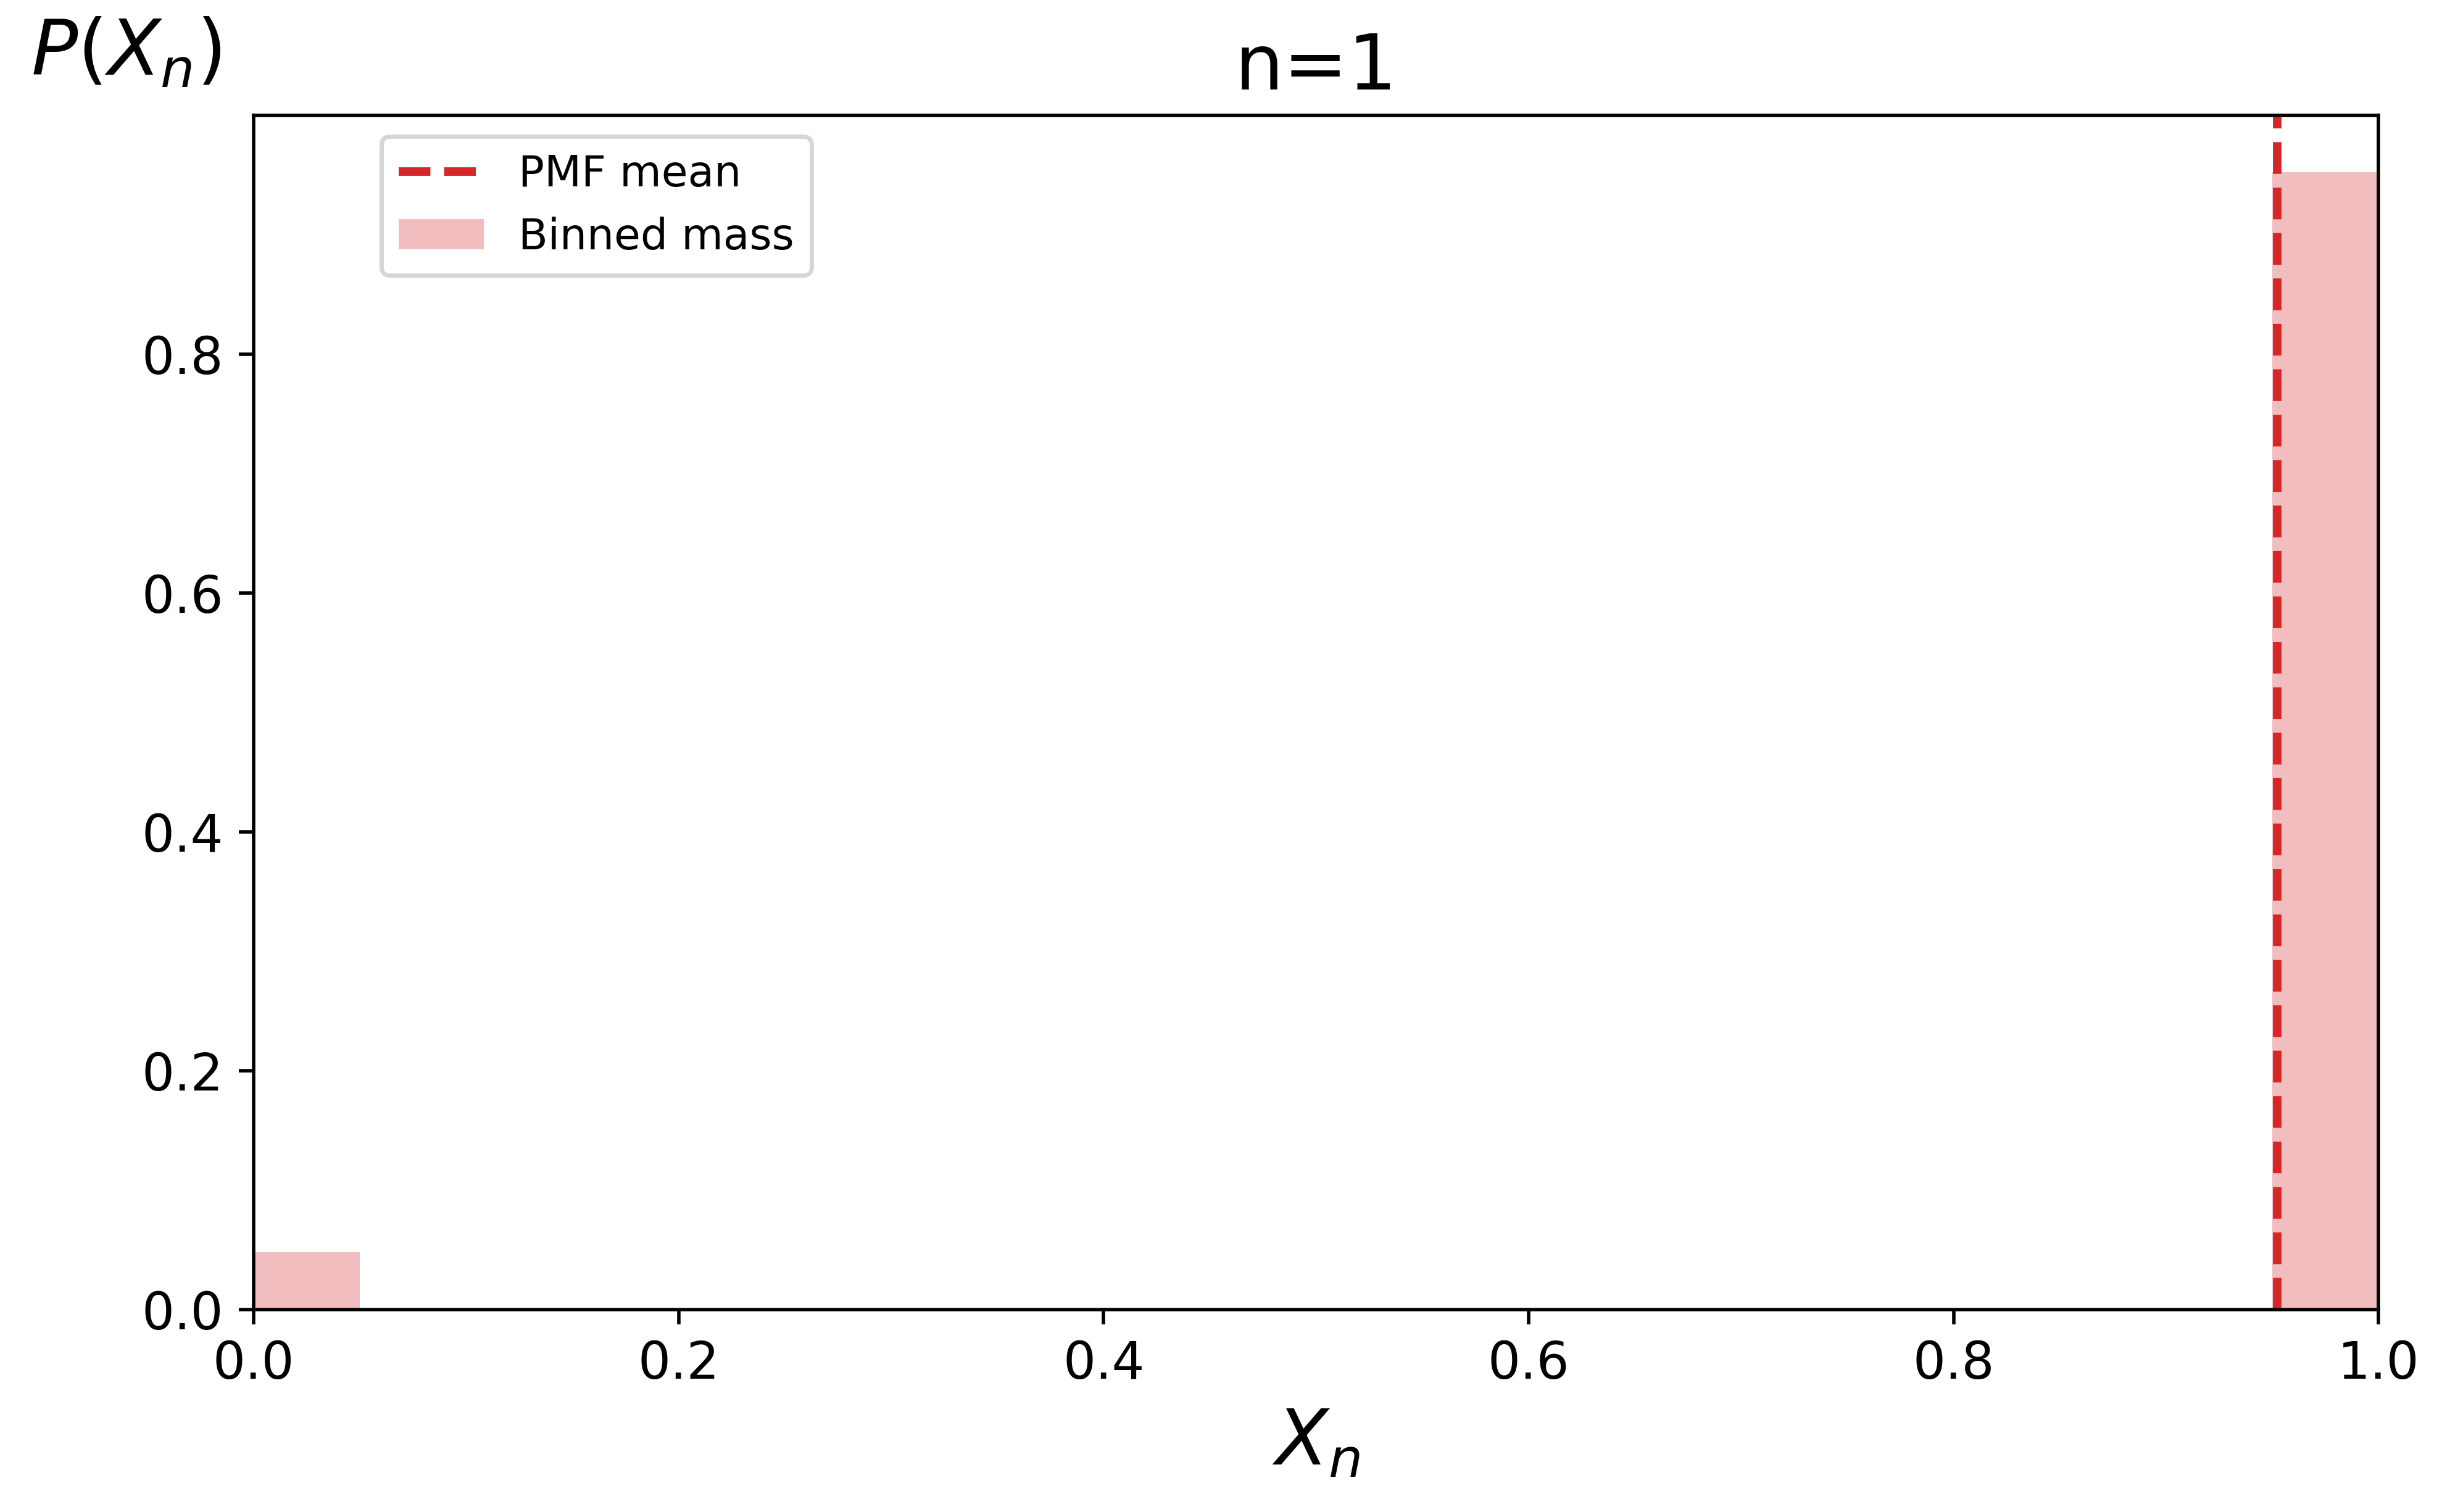

In [2]:
import math
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

# =========================
# Quantization / merging
# =========================

def make_qkey(merge="bin", round_digits=10, n_bins=4001):
    """
    Returns a function qkey(x) that merges close-by float outcomes.
    merge:
      - "round": round(x, round_digits)
      - "bin": snap x to uniform grid of n_bins points in [0,1]
    """
    if merge == "round":
        def qkey(x):
            x = float(x)
            if x < 0.0: x = 0.0
            if x > 1.0: x = 1.0
            return round(x, round_digits)
        return qkey

    if merge == "bin":
        n = int(n_bins)
        if n < 2:
            raise ValueError("n_bins must be >= 2")
        def qkey(x):
            x = float(x)
            if x < 0.0: x = 0.0
            if x > 1.0: x = 1.0
            idx = int(x * (n - 1) + 0.5)   # nearest grid point
            if idx < 0: idx = 0
            if idx > n - 1: idx = n - 1
            return idx / (n - 1)
        return qkey

    raise ValueError("merge must be 'round' or 'bin'")

def prune_pmf(pmf, p_min=0.0, max_states=None):
    """
    Optional: drop tiny-probability states (approximation). Keeps runtime sane if needed.
    """
    if p_min > 0.0:
        pmf = {x:p for x,p in pmf.items() if p >= p_min}
    if max_states is not None and len(pmf) > max_states:
        # keep largest masses
        items = sorted(pmf.items(), key=lambda kv: kv[1], reverse=True)[:max_states]
        pmf = dict(items)
    return pmf

def normalize_to_mass(pmf, target_mass):
    s = sum(pmf.values())
    if s <= 0.0:
        return {}
    scale = target_mass / s
    return {x: p * scale for x, p in pmf.items()}

# =========================
# Physics rules
# =========================

def c_to_p(c):
    return 1.0 - math.sqrt(max(0.0, 1.0 - c*c))

def para_cep(p1, p2):
    return 1.0 - (1.0 - p1) * (1.0 - p2)

def para_conpt(cu, cv):
    # Correct rule from your sheet: M = max(1/2, m(cu)*m(cv)), Para = 2*sqrt(M(1-M))
    # where m(c) = (1 + sqrt(1-c^2))/2
    mu = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cu*cu)))
    mv = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cv*cv)))
    M = max(0.5, mu * mv)
    return 2.0 * math.sqrt(max(0.0, M * (1.0 - M)))

# =========================
# Convolution-like ops on nonzero PMFs
# =========================

def mul_convolve(pmfA, pmfB, qkey):
    out = defaultdict(float)
    itemsA = list(pmfA.items())
    itemsB = list(pmfB.items())
    for a, pa in itemsA:
        for b, pb in itemsB:
            out[qkey(a * b)] += pa * pb
    return dict(out)

def mul_self_convolve(pmf, qkey):
    # half the work: i<=j
    out = defaultdict(float)
    items = list(pmf.items())
    m = len(items)
    for i in range(m):
        a, pa = items[i]
        for j in range(i, m):
            b, pb = items[j]
            mult = 2.0 if j > i else 1.0
            out[qkey(a * b)] += mult * pa * pb
    return dict(out)

def para_convolve(pmfA, pmfB, para_func, qkey):
    out = defaultdict(float)
    itemsA = list(pmfA.items())
    itemsB = list(pmfB.items())
    for a, pa in itemsA:
        for b, pb in itemsB:
            out[qkey(para_func(a, b))] += pa * pb
    return dict(out)

def para_self_convolve(pmf, para_func, qkey):
    out = defaultdict(float)
    items = list(pmf.items())
    m = len(items)
    for i in range(m):
        a, pa = items[i]
        for j in range(i, m):
            b, pb = items[j]
            mult = 2.0 if j > i else 1.0
            out[qkey(para_func(a, b))] += mult * pa * pb
    return dict(out)

# =========================
# Series chain + Parallel combine with operational probabilities
# =========================

def series_chain(dist_nz, p0, L, eta_s, qkey, p_min=0.0, max_states=None):
    """
    Reduce a chain of length L of i.i.d copies of X (dist_nz + p0) using series multiplication.
    ConPT: each of the (L-1) series reductions succeeds with probability eta_s.
    CEP: call this with eta_s=1.
    """
    if L == 1:
        return dict(dist_nz), p0

    q = 1.0 - p0
    # Nonzero requires all L pieces nonzero and all (L-1) series ops succeed
    q_chain = (q ** L) * (eta_s ** (L - 1))
    p0_chain = 1.0 - q_chain

    # distribution over nonzero outcomes = product of L independent draws from dist_nz
    pmf_prod = dict(dist_nz)
    for step in range(L - 1):
        # first step is self-convolution (fast) if still the base pmf
        if step == 0 and pmf_prod is dist_nz:
            pmf_prod = mul_self_convolve(pmf_prod, qkey)
        else:
            pmf_prod = mul_convolve(pmf_prod, dist_nz, qkey)

        pmf_prod = prune_pmf(pmf_prod, p_min=p_min, max_states=max_states)

    # scale mass to q_chain (to include eta_s^(L-1) and exclude zeros)
    pmf_prod = normalize_to_mass(pmf_prod, q_chain)
    return pmf_prod, p0_chain

def parallel_combine(pmfU, p0U, pmfV, p0V, para_func, eta_p, qkey, p_min=0.0, max_states=None):
    """
    Parallel combine two branches:
      - if one is zero and the other nonzero -> output = surviving branch (no parallel op)
      - if both nonzero -> parallel op succeeds with prob eta_p -> output Para(...)
        else -> output 0
    """
    out = defaultdict(float)

    # one survives
    for w, pw in pmfU.items():
        out[w] += p0V * pw
    for w, pw in pmfV.items():
        out[w] += p0U * pw

    qU = 1.0 - p0U
    qV = 1.0 - p0V

    # both survive and parallel succeeds
    # if pmfU and pmfV are same object, use self-convolution optimization
    if pmfU is pmfV:
        pmf_para = para_self_convolve(pmfU, para_func, qkey)
    else:
        pmf_para = para_convolve(pmfU, pmfV, para_func, qkey)

    pmf_para = prune_pmf(pmf_para, p_min=p_min, max_states=max_states)
    pmf_para = normalize_to_mass(pmf_para, eta_p * (qU * qV))

    for w, pw in pmf_para.items():
        out[w] += pw

    out = dict(out)
    out = prune_pmf(out, p_min=p_min, max_states=max_states)

    q_out = sum(out.values())
    p0_out = 1.0 - q_out
    return out, p0_out

# =========================
# Main evolution for UV flower
# =========================

def sponge_distribution_uv(
    n, U, V,
    mode="conpt",
    x=0.8,
    eta0=1.0,
    eta_s=1.0,
    eta_p=1.0,
    merge="bin",
    round_digits=10,
    n_bins=4001,
    p_min=0.0,
    max_states=None
):
    """
    Returns (pmf_nz, p0) for sponge crossing at generation n.
    pmf_nz excludes x=0; p0 is the mass at 0.

    merge controls runtime:
      - merge="round": more exact but can explode
      - merge="bin": fast; caps support to <= n_bins (recommended for n>=4)
    """
    qkey = make_qkey(merge=merge, round_digits=round_digits, n_bins=n_bins)

    if mode == "cep":
        # weights are p = 1 - sqrt(1-c^2), and stochasticity is per-edge via eta0
        para_func = para_cep
        x0 = qkey(c_to_p(x))
        p0 = 1.0 - eta0
        pmf = {x0: eta0} if eta0 > 0 else {}
        eta_s_eff = 1.0
        eta_p_eff = 1.0

    elif mode == "conpt":
        # weights are concurrence; leaf deterministic; ops succeed with eta_s, eta_p
        para_func = para_conpt
        p0 = 0.0
        pmf = {qkey(x): 1.0}
        eta_s_eff = eta_s
        eta_p_eff = eta_p

    else:
        raise ValueError("mode must be 'cep' or 'conpt'")

    for _ in range(n):
        pmfU, p0U = series_chain(pmf, p0, L=U, eta_s=eta_s_eff, qkey=qkey, p_min=p_min, max_states=max_states)
        pmfV, p0V = series_chain(pmf, p0, L=V, eta_s=eta_s_eff, qkey=qkey, p_min=p_min, max_states=max_states)
        pmf, p0 = parallel_combine(pmfU, p0U, pmfV, p0V, para_func, eta_p_eff, qkey=qkey, p_min=p_min, max_states=max_states)

    # ensure no x=0 stored in pmf (keep it in p0)
    if 0.0 in pmf:
        p0 += pmf.pop(0.0)
    return pmf, p0


def c_to_p(c):
    return 1.0 - math.sqrt(max(0.0, 1.0 - c*c))

def para_conpt(cu, cv):
    # Correct: M = max(1/2, m(cu)*m(cv)), Para = 2*sqrt(M(1-M))
    mu = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cu*cu)))
    mv = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cv*cv)))
    M = max(0.5, mu * mv)
    return 2.0 * math.sqrt(max(0.0, M * (1.0 - M)))

def expected_mean_cep(n, U, V, c_init, eta0):
    """
    Expected sponge crossing for CEP as deterministic renorm on edge prob p0=eta0*p(c).
    """
    p = eta0 * c_to_p(c_init)  # n=0: single edge survives with prob eta0
    for _ in range(n):
        p = 1.0 - (1.0 - p**U) * (1.0 - p**V)
    return max(0.0, min(1.0, p))

def expected_mean_conpt(n, U, V, c_init, eta_s, eta_p):
    """
    Expected sponge crossing for ConPT using your n=1 case-probability decomposition,
    applied recursively with deterministic input x=c_k.
    """
    x = c_init  # n=0
    aU = eta_s ** (U - 1)
    aV = eta_s ** (V - 1)
    aUV = eta_s ** (U + V - 2)

    for _ in range(n):
        xU = x ** U
        xV = x ** V

        P  = eta_p * aUV
        S1 = aU * (1.0 - aV)
        S2 = aV * (1.0 - aU)

        x = P * para_conpt(xU, xV) + S1 * xU + S2 * xV
        x = max(0.0, min(1.0, x))

    return x


# =========================
# Plotting: circles only, axes 0..1
# =========================

def plot_pmf_points(pmf_nz, p0, title="", include_zero=True):
    xs = list(pmf_nz.keys())
    ps = list(pmf_nz.values())
    if include_zero:
        xs.append(0.0)
        ps.append(p0)

    # sort for nicer display
    pairs = sorted(zip(xs, ps), key=lambda t: t[0])
    xs = [a for a,_ in pairs]
    ps = [b for _,b in pairs]

    plt.figure()
    plt.scatter(xs, ps, s=35)  # circles default
    plt.xlim(0, 1)
    plt.xlabel("effective weight")
    plt.ylabel("probability mass")
    plt.title(title)
    plt.show()


def q_inf_conpt_fixed_point(U, V, eta_s, eta_p, *, tol=1e-14, max_iter=200000):
    """
    Solve q = F(q) for q in [0,1], where q = P(X_inf > 0) under ConPT operational success.
    Fixed-point iteration from q0=1 converges to the largest fixed point (the relevant one).
    """
    U = int(U); V = int(V)
    eta_s = float(eta_s); eta_p = float(eta_p)

    def F(q):
        qU = (eta_s ** (U - 1)) * (q ** U)
        qV = (eta_s ** (V - 1)) * (q ** V)
        return qU * (1.0 - qV) + qV * (1.0 - qU) + eta_p * qU * qV

    q = 1.0
    for _ in range(max_iter):
        q_next = F(q)
        if abs(q_next - q) < tol:
            return float(q_next)
        q = q_next
    return float(q)



def pmf_mean_full(pmf_nz):
    return float(sum(x * p for x, p in pmf_nz.items()))

def plot_pmf_clean_with_qinf(
    pmf_nz, p0,
    *,
    mode="conpt",
    n=1, U=2, V=2,
    c_init=0.8,
    eta_s=0.95, eta_p=0.95,
    eta0=1.0,
    n_bins_plot=40,
    include_zero=True,
    label_fs = 18
):
    mode = mode.lower()
    color = "tab:red" if mode == "conpt" else "tab:blue"

    # Build plotting support
    xs = list(pmf_nz.keys())
    ps = list(pmf_nz.values())
    if include_zero:
        xs.append(0.0)
        ps.append(p0)

    xs = np.asarray(xs, float)
    ps = np.asarray(ps, float)

    # Bin mass on [0,1]
    edges = np.linspace(0.0, 1.0, n_bins_plot + 1)
    bin_mass = np.zeros(n_bins_plot, float)

    idx = np.searchsorted(edges, xs, side="right") - 1
    idx = np.clip(idx, 0, n_bins_plot - 1)
    for i, mass in zip(idx, ps):
        bin_mass[i] += mass

    centers = 0.5 * (edges[:-1] + edges[1:])
    width = edges[1] - edges[0]

    # PMF mean
    mean_pmf = pmf_mean_full(pmf_nz)

    # q_inf line (ConPT only; for CEP there isn’t a simple closed-form q_inf in this model)
    q_inf = None
    if mode == "conpt":
        q_inf = q_inf_conpt_fixed_point(U, V, eta_s, eta_p, tol=1e-15)

    fig, ax = plt.subplots(figsize=(8, 5), dpi=500)

    ax.bar(
        centers, bin_mass,
        width=width * 1.0,
        color=color, alpha=0.3,
        edgecolor="none",
        label="Binned mass"
    )
    # ax.scatter(xs, ps, s=35, alpha=0.50, color=color, label="PMF points")

    # PMF mean (dashed)
    ax.axvline(mean_pmf, linestyle="--", color=color, linewidth=2, label="PMF mean")

    # q_inf (different dash style)
    #if q_inf is not None:
    #    ax.axvline(q_inf, linestyle=":", color=color, linewidth=2, label=r"$s_\infty$")

    ax.set_xlim(0, 1)
    # title with n
    ax.set_title(f"n={n}",fontsize = 18)

    ax.tick_params(axis="both", which="both", labelsize=12)
    ax.set_xlabel(r"$X_n$", fontsize=18)
    ax.set_ylabel(r"$P(X_n)$", rotation=0, labelpad=25, fontsize=18)
    ax.yaxis.set_label_coords(-0.06, 1.02)

    # No title
    ax.legend(loc="upper left", bbox_to_anchor=(0.05,1.0), frameon=True)

    fig.tight_layout()
    plt.show()


# Example (ConPT)
n = 1
U, V = 2, 2
c_init = 1.0
eta_s = 0.95
eta_p = 0.95
#above thresh -> c = 0.85, eta_s = eta_p = 0.95
#below thresh -> c = 0.85, eta_s = eta_p = 0.90

pmf_con, p0_con = sponge_distribution_uv(
    n=n, U=U, V=V, mode="conpt",
    x=c_init, eta_s=eta_s, eta_p=eta_p,
    merge="bin", round_digits=12, p_min=1e-12, n_bins=2001
)
plot_pmf_clean_with_qinf(
    pmf_con, p0_con,
    mode="conpt",
    n=n, U=U, V=V,
    c_init=c_init,
    eta_s=eta_s, eta_p=eta_p,
    n_bins_plot=20
)


## Operational Percolation threshold 
* Heat plot - eta_s vs eta_q, where we solve for the critical threshold where q_infinity is no longer real

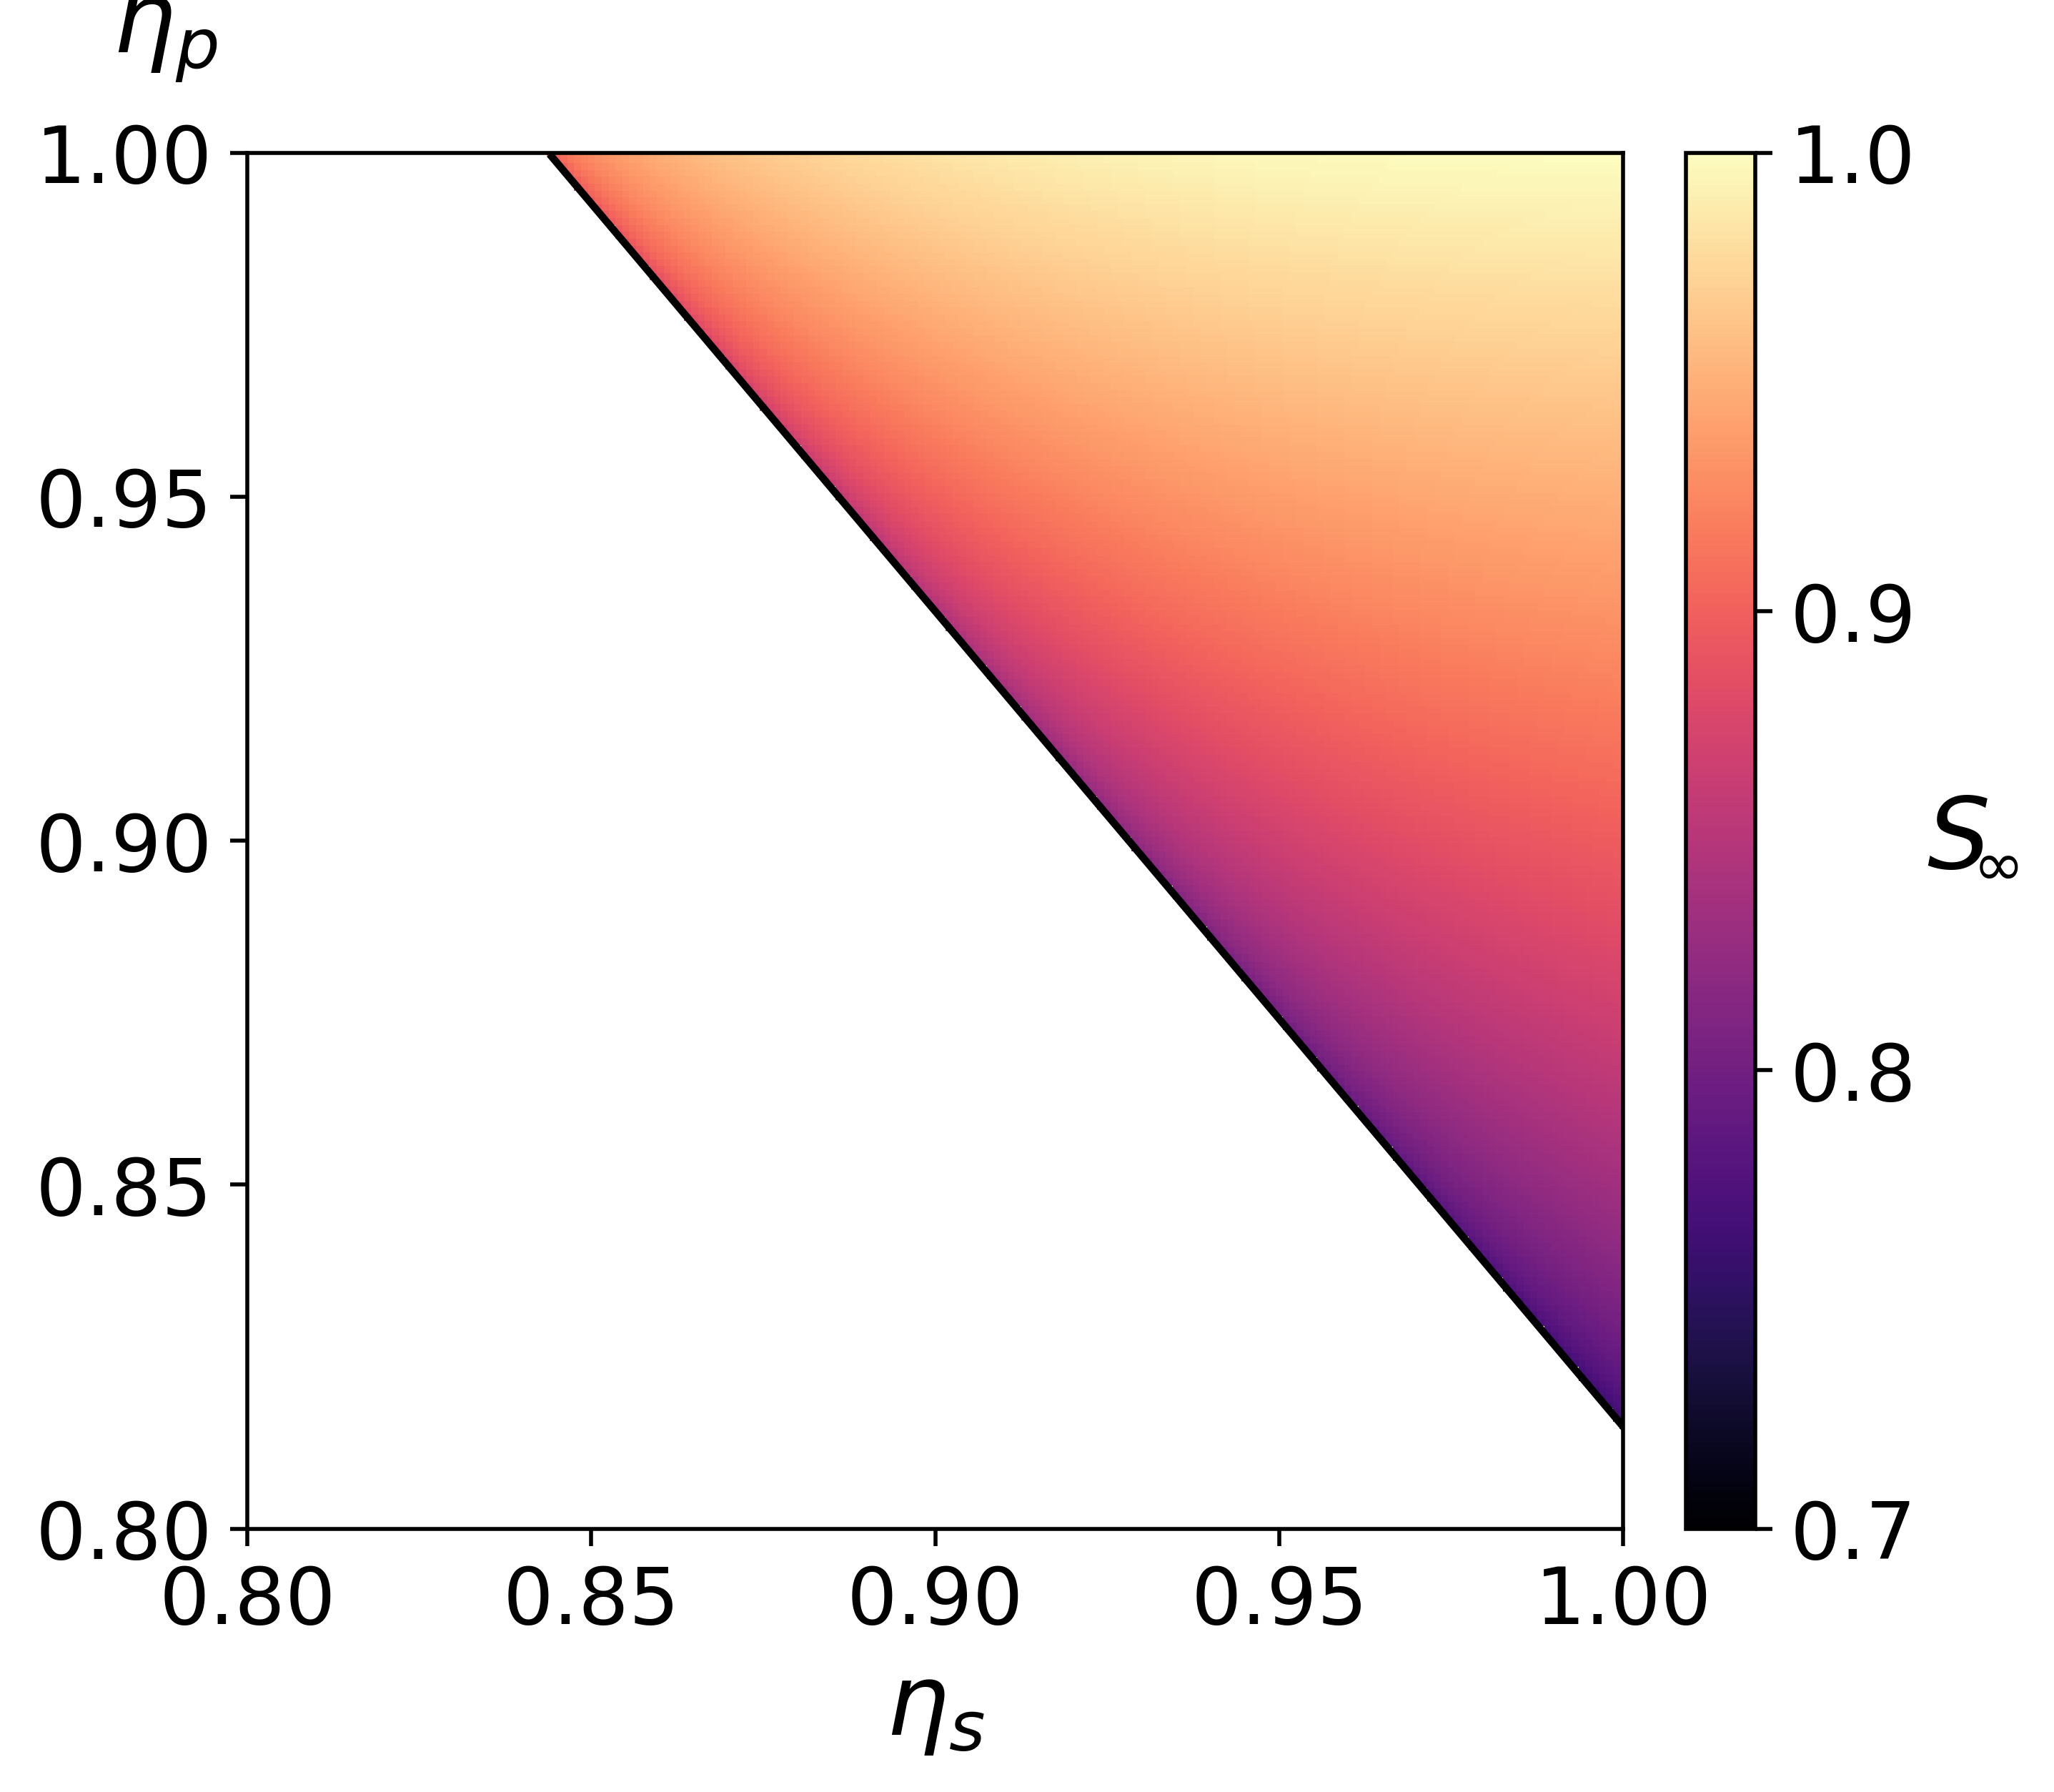

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import math

# ============================================================
# Operational RG map for survival probability q_n = P(X_n > 0)
# ============================================================

def q_map(q, U, V, eta_s, eta_p):
    """
    Operational recursion:
        q_{n+1} = qU + qV - (2 - eta_p) qU qV
    with qU = eta_s^(U-1) q^U and qV = eta_s^(V-1) q^V
    """
    q = np.clip(q, 0.0, 1.0)
    qU = (eta_s ** (U - 1)) * np.power(q, U)
    qV = (eta_s ** (V - 1)) * np.power(q, V)
    out = qU + qV - (2.0 - eta_p) * qU * qV
    return np.clip(out, 0.0, 1.0)


def q_inf_grid(U, V, eta_s_grid, eta_p_grid, tol=1e-13, max_iter=20000):
    """
    Vectorized fixed point from q0=1:
        q_{n+1} = q_map(q_n)
    Returns q_inf on the full (eta_s, eta_p) grid.
    """
    q = np.ones_like(eta_s_grid, dtype=np.float64)
    for _ in range(max_iter):
        qn = q_map(q, U, V, eta_s_grid, eta_p_grid)
        if np.max(np.abs(qn - q)) < tol:
            q = qn
            break
        q = qn
    return q


# ============================================================
# Exact operational threshold curve: solve f(q)=0 and f'(q)=0
# ============================================================

def _eta_p_from_fixed_point(q, U, V, eta_s):
    """
    From f(q)=R(q)-q=0:
        eta_p = 2 - (qU + qV - q)/(qU qV)
    (valid when qU qV > 0).
    """
    a = eta_s ** (U - 1)
    b = eta_s ** (V - 1)
    qU = a * (q ** U)
    qV = b * (q ** V)
    denom = qU * qV
    if denom <= 0.0:
        return np.nan
    return 2.0 - (qU + qV - q) / denom


def _g_of_q(q, U, V, eta_s):
    """
    g(q) = R'(q) - 1, but with eta_p eliminated using the fixed-point equation.
    Returns (g, eta_p). Only meaningful if eta_p in [0,1].
    """
    q = float(q)
    if not (0.0 < q < 1.0):
        return np.nan, np.nan

    a = eta_s ** (U - 1)
    b = eta_s ** (V - 1)

    qU = a * (q ** U)
    qV = b * (q ** V)
    denom = qU * qV
    if denom <= 0.0:
        return np.nan, np.nan

    eta_p = 2.0 - (qU + qV - q) / denom
    if not (0.0 <= eta_p <= 1.0):
        return np.nan, eta_p

    dU = a * U * (q ** (U - 1))
    dV = b * V * (q ** (V - 1))

    # R'(q) = dU + dV - (2-eta_p)(dU*qV + qU*dV)
    Rprime = dU + dV - (2.0 - eta_p) * (dU * qV + qU * dV)
    return Rprime - 1.0, eta_p


def threshold_curve_eta_p(U, V, eta_s_vals, q_scan=6000, q_eps=1e-8, bisect_iter=80):
    """
    For each eta_s in eta_s_vals, find (eta_s, eta_p_th) on the operational threshold curve
    by solving:
        f(q)=0  and  f'(q)=0
    via elimination eta_p = eta_p(q) from f(q)=0, then root g(q)=R'(q)-1=0.
    """
    eta_s_out = []
    eta_p_out = []

    q_grid = np.linspace(q_eps, 1.0 - q_eps, int(q_scan), dtype=np.float64)

    for eta_s in eta_s_vals:
        eta_s = float(eta_s)

        # Vectorized scan for sign changes of g(q)
        a = eta_s ** (U - 1)
        b = eta_s ** (V - 1)
        qU = a * np.power(q_grid, U)
        qV = b * np.power(q_grid, V)
        denom = qU * qV

        # eta_p(q) from fixed-point equation
        with np.errstate(divide="ignore", invalid="ignore"):
            eta_p = 2.0 - (qU + qV - q_grid) / denom

        # g(q) = R'(q) - 1
        dU = a * U * np.power(q_grid, U - 1)
        dV = b * V * np.power(q_grid, V - 1)
        Rprime = dU + dV - (2.0 - eta_p) * (dU * qV + qU * dV)
        g = Rprime - 1.0

        valid = np.isfinite(eta_p) & np.isfinite(g) & (eta_p >= 0.0) & (eta_p <= 1.0) & (denom > 0.0)
        gv = np.where(valid, g, np.nan)

        # If we hit a near-zero directly, accept it (rare but nice)
        idx_close = np.where(np.isfinite(gv) & (np.abs(gv) < 1e-6))[0]
        brackets = []
        if idx_close.size > 0:
            i = int(idx_close[0])
            lo = q_grid[max(i - 1, 0)]
            hi = q_grid[min(i + 1, len(q_grid) - 1)]
            brackets = [(lo, hi)]
        else:
            # Find sign changes between consecutive finite points
            finite = np.isfinite(gv)
            for i in range(len(q_grid) - 1):
                if finite[i] and finite[i + 1]:
                    gi, gj = gv[i], gv[i + 1]
                    if gi == 0.0:
                        brackets = [(q_grid[i], q_grid[i + 1])]
                        break
                    if gi * gj < 0.0:
                        brackets = [(q_grid[i], q_grid[i + 1])]
                        break

        if not brackets:
            continue

        lo, hi = brackets[0]
        glo, _ = _g_of_q(lo, U, V, eta_s)
        ghi, _ = _g_of_q(hi, U, V, eta_s)
        if not (np.isfinite(glo) and np.isfinite(ghi)):
            continue
        if glo == 0.0:
            q_star = lo
        elif ghi == 0.0:
            q_star = hi
        elif glo * ghi > 0.0:
            continue
        else:
            # Bisection
            q_star = None
            a_lo, a_hi = lo, hi
            g_lo, g_hi = glo, ghi
            for _ in range(bisect_iter):
                mid = 0.5 * (a_lo + a_hi)
                g_mid, _ = _g_of_q(mid, U, V, eta_s)
                if not np.isfinite(g_mid):
                    # If mid is invalid, shrink interval slightly (rare)
                    mid = np.nextafter(mid, a_lo)
                    g_mid, _ = _g_of_q(mid, U, V, eta_s)
                    if not np.isfinite(g_mid):
                        break
                if abs(g_mid) < 1e-12 or (a_hi - a_lo) < 1e-12:
                    q_star = mid
                    break
                if g_lo * g_mid <= 0.0:
                    a_hi, g_hi = mid, g_mid
                else:
                    a_lo, g_lo = mid, g_mid
            if q_star is None:
                q_star = 0.5 * (a_lo + a_hi)

        eta_p_star = _eta_p_from_fixed_point(q_star, U, V, eta_s)
        if np.isfinite(eta_p_star) and (0.0 <= eta_p_star <= 1.0):
            eta_s_out.append(eta_s)
            eta_p_out.append(float(eta_p_star))

    return np.array(eta_s_out, float), np.array(eta_p_out, float)


# ============================================================
# Main plotting function
# ============================================================
def _floor_to_step(x, step=0.1):
    return step * math.floor(x / step + 1e-12)

def plot_operational_threshold_heatmap(
    *,
    U=2, V=2,
    res=601,
    curve_points=1600,
    tol_qinf=1e-13,
    max_iter_qinf=20000,
    mask_tol=1e-12,
    cbar_step=0.1,
    pad=0.02,
    # fonts: matched to the second heatmap
    tick_fs=16,
    label_fs=20,
    qth_xy=(0.15, 0.25)
):
    # --- grid in eta-space ---
    eta_s_vals = np.linspace(0.0, 1.0, int(res), dtype=np.float64)
    eta_p_vals = np.linspace(0.0, 1.0, int(res), dtype=np.float64)
    ES, EP = np.meshgrid(eta_s_vals, eta_p_vals, indexing="xy")

    # --- q_inf heatmap ---
    qinf = q_inf_grid(U, V, ES, EP, tol=tol_qinf, max_iter=max_iter_qinf)

    # mask the non-percolating region
    qinf_masked = np.ma.masked_where(qinf <= mask_tol, qinf)

    # --- determine zoom bounds from percolating region ---
    perco = np.where(qinf > mask_tol)
    if perco[0].size == 0:
        raise RuntimeError("No percolating region found (q_inf>0 nowhere) for these parameters/resolution.")

    i_min, i_max = perco[0].min(), perco[0].max()
    j_min, j_max = perco[1].min(), perco[1].max()

    x0 = max(0.0, eta_s_vals[j_min] - pad)
    x1 = min(1.0, eta_s_vals[j_max] + pad)
    y0 = max(0.0, eta_p_vals[i_min] - pad)
    y1 = min(1.0, eta_p_vals[i_max] + pad)

    # --- rescale colorbar range ---
    qmin = float(qinf[perco].min())
    vmin = _floor_to_step(qmin, step=cbar_step)
    vmin = max(0.0, min(vmin, 1.0))
    vmax = 1.0

    # --- threshold curve (black) ---
    eta_s_curve = np.linspace(1e-6, 1.0, int(curve_points), dtype=np.float64)
    xs, yp_th = threshold_curve_eta_p(U, V, eta_s_curve)

    # --- q_th value to print in blank region ---
    # At threshold, q_th is the tangency fixed point q* (double root).
    # Your threshold_curve_eta_p currently returns eta_p_th(eta_s) but not q*.
    # We can estimate q_th numerically at a representative point on the curve:
    # choose mid-curve point within zoom window for stability.
    if xs.size > 0:
        # pick curve point closest to center of visible region
        x_center = 0.5 * (x0 + x1)
        k = int(np.argmin(np.abs(xs - x_center)))
        eta_s_th = float(xs[k])
        eta_p_th = float(yp_th[k])

        # compute q* by iterating from q0=1 at (eta_s_th, eta_p_th)
        # (at tangency this converges to the stable fixed point; near threshold q* is the nonzero one).
        q = 1.0
        for _ in range(200000):
            qn = q_map(q, U, V, eta_s_th, eta_p_th)
            if abs(qn - q) < 1e-14:
                break
            q = qn
        q_th = float(q)
    else:
        q_th = float("nan")

    # --- plot ---
    fig, ax = plt.subplots(figsize=(8, 5), dpi=500)

    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad(color="white")

    pc = ax.pcolormesh(
        eta_s_vals, eta_p_vals, qinf_masked,
        shading="auto",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    ax.plot(xs, yp_th, color="black", linewidth=1.5)

    # zoomed axes
    ax.set_xlim(0.8, 1.0)
    ax.set_ylim(0.8, 1.0)
    ax.set_aspect("equal", adjustable="box")

    ticks = [0.80, 0.85, 0.90, 0.95, 1.00]
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels([f"{t:.2f}" for t in ticks])
    ax.set_yticklabels([f"{t:.2f}" for t in ticks])

    # labels
    ax.set_xlabel(r"$\eta_s$", fontsize=label_fs)
    ax.set_ylabel(r"$\eta_p$", rotation=0, labelpad=18, fontsize=label_fs)
    ax.yaxis.set_label_coords(-0.06, 1.05)

    # tick font sizes
    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    # leave enough room on the right for the manual colorbar label
    fig.subplots_adjust(right=0.86)

    # colorbar
    cbar = fig.colorbar(pc, ax=ax, pad=0.03)
    cbar_ticks = np.arange(vmin, 1.0 + 1e-9, float(cbar_step))
    cbar.set_ticks(cbar_ticks)
    cbar.ax.tick_params(labelsize=tick_fs)

    # draw once so the colorbar position is known
    fig.canvas.draw()
    bbox = cbar.ax.get_position()

    # manual right-side horizontal label: S_infinity
    xlab = bbox.x1 + 0.06
    ylab = 0.5 * (bbox.y0 + bbox.y1)

    fig.text(
        xlab, ylab,
        r"$S$",
        fontsize=label_fs,
        ha="left",
        va="center"
    )

    fig.text(
        xlab + 0.016, ylab - 0.015,
        r"$\infty$",
        fontsize=0.62 * label_fs,
        ha="left",
        va="center"
    )

    plt.show()


# ============================================================
# Example call
# ============================================================
out = plot_operational_threshold_heatmap(
    U=2, V=2,
    res=1001,
    curve_points=1600,
    cbar_step=0.1,
    label_fs=20,
    tick_fs=16
)

In [25]:
plt.rcParams.update({"font.size": 14, "axes.labelsize": 18, "xtick.labelsize": 14, "ytick.labelsize": 14})


## Scaling of E(X_n)

In [46]:
import numpy as np
import matplotlib.pyplot as plt

def pmf_mean(pmf_nz):
    return float(sum(x * p for x, p in pmf_nz.items()))


def plot_conpt_scaling_vs_qinf(
    *,
    U=2, V=2,
    c_init=0.8,
    eta_s=1.0, eta_p=0.95,
    n_min=1, n_max=18,
    merge="bin",
    n_bins=250,
    round_digits=12,
    p_min=0.0,
    max_states=None,
    qinf_tol=1e-15,
    fit_from_n=3,
    fit_to_n=None,
    x_axis="L"  # NEW OPTION: "L" or "n"
):

    # ---- fixed point ----
    q_inf = q_inf_conpt_fixed_point(U, V, eta_s, eta_p, tol=qinf_tol)

    ns = np.arange(n_min, n_max + 1, dtype=int)
    Ls = (U ** ns).astype(float)

    means = []
    diffs = []

    for n in ns:

        pmf_nz, p0 = sponge_distribution_uv(
            n=n, U=U, V=V,
            mode="conpt",
            x=c_init,
            eta_s=eta_s, eta_p=eta_p,
            merge=merge,
            round_digits=round_digits,
            n_bins=n_bins,
            p_min=p_min,
            max_states=max_states
        )

        mu = pmf_mean(pmf_nz)

        means.append(mu)
        diffs.append(abs(mu - q_inf))

    means = np.array(means, float)
    diffs = np.array(diffs, float)

    # ---------- choose x variable ----------
    if x_axis == "L":
        xs = Ls
    elif x_axis == "n":
        xs = ns
    else:
        raise ValueError("x_axis must be 'L' or 'n'")

    # ---------- fitting ----------
    mask = diffs > 0
    xs_fit = xs[mask]
    ns_fit = ns[mask]
    d_fit = diffs[mask]

    if fit_from_n is not None:
        keep = ns_fit >= int(fit_from_n)
        xs_fit, d_fit = xs_fit[keep], d_fit[keep]
        ns_fit = ns_fit[keep]

    if fit_to_n is not None:
        keep = ns_fit <= int(fit_to_n)
        xs_fit, d_fit = xs_fit[keep], d_fit[keep]

    slope = np.nan
    intercept = np.nan

    # only meaningful for L scaling
    if x_axis == "L" and len(xs_fit) >= 2:
        slope, intercept = np.polyfit(np.log10(xs_fit), np.log10(d_fit), 1)

    if x_axis == "L":
        x_line = np.logspace(np.log10(xs.min()), np.log10(xs.max()), 200)
        d_line = 10 ** (intercept + slope * np.log10(x_line))
    else:
        x_line = np.linspace(xs.min(), xs.max(), 200)
        d_line = np.full_like(x_line, np.nan)

    # ---------- plotting ----------
    fig, ax = plt.subplots(figsize=(8,5), dpi=500)

    ax.scatter(
        xs, diffs,
        color="tab:red",
        s=45,
        label=f"Numerical results of ({U},{V}) flower"
    )

    if x_axis == "L" and np.isfinite(slope):
        ax.plot(
            x_line, d_line,
            color="tab:red",
            linewidth=1.5,
            label="Line of best fit"
        )

    # scales
    if x_axis == "L":
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(r"$L = U^n$")
    else:
        ax.set_xlabel(r"$n$")
        ax.set_yscale("log")

    ax.set_ylabel(
        r"$\left|\mathbb{E}[X_n]-s_\infty\right|$",
        rotation=0,
        labelpad=25,
    )
    ax.yaxis.set_label_coords(-0.02, 1.05)

    ax.legend(loc="upper right", frameon=True)

    ax.text(
        0.98, 0.70,
        rf"$s_\infty={q_inf:.6g}$",
        transform=ax.transAxes,
        ha="right",
        va="top",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    plt.show()

    return {
        "ns": ns,
        "Ls": Ls,
        "means": means,
        "diffs": diffs,
        "q_inf": q_inf,
        "nu": slope
    }


# Example
results = plot_conpt_scaling_vs_qinf(
    U=2, V=2,
    c_init=0.85,
    eta_s=0.95, eta_p=0.95,
    n_min=1, n_max=13,
    merge="bin",
    n_bins=2001,
    fit_from_n=11,
    x_axis="n"   # <-- change to "L" or "n"
)

KeyboardInterrupt: 

## Error Correction Polynomial

q_inf = 0.9382177956230807
m (fit from n >= 10) = -0.7717693977
alpha0 (mean from n >= 15) = 0.6687147032
omega (grid best, fit from n >= 3) = 0.7627591137
approx = pade22, params = {'b1': 634.2236119129186, 'b2': 124.24792386684834, 'c1': 623.1988774914245, 'c2': 3589.478958290395}
SSE(best) = 1.51855e-05


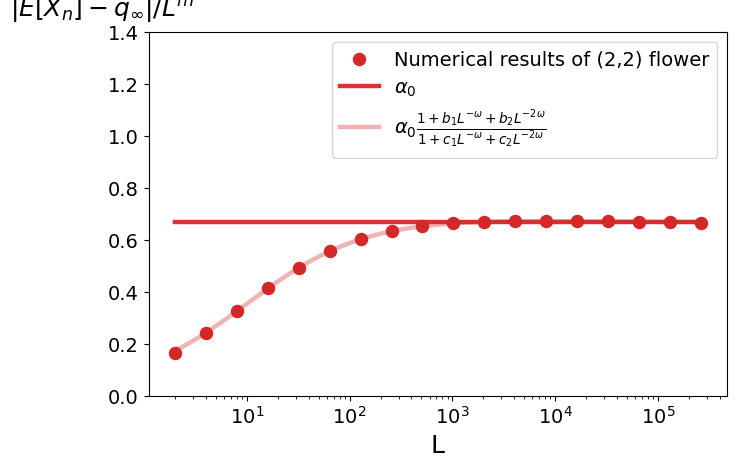

In [69]:
import numpy as np
import math
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Utility: survival fixed point q_inf for operational ConPT
# ------------------------------------------------------------
def q_survival_map(q, U, V, eta_s, eta_p):
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    return qU + qV - (2.0 - eta_p) * qU * qV

def q_inf_fixed_point(U, V, eta_s, eta_p, tol=1e-15, max_iter=200000):
    q = 1.0
    for _ in range(max_iter):
        qn = q_survival_map(q, U, V, eta_s, eta_p)
        if abs(qn - q) < tol:
            return float(max(0.0, min(1.0, qn)))
        q = qn
    return float(max(0.0, min(1.0, q)))

# ------------------------------------------------------------
# Fit m from tail: Delta(L) ~ const * L^m
# ------------------------------------------------------------
def fit_m_from_tail(L, Delta, fit_from_idx):
    L = np.asarray(L, float)[fit_from_idx:]
    D = np.asarray(Delta, float)[fit_from_idx:]
    mask = np.isfinite(L) & np.isfinite(D) & (L > 0) & (D > 0)
    L, D = L[mask], D[mask]
    if len(L) < 2:
        return None
    slope, intercept = np.polyfit(np.log(L), np.log(D), 1)
    return float(slope), float(intercept)

# ------------------------------------------------------------
# Models for Phi(x) with Phi(0)=1
# where x = L^{-omega}, Y(L) = alpha0 * Phi(x)
# ------------------------------------------------------------
def phi_poly3(x, a1, a2, a3):
    return 1.0 + a1*x + a2*x**2 + a3*x**3

def phi_pade11(x, b1, c1):
    return (1.0 + b1*x) / (1.0 + c1*x)

def phi_pade21(x, b1, b2, c1):
    return (1.0 + b1*x + b2*x**2) / (1.0 + c1*x)

def phi_pade22(x, b1, b2, c1, c2):
    return (1.0 + b1*x + b2*x**2) / (1.0 + c1*x + c2*x**2)

# ------------------------------------------------------------
# Linear least squares fit for Padé models (no nonlinear solver)
# We fit Y/alpha0 = Phi(x). alpha0 is taken as mean(Y) on far tail.
# Each Padé can be fit by rewriting into a linear system:
#
#   (1 + c1 x + c2 x^2) * r  = 1 + b1 x + b2 x^2
# where r = Y/alpha0.
#
# Rearranged:
#   r - 1 = b1 x + b2 x^2 - c1 x r - c2 x^2 r
# which is linear in unknowns (b1,b2,c1,c2).
# ------------------------------------------------------------
def fit_correction_model(L, Y, omega, alpha0, approx, fit_from_idx):
    L = np.asarray(L, float)
    Y = np.asarray(Y, float)

    Lf = L[fit_from_idx:]
    Yf = Y[fit_from_idx:]
    mask = np.isfinite(Lf) & np.isfinite(Yf) & (Lf > 0)
    Lf, Yf = Lf[mask], Yf[mask]
    if len(Lf) < 6:
        return None

    x = Lf ** (-omega)
    r = Yf / alpha0

    # target vector
    t = (r - 1.0)

    if approx == "poly3":
        # t = a1 x + a2 x^2 + a3 x^3
        A = np.vstack([x, x**2, x**3]).T
        coef, *_ = np.linalg.lstsq(A, t, rcond=None)
        a1, a2, a3 = coef.tolist()
        return {"a1": a1, "a2": a2, "a3": a3}

    if approx == "pade11":
        # t = b1 x - c1 x r
        A = np.vstack([x, -x*r]).T
        coef, *_ = np.linalg.lstsq(A, t, rcond=None)
        b1, c1 = coef.tolist()
        return {"b1": b1, "c1": c1}

    if approx == "pade21":
        # t = b1 x + b2 x^2 - c1 x r
        A = np.vstack([x, x**2, -x*r]).T
        coef, *_ = np.linalg.lstsq(A, t, rcond=None)
        b1, b2, c1 = coef.tolist()
        return {"b1": b1, "b2": b2, "c1": c1}

    if approx == "pade22":
        # t = b1 x + b2 x^2 - c1 x r - c2 x^2 r
        A = np.vstack([x, x**2, -x*r, -(x**2)*r]).T
        coef, *_ = np.linalg.lstsq(A, t, rcond=None)
        b1, b2, c1, c2 = coef.tolist()
        return {"b1": b1, "b2": b2, "c1": c1, "c2": c2}

    raise ValueError("approx must be one of: poly3, pade11, pade21, pade22")

def eval_model_Y(L, omega, alpha0, approx, params):
    x = np.asarray(L, float) ** (-omega)
    if approx == "poly3":
        phi = phi_poly3(x, params["a1"], params["a2"], params["a3"])
    elif approx == "pade11":
        phi = phi_pade11(x, params["b1"], params["c1"])
    elif approx == "pade21":
        phi = phi_pade21(x, params["b1"], params["b2"], params["c1"])
    elif approx == "pade22":
        phi = phi_pade22(x, params["b1"], params["b2"], params["c1"], params["c2"])
    else:
        raise ValueError
    return alpha0 * phi

def denom_min_over_range(L, omega, approx, params):
    x = np.asarray(L, float) ** (-omega)
    if approx == "pade11":
        d = 1.0 + params["c1"]*x
    elif approx == "pade21":
        d = 1.0 + params["c1"]*x
    elif approx == "pade22":
        d = 1.0 + params["c1"]*x + params["c2"]*x**2
    else:
        return None
    return float(np.min(d))

# ------------------------------------------------------------
# MAIN PLOT
# ------------------------------------------------------------
def plot_error_correction_pade(
    *,
    U=2, V=2,
    eta_s=0.95, eta_p=0.95,
    c_init=0.85,
    n_min=1, n_max=18,
    n_bins=2001,
    # fit windows
    fit_from_n_m=10,          # tail for m
    fit_from_n_alpha0=15,     # tail for alpha0 plateau
    fit_from_n_corr=3,        # window for omega + correction fit
    # omega settings
    omega_grid=(0.02, 2.5, 1400),
    # model
    approx="pade22",          # "poly3", "pade11", "pade21", "pade22"
    # plot cosmetics
    y_top_min=1.4,
    y_step=0.2
):
    # compute q_inf
    q_inf = q_inf_fixed_point(U, V, eta_s, eta_p)

    # compute E[X_n]
    binner = ConPTBinner(n_bins=n_bins)   # must exist in your notebook
    ns = np.arange(n_min, n_max+1, dtype=int)
    Ls = (U**ns).astype(float)
    EX = np.array([binner.mean_Xn(int(n), U, V, float(c_init), float(eta_s), float(eta_p)) for n in ns], float)
    Delta = np.abs(EX - q_inf)

    # fit m
    idx_m = int(np.where(ns >= fit_from_n_m)[0][0])
    m_fit = fit_m_from_tail(Ls, Delta, idx_m)
    if m_fit is None:
        raise RuntimeError("Not enough positive Delta values to fit m.")
    m, _ = m_fit

    # flattened Y
    Y = Delta / (Ls**m)

    # alpha0 from late plateau
    idx_a0 = int(np.where(ns >= fit_from_n_alpha0)[0][0])
    alpha0 = float(np.mean(Y[idx_a0:]))

    # choose omega by grid search: minimize SSE of chosen approx (linear LS each omega)
    idx_corr = int(np.where(ns >= fit_from_n_corr)[0][0])
    om_min, om_max, om_N = omega_grid
    omegas = np.linspace(om_min, om_max, int(om_N))

    best = None  # (sse, omega, params)
    for om in omegas:
        params = fit_correction_model(Ls, Y, om, alpha0, approx, idx_corr)
        if params is None:
            continue
        Yhat = eval_model_Y(Ls[idx_corr:], om, alpha0, approx, params)
        resid = (Y[idx_corr:] - Yhat)
        sse = float(np.dot(resid, resid))

        # Penalize Padé if denominator gets close to zero in fit range
        if approx.startswith("pade"):
            dmin = denom_min_over_range(Ls[idx_corr:], om, approx, params)
            if dmin is not None and dmin < 0.25:
                sse *= (1.0 + (0.25 - dmin)*50.0)

        if (best is None) or (sse < best[0]):
            best = (sse, float(om), params)

    if best is None:
        raise RuntimeError("Omega/model fit failed. Try widening omega_grid or lowering fit_from_n_corr.")

    sse_best, omega, params = best

    # model curve, but avoid plotting where Padé denominator flips sign
    L_line = np.logspace(np.log10(Ls.min()), np.log10(Ls.max()), 700)
    if approx.startswith("pade"):
        dmin_line = denom_min_over_range(L_line, omega, approx, params)
        if dmin_line is not None and dmin_line <= 0.0:
            # clip to region where denom>0.05
            x = L_line**(-omega)
            if approx == "pade11" or approx == "pade21":
                denom = 1.0 + params["c1"]*x
            else:
                denom = 1.0 + params["c1"]*x + params["c2"]*x**2
            ok = denom > 0.05
            L_line = L_line[ok]

    Y_line = eval_model_Y(L_line, omega, alpha0, approx, params)

    # print parameters
    print(f"q_inf = {q_inf:.16g}")
    print(f"m (fit from n >= {fit_from_n_m}) = {m:.10g}")
    print(f"alpha0 (mean from n >= {fit_from_n_alpha0}) = {alpha0:.10g}")
    print(f"omega (grid best, fit from n >= {fit_from_n_corr}) = {omega:.10g}")
    print(f"approx = {approx}, params = { {k: float(v) for k,v in params.items()} }")
    print(f"SSE(best) = {sse_best:.6g}")

    # --- plot ---
    fig, ax = plt.subplots(figsize=(7.6, 4.9))

    # points (red)
    ax.scatter(Ls, Y, s=75, color="tab:red", label=f"Numerical results of ({U},{V}) flower")

    # alpha0 (dark red horizontal)
    ax.plot([Ls.min(), Ls.max()], [alpha0, alpha0], lw=3.2, color="tab:red", alpha=0.95, label=r"$\alpha_0$")

    # model curve (lighter red)
    # label string with parameters
    if approx == "poly3":
        lab = rf"$\alpha_0(1+a_1L^{{-\omega}}+a_2L^{{-2\omega}}+a_3L^{{-3\omega}})$"
        #ptxt = rf"$\omega={omega:.3g},\ a_1={params['a1']:.3g},\ a_2={params['a2']:.3g},\ a_3={params['a3']:.3g}$"
    elif approx == "pade11":
        lab = rf"$\alpha_0\frac{{1+b_1L^{{-\omega}}}}{{1+c_1L^{{-\omega}}}}$"
        #ptxt = rf"$\omega={omega:.3g},\ b_1={params['b1']:.3g},\ c_1={params['c1']:.3g}$"
    elif approx == "pade21":
        lab = rf"$\alpha_0\frac{{1+b_1L^{{-\omega}}+b_2L^{{-2\omega}}}}{{1+c_1L^{{-\omega}}}}$"
        #ptxt = rf"$\omega={omega:.3g},\ b_1={params['b1']:.3g},\ b_2={params['b2']:.3g},\ c_1={params['c1']:.3g}$"
    else:  # pade22
        lab = rf"$\alpha_0\frac{{1+b_1L^{{-\omega}}+b_2L^{{-2\omega}}}}{{1+c_1L^{{-\omega}}+c_2L^{{-2\omega}}}}$"
        #ptxt = rf"$\omega={omega:.3g},\ b_1={params['b1']:.3g},\ b_2={params['b2']:.3g},\ c_1={params['c1']:.3g},\ c_2={params['c2']:.3g}$"

    ax.plot(L_line, Y_line, lw=3.2, color="tab:red", alpha=0.35, label=lab)

    ax.set_xscale("log")
    ax.set_xlabel("L")
    ax.set_ylabel(r"$|E[X_n]-q_\infty|/L^m$", rotation=0, labelpad=35)
    ax.yaxis.set_label_coords(-0.08, 1.02)

    # y-limits: bottom snaps to y_step grid under the min point; top leaves room for legend
    y_min = float(np.min(Y[np.isfinite(Y)]))
    y_max = float(np.max(Y[np.isfinite(Y)]))
    y_low = math.floor(y_min / y_step) * y_step
    y_high = max(y_top_min, y_max + 0.25*(y_max - y_low + 1e-12) + 0.05)
    ax.set_ylim(y_low, y_high)

    ax.legend(loc="upper right", frameon=True)

    # put parameter text under legend, top-right
    # ax.text(
    #     0.98, 0.60, 
    #     transform=ax.transAxes,
    #     ha="right", va="top",
    #     bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    # )

    fig.tight_layout()
    plt.show()

    return {
        "q_inf": q_inf,
        "m": m,
        "alpha0": alpha0,
        "omega": omega,
        "params": params,
        "ns": ns,
        "Ls": Ls,
        "EX": EX,
        "Y": Y
    }

# ---------- Example call ----------
res = plot_error_correction_pade(
    U=2, V=2,
    eta_s=0.95, eta_p=0.95,
    c_init=0.85,
    n_min=1, n_max=18,
    n_bins=2001,
    fit_from_n_m=10,
    fit_from_n_alpha0=15,
    fit_from_n_corr=3,
    approx="pade22",          # try "pade21" or "pade11" if this is too wiggly
    omega_grid=(0.02, 2.5, 1400),
    y_top_min=1.4,
    y_step=0.2
)


## Exact Critical Threshold Testing

In [44]:
import numpy as np
import math

# --- scalar Para for mean-field map (needs this) ---
def para_conpt(cu, cv):
    mu = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cu*cu)))
    mv = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cv*cv)))
    M = max(0.5, mu * mv)
    return 2.0 * math.sqrt(max(0.0, M * (1.0 - M)))

def conpt_weights_from_q(q, U, V, eta_s, eta_p):
    if q <= 0:
        return (0.0, 0.0, 0.0)
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    wP = eta_p * qU * qV
    wU = qU * (1.0 - qV)
    wV = qV * (1.0 - qU)
    s = wP + wU + wV
    if s > 0:
        wP, wU, wV = wP/s, wU/s, wV/s
    return (float(wP), float(wU), float(wV))

def G_map(y, U, V, wP, wU, wV):
    yU = y**U
    yV = y**V
    return wP * para_conpt(yU, yV) + wU * yU + wV * yV

def find_c_th_from_weights(U, V, wP, wU, wV, tol=1e-12):
    """
    Solve G(y)=y in (0,1). Returns interior root if found, else None.
    """
    def F(y): return G_map(y, U, V, wP, wU, wV) - y

    eps = 1e-10
    grid = np.linspace(eps, 1-eps, 50001)
    vals = np.array([F(float(t)) for t in grid], float)

    roots = []
    for i in range(len(grid)-1):
        a,b = float(grid[i]), float(grid[i+1])
        fa,fb = float(vals[i]), float(vals[i+1])
        if fa*fb < 0:
            lo,hi = a,b
            flo,fhi = fa,fb
            for _ in range(200):
                mid = 0.5*(lo+hi)
                fmid = F(mid)
                if abs(fmid) < tol or (hi-lo) < tol:
                    lo=hi=mid
                    break
                if flo*fmid <= 0:
                    hi,fhi = mid,fmid
                else:
                    lo,flo = mid,fmid
            roots.append(0.5*(lo+hi))

    if not roots:
        return None

    # prefer unstable root where derivative >1 if present
    def dG(y, h=1e-7):
        y1 = max(0.0, min(1.0, y-h))
        y2 = max(0.0, min(1.0, y+h))
        if y2 == y1: return 0.0
        return (G_map(y2,U,V,wP,wU,wV)-G_map(y1,U,V,wP,wU,wV))/(y2-y1)

    for r in roots:
        if dG(r) > 1.0:
            return float(r)

    # fallback: central
    return float(sorted(roots, key=lambda t: abs(t-0.5))[0])

# --- solve c_n* from PMF: y_n(c)=y_target ---
def solve_for_c_y_target(binner, n, U, V, eta_s, eta_p, y_target,
                         lo=0.0, hi=1.0, tol=2e-4, max_iter=40):
    def y_of_c(c):
        _, _, y = binner.mean_q_y(n, U, V, c, eta_s, eta_p)
        return y

    f_lo = y_of_c(lo) - y_target
    f_hi = y_of_c(hi) - y_target
    if f_lo > 0:
        return lo
    if f_hi < 0:
        return None

    a,b = lo,hi
    fa,fb = f_lo,f_hi
    for _ in range(max_iter):
        m = 0.5*(a+b)
        fm = y_of_c(m) - y_target
        if abs(fm) < tol or (b-a) < tol:
            return float(m)
        if fa*fm <= 0:
            b,fb = m,fm
        else:
            a,fa = m,fm
    return float(0.5*(a+b))

# --- build corrected q(L) from the fit dict returned above ---
def q_corrected(L, fit):
    q_inf = fit["q_inf"]
    sgn   = fit["sign"]
    m     = fit["m"]
    omega = fit["omega"]
    a0    = fit["alpha0"]
    a1    = fit["alpha1"]
    a2    = fit["alpha2"]
    # correction to delta = sgn * a0 L^m (1 + a1 L^{-omega} + a2 L^{-2omega})
    corr = sgn * a0 * (L**m) * (1.0 + a1*(L**(-omega)) + a2*(L**(-2.0*omega)))
    return float(np.clip(q_inf + corr, 0.0, 1.0))

def critical_threshold_test_with_q_correction(
    *,
    U=2, V=2,
    eta_s=0.95, eta_p=0.95,
    y_target=0.85,
    n_bins=2001,
    fit_dict=None,
    ns_test=(1,2,3,4,5,10,20,50)
):
    if fit_dict is None:
        raise ValueError("Pass fit_dict from plot_correction_flattened().")

    binner = ConPTBinner(n_bins=n_bins)

    print("Error-corrected mean-field vs PMF pseudo-thresholds")
    print(f"U={U}, V={V}, eta_s={eta_s}, eta_p={eta_p}, y_target={y_target}, bins={n_bins}")
    print("   n           L     q_corr(L)   c_th^MF(L)      c_n* (PMF)   abs diff     % diff")
    print("-"*92)

    for n in ns_test:
        L = float(U**int(n))
        qL = q_corrected(L, fit_dict)

        wP,wU,wV = conpt_weights_from_q(qL, U, V, eta_s, eta_p)
        c_mf_L = find_c_th_from_weights(U, V, wP, wU, wV, tol=1e-12)

        c_star = solve_for_c_y_target(binner, n, U, V, eta_s, eta_p, y_target,
                                      lo=0.0, hi=1.0, tol=2e-4, max_iter=40)

        if (c_mf_L is None) or (c_star is None):
            print(f"{n:4d}  {L:12.4g}  {qL:11.6g}   {c_mf_L}   {c_star}")
            continue

        diff = abs(c_star - c_mf_L)
        pct  = 100.0 * diff / abs(c_star) if c_star != 0 else float("nan")
        print(f"{n:4d}  {L:12.4g}  {qL:11.6g}   {c_mf_L:11.6g}   {c_star:11.6g}   {diff:9.3g}   {pct:8.3g}%")

# Example (use the "fit" returned above)
critical_threshold_test_with_q_correction(U=2,V=2,eta_s=0.95,eta_p=0.95,
                                         y_target=0.85,n_bins=2001,fit_dict=fit,
                                         ns_test=(1,2,3,4,5,10,20,50))



Error-corrected mean-field vs PMF pseudo-thresholds
U=2, V=2, eta_s=0.95, eta_p=0.95, y_target=0.85, bins=2001
   n           L     q_corr(L)   c_th^MF(L)      c_n* (PMF)   abs diff     % diff
--------------------------------------------------------------------------------------------
   1             2     0.903662      0.881829      0.827148      0.0547       6.61%
   2             4     0.882038      0.901311       0.82373      0.0776       9.42%
   3             8     0.886924       0.89691      0.822205      0.0747       9.09%
   4            16     0.898824      0.886201      0.821716      0.0645       7.85%
   5            32     0.910424      0.875689      0.821228      0.0545       6.63%
  10          1024     0.935302      0.852636      0.820251      0.0324       3.95%
  20     1.049e+06     0.938203       0.84989      0.820251      0.0296       3.61%


/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_26409/3740976501.py:61: RuntimeWarning: overflow encountered in scalar multiply
  out[0] = p0u * p0v
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_26409/3740976501.py:62: RuntimeWarning: overflow encountered in multiply
  out[1:] += pmfU[1:] * p0v
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_26409/3740976501.py:63: RuntimeWarning: overflow encountered in multiply
  out[1:] += pmfV[1:] * p0u


  50     1.126e+15     0.938218   0.8498766293016677   None


In [36]:
import numpy as np
import math

# ----------------------------
# ConPT Para rule (vectorized)
# ----------------------------
def para_conpt_np(cu, cv):
    mu = 0.5 * (1.0 + np.sqrt(np.clip(1.0 - cu*cu, 0.0, 1.0)))
    mv = 0.5 * (1.0 + np.sqrt(np.clip(1.0 - cv*cv, 0.0, 1.0)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.clip(M * (1.0 - M), 0.0, 1.0))

def para_conpt(cu, cv):
    mu = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cu*cu)))
    mv = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cv*cv)))
    M = max(0.5, mu * mv)
    return 2.0 * math.sqrt(max(0.0, M * (1.0 - M)))

# ----------------------------
# Exact survival recursion q_{n+1} = f(q_n)
# (depends only on etas, U, V)
# ----------------------------
def q_survival_map(q, U, V, eta_s, eta_p):
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    return qU + qV - (2.0 - eta_p) * qU * qV

def q_inf_conpt_fixed_point(U, V, eta_s, eta_p, tol=1e-15, max_iter=200000):
    q = 1.0
    for _ in range(max_iter):
        qn = q_survival_map(q, U, V, eta_s, eta_p)
        if abs(qn - q) < tol:
            return float(np.clip(qn, 0.0, 1.0))
        q = qn
    return float(np.clip(q, 0.0, 1.0))

# ----------------------------
# Fast binned PMF engine
# ----------------------------
class ConPTBinner:
    """
    PMF on uniform grid in [0,1] with M points.
    Includes operational failures by mixing mass into bin 0.
    """
    def __init__(self, n_bins=2001):
        self.M = int(n_bins)
        if self.M < 2:
            raise ValueError("n_bins must be >= 2")
        self.grid = np.linspace(0.0, 1.0, self.M)
        self.scale = self.M - 1

        g = self.grid

        # product index map
        prod = (g[:, None] * g[None, :])
        self.idx_mul_flat = np.rint(prod * self.scale).astype(np.int32).ravel()

        # para index map
        para = para_conpt_np(g[:, None], g[None, :])
        self.idx_para = np.rint(para * self.scale).astype(np.int32)
        self.idx_para_nz_flat = self.idx_para[1:, 1:].ravel()

    def delta_at(self, x):
        pmf = np.zeros(self.M, dtype=float)
        idx = int(np.rint(np.clip(x, 0.0, 1.0) * self.scale))
        pmf[idx] = 1.0
        return pmf

    def prod_pmf(self, pmfA, pmfB):
        w = np.outer(pmfA, pmfB).ravel()
        return np.bincount(self.idx_mul_flat, weights=w, minlength=self.M).astype(float)

    def series_chain(self, pmf_edge, L, eta_s):
        L = int(L)
        if L <= 1:
            return pmf_edge.copy()
        pmf = pmf_edge.copy()
        base = pmf_edge
        for _ in range(L - 1):
            prod = self.prod_pmf(pmf, base)          # succeeds -> product
            pmf  = eta_s * prod                      # success weight
            pmf[0] += (1.0 - eta_s)                  # failure -> 0
        return pmf

    def parallel_combine(self, pmfU, pmfV, eta_p):
        out = np.zeros(self.M, dtype=float)
        p0u, p0v = pmfU[0], pmfV[0]

        # both zero
        out[0] = p0u * p0v

        # one survives
        out[1:] += pmfU[1:] * p0v
        out[1:] += pmfV[1:] * p0u

        # both survive
        outer = np.outer(pmfU[1:], pmfV[1:]).ravel()
        out += np.bincount(self.idx_para_nz_flat, weights=(eta_p * outer), minlength=self.M).astype(float)
        out[0] += (1.0 - eta_p) * outer.sum()

        return out

    def evolve_pmf(self, n, U, V, c_init, eta_s, eta_p):
        pmf = self.delta_at(c_init)
        for _ in range(int(n)):
            pmfU = self.series_chain(pmf, U, eta_s)
            pmfV = self.series_chain(pmf, V, eta_s)
            pmf  = self.parallel_combine(pmfU, pmfV, eta_p)
        return pmf

    def mean_q_y(self, n, U, V, c_init, eta_s, eta_p):
        pmf = self.evolve_pmf(n, U, V, c_init, eta_s, eta_p)
        mean = float(np.dot(self.grid, pmf))
        q    = float(1.0 - pmf[0])
        y    = float(mean / q) if q > 0 else 0.0
        return mean, q, y

# ----------------------------
# Mean-field c_th^MF via G(y)=y (your derivation)
# ----------------------------
def conpt_weights_from_q(q, U, V, eta_s, eta_p):
    if q <= 0:
        return (0.0, 0.0, 0.0)
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    wP = eta_p * qU * qV
    wU = qU * (1.0 - qV)
    wV = qV * (1.0 - qU)
    # normalize by q_{n+1} (which equals q if q is fixed point)
    s = wP + wU + wV
    if s > 0:
        wP, wU, wV = wP/s, wU/s, wV/s
    return (wP, wU, wV)

def G_map(y, U, V, wP, wU, wV):
    yU, yV = y**U, y**V
    return wP * para_conpt(yU, yV) + wU * yU + wV * yV

def find_c_th_MF(U, V, eta_s, eta_p, tol=1e-14):
    q_inf = q_inf_conpt_fixed_point(U, V, eta_s, eta_p, tol=tol)
    if q_inf <= 0:
        return None, q_inf

    wP, wU, wV = conpt_weights_from_q(q_inf, U, V, eta_s, eta_p)

    def F(y):  # G(y)-y
        return G_map(y, U, V, wP, wU, wV) - y

    # find interior root by scanning
    eps = 1e-10
    grid = np.linspace(eps, 1-eps, 50001)
    vals = np.array([F(float(t)) for t in grid], float)

    roots = []
    for i in range(len(grid)-1):
        a,b = float(grid[i]), float(grid[i+1])
        fa,fb = float(vals[i]), float(vals[i+1])
        if fa*fb < 0:
            lo,hi = a,b
            flo,fhi = fa,fb
            for _ in range(200):
                mid = 0.5*(lo+hi)
                fmid = F(mid)
                if abs(fmid) < tol or (hi-lo) < tol:
                    lo=hi=mid
                    break
                if flo*fmid <= 0:
                    hi,fhi = mid,fmid
                else:
                    lo,flo = mid,fmid
            roots.append(0.5*(lo+hi))

    if not roots:
        return None, q_inf

    # pick the unstable one if present (G'(y)>1). If not, pick central.
    def dG(y, h=1e-7):
        y1 = max(0.0, min(1.0, y-h))
        y2 = max(0.0, min(1.0, y+h))
        if y2==y1: return 0.0
        return (G_map(y2,U,V,wP,wU,wV)-G_map(y1,U,V,wP,wU,wV))/(y2-y1)

    cand = None
    for r in roots:
        if dG(r) > 1.0:
            cand = r
            break
    if cand is None:
        cand = sorted(roots, key=lambda t: abs(t-0.5))[0]

    return float(cand), float(q_inf)

# ----------------------------
# Solve y_n(c)=y_target via bisection (monotone in c)
# ----------------------------
def solve_for_c_y_target(binner, n, U, V, eta_s, eta_p, y_target,
                         lo=0.0, hi=1.0, tol=2e-4, max_iter=40):
    def y_of_c(c):
        _, _, y = binner.mean_q_y(n, U, V, c, eta_s, eta_p)
        return y

    f_lo = y_of_c(lo) - y_target
    f_hi = y_of_c(hi) - y_target
    if f_lo > 0:  # already above
        return lo
    if f_hi < 0:  # never reaches
        return None

    a,b = lo,hi
    fa,fb = f_lo,f_hi
    for _ in range(max_iter):
        m = 0.5*(a+b)
        fm = y_of_c(m) - y_target
        if abs(fm) < tol or (b-a) < tol:
            return float(m)
        if fa*fm <= 0:
            b,fb = m,fm
        else:
            a,fa = m,fm
    return float(0.5*(a+b))

# ----------------------------
# Run your requested high-n check
# ----------------------------
def high_n_check(U=2,V=2,eta_s=0.95,eta_p=0.95,n_bins=2001,y_target=0.85):
    b = ConPTBinner(n_bins=n_bins)
    c_th_mf, q_inf = find_c_th_MF(U,V,eta_s,eta_p)

    print(f"[mean-field] c_th^MF = {c_th_mf},   q_inf = {q_inf}")
    print("\nNumerical pseudo-thresholds from y_n(c)=y_target")
    print("   n        L=U^n       c_n*(y_target)      |c_n* - c_th^MF|")

    for n in [10,20,50,100]:
        cstar = solve_for_c_y_target(b, n, U, V, eta_s, eta_p, y_target,
                                     lo=0.0, hi=1.0, tol=2e-4, max_iter=40)
        if cstar is None:
            print(f"{n:4d}  {U**n:12.0f}        None")
        else:
            diff = abs(cstar - c_th_mf) if c_th_mf is not None else float("nan")
            print(f"{n:4d}  {U**n:12.0f}    {cstar:16.6g}    {diff:16.6g}")

# Example
high_n_check(U=2,V=2,eta_s=0.95,eta_p=0.95,n_bins=2001,y_target=0.85)


[mean-field] c_th^MF = 0.8498766293026364,   q_inf = 0.9382177956230863

Numerical pseudo-thresholds from y_n(c)=y_target
   n        L=U^n       c_n*(y_target)      |c_n* - c_th^MF|
  10          1024            0.820251           0.0296252
  20       1048576            0.820251           0.0296252


/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_26409/12939306.py:90: RuntimeWarning: overflow encountered in scalar multiply
  out[0] = p0u * p0v
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_26409/12939306.py:93: RuntimeWarning: overflow encountered in multiply
  out[1:] += pmfU[1:] * p0v
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_26409/12939306.py:94: RuntimeWarning: overflow encountered in multiply
  out[1:] += pmfV[1:] * p0u


  50  1125899906842624        None
 100  1267650600228229401496703205376        None


In [35]:
import numpy as np
import math
import matplotlib.pyplot as plt
from functools import lru_cache

# ------------------------------------------------------------
# Para operation (same structure you were using)
# ------------------------------------------------------------
def para_conpt(cu, cv):
    cu = float(cu); cv = float(cv)
    mu = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cu*cu)))
    mv = 0.5 * (1.0 + math.sqrt(max(0.0, 1.0 - cv*cv)))
    M  = max(0.5, mu * mv)
    return 2.0 * math.sqrt(max(0.0, M * (1.0 - M)))

def para_conpt_np(cu, cv):
    mu = 0.5 * (1.0 + np.sqrt(np.clip(1.0 - cu*cu, 0.0, 1.0)))
    mv = 0.5 * (1.0 + np.sqrt(np.clip(1.0 - cv*cv, 0.0, 1.0)))
    M  = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.clip(M * (1.0 - M), 0.0, 1.0))

# ------------------------------------------------------------
# Fast binned PMF engine (CORRECTED series failure handling)
# ------------------------------------------------------------
class ConPTBinner:
    """
    PMF on uniform grid [0,1] with n_bins points.
    Precomputes index maps for:
      - multiplication: (i,j) -> bin of grid[i]*grid[j]
      - para:           (i,j) -> bin of Para(grid[i],grid[j])
    """
    def __init__(self, n_bins=2001):
        self.n_bins = int(n_bins)
        if self.n_bins < 2:
            raise ValueError("n_bins must be >= 2")

        M = self.n_bins
        self.grid  = np.linspace(0.0, 1.0, M)
        self.scale = M - 1

        g = self.grid

        # product index map
        prod_vals = g[:, None] * g[None, :]
        self.idx_mul_flat = np.rint(prod_vals * self.scale).astype(np.int32).ravel()

        # para index map (only need nonzero-nonzero block frequently)
        para_vals = para_conpt_np(g[:, None], g[None, :])
        self.idx_para_nz_flat = np.rint(para_vals[1:, 1:] * self.scale).astype(np.int32).ravel()

    def delta(self, c_init):
        idx = int(np.rint(np.clip(c_init, 0.0, 1.0) * self.scale))
        pmf = np.zeros(self.n_bins, dtype=float)
        pmf[idx] = 1.0
        return pmf

    def prod_pmf(self, pmfA, pmfB):
        w = np.outer(pmfA, pmfB).ravel()
        return np.bincount(self.idx_mul_flat, weights=w, minlength=self.n_bins).astype(float)

    def apply_series_success(self, prod, eta_s):
        """
        Correct operational series rule:
          - If product is already 0 -> stays 0 regardless.
          - Only nonzero outcomes get killed with prob (1-eta_s).
        """
        prod0 = prod[0]
        mass_nz = 1.0 - prod0
        out = prod.copy()
        out[1:] *= eta_s
        out[0]  = prod0 + (1.0 - eta_s) * mass_nz
        # renormalise tiny drift
        s = out.sum()
        if s != 0 and abs(s - 1.0) > 5e-12:
            out /= s
        return out

    def series_chain(self, pmf_edge, L, eta_s):
        L = int(L)
        if L <= 1:
            return pmf_edge
        pmf = pmf_edge
        base = pmf_edge
        for _ in range(L - 1):
            prod = self.prod_pmf(pmf, base)
            pmf  = self.apply_series_success(prod, eta_s)
        return pmf

    def parallel_combine(self, pmfU, pmfV, eta_p):
        M = self.n_bins
        out = np.zeros(M, dtype=float)

        p0u, p0v = pmfU[0], pmfV[0]

        # one-survives part (includes both-zero twice -> subtract once)
        out += p0v * pmfU
        out += p0u * pmfV
        out[0] -= p0u * p0v

        # both nonzero
        outer_nz = np.outer(pmfU[1:], pmfV[1:]).ravel()
        out += np.bincount(self.idx_para_nz_flat, weights=(eta_p * outer_nz), minlength=M).astype(float)
        out[0] += (1.0 - eta_p) * outer_nz.sum()

        # renormalise tiny drift
        s = out.sum()
        if s != 0 and abs(s - 1.0) > 5e-12:
            out /= s
        return out

    def step(self, pmf, U, V, eta_s, eta_p):
        pmfU = self.series_chain(pmf, U, eta_s)
        pmfV = self.series_chain(pmf, V, eta_s)
        return self.parallel_combine(pmfU, pmfV, eta_p)

    def pmf_after(self, n, U, V, c_init, eta_s, eta_p):
        pmf = self.delta(c_init)
        for _ in range(int(n)):
            pmf = self.step(pmf, U, V, eta_s, eta_p)
        return pmf

    def stats_after(self, n, U, V, c_init, eta_s, eta_p):
        pmf  = self.pmf_after(n, U, V, c_init, eta_s, eta_p)
        mean = float(np.dot(self.grid, pmf))
        q    = float(1.0 - pmf[0])
        y    = float(mean / q) if q > 0 else 0.0
        return mean, q, y

# ------------------------------------------------------------
# Survival fixed point q_inf (exact, depends only on etas,U,V)
# ------------------------------------------------------------
def q_survival_map(q, U, V, eta_s, eta_p):
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    return qU + qV - (2.0 - eta_p) * qU * qV

def q_inf_fixed_point(U, V, eta_s, eta_p, tol=1e-14, max_iter=200000):
    q = 1.0
    for _ in range(max_iter):
        qn = q_survival_map(q, U, V, eta_s, eta_p)
        if abs(qn - q) < tol:
            return float(max(0.0, min(1.0, qn)))
        q = qn
    return float(max(0.0, min(1.0, q)))

# ------------------------------------------------------------
# Mean-field conditional-mean threshold (approx for eta != 1)
# ------------------------------------------------------------
def conpt_weights_from_qinf(q_inf, U, V, eta_s, eta_p):
    if q_inf <= 0.0:
        return (0.0, 0.0, 0.0)

    qU = (eta_s ** (U - 1)) * (q_inf ** U)
    qV = (eta_s ** (V - 1)) * (q_inf ** V)

    wP_num = eta_p * qU * qV
    wU_num = qU * (1.0 - qV)
    wV_num = qV * (1.0 - qU)

    denom = q_inf  # equals wP_num+wU_num+wV_num at fixed point
    wP, wU, wV = wP_num / denom, wU_num / denom, wV_num / denom
    s = wP + wU + wV
    return (wP / s, wU / s, wV / s)

def G_map(y, U, V, wP, wU, wV):
    yU = y ** U
    yV = y ** V
    return wP * para_conpt(yU, yV) + wU * yU + wV * yV

def dG_dy_numeric(y, U, V, wP, wU, wV, h=1e-7):
    a = max(0.0, y - h)
    b = min(1.0, y + h)
    if b == a:
        return 0.0
    return (G_map(b, U, V, wP, wU, wV) - G_map(a, U, V, wP, wU, wV)) / (b - a)

def find_c_th_meanfield(U, V, eta_s, eta_p, tol=1e-14):
    q_inf = q_inf_fixed_point(U, V, eta_s, eta_p, tol=tol)
    if q_inf <= 0:
        return None, q_inf, None

    wP, wU, wV = conpt_weights_from_qinf(q_inf, U, V, eta_s, eta_p)

    def F(y):
        return G_map(y, U, V, wP, wU, wV) - y

    # locate interior sign-change
    eps = 1e-10
    grid = np.linspace(eps, 1.0 - eps, 20001)
    vals = np.array([F(float(t)) for t in grid], float)

    roots = []
    for i in range(len(grid) - 1):
        a, b = float(grid[i]), float(grid[i + 1])
        fa, fb = float(vals[i]), float(vals[i + 1])
        if fa * fb < 0.0:
            lo, hi = a, b
            flo, fhi = fa, fb
            for _ in range(200):
                mid = 0.5 * (lo + hi)
                fmid = F(mid)
                if abs(fmid) < tol or (hi - lo) < tol:
                    lo = hi = mid
                    break
                if flo * fmid <= 0.0:
                    hi, fhi = mid, fmid
                else:
                    lo, flo = mid, fmid
            roots.append(0.5 * (lo + hi))

    if not roots:
        return None, q_inf, None

    # pick unstable root (lambda>1)
    chosen = None
    for r in roots:
        lam = dG_dy_numeric(r, U, V, wP, wU, wV)
        if lam > 1.0 + 1e-6:
            chosen = (r, lam)
            break
    if chosen is None:
        r = sorted(roots, key=lambda x: abs(x - 0.5))[0]
        lam = dG_dy_numeric(r, U, V, wP, wU, wV)
    else:
        r, lam = chosen

    nu_q = float(math.log(U) / math.log(lam)) if lam > 1.0 else None
    return float(r), float(q_inf), nu_q

# ------------------------------------------------------------
# Numerical pseudo-threshold: solve y_n(c) = y_target (paper-style)
# ------------------------------------------------------------
def make_cached_stats(binner, U, V, eta_s, eta_p):
    @lru_cache(maxsize=None)
    def stats(n, idx):
        c = float(binner.grid[idx])
        return binner.stats_after(n, U, V, c, eta_s, eta_p)  # mean,q,y
    return stats

def solve_c_for_y_target_discrete(binner, stats_func, n, y_target):
    """
    Monotone solve on the grid: find smallest c with y_n(c) >= y_target.
    Excludes endpoints to avoid trivialities.
    """
    lo = 1
    hi = binner.n_bins - 2

    def y_at(idx):
        mean, q, y = stats_func(n, idx)
        return y

    flo = y_at(lo) - y_target
    fhi = y_at(hi) - y_target
    if flo >= 0:
        return float(binner.grid[lo])
    if fhi <= 0:
        return None

    while hi - lo > 1:
        mid = (lo + hi) // 2
        fm = y_at(mid) - y_target
        if fm >= 0:
            hi = mid
        else:
            lo = mid

    return float(binner.grid[hi])

# ------------------------------------------------------------
# RUN A SANITY TABLE + OPTIONAL SCALING PLOT
# ------------------------------------------------------------
def sanity_check_and_scaling(
    U=2, V=2,
    eta_s=0.95, eta_p=0.95,
    n_bins=2001,
    y_target=0.5,
    n_list=(10, 20, 50, 100),
    make_plot=True
):
    binner = ConPTBinner(n_bins=n_bins)
    stats  = make_cached_stats(binner, U, V, eta_s, eta_p)

    c_mf, q_inf, nu_q = find_c_th_meanfield(U, V, eta_s, eta_p)
    print(f"[mean-field] c_th^MF = {c_mf},   q_inf = {q_inf},   nu_q = {nu_q}")

    rows = []
    for n in n_list:
        c_num = solve_c_for_y_target_discrete(binner, stats, n, y_target=y_target)
        if c_num is None:
            rows.append((n, U**n, None, None))
        else:
            rows.append((n, U**n, c_num, abs(c_num - c_mf) if c_mf is not None else None))

    print("\nNumerical pseudo-thresholds from y_n(c)=y_target")
    print("   n        L=U^n       c_n*(y_target)      |c_n* - c_th^MF|")
    for n, L, c_num, diff in rows:
        print(f"{n:4d}    {L:10.0f}     {c_num!s:>14}        {diff!s:>14}")

    # Additional quick “is c_mf even plausible?” test:
    if c_mf is not None:
        print("\nCheck y_n around c_th^MF (should drift up/down if c_th^MF is near the real threshold):")
        for n in (10, 20, 50):
            for dc in (-0.02, 0.0, +0.02):
                c = min(0.999, max(0.001, c_mf + dc))
                mean, q, y = binner.stats_after(n, U, V, c, eta_s, eta_p)
                print(f"  n={n:3d}, c={c:.5f}:  y_n={y:.6f},  q_n={q:.6f},  E[X_n]={mean:.6f}")

    if make_plot and c_mf is not None:
        # Use the last numerical point as a practical "infinite" reference too
        finite = [(L, c_num) for (_, L, c_num, _) in rows if c_num is not None]
        if len(finite) >= 2:
            Ls  = np.array([x[0] for x in finite], float)
            cs  = np.array([x[1] for x in finite], float)
            c_inf_est = cs[-1]

            plt.figure(figsize=(7.2, 4.6))
            plt.xscale("log"); plt.yscale("log")
            plt.scatter(Ls, np.abs(cs - c_inf_est), s=45, label="|c_n* - c_inf_est|")
            plt.xlabel("L")
            plt.ylabel(r"$|c_n^* - c_{\infty,\mathrm{est}}|$", rotation=0, labelpad=30)
            plt.legend()
            plt.tight_layout()
            plt.show()

    return rows

# Example call:
rows = sanity_check_and_scaling(U=2, V=2, eta_s=0.95, eta_p=0.95, n_bins=2001, y_target=0.5, n_list=(10,20,50,100), make_plot=False)


[mean-field] c_th^MF = 0.8498766293026643,   q_inf = 0.9382177956230863,   nu_q = 1.6791243966383071

Numerical pseudo-thresholds from y_n(c)=y_target
   n        L=U^n       c_n*(y_target)      |c_n* - c_th^MF|
  10          1024             0.8155        0.034376629302664274
  20       1048576     0.8200000000000001        0.029876629302664215
  50    1125899906842624             0.8205        0.02937662930266427
 100    1267650600228229401496703205376             0.8205        0.02937662930266427

Check y_n around c_th^MF (should drift up/down if c_th^MF is near the real threshold):
  n= 10, c=0.82988:  y_n=0.978129,  q_n=0.938224,  E[X_n]=0.917704
  n= 10, c=0.84988:  y_n=0.996634,  q_n=0.938224,  E[X_n]=0.935066
  n= 10, c=0.86988:  y_n=0.998842,  q_n=0.938224,  E[X_n]=0.937138
  n= 20, c=0.82988:  y_n=0.999876,  q_n=0.938218,  E[X_n]=0.938101
  n= 20, c=0.84988:  y_n=0.999984,  q_n=0.938218,  E[X_n]=0.938203
  n= 20, c=0.86988:  y_n=0.999995,  q_n=0.938218,  E[X_n]=0.938213
  n= 

In [17]:
import numpy as np
import math

# ============================================================
# 0) Para for operational ConPT (same formula you used earlier)
# ============================================================

def para_conpt_np(cu, cv):
    cu = np.clip(cu, 0.0, 1.0)
    cv = np.clip(cv, 0.0, 1.0)
    mu = 0.5 * (1.0 + np.sqrt(np.clip(1.0 - cu*cu, 0.0, 1.0)))
    mv = 0.5 * (1.0 + np.sqrt(np.clip(1.0 - cv*cv, 0.0, 1.0)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.clip(M * (1.0 - M), 0.0, 1.0))

def para_conpt(cu, cv):
    return float(para_conpt_np(np.array(cu, float), np.array(cv, float)))

# ============================================================
# 1) Fast binned PMF engine (EXACT for given binning)
# ============================================================

class ConPTBinner:
    """
    PMF on a uniform grid in [0,1] with n_bins points.
    Precomputes index maps for:
      - product: (i,j) -> bin of grid[i]*grid[j]
      - para:    (i,j) -> bin of Para(grid[i], grid[j])
    """
    def __init__(self, n_bins=2001):
        self.n_bins = int(n_bins)
        if self.n_bins < 2:
            raise ValueError("n_bins must be >= 2")

        M = self.n_bins
        self.grid = np.linspace(0.0, 1.0, M)
        self.scale = (M - 1)

        g = self.grid

        # product map
        prod_vals = (g[:, None] * g[None, :])
        self.idx_mul_flat = np.rint(prod_vals * self.scale).astype(np.int32).ravel()

        # para map
        para_vals = para_conpt_np(g[:, None], g[None, :])
        self.idx_para = np.rint(para_vals * self.scale).astype(np.int32)

        # only nonzero-nonzero block needed for parallel success branch
        self.idx_para_nz_flat = self.idx_para[1:, 1:].ravel()

    def delta_at(self, x):
        idx = int(np.rint(np.clip(x, 0.0, 1.0) * self.scale))
        pmf = np.zeros(self.n_bins, dtype=float)
        pmf[idx] = 1.0
        return pmf

    def prod_pmf(self, pmfA, pmfB):
        w = np.outer(pmfA, pmfB).ravel()
        out = np.bincount(self.idx_mul_flat, weights=w, minlength=self.n_bins).astype(float)
        return out

    def series_chain(self, pmf_edge, L, eta_s):
        """
        Reduce a chain of length L by repeated series operations.
        Each series reduction succeeds with prob eta_s, else output -> 0.
        """
        L = int(L)
        if L <= 1:
            return pmf_edge

        pmf = pmf_edge
        base = pmf_edge
        for _ in range(L - 1):
            prod = self.prod_pmf(pmf, base)
            pmf = eta_s * prod
            pmf[0] += (1.0 - eta_s)
        return pmf

    def parallel_combine(self, pmfU, pmfV, eta_p):
        """
        Parallel combine two branches:
          - if one branch is zero -> output is the other branch
          - if both nonzero -> with prob eta_p output Para(...)
                            with prob (1-eta_p) output 0
        """
        M = self.n_bins
        out = np.zeros(M, dtype=float)

        p0u, p0v = pmfU[0], pmfV[0]
        out[0] = p0u * p0v

        # one survives
        out[1:] += pmfU[1:] * p0v
        out[1:] += pmfV[1:] * p0u

        # both nonzero
        outer = np.outer(pmfU[1:], pmfV[1:]).ravel()
        out += np.bincount(self.idx_para_nz_flat, weights=(eta_p * outer), minlength=M).astype(float)
        out[0] += (1.0 - eta_p) * outer.sum()

        return out

    def pmf_after_n(self, n, U, V, c_init, eta_s, eta_p):
        pmf = self.delta_at(c_init)
        for _ in range(int(n)):
            pmfU = self.series_chain(pmf, U, eta_s)
            pmfV = self.series_chain(pmf, V, eta_s)
            pmf = self.parallel_combine(pmfU, pmfV, eta_p)
        return pmf

    def mean_Xn(self, n, U, V, c_init, eta_s, eta_p):
        pmf = self.pmf_after_n(n, U, V, c_init, eta_s, eta_p)
        return float(np.dot(self.grid, pmf))

# ============================================================
# 2) 2-moment closure (q,y,s) using delta-method (Taylor to 2nd order)
# ============================================================

def second_derivs_scalar(f, a, b, h=1e-4):
    """
    Numerical second partials f_aa, f_bb at (a,b) with clamping to [0,1].
    """
    def fc(x, y):
        return f(float(np.clip(x, 0.0, 1.0)), float(np.clip(y, 0.0, 1.0)))

    a0, b0 = float(np.clip(a, 0.0, 1.0)), float(np.clip(b, 0.0, 1.0))
    ah1, ah2 = a0 - h, a0 + h
    bh1, bh2 = b0 - h, b0 + h

    f0 = fc(a0, b0)
    faa = (fc(ah2, b0) - 2.0*f0 + fc(ah1, b0)) / (h*h)
    fbb = (fc(a0, bh2) - 2.0*f0 + fc(a0, bh1)) / (h*h)
    return float(faa), float(fbb)

def q_step(q, U, V, eta_s, eta_p):
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    return qU + qV - (2.0 - eta_p) * qU * qV

def moment_step(q, y, s, U, V, eta_s, eta_p, h=1e-4):
    """
    One RG step on (q,y,s) with:
      q  = P(X>0)
      y  = E[X | X>0]
      s  = E[X^2 | X>0]
    """
    q = float(np.clip(q, 0.0, 1.0))
    y = float(np.clip(y, 0.0, 1.0))
    s = float(np.clip(s, 0.0, 1.0))

    # branch survivals
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)

    qn = qU + qV - (2.0 - eta_p) * qU * qV
    qn = float(np.clip(qn, 0.0, 1.0))
    if qn <= 0.0:
        return 0.0, 0.0, 0.0

    # mixture weights conditional on nonzero
    wP = (eta_p * qU * qV) / qn
    wU = (qU * (1.0 - qV)) / qn
    wV = (qV * (1.0 - qU)) / qn
    # renormalize for numerical drift
    ws = wP + wU + wV
    wP, wU, wV = wP/ws, wU/ws, wV/ws

    # branch conditional moments (nonzero)
    muA = y ** U
    muB = y ** V
    EA2 = s ** U
    EB2 = s ** V
    varA = max(0.0, EA2 - muA*muA)
    varB = max(0.0, EB2 - muB*muB)

    # f = Para, g = Para^2
    def f(a, b): return para_conpt(a, b)
    def g(a, b):
        p = para_conpt(a, b)
        return p*p

    f0 = f(muA, muB)
    faa, fbb = second_derivs_scalar(f, muA, muB, h=h)
    Ef = f0 + 0.5*faa*varA + 0.5*fbb*varB
    Ef = float(np.clip(Ef, 0.0, 1.0))

    g0 = g(muA, muB)
    gaa, gbb = second_derivs_scalar(g, muA, muB, h=h)
    Ef2 = g0 + 0.5*gaa*varA + 0.5*gbb*varB
    Ef2 = float(np.clip(Ef2, 0.0, 1.0))

    yn = wP*Ef + wU*muA + wV*muB
    sn = wP*Ef2 + wU*EA2 + wV*EB2

    yn = float(np.clip(yn, 0.0, 1.0))
    sn = float(np.clip(sn, 0.0, 1.0))
    return qn, yn, sn

def moment_mean_after_n(n, U, V, c_init, eta_s, eta_p, h=1e-4):
    if c_init <= 0.0:
        return 0.0
    q, y, s = 1.0, float(c_init), float(c_init*c_init)
    for _ in range(int(n)):
        q, y, s = moment_step(q, y, s, U, V, eta_s, eta_p, h=h)
        if q <= 0.0:
            return 0.0
    return float(q * y)

# ============================================================
# 3) Bisection in c for threshold: mean_Xn(c) = x_cut
# ============================================================

def bisect_c_for_target(f, target, lo=0.0, hi=1.0, iters=40, tol=1e-10):
    flo = f(lo) - target
    fhi = f(hi) - target

    if flo >= 0.0:
        return lo
    if fhi <= 0.0:
        return None

    a, b = lo, hi
    fa, fb = flo, fhi
    for _ in range(iters):
        m = 0.5*(a+b)
        fm = f(m) - target
        if abs(fm) < tol or (b-a) < tol:
            return float(m)
        if fa*fm <= 0.0:
            b, fb = m, fm
        else:
            a, fa = m, fm
    return float(0.5*(a+b))

# ============================================================
# 4) Comparison table
# ============================================================

def compare_thresholds(
    *,
    U=2, V=2,
    eta_s=0.95, eta_p=0.95,
    x_cut=0.1,
    ns=(1,2,5,10,20,50),
    n_bins=2001,
    bisect_iters=45,
    moment_h=1e-4
):
    binner = ConPTBinner(n_bins=n_bins)

    rows = []
    for n in ns:
        f_pmf = lambda c: binner.mean_Xn(n, U, V, c, eta_s, eta_p)
        f_mom = lambda c: moment_mean_after_n(n, U, V, c, eta_s, eta_p, h=moment_h)

        c_pmf = bisect_c_for_target(f_pmf, x_cut, iters=bisect_iters)
        c_mom = bisect_c_for_target(f_mom, x_cut, iters=bisect_iters)

        if (c_pmf is None) or (c_mom is None):
            rows.append((n, U**n, c_pmf, c_mom, None, None))
            continue

        diff = abs(c_mom - c_pmf)
        pct = 100.0 * diff / max(1e-12, abs(c_pmf))
        rows.append((n, U**n, c_pmf, c_mom, diff, pct))

    # print
    print(f"Params: U={U}, V={V}, eta_s={eta_s}, eta_p={eta_p}, x_cut={x_cut}, bins={n_bins}")
    print(f"{'n':>4} {'L=U^n':>12} {'c_scan(PMF)':>14} {'c_mom(q,y,s)':>16} {'|diff|':>12} {'%diff':>10}")
    for (n, L, c_pmf, c_mom, diff, pct) in rows:
        if c_pmf is None or c_mom is None:
            print(f"{n:4d} {L:12.0f} {str(c_pmf):>14} {str(c_mom):>16} {'-':>12} {'-':>10}")
        else:
            print(f"{n:4d} {L:12.0f} {c_pmf:14.10f} {c_mom:16.10f} {diff:12.4e} {pct:10.4f}")

    return rows

# -------------------------------
# Example call:
# -------------------------------
rows = compare_thresholds(
    U=2, V=2,
    eta_s=0.95, eta_p=0.95,
    x_cut=0.00001,
    ns=(1,2,5,10,20),
    n_bins=8001
)


Params: U=2, V=2, eta_s=0.95, eta_p=0.95, x_cut=1e-05, bins=8001
   n        L=U^n    c_scan(PMF)     c_mom(q,y,s)       |diff|      %diff
   1            2   0.0079375000     0.0027655214   5.1720e-03    65.1588
   2            4   0.0745625000     0.0455100536   2.9052e-02    38.9639
   5           32   0.5551875000     0.5290932655   2.6094e-02     4.7001
  10         1024   0.7900625000     0.7880671024   1.9954e-03     0.2526
  20      1048576   0.8193125000     0.8186936080   6.1889e-04     0.0755


## Gamma Closure - Concurrence Thresholds

Unique step sizes in Δc_th(L): []
Min nonzero |Δ|: None


/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_32908/3975520362.py:117: RuntimeWarning: divide by zero encountered in log
  logP = np.where(mask, np.log(P), -np.inf)


Params: U=2, V=2, eta_s=0.95, eta_p=0.95, x_cut=0.1, Nq=18
Estimated c_th  (from last available n): 0.1142408680186523
Estimated c*_th (from last available n): 0.12008415477806561

   n        L=U^n      c_th(L)     |c_th(L)-c_th|        c*(L)     |c*(L)-c*|
--------------------------------------------------------------------------------
   1            2 0.0000010000   1.1423986802e-01 0.0707772437 4.9306911061e-02
   2            4 0.0000010000   1.1423986802e-01 0.0851045692 3.4979585612e-02
   3            8 0.0000010000   1.1423986802e-01 0.0880980864 3.1986068387e-02
   4           16 0.0000010000   1.1423986802e-01 0.0909730207 2.9111134085e-02
   5           32 0.0000010000   1.1423986802e-01 0.0936748167 2.6409338110e-02
   6           64 0.0000010000   1.1423986802e-01 0.0962291290 2.3855025804e-02
   7          128 0.0013345290   1.1290633897e-01 0.0986661012 2.1418053577e-02
   8          256 0.0315016026   8.2739265429e-02 0.1010062376 1.9077917211e-02
   9          512 0.

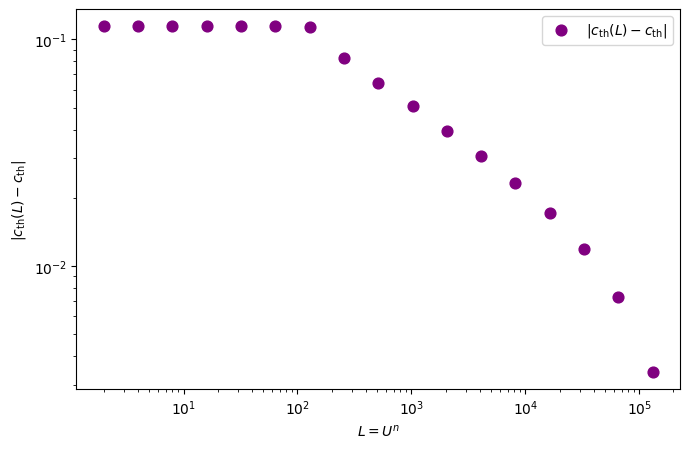

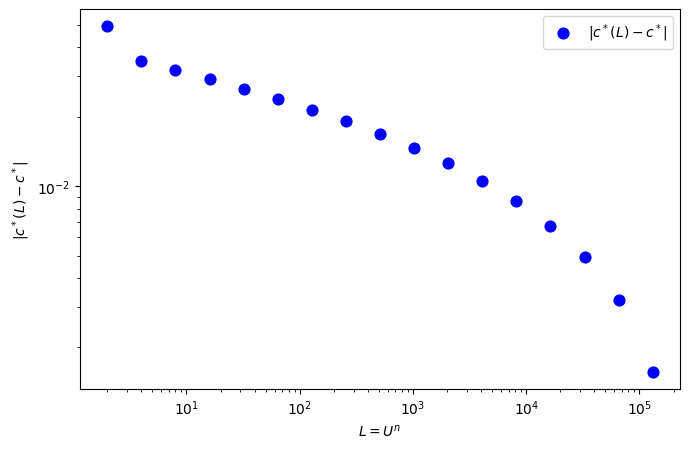

/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_32908/3975520362.py:475: RuntimeWarning: divide by zero encountered in log
  logP = np.where(mask, np.log(P), -np.inf)


Params: U=2, V=2, eta_s=0.95, eta_p=0.95, x_cut=0.1, p_target=0.5, Nq=18
c_th_ref  = 0.11424086801871647   (None means no real fixed-point root found in this n-range)
c*_ref    = 0.12008415477807434

  n          L      c_th(L)  root?        c*(L)  root?
--------------------------------------------------------------
  1          2          nan  False   0.07077724   True
  2          4          nan  False   0.08510457   True
  3          8          nan  False   0.08809809   True
  4         16          nan  False   0.09097302   True
  5         32          nan  False   0.09367482   True
  6         64          nan  False   0.09622913   True
  7        128   0.00127246   True   0.09866610   True
  8        256   0.03150160   True   0.10100624   True
  9        512   0.04971840   True   0.10326098   True
 10       1024   0.06362180   True   0.10543588   True
 11       2048   0.07463352   True   0.10753326   True
 12       4096   0.08356666   True   0.10955392   True
 13       8192   0.090

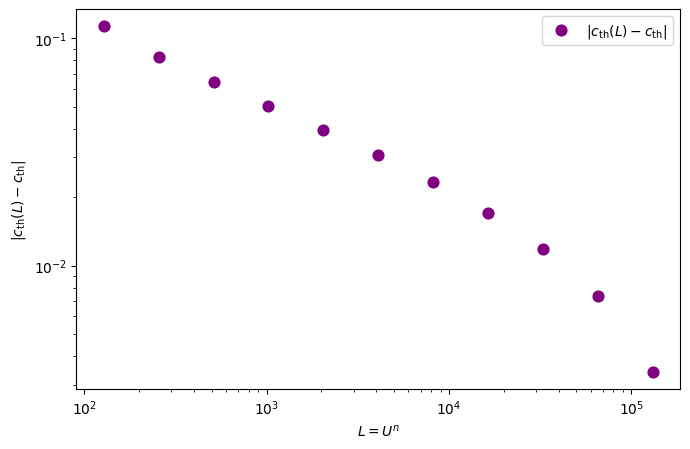

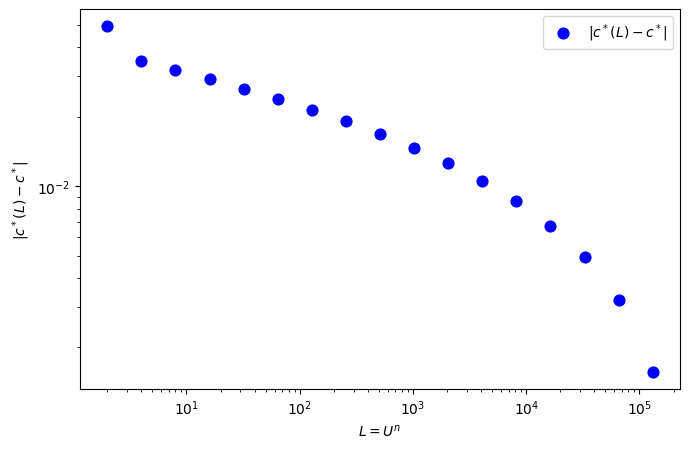

In [29]:
import numpy as np
import math
import matplotlib.pyplot as plt

from scipy import optimize, special
from scipy.stats import gamma as gamma_dist
from scipy.special import roots_genlaguerre, gammaln, logsumexp
from numpy.polynomial.hermite import hermgauss


# ----------------------------
# Para map (paper-consistent form you have been using)
# ----------------------------
def para(a, b):
    a = np.clip(a, 0.0, 1.0)
    b = np.clip(b, 0.0, 1.0)
    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - a)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - b)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))


# ----------------------------
# Fit Gamma closure in log-space:
# Assume Z = -ln X | (X>0) ~ Gamma(k, theta)
# then E[X] = (1+theta)^(-k),   E[X^2] = (1+2theta)^(-k)
# ----------------------------
def fit_gamma_from_moments(y, s, eps=1e-14):
    y = float(np.clip(y, eps, 1.0))
    s = float(np.clip(s, eps, 1.0))

    # If nearly deterministic: don't attempt gamma fit
    if s <= y*y*(1.0 + 1e-10):
        return np.inf, 0.0

    ly = math.log(y)
    ls = math.log(s)
    r = ls / ly  # both negative, r>1

    def f(th):
        return math.log1p(2.0*th) - r*math.log1p(th)

    # Find nonzero root (th>0). If r->2, root -> 0.
    grid = np.logspace(-12, 6, 300)
    vals = np.array([f(t) for t in grid])

    idx = None
    for i in range(len(grid)-1):
        if np.sign(vals[i]) * np.sign(vals[i+1]) < 0:
            idx = i
            break

    if idx is None:
        th = grid[np.argmin(np.abs(vals))]
    else:
        th = optimize.brentq(f, grid[idx], grid[idx+1], maxiter=200)

    k = -ly / math.log1p(th) if th > 0 else np.inf
    return float(k), float(th)


# ----------------------------
# E[Para(A,B)] and E[Para(A,B)^2]
# where A = exp(-Z_U), Z_U ~ Gamma(kU,theta), likewise B
#
# Uses Laguerre if safe, otherwise Gaussian approx in Z with Hermite.
# ----------------------------
def para_moments_from_gamma(k, theta, U, V, Nq=18, alpha_switch=160, Nh=15):
    a_u = k * U
    a_v = k * V

    def hermite_normal(shape_u, shape_v):
        mu_u = shape_u * theta
        sig_u = math.sqrt(shape_u) * theta
        mu_v = shape_v * theta
        sig_v = math.sqrt(shape_v) * theta

        xh, wh = hermgauss(Nh)  # integrates e^{-x^2}
        Zu = math.sqrt(2.0)*sig_u*xh + mu_u
        Zv = math.sqrt(2.0)*sig_v*xh + mu_v

        Au = np.exp(-Zu)
        Bv = np.exp(-Zv)

        P = para(Au[:, None], Bv[None, :])
        W = wh[:, None] * wh[None, :]

        m1 = np.sum(W * P) / math.pi
        m2 = np.sum(W * (P**2)) / math.pi
        return float(m1), float(m2)

    # If shapes are large, Laguerre weights can overflow -> use Hermite
    if a_u > alpha_switch or a_v > alpha_switch:
        return hermite_normal(a_u, a_v)

    # Laguerre (stable via log-sum-exp; but weights themselves can overflow if too big)
    try:
        xu, wu = roots_genlaguerre(Nq, a_u - 1.0)
        xv, wv = roots_genlaguerre(Nq, a_v - 1.0)

        if (not np.all(np.isfinite(wu))) or (not np.all(np.isfinite(wv))):
            return hermite_normal(a_u, a_v)

        Zu = theta * xu
        Zv = theta * xv
        Au = np.exp(-Zu)
        Bv = np.exp(-Zv)

        P = para(Au[:, None], Bv[None, :])
        mask = (P > 0)

        logwu = np.log(wu)
        logwv = np.log(wv)

        log_norm = -gammaln(a_u) - gammaln(a_v)

        logP = np.where(mask, np.log(P), -np.inf)

        # m1
        log_terms = logwu[:, None] + logwv[None, :] + logP
        log_terms = np.where(mask, log_terms, -np.inf)
        log_sum = logsumexp(log_terms.ravel())
        m1 = math.exp(log_norm + log_sum)

        # m2
        log_terms2 = logwu[:, None] + logwv[None, :] + 2.0*logP
        log_terms2 = np.where(mask, log_terms2, -np.inf)
        log_sum2 = logsumexp(log_terms2.ravel())
        m2 = math.exp(log_norm + log_sum2)

        return float(m1), float(m2)

    except Exception:
        return hermite_normal(a_u, a_v)


# ----------------------------
# One RG moment step (q,y,s)
# ----------------------------
def moment_step(q, y, s, U, V, eta_s, eta_p, Nq=18):
    q_u = (eta_s**(U-1)) * (q**U)
    q_v = (eta_s**(V-1)) * (q**V)

    q_next = eta_p*q_u*q_v + q_u*(1-q_v) + q_v*(1-q_u)

    muU = y**U
    muV = y**V
    nuU = s**U
    nuV = s**V

    k, theta = fit_gamma_from_moments(y, s)

    if (not np.isfinite(k)) or theta == 0.0:
        p = float(para(muU, muV))
        p2 = p*p
    else:
        p, p2 = para_moments_from_gamma(k, theta, U, V, Nq=Nq)

    m1 = eta_p*q_u*q_v*p  +  q_u*(1-q_v)*muU  +  q_v*(1-q_u)*muV
    m2 = eta_p*q_u*q_v*p2 +  q_u*(1-q_v)*nuU  +  q_v*(1-q_u)*nuV

    y_next = m1/q_next if q_next > 0 else 0.0
    s_next = m2/q_next if q_next > 0 else 0.0

    return float(q_next), float(y_next), float(s_next)


# ----------------------------
# Run RG moments from initial delta at c:
# Step 1 exact (delta), then gamma closure from step 2 onward.
# ----------------------------
def run_moments(c, n, U, V, eta_s, eta_p, Nq=18):
    if c <= 0:
        return 0.0, 0.0, 0.0

    q = 1.0
    y = c
    s = c*c

    if n == 0:
        return q, y, s

    # --- exact step 1 from delta ---
    q_u = eta_s**(U-1)
    q_v = eta_s**(V-1)

    q1 = eta_p*q_u*q_v + q_u*(1-q_v) + q_v*(1-q_u)

    A = c**U
    B = c**V
    P = float(para(A, B))

    m1 = eta_p*q_u*q_v*P + q_u*(1-q_v)*A + q_v*(1-q_u)*B
    m2 = eta_p*q_u*q_v*(P**2) + q_u*(1-q_v)*(A**2) + q_v*(1-q_u)*(B**2)

    q, y, s = float(q1), float(m1/q1), float(m2/q1)

    # --- remaining steps use closure ---
    for _ in range(1, n):
        q, y, s = moment_step(q, y, s, U, V, eta_s, eta_p, Nq=Nq)

    return q, y, s


# ----------------------------
# P(X_n > x_cut): exact at step 1, then gamma closure
# ----------------------------
def prob_above_cut(c, n, U, V, eta_s, eta_p, x_cut, Nq=18):
    if c <= 0:
        return 0.0
    if n == 0:
        return 1.0 if c > x_cut else 0.0

    z_cut = -math.log(x_cut)

    # step 1 exact mixture
    q_u = eta_s**(U-1)
    q_v = eta_s**(V-1)
    q1 = eta_p*q_u*q_v + q_u*(1-q_v) + q_v*(1-q_u)

    A = c**U
    B = c**V
    P = float(para(A, B))

    wP = eta_p*q_u*q_v / q1
    wU = q_u*(1-q_v) / q1
    wV = q_v*(1-q_u) / q1

    p1 = q1*( wP*(P > x_cut) + wU*(A > x_cut) + wV*(B > x_cut) )
    if n == 1:
        return float(p1)

    # now run moments to step n
    q, y, s = run_moments(c, n, U, V, eta_s, eta_p, Nq=Nq)
    k, theta = fit_gamma_from_moments(y, s)

    if (not np.isfinite(k)) or theta == 0.0:
        return float(q*(y > x_cut))

    cdf = gamma_dist.cdf(z_cut, a=k, scale=theta)  # P(Z<z_cut)
    return float(q*cdf)


# ----------------------------
# Root finder on (0,1): robust bracket via grid + brentq
# ----------------------------
def find_root(func, lo=1e-6, hi=1-1e-6, grid=500):
    xs = np.linspace(lo, hi, grid)
    vals = np.array([func(x) for x in xs], float)
    mask = np.isfinite(vals)
    xs = xs[mask]
    vals = vals[mask]
    if len(xs) < 2:
        return np.nan

    sgn = np.sign(vals)
    for i in range(len(xs)-1):
        if sgn[i]*sgn[i+1] < 0:
            return float(optimize.brentq(func, xs[i], xs[i+1], maxiter=200))

    # no sign-change: return closest point (prevents NaNs)
    return float(xs[np.argmin(np.abs(vals))])


# ----------------------------
# Main: compute thresholds + plots
# ----------------------------
def gamma_scaling_plots(
    U=2, V=2, eta_s=0.95, eta_p=0.95,
    x_cut=0.1, p_target=0.5,
    n_list=(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18),
    Nq=18
):
    n_list = list(n_list)
    Ls = np.array([U**n for n in n_list], float)

    c_th_L = []
    c_star_L = []

    dc = np.diff(c_th_L)
    print("Unique step sizes in Δc_th(L):", np.unique(np.round(dc, 12))[:20])
    print("Min nonzero |Δ|:", np.min(np.abs(dc[np.abs(dc)>0])) if np.any(dc!=0) else None)


    for n in n_list:
        # c_th(L): y_n(c)=c
        f = lambda c: run_moments(c, n, U, V, eta_s, eta_p, Nq=Nq)[1] - c
        c_th_L.append(find_root(f))

        # c*(L): P(X_n > x_cut) = p_target
        g = lambda c: prob_above_cut(c, n, U, V, eta_s, eta_p, x_cut, Nq=Nq) - p_target
        c_star_L.append(find_root(g))

    c_th_L = np.array(c_th_L, float)
    c_star_L = np.array(c_star_L, float)

    # asymptotic estimates = last finite values
    c_th_est = c_th_L[np.isfinite(c_th_L)][-1] if np.any(np.isfinite(c_th_L)) else None
    c_star_est = c_star_L[np.isfinite(c_star_L)][-1] if np.any(np.isfinite(c_star_L)) else None

    print(f"Params: U={U}, V={V}, eta_s={eta_s}, eta_p={eta_p}, x_cut={x_cut}, Nq={Nq}")
    print(f"Estimated c_th  (from last available n): {c_th_est}")
    print(f"Estimated c*_th (from last available n): {c_star_est}\n")

    print(f"{'n':>4} {'L=U^n':>12} {'c_th(L)':>12} {'|c_th(L)-c_th|':>18} {'c*(L)':>12} {'|c*(L)-c*|':>14}")
    print("-"*80)

    for n, L, ct, cs in zip(n_list, Ls, c_th_L, c_star_L):
        d1 = abs(ct - c_th_est) if (c_th_est is not None and np.isfinite(ct)) else np.nan
        d2 = abs(cs - c_star_est) if (c_star_est is not None and np.isfinite(cs)) else np.nan
        print(f"{n:4d} {int(L):12d} {ct:12.10f} {d1:18.10e} {cs:12.10f} {d2:14.10e}")

    # --- plot 1: |c_th(L)-c_th|
    if c_th_est is not None:
        d1 = np.abs(c_th_L - c_th_est)
        m1 = np.isfinite(d1) & (d1 > 0)
        plt.figure(figsize=(7.0,4.6))
        plt.scatter(Ls[m1], d1[m1], color="purple", s=60, label=r"$|c_{\rm th}(L)-c_{\rm th}|$")
        plt.xscale("log"); plt.yscale("log")
        plt.xlabel(r"$L=U^n$")
        plt.ylabel(r"$|c_{\rm th}(L)-c_{\rm th}|$")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- plot 2: |c*(L)-c*|
    if c_star_est is not None:
        d2 = np.abs(c_star_L - c_star_est)
        m2 = np.isfinite(d2) & (d2 > 0)
        plt.figure(figsize=(7.0,4.6))
        plt.scatter(Ls[m2], d2[m2], color="blue", s=60, label=r"$|c^*(L)-c^*|$")
        plt.xscale("log"); plt.yscale("log")
        plt.xlabel(r"$L=U^n$")
        plt.ylabel(r"$|c^*(L)-c^*|$")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return {
        "n": np.array(n_list),
        "L": Ls,
        "c_th_L": c_th_L,
        "c_star_L": c_star_L,
        "c_th_est": c_th_est,
        "c_star_est": c_star_est
    }


# ----------------------------
# Example run (matches your screenshot parameters)
# ----------------------------
out = gamma_scaling_plots(
    U=2, V=2,
    eta_s=0.95, eta_p=0.95,
    x_cut=0.1, p_target=0.5,
    n_list=(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18),
    Nq=18
)
import numpy as np
import math
import matplotlib.pyplot as plt

from scipy import optimize, special
from scipy.stats import gamma as gamma_dist
from scipy.special import roots_genlaguerre, gammaln, logsumexp
from numpy.polynomial.hermite import hermgauss


# ----------------------------
# Para map (paper-consistent form you have been using)
# ----------------------------
def para(a, b):
    a = np.clip(a, 0.0, 1.0)
    b = np.clip(b, 0.0, 1.0)
    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - a)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - b)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))


# ----------------------------
# Fit Gamma closure in log-space:
# Assume Z = -ln X | (X>0) ~ Gamma(k, theta)
# then E[X] = (1+theta)^(-k),   E[X^2] = (1+2theta)^(-k)
# ----------------------------
def fit_gamma_from_moments(y, s, eps=1e-14):
    y = float(np.clip(y, eps, 1.0))
    s = float(np.clip(s, eps, 1.0))

    # If nearly deterministic: don't attempt gamma fit
    if s <= y*y*(1.0 + 1e-10):
        return np.inf, 0.0

    ly = math.log(y)
    ls = math.log(s)
    r = ls / ly  # both negative, r>1

    def f(th):
        return math.log1p(2.0*th) - r*math.log1p(th)

    # Find nonzero root (th>0). If r->2, root -> 0.
    grid = np.logspace(-12, 6, 300)
    vals = np.array([f(t) for t in grid])

    idx = None
    for i in range(len(grid)-1):
        if np.sign(vals[i]) * np.sign(vals[i+1]) < 0:
            idx = i
            break

    if idx is None:
        th = grid[np.argmin(np.abs(vals))]
    else:
        th = optimize.brentq(f, grid[idx], grid[idx+1], maxiter=200)

    k = -ly / math.log1p(th) if th > 0 else np.inf
    return float(k), float(th)


# ----------------------------
# E[Para(A,B)] and E[Para(A,B)^2]
# where A = exp(-Z_U), Z_U ~ Gamma(kU,theta), likewise B
#
# Uses Laguerre if safe, otherwise Gaussian approx in Z with Hermite.
# ----------------------------
def para_moments_from_gamma(k, theta, U, V, Nq=18, alpha_switch=160, Nh=15):
    a_u = k * U
    a_v = k * V

    def hermite_normal(shape_u, shape_v):
        mu_u = shape_u * theta
        sig_u = math.sqrt(shape_u) * theta
        mu_v = shape_v * theta
        sig_v = math.sqrt(shape_v) * theta

        xh, wh = hermgauss(Nh)  # integrates e^{-x^2}
        Zu = math.sqrt(2.0)*sig_u*xh + mu_u
        Zv = math.sqrt(2.0)*sig_v*xh + mu_v

        Au = np.exp(-Zu)
        Bv = np.exp(-Zv)

        P = para(Au[:, None], Bv[None, :])
        W = wh[:, None] * wh[None, :]

        m1 = np.sum(W * P) / math.pi
        m2 = np.sum(W * (P**2)) / math.pi
        return float(m1), float(m2)

    # If shapes are large, Laguerre weights can overflow -> use Hermite
    if a_u > alpha_switch or a_v > alpha_switch:
        return hermite_normal(a_u, a_v)

    # Laguerre (stable via log-sum-exp; but weights themselves can overflow if too big)
    try:
        xu, wu = roots_genlaguerre(Nq, a_u - 1.0)
        xv, wv = roots_genlaguerre(Nq, a_v - 1.0)

        if (not np.all(np.isfinite(wu))) or (not np.all(np.isfinite(wv))):
            return hermite_normal(a_u, a_v)

        Zu = theta * xu
        Zv = theta * xv
        Au = np.exp(-Zu)
        Bv = np.exp(-Zv)

        P = para(Au[:, None], Bv[None, :])
        mask = (P > 0)

        logwu = np.log(wu)
        logwv = np.log(wv)

        log_norm = -gammaln(a_u) - gammaln(a_v)

        logP = np.where(mask, np.log(P), -np.inf)

        # m1
        log_terms = logwu[:, None] + logwv[None, :] + logP
        log_terms = np.where(mask, log_terms, -np.inf)
        log_sum = logsumexp(log_terms.ravel())
        m1 = math.exp(log_norm + log_sum)

        # m2
        log_terms2 = logwu[:, None] + logwv[None, :] + 2.0*logP
        log_terms2 = np.where(mask, log_terms2, -np.inf)
        log_sum2 = logsumexp(log_terms2.ravel())
        m2 = math.exp(log_norm + log_sum2)

        return float(m1), float(m2)

    except Exception:
        return hermite_normal(a_u, a_v)


# ----------------------------
# One RG moment step (q,y,s)
# ----------------------------
def moment_step(q, y, s, U, V, eta_s, eta_p, Nq=18):
    q_u = (eta_s**(U-1)) * (q**U)
    q_v = (eta_s**(V-1)) * (q**V)

    q_next = eta_p*q_u*q_v + q_u*(1-q_v) + q_v*(1-q_u)

    muU = y**U
    muV = y**V
    nuU = s**U
    nuV = s**V

    k, theta = fit_gamma_from_moments(y, s)

    if (not np.isfinite(k)) or theta == 0.0:
        p = float(para(muU, muV))
        p2 = p*p
    else:
        p, p2 = para_moments_from_gamma(k, theta, U, V, Nq=Nq)

    m1 = eta_p*q_u*q_v*p  +  q_u*(1-q_v)*muU  +  q_v*(1-q_u)*muV
    m2 = eta_p*q_u*q_v*p2 +  q_u*(1-q_v)*nuU  +  q_v*(1-q_u)*nuV

    y_next = m1/q_next if q_next > 0 else 0.0
    s_next = m2/q_next if q_next > 0 else 0.0

    return float(q_next), float(y_next), float(s_next)


# ----------------------------
# Run RG moments from initial delta at c:
# Step 1 exact (delta), then gamma closure from step 2 onward.
# ----------------------------
def run_moments(c, n, U, V, eta_s, eta_p, Nq=18):
    if c <= 0:
        return 0.0, 0.0, 0.0

    q = 1.0
    y = c
    s = c*c

    if n == 0:
        return q, y, s

    # --- exact step 1 from delta ---
    q_u = eta_s**(U-1)
    q_v = eta_s**(V-1)

    q1 = eta_p*q_u*q_v + q_u*(1-q_v) + q_v*(1-q_u)

    A = c**U
    B = c**V
    P = float(para(A, B))

    m1 = eta_p*q_u*q_v*P + q_u*(1-q_v)*A + q_v*(1-q_u)*B
    m2 = eta_p*q_u*q_v*(P**2) + q_u*(1-q_v)*(A**2) + q_v*(1-q_u)*(B**2)

    q, y, s = float(q1), float(m1/q1), float(m2/q1)

    # --- remaining steps use closure ---
    for _ in range(1, n):
        q, y, s = moment_step(q, y, s, U, V, eta_s, eta_p, Nq=Nq)

    return q, y, s


# ----------------------------
# P(X_n > x_cut): exact at step 1, then gamma closure
# ----------------------------
def prob_above_cut(c, n, U, V, eta_s, eta_p, x_cut, Nq=18):
    if c <= 0:
        return 0.0
    if n == 0:
        return 1.0 if c > x_cut else 0.0

    z_cut = -math.log(x_cut)

    # step 1 exact mixture
    q_u = eta_s**(U-1)
    q_v = eta_s**(V-1)
    q1 = eta_p*q_u*q_v + q_u*(1-q_v) + q_v*(1-q_u)

    A = c**U
    B = c**V
    P = float(para(A, B))

    wP = eta_p*q_u*q_v / q1
    wU = q_u*(1-q_v) / q1
    wV = q_v*(1-q_u) / q1

    p1 = q1*( wP*(P > x_cut) + wU*(A > x_cut) + wV*(B > x_cut) )
    if n == 1:
        return float(p1)

    # now run moments to step n
    q, y, s = run_moments(c, n, U, V, eta_s, eta_p, Nq=Nq)
    k, theta = fit_gamma_from_moments(y, s)

    if (not np.isfinite(k)) or theta == 0.0:
        return float(q*(y > x_cut))

    cdf = gamma_dist.cdf(z_cut, a=k, scale=theta)  # P(Z<z_cut)
    return float(q*cdf)


# ----------------------------
# Root finder on (0,1): robust bracket via grid + brentq
# ----------------------------
def find_root(func, lo=1e-6, hi=1-1e-6, grid=500):
    xs = np.linspace(lo, hi, grid)
    vals = np.array([func(x) for x in xs], float)
    mask = np.isfinite(vals)
    xs = xs[mask]
    vals = vals[mask]
    if len(xs) < 2:
        return np.nan

    sgn = np.sign(vals)
    for i in range(len(xs)-1):
        if sgn[i]*sgn[i+1] < 0:
            return float(optimize.brentq(func, xs[i], xs[i+1], maxiter=200))

    # no sign-change: return closest point (prevents NaNs)
    return float(xs[np.argmin(np.abs(vals))])


# ----------------------------
# Main: compute thresholds + plots
# ----------------------------
def gamma_scaling_plots(
    U=2, V=2, eta_s=0.95, eta_p=0.95,
    x_cut=0.1, p_target=0.5,
    n_list=(1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18),
    Nq=18
):
    n_list = list(n_list)
    Ls = np.array([U**n for n in n_list], float)

    c_th_L = []
    c_star_L = []

    dc = np.diff(c_th_L)
    print("Unique step sizes in Δc_th(L):", np.unique(np.round(dc, 12))[:20])
    print("Min nonzero |Δ|:", np.min(np.abs(dc[np.abs(dc)>0])) if np.any(dc!=0) else None)

    for n in n_list:
        # c_th(L): y_n(c)=c
        f = lambda c: run_moments(c, n, U, V, eta_s, eta_p, Nq=Nq)[1] - c
        c_th_L.append(find_root(f))

        # c*(L): P(X_n > x_cut) = p_target
        g = lambda c: prob_above_cut(c, n, U, V, eta_s, eta_p, x_cut, Nq=Nq) - p_target
        c_star_L.append(find_root(g))

    c_th_L = np.array(c_th_L, float)
    c_star_L = np.array(c_star_L, float)

    # asymptotic estimates = last finite values
    c_th_est = c_th_L[np.isfinite(c_th_L)][-1] if np.any(np.isfinite(c_th_L)) else None
    c_star_est = c_star_L[np.isfinite(c_star_L)][-1] if np.any(np.isfinite(c_star_L)) else None

    print(f"Params: U={U}, V={V}, eta_s={eta_s}, eta_p={eta_p}, x_cut={x_cut}, Nq={Nq}")
    print(f"Estimated c_th  (from last available n): {c_th_est}")
    print(f"Estimated c*_th (from last available n): {c_star_est}\n")

    print(f"{'n':>4} {'L=U^n':>12} {'c_th(L)':>12} {'|c_th(L)-c_th|':>18} {'c*(L)':>12} {'|c*(L)-c*|':>14}")
    print("-"*80)

    for n, L, ct, cs in zip(n_list, Ls, c_th_L, c_star_L):
        d1 = abs(ct - c_th_est) if (c_th_est is not None and np.isfinite(ct)) else np.nan
        d2 = abs(cs - c_star_est) if (c_star_est is not None and np.isfinite(cs)) else np.nan
        print(f"{n:4d} {int(L):12d} {ct:12.10f} {d1:18.10e} {cs:12.10f} {d2:14.10e}")

    # --- plot 1: |c_th(L)-c_th|
    if c_th_est is not None:
        d1 = np.abs(c_th_L - c_th_est)
        m1 = np.isfinite(d1) & (d1 > 0)
        plt.figure(figsize=(7.0,4.6))
        plt.scatter(Ls[m1], d1[m1], color="purple", s=60, label=r"$|c_{\rm th}(L)-c_{\rm th}|$")
        plt.xscale("log"); plt.yscale("log")
        plt.xlabel(r"$L=U^n$")
        plt.ylabel(r"$|c_{\rm th}(L)-c_{\rm th}|$")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- plot 2: |c*(L)-c*|
    if c_star_est is not None:
        d2 = np.abs(c_star_L - c_star_est)
        m2 = np.isfinite(d2) & (d2 > 0)
        plt.figure(figsize=(7.0,4.6))
        plt.scatter(Ls[m2], d2[m2], color="blue", s=60, label=r"$|c^*(L)-c^*|$")
        plt.xscale("log"); plt.yscale("log")
        plt.xlabel(r"$L=U^n$")
        plt.ylabel(r"$|c^*(L)-c^*|$")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return {
        "n": np.array(n_list),
        "L": Ls,
        "c_th_L": c_th_L,
        "c_star_L": c_star_L,
        "c_th_est": c_th_est,
        "c_star_est": c_star_est
    }

import numpy as np
from scipy import optimize
import matplotlib.pyplot as plt

# ----------------------------
# Strict root finder: returns NaN if no sign change.
# Also returns diagnostics.
# ----------------------------
def find_root_strict(func, lo=1e-6, hi=1-1e-6, grid=4000):
    xs = np.linspace(lo, hi, grid)
    vals = np.array([func(x) for x in xs], float)
    m = np.isfinite(vals)
    xs = xs[m]; vals = vals[m]

    if len(xs) < 2:
        return np.nan, {"has_root": False, "reason": "no_finite_values"}

    s = np.sign(vals)
    # locate first sign change
    idx = np.where(s[:-1] * s[1:] < 0)[0]
    if idx.size == 0:
        # no root in bracket
        return np.nan, {
            "has_root": False,
            "reason": "no_sign_change",
            "min_val": float(np.min(vals)),
            "max_val": float(np.max(vals)),
            "argmin_abs": float(xs[np.argmin(np.abs(vals))]),
            "min_abs": float(np.min(np.abs(vals))),
        }

    i = int(idx[0])
    a, b = float(xs[i]), float(xs[i+1])
    root = float(optimize.brentq(func, a, b, maxiter=400))
    return root, {"has_root": True, "bracket": (a, b)}

# ----------------------------
# Main: compute thresholds + plots (numerically honest)
# ----------------------------
def gamma_scaling_plots_clean(
    U=2, V=2, eta_s=0.95, eta_p=0.95,
    x_cut=0.1, p_target=0.5,
    n_list=tuple(range(1, 19)),
    Nq=18,
    # reference choice:
    c_ref=None,         # if provided, use this fixed value for |c_th(L)-c_ref|
    use_last_root_ref=True,  # else: use largest-n that actually has a root
    root_grid=4000,
    lo=1e-6, hi=1-1e-6,
):
    n_list = list(map(int, n_list))
    Ls = np.array([U**n for n in n_list], float)

    c_th_L = np.full(len(n_list), np.nan, float)
    c_star_L = np.full(len(n_list), np.nan, float)

    diag_ct = []
    diag_cs = []

    # compute both sequences
    for j, n in enumerate(n_list):
        f = lambda c: run_moments(c, n, U, V, eta_s, eta_p, Nq=Nq)[1] - c
        ct, info_ct = find_root_strict(f, lo=lo, hi=hi, grid=root_grid)
        c_th_L[j] = ct
        diag_ct.append(info_ct)

        g = lambda c: prob_above_cut(c, n, U, V, eta_s, eta_p, x_cut, Nq=Nq) - p_target
        cs, info_cs = find_root_strict(g, lo=lo, hi=hi, grid=root_grid)
        c_star_L[j] = cs
        diag_cs.append(info_cs)

    # choose references
    finite_ct = np.isfinite(c_th_L)
    finite_cs = np.isfinite(c_star_L)

    if c_ref is not None:
        c_th_ref = float(c_ref)
    else:
        if use_last_root_ref and np.any(finite_ct):
            c_th_ref = float(c_th_L[np.where(finite_ct)[0][-1]])
        else:
            c_th_ref = None

    c_star_ref = float(c_star_L[np.where(finite_cs)[0][-1]]) if np.any(finite_cs) else None

    # print summary table
    print(f"Params: U={U}, V={V}, eta_s={eta_s}, eta_p={eta_p}, x_cut={x_cut}, p_target={p_target}, Nq={Nq}")
    print(f"c_th_ref  = {c_th_ref}   (None means no real fixed-point root found in this n-range)")
    print(f"c*_ref    = {c_star_ref}")
    print()
    print(f"{'n':>3} {'L':>10} {'c_th(L)':>12} {'root?':>6} {'c*(L)':>12} {'root?':>6}")
    print("-"*62)
    for n, L, ct, cs, ict, ics in zip(n_list, Ls, c_th_L, c_star_L, diag_ct, diag_cs):
        rt_ct = ict.get("has_root", False)
        rt_cs = ics.get("has_root", False)
        print(f"{n:3d} {int(L):10d} {ct:12.8f} {str(rt_ct):>6} {cs:12.8f} {str(rt_cs):>6}")

    # plot 1: |c_th(L)-c_th_ref|
    if c_th_ref is not None:
        d1 = np.abs(c_th_L - c_th_ref)
        m1 = np.isfinite(d1) & (d1 > 0)
        plt.figure(figsize=(7.0, 4.6))
        plt.scatter(Ls[m1], d1[m1], color="purple", s=60,
                    label=r"$|c_{\rm th}(L)-c_{\rm th}|$")
        plt.xscale("log"); plt.yscale("log")
        plt.xlabel(r"$L=U^n$")
        plt.ylabel(r"$|c_{\rm th}(L)-c_{\rm th}|$")
        plt.legend()
        plt.tight_layout()
        plt.show()
    else:
        print("\nNo plot for c_th(L): no real root exists in the provided n-range (this is physics, not numerics).")

    # plot 2: |c*(L)-c*_ref|
    if c_star_ref is not None:
        d2 = np.abs(c_star_L - c_star_ref)
        m2 = np.isfinite(d2) & (d2 > 0)
        plt.figure(figsize=(7.0, 4.6))
        plt.scatter(Ls[m2], d2[m2], color="blue", s=60,
                    label=r"$|c^*(L)-c^*|$")
        plt.xscale("log"); plt.yscale("log")
        plt.xlabel(r"$L=U^n$")
        plt.ylabel(r"$|c^*(L)-c^*|$")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return {
        "n": np.array(n_list),
        "L": Ls,
        "c_th_L": c_th_L,
        "c_star_L": c_star_L,
        "c_th_ref": c_th_ref,
        "c_star_ref": c_star_ref,
        "diag_ct": diag_ct,
        "diag_cs": diag_cs,
    }

# ----------------------------
# Example run (your parameters)
# ----------------------------
out_clean = gamma_scaling_plots_clean(
    U=2, V=2,
    eta_s=0.95, eta_p=0.95,
    x_cut=0.1, p_target=0.5,
    n_list=tuple(range(1, 19)),
    Nq=18,
    c_ref=None,               # set to a fixed value later if you want truly comparable plots across different n_list
    use_last_root_ref=True,
    root_grid=5000,
)



=== Basic sanity ===
n range: 1 -> 18 count: 18
c_th_est: 0.1142408680186523 c_star_est: 0.12008415477806561

=== Reference sensitivity (this explains shifting) ===
Using ref = last finite value vs ref = median changes ALL y-values.
First 8 |c_th(L)-ref_last|: [0.11424  0.11424  0.11424  0.11424  0.11424  0.11424  0.112906 0.082739]
First 8 |c_th(L)-ref_med |: [0.056669 0.056669 0.056669 0.056669 0.056669 0.056669 0.055336 0.025168]

=== Test 1: quantisation/plateaus in returned thresholds ===
c_th_L:
  #exact plateaus (Δ=0): 5
  min nonzero |Δ|: 0.0013335290444786761
  unique Δ (rounded 1e-6), first 20: [0.001334 0.003412 0.00391  0.004515 0.005261 0.006193 0.007383 0.008933
 0.011012 0.013903 0.018217 0.030167]
c_star_L:
  #exact plateaus (Δ=0): 0
  min nonzero |Δ|: 0.001568267779630983
  unique Δ (rounded 1e-6), first 20: [0.001568 0.001642 0.001716 0.001792 0.001868 0.001944 0.002021 0.002097
 0.002175 0.002255 0.00234  0.002437 0.002554 0.002702 0.002875 0.002994
 0.014327]

=== T

/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_32908/2534309736.py:475: RuntimeWarning: divide by zero encountered in log
  logP = np.where(mask, np.log(P), -np.inf)


  5       32    0.000001  False   1.600e-07  3.850e-01   0.000001
  6       64    0.000001  False   8.345e-08  4.278e-01   0.000001
  7      128    0.001335   True  -9.068e-06  4.667e-01   0.000001
  8      256    0.031502   True  -7.450e-04  5.020e-01   0.000001
  9      512    0.049718   True  -2.186e-03  5.340e-01   0.000001
 10     1024    0.063622   True  -4.067e-03  5.630e-01   0.000001
 11     2048    0.074634   True  -6.239e-03  5.891e-01   0.000001
 12     4096    0.083567   True  -8.615e-03  6.126e-01   0.000001
 13     8192    0.090949   True  -1.112e-02  6.338e-01   0.000001
 14    16384    0.097143   True  -1.373e-02  6.529e-01   0.000001
 15    32768    0.102403   True  -1.640e-02  6.701e-01   0.000001
 16    65536    0.106919   True  -1.912e-02  6.855e-01   0.000001
 17   131072    0.110829   True  -2.186e-02  6.995e-01   0.000001
 18   262144    0.114241   True  -2.462e-02  7.121e-01   0.000001

n values where c_th(L) likely NOT a real root (no sign change): [1, 2, 3, 4

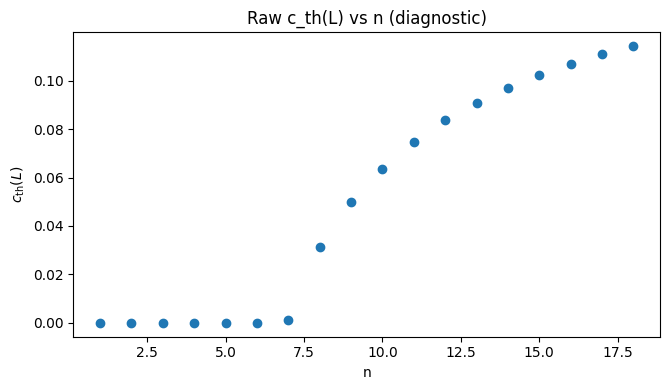

In [28]:

import numpy as np
import math
from scipy import optimize
import matplotlib.pyplot as plt

# =========
# SETTINGS (match the run that produced `out`)
# =========
U=2; V=2
eta_s=0.95; eta_p=0.95
x_cut=0.1
p_target=0.5
Nq=18

# =========
# Pull arrays from `out`
# =========
n_list   = np.array(out["n"], dtype=int)
Ls       = np.array(out["L"], dtype=float)
c_th_L   = np.array(out["c_th_L"], dtype=float)
c_star_L = np.array(out["c_star_L"], dtype=float)
c_th_est = out["c_th_est"]
c_star_est = out["c_star_est"]

print("=== Basic sanity ===")
print("n range:", n_list[0], "->", n_list[-1], "count:", len(n_list))
print("c_th_est:", c_th_est, "c_star_est:", c_star_est)
print()

# ==========================================================
# Test 0: show that 'shifting' can be purely from the reference
# ==========================================================
if np.isfinite(c_th_L).any():
    ref_last = c_th_L[np.isfinite(c_th_L)][-1]
    ref_med  = np.nanmedian(c_th_L)
    d_last = np.abs(c_th_L - ref_last)
    d_med  = np.abs(c_th_L - ref_med)
    print("=== Reference sensitivity (this explains shifting) ===")
    print("Using ref = last finite value vs ref = median changes ALL y-values.")
    print("First 8 |c_th(L)-ref_last|:", np.round(d_last[:8], 6))
    print("First 8 |c_th(L)-ref_med |:", np.round(d_med[:8], 6))
    print()

# ==========================================================
# Helpers
# ==========================================================
def f_ct(n):
    return lambda c: run_moments(c, n, U, V, eta_s, eta_p, Nq=Nq)[1] - c

def g_cs(n):
    return lambda c: prob_above_cut(c, n, U, V, eta_s, eta_p, x_cut, Nq=Nq) - p_target

def sign_change_exists(func, lo=1e-6, hi=1-1e-6, grid=2000):
    xs = np.linspace(lo, hi, grid)
    vals = np.array([func(x) for x in xs], float)
    m = np.isfinite(vals)
    xs = xs[m]; vals = vals[m]
    if len(xs) < 2:
        return False, np.nan, np.nan, np.nan
    s = np.sign(vals)
    crosses = np.any(s[:-1]*s[1:] < 0)
    return bool(crosses), float(np.nanmin(vals)), float(np.nanmax(vals)), float(xs[np.nanargmin(np.abs(vals))])

def local_slope(func, c0, h=1e-4):
    # central difference derivative of func at c0
    return (func(c0+h) - func(c0-h)) / (2*h)

# ==========================================================
# Test 1: quantisation / plateaus in c_th(L), c*(L)
# ==========================================================
print("=== Test 1: quantisation/plateaus in returned thresholds ===")
def report_steps(arr, name):
    d = np.diff(arr)
    d = d[np.isfinite(d)]
    print(f"{name}:")
    if d.size == 0:
        print("  no diffs")
        return
    nz = d[np.abs(d) > 0]
    print("  #exact plateaus (Δ=0):", int(np.sum(np.abs(d)==0)))
    if nz.size:
        print("  min nonzero |Δ|:", float(np.min(np.abs(nz))))
        print("  unique Δ (rounded 1e-6), first 20:", np.unique(np.round(nz, 6))[:20])
    else:
        print("  all diffs are zero (?)")
report_steps(c_th_L, "c_th_L")
report_steps(c_star_L, "c_star_L")
print()

# ==========================================================
# Test 2: does a REAL root exist (sign-change)? or are we in "closest grid point" mode?
# ==========================================================
print("=== Test 2: root-existence / sign-change check ===")
print(f"{'n':>3} {'L':>8}  {'ct':>10}  {'root?':>5}  {'min f':>10} {'max f':>10} {'argmin|f|':>10}")
print("-"*70)
bad_ct = []
for n, L, ct in zip(n_list, Ls, c_th_L):
    func = f_ct(int(n))
    ok, fmin, fmax, argmin = sign_change_exists(func, grid=3000)
    print(f"{n:3d} {int(L):8d}  {ct:10.6f}  {str(ok):>5}  {fmin:10.3e} {fmax:10.3e} {argmin:10.6f}")
    if not ok:
        bad_ct.append(int(n))
print()
if bad_ct:
    print("n values where c_th(L) likely NOT a real root (no sign change):", bad_ct)
    print("=> those points are coming from find_root's 'closest point' fallback (quantisation/plateau source).")
print()

print("=== Test 2b: same for c*(L) ===")
print(f"{'n':>3} {'L':>8}  {'cs':>10}  {'root?':>5}  {'min g':>10} {'max g':>10} {'argmin|g|':>10}")
print("-"*70)
bad_cs = []
for n, L, cs in zip(n_list, Ls, c_star_L):
    func = g_cs(int(n))
    ok, gmin, gmax, argmin = sign_change_exists(func, grid=3000)
    print(f"{n:3d} {int(L):8d}  {cs:10.6f}  {str(ok):>5}  {gmin:10.3e} {gmax:10.3e} {argmin:10.6f}")
    if not ok:
        bad_cs.append(int(n))
print()
if bad_cs:
    print("n values where c*(L) likely NOT a real root (no sign change):", bad_cs)
print()

# ==========================================================
# Test 3: residuals and conditioning at the returned roots
# ==========================================================
print("=== Test 3: residual and local slope at returned ct root ===")
print(f"{'n':>3} {'ct':>10} {'f(ct)':>12} {'df/dc':>12}")
print("-"*45)
for n, ct in zip(n_list, c_th_L):
    func = f_ct(int(n))
    if not np.isfinite(ct):
        continue
    try:
        r = func(ct)
        s = local_slope(func, ct, h=1e-4)
        print(f"{n:3d} {ct:10.6f} {r:12.3e} {s:12.3e}")
    except Exception as e:
        print(f"{n:3d} {ct:10.6f}  ERROR: {e}")
print()

# ==========================================================
# Test 4: order-dependence / state leakage check
# (if this fails, earlier points CAN change when you extend runs)
# ==========================================================
print("=== Test 4: order-dependence (state leakage) ===")
# pick a few (n,c) pairs and evaluate y_n(c) twice in different orders
test_ns = list(n_list[:min(8, len(n_list))])
test_cs = [0.2, 0.5, 0.8]
pairs = [(n,c) for n in test_ns for c in test_cs]

def eval_pairs(order):
    outv = []
    for (n,c) in order:
        outv.append(run_moments(c, int(n), U, V, eta_s, eta_p, Nq=Nq)[1])
    return np.array(outv, float)

A = eval_pairs(pairs)
B = eval_pairs(list(reversed(pairs)))[::-1]  # reverse back to same pair order

diff = np.max(np.abs(A - B))
print("max |y_n(c) difference when call order is reversed| =", diff)
if diff > 1e-12:
    print("WARNING: order dependence detected -> hidden mutable state/caching somewhere.")
else:
    print("OK: no detectable order dependence at 1e-12.")
print()

# ==========================================================
# Test 5: show c_th(L) itself doesn't change with longer n_list (only the reference does)
# ==========================================================
print("=== Test 5: recompute for a prefix and compare (should match) ===")
prefix = list(n_list[:min(10, len(n_list))])
ct_re = []
for n in prefix:
    ct_re.append(find_root(lambda c: run_moments(c, int(n), U, V, eta_s, eta_p, Nq=Nq)[1] - c))
ct_re = np.array(ct_re, float)

ct_old = c_th_L[:len(prefix)]
print("max |ct_old - ct_recomputed| on prefix =", np.nanmax(np.abs(ct_old - ct_re)))
print()

# Optional quick plot: c_th(L) vs n (not the absolute diff)
plt.figure(figsize=(6.8,4.0))
plt.plot(n_list, c_th_L, marker='o', linestyle='none')
plt.xlabel("n")
plt.ylabel(r"$c_{\rm th}(L)$")
plt.title("Raw c_th(L) vs n (diagnostic)")
plt.tight_layout()
plt.show()


## Critical Scaling

* What is the thermal exponent of scaling for the percolation schemes? Is it different for operational renormalization?

## Q-n Y-n comparison with E[X_n]

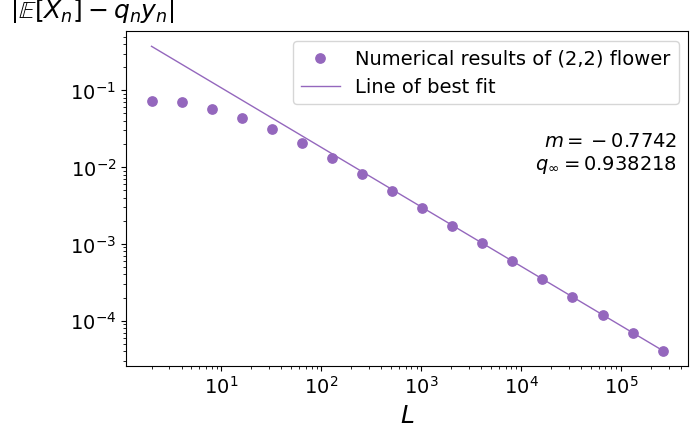

In [89]:
# =========================
# ConPT scaling: |E[X_n]_PMF - (q_n y_n)_MF| vs L = U^n  (log-log)
# Drop this AFTER your existing PMF code that defines sponge_distribution_uv(...)
# =========================

import numpy as np
import matplotlib.pyplot as plt
import inspect


# ---------- Para map (same as your analytic cells) ----------
def para(a, b):
    a = np.clip(a, 0.0, 1.0)
    b = np.clip(b, 0.0, 1.0)
    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - a)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - b)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))


# ---------- q_inf via survival fixed point (independent of c for c>0) ----------
def q_inf_conpt_fixed_point(U, V, eta_s, eta_p, tol=1e-14, maxiter=200000):
    q = 1.0
    for _ in range(maxiter):
        q_u = (eta_s ** (U - 1)) * (q ** U)
        q_v = (eta_s ** (V - 1)) * (q ** V)
        q_next = eta_p * q_u * q_v + q_u * (1 - q_v) + q_v * (1 - q_u)
        if abs(q_next - q) < tol:
            return float(q_next)
        q = q_next
    return float(q)


# ---------- PMF mean from dict ----------
def pmf_mean_from_dict(pmf_dict):
    # p0 contributes 0 to the mean, so dict-only mean is already unconditional mean
    return float(sum(x * p for x, p in pmf_dict.items()))


# ---------- Call sponge_distribution_uv robustly ----------
def _call_sponge_distribution_uv(
    sponge_fn,
    *,
    n, U, V,
    mode,
    c_init,
    eta_s, eta_p,
    merge="bin",
    n_bins=1001,
    round_digits=12,
    p_min=0.0,
    max_states=None
):
    sig = inspect.signature(sponge_fn)
    params = sig.parameters
    kwargs = {}

    # core
    if "n" in params: kwargs["n"] = n
    if "U" in params: kwargs["U"] = U
    if "V" in params: kwargs["V"] = V

    # mode
    if "mode" in params: kwargs["mode"] = mode
    elif "scheme" in params: kwargs["scheme"] = mode
    elif "kind" in params: kwargs["kind"] = mode

    # initial concurrence (your PMF uses x)
    if "x" in params: kwargs["x"] = c_init
    elif "c_init" in params: kwargs["c_init"] = c_init
    elif "c0" in params: kwargs["c0"] = c_init
    elif "x0" in params: kwargs["x0"] = c_init

    # etas
    if "eta_s" in params: kwargs["eta_s"] = eta_s
    elif "etas" in params: kwargs["etas"] = eta_s
    if "eta_p" in params: kwargs["eta_p"] = eta_p
    elif "etap" in params: kwargs["etap"] = eta_p

    # resolution knobs
    if "merge" in params: kwargs["merge"] = merge
    if "n_bins" in params: kwargs["n_bins"] = n_bins
    elif "bins" in params: kwargs["bins"] = n_bins
    if "round_digits" in params: kwargs["round_digits"] = round_digits
    elif "rounding" in params: kwargs["rounding"] = round_digits

    if "p_min" in params: kwargs["p_min"] = p_min
    if "max_states" in params: kwargs["max_states"] = max_states

    return sponge_fn(**kwargs)


# ---------- Mean-field recursion for (q_n, y_n) ----------
def mf_iterate_qy(U, V, eta_s, eta_p, c_init, n_max):
    """
    q_n = P(X_n > 0)
    y_n = E[X_n | X_n > 0]
    Start: X_0 = c_init > 0 deterministic => q_0=1, y_0=c_init
    """
    q = 1.0
    y = float(c_init)

    qs = np.zeros(n_max + 1, float)
    ys = np.zeros(n_max + 1, float)
    ms = np.zeros(n_max + 1, float)  # m_n = q_n y_n

    qs[0], ys[0], ms[0] = q, y, q * y

    for n in range(1, n_max + 1):
        q_u = (eta_s ** (U - 1)) * (q ** U)
        q_v = (eta_s ** (V - 1)) * (q ** V)
        q_next = eta_p * q_u * q_v + q_u * (1 - q_v) + q_v * (1 - q_u)

        if q_next <= 0.0:
            q, y = 0.0, 0.0
        else:
            # unconditional mean recursion (MF closure: replace random branch weights by conditional means)
            yU = y ** U
            yV = y ** V
            m_next = (eta_p * q_u * q_v * float(para(yU, yV))
                      + q_u * (1 - q_v) * yU
                      + q_v * (1 - q_u) * yV)

            y_next = m_next / q_next
            q, y = float(q_next), float(np.clip(y_next, 0.0, 1.0))

        qs[n], ys[n], ms[n] = q, y, q * y

    return qs, ys, ms


def plot_conpt_scaling_vs_yq(
    *,
    U=2, V=2,
    c_init=0.9,
    eta_s=0.95, eta_p=0.95,
    n_min=1, n_max=18,
    merge="bin",
    n_bins=2001,
    round_digits=12,
    p_min=0.0,
    max_states=None,
    qinf_tol=1e-14,
    fit_from_n=3,
    fit_to_n=None,
):
    # sanity
    if "sponge_distribution_uv" not in globals():
        raise NameError("sponge_distribution_uv(...) is not defined in this notebook. Run your PMF cell first.")

    # q_inf for annotation
    q_inf = q_inf_conpt_fixed_point(U, V, eta_s, eta_p, tol=qinf_tol)

    ns = np.arange(n_min, n_max + 1, dtype=int)
    Ls = (U ** ns).astype(float)

    # MF recursion once up to n_max
    qs, ys, ms = mf_iterate_qy(U, V, eta_s, eta_p, c_init, n_max)

    means_pmf = []
    diffs = []

    for n in ns:
        pmf_nz, p0 = _call_sponge_distribution_uv(
            sponge_distribution_uv,
            n=n, U=U, V=V,
            mode="conpt",
            c_init=c_init,
            eta_s=eta_s, eta_p=eta_p,
            merge=merge, n_bins=n_bins, round_digits=round_digits,
            p_min=p_min, max_states=max_states
        )
        mu = pmf_mean_from_dict(pmf_nz)  # unconditional mean
        means_pmf.append(mu)

        mu_mf = ms[n]  # q_n y_n (MF)
        diffs.append(abs(mu - mu_mf))

    means_pmf = np.array(means_pmf, float)
    diffs = np.array(diffs, float)

    # Fit in log-log
    mask = diffs > 0
    ns_fit = ns[mask]
    L_fit = Ls[mask]
    d_fit = diffs[mask]

    if fit_from_n is not None:
        keep = ns_fit >= int(fit_from_n)
        ns_fit, L_fit, d_fit = ns_fit[keep], L_fit[keep], d_fit[keep]
    if fit_to_n is not None:
        keep = ns_fit <= int(fit_to_n)
        ns_fit, L_fit, d_fit = ns_fit[keep], L_fit[keep], d_fit[keep]

    slope = np.nan
    intercept = np.nan
    if len(L_fit) >= 2:
        slope, intercept = np.polyfit(np.log10(L_fit), np.log10(d_fit), 1)

    L_line = np.logspace(np.log10(Ls.min()), np.log10(Ls.max()), 200)
    d_line = 10 ** (intercept + slope * np.log10(L_line)) if np.isfinite(slope) else np.full_like(L_line, np.nan)

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(7.2, 4.6))

    ax.scatter(Ls, diffs, color="tab:purple", s=45, label=f"Numerical results of ({U},{V}) flower")
    if np.isfinite(slope):
        ax.plot(L_line, d_line, color="tab:purple", linewidth=1.0, label="Line of best fit")

    ax.set_xscale("log")
    ax.set_yscale("log")

    ax.set_xlabel(r"$L$", fontsize=18)

    ax.set_ylabel(r"$\left|\mathbb{E}[X_n]-q_n y_n\right|$", rotation=0, labelpad=25, fontsize=18)
    ax.yaxis.set_label_coords(-0.06, 1.02)

    ax.legend(loc="upper right", frameon=True, fontsize = 14)

    txt = []
    if np.isfinite(slope):
        txt.append(rf"$m={slope:.4f}$")
    txt.append(rf"$q_\infty={q_inf:.6g}$")
    ax.text(
        0.98, 0.70, "\n".join(txt),
        transform=ax.transAxes,
        ha="right", va="top",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none"),
        fontsize = 14
    )

    fig.tight_layout()
    plt.show()

    return {
        "ns": ns, "Ls": Ls,
        "E_pmf": means_pmf,
        "q_mf": qs[ns], "y_mf": ys[ns], "qy_mf": ms[ns],
        "diffs": diffs,
        "q_inf": q_inf,
        "m": slope
    }


# Example (match your usual parameters)
results_yq = plot_conpt_scaling_vs_yq(
    U=2, V=2,
    c_init=0.85,
    eta_s=0.95, eta_p=0.95,
    n_min=1, n_max=18,
    merge="bin",
    n_bins=2001,
    fit_from_n=12
)



## Concurrence Threshold Heat map (etas)

row 1/101 done
row 2/101 done
row 3/101 done
row 4/101 done
row 5/101 done
row 6/101 done
row 7/101 done
row 8/101 done
row 9/101 done
row 10/101 done
row 11/101 done
row 12/101 done
row 13/101 done
row 14/101 done
row 15/101 done
row 16/101 done
row 17/101 done
row 18/101 done
row 19/101 done
row 20/101 done
row 21/101 done
row 22/101 done
row 23/101 done
row 24/101 done
row 25/101 done
row 26/101 done
row 27/101 done
row 28/101 done
row 29/101 done
row 30/101 done
row 31/101 done
row 32/101 done
row 33/101 done
row 34/101 done
row 35/101 done
row 36/101 done
row 37/101 done
row 38/101 done
row 39/101 done
row 40/101 done
row 41/101 done
row 42/101 done
row 43/101 done
row 44/101 done
row 45/101 done
row 46/101 done
row 47/101 done
row 48/101 done
row 49/101 done
row 50/101 done
row 51/101 done
row 52/101 done
row 53/101 done
row 54/101 done
row 55/101 done
row 56/101 done
row 57/101 done
row 58/101 done
row 59/101 done
row 60/101 done
row 61/101 done
row 62/101 done
row 63/101 done
r

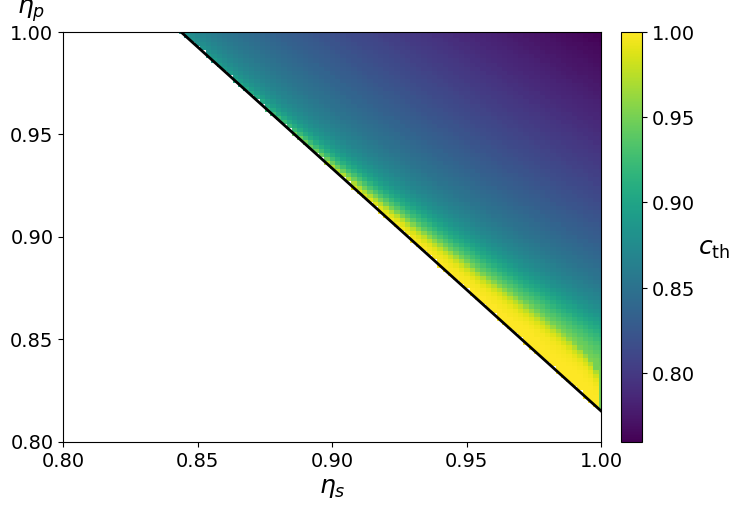

In [3]:
# ============================================================
# FAST BIN-PMF ENGINE + FAST c_th^{PMF} heatmap
# - No Python nested loops over states
# - Uses sparse bin-index arrays + np.bincount
# - Precomputes Para-map bin table once per n_bins
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import math

# -----------------------------
# 0) Operational boundary (same as before)
# -----------------------------
def q_map(q, U, V, eta_s, eta_p):
    q = np.clip(q, 0.0, 1.0)
    qU = (eta_s ** (U - 1)) * np.power(q, U)
    qV = (eta_s ** (V - 1)) * np.power(q, V)
    out = qU + qV - (2.0 - eta_p) * qU * qV
    return np.clip(out, 0.0, 1.0)

def q_inf_grid(U, V, ES, EP, tol=1e-13, max_iter=20000):
    q = np.ones_like(ES, dtype=np.float64)
    for _ in range(max_iter):
        qn = q_map(q, U, V, ES, EP)
        if np.max(np.abs(qn - q)) < tol:
            q = qn
            break
        q = qn
    return q

def _eta_p_from_fixed_point(q, U, V, eta_s):
    a = eta_s ** (U - 1)
    b = eta_s ** (V - 1)
    qU = a * (q ** U)
    qV = b * (q ** V)
    denom = qU * qV
    if denom <= 0.0:
        return np.nan
    return 2.0 - (qU + qV - q) / denom

def _g_of_q(q, U, V, eta_s):
    q = float(q)
    if not (0.0 < q < 1.0):
        return np.nan, np.nan
    a = eta_s ** (U - 1)
    b = eta_s ** (V - 1)
    qU = a * (q ** U)
    qV = b * (q ** V)
    denom = qU * qV
    if denom <= 0.0:
        return np.nan, np.nan
    eta_p = 2.0 - (qU + qV - q) / denom
    if not (0.0 <= eta_p <= 1.0):
        return np.nan, eta_p
    dU = a * U * (q ** (U - 1))
    dV = b * V * (q ** (V - 1))
    Rprime = dU + dV - (2.0 - eta_p) * (dU * qV + qU * dV)
    return Rprime - 1.0, eta_p

def threshold_curve_eta_p(U, V, eta_s_vals, q_scan=6000, q_eps=1e-8, bisect_iter=80):
    eta_s_out, eta_p_out = [], []
    q_grid = np.linspace(q_eps, 1.0 - q_eps, int(q_scan), dtype=np.float64)

    for eta_s in eta_s_vals:
        eta_s = float(eta_s)
        a = eta_s ** (U - 1)
        b = eta_s ** (V - 1)

        qU = a * np.power(q_grid, U)
        qV = b * np.power(q_grid, V)
        denom = qU * qV

        with np.errstate(divide="ignore", invalid="ignore"):
            eta_p = 2.0 - (qU + qV - q_grid) / denom

        dU = a * U * np.power(q_grid, U - 1)
        dV = b * V * np.power(q_grid, V - 1)
        Rprime = dU + dV - (2.0 - eta_p) * (dU * qV + qU * dV)
        g = Rprime - 1.0

        valid = np.isfinite(eta_p) & np.isfinite(g) & (eta_p >= 0.0) & (eta_p <= 1.0) & (denom > 0.0)
        gv = np.where(valid, g, np.nan)

        bracket = None
        finite = np.isfinite(gv)
        for i in range(len(q_grid) - 1):
            if finite[i] and finite[i + 1]:
                gi, gj = gv[i], gv[i + 1]
                if gi == 0.0 or gi * gj < 0.0:
                    bracket = (q_grid[i], q_grid[i + 1])
                    break
        if bracket is None:
            continue

        lo, hi = bracket
        glo, _ = _g_of_q(lo, U, V, eta_s)
        ghi, _ = _g_of_q(hi, U, V, eta_s)
        if not (np.isfinite(glo) and np.isfinite(ghi)) or glo * ghi > 0.0:
            continue

        a_lo, a_hi = lo, hi
        g_lo, g_hi = glo, ghi
        q_star = None
        for _ in range(bisect_iter):
            mid = 0.5 * (a_lo + a_hi)
            g_mid, _ = _g_of_q(mid, U, V, eta_s)
            if not np.isfinite(g_mid):
                break
            if abs(g_mid) < 1e-12 or (a_hi - a_lo) < 1e-12:
                q_star = mid
                break
            if g_lo * g_mid <= 0.0:
                a_hi, g_hi = mid, g_mid
            else:
                a_lo, g_lo = mid, g_mid
        if q_star is None:
            q_star = 0.5 * (a_lo + a_hi)

        eta_p_star = _eta_p_from_fixed_point(q_star, U, V, eta_s)
        if np.isfinite(eta_p_star) and (0.0 <= eta_p_star <= 1.0):
            eta_s_out.append(eta_s)
            eta_p_out.append(float(eta_p_star))

    return np.array(eta_s_out, float), np.array(eta_p_out, float)


# -----------------------------
# 1) Para map (vectorized)
# -----------------------------
def para_conpt_vec(a, b):
    # a,b are arrays of concurrence values in [0,1]
    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - a*a)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - b*b)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))


# -----------------------------
# 2) Bin tables cache (key speed win)
# -----------------------------
_BIN_CACHE = {}

def _round_to_idx(x, n_bins):
    # idx = floor(x*(n-1) + 0.5)
    n1 = n_bins - 1
    return np.clip((x * n1 + 0.5).astype(np.int64), 0, n1).astype(np.int32)

def get_para_idx_table(n_bins):
    key = ("para", int(n_bins))
    if key in _BIN_CACHE:
        return _BIN_CACHE[key]
    x = np.linspace(0.0, 1.0, int(n_bins), dtype=np.float64)
    A = x[:, None]
    B = x[None, :]
    P = para_conpt_vec(A, B)
    tab = _round_to_idx(P, n_bins)
    _BIN_CACHE[key] = tab
    return tab


# -----------------------------
# 3) Sparse PMF helpers (idx, p)
# -----------------------------
def prune_sparse(idxs, ps, p_min=0.0, max_states=None):
    if idxs.size == 0:
        return idxs, ps
    if p_min > 0.0:
        m = ps >= p_min
        idxs, ps = idxs[m], ps[m]
    if max_states is not None and idxs.size > int(max_states):
        k = int(max_states)
        sel = np.argpartition(ps, -k)[-k:]
        idxs, ps = idxs[sel], ps[sel]
    # sort by idx (stable deterministic)
    order = np.argsort(idxs)
    return idxs[order], ps[order]

def normalize_mass(ps, target_mass):
    s = float(ps.sum())
    if s <= 0.0:
        return ps
    return ps * (float(target_mass) / s)

def dense_add_from_sparse(out_dense, idxs, ps, scale=1.0):
    if idxs.size:
        out_dense[idxs] += float(scale) * ps


# -----------------------------
# 4) Fast bin-convolutions via bincount
# -----------------------------
def mul_convolve_sparse(idxA, pA, idxB, pB, n_bins):
    # output idx = round((i/(n-1))*(j/(n-1))*(n-1)) = round(i*j/(n-1))
    n1 = n_bins - 1
    # integer rounding: floor(i*j/n1 + 0.5) == floor((2ij + n1)/(2n1))
    ij = (idxA[:, None].astype(np.int64) * idxB[None, :].astype(np.int64))
    out_idx = ((2 * ij + n1) // (2 * n1)).astype(np.int32)

    w = (pA[:, None] * pB[None, :]).ravel()
    out = np.bincount(out_idx.ravel(), weights=w, minlength=n_bins).astype(np.float64)

    nz = out > 0
    return np.nonzero(nz)[0].astype(np.int32), out[nz]

def para_convolve_sparse(idxA, pA, idxB, pB, para_idx_tab, n_bins):
    out_idx = para_idx_tab[np.ix_(idxA, idxB)]
    w = (pA[:, None] * pB[None, :]).ravel()
    out = np.bincount(out_idx.ravel(), weights=w, minlength=n_bins).astype(np.float64)

    nz = out > 0
    return np.nonzero(nz)[0].astype(np.int32), out[nz]


# -----------------------------
# 5) Series chain + Parallel combine (bin-fast)
# -----------------------------
def series_chain_bin(dist_idx, dist_p, p0, L, eta_s, n_bins, p_min=0.0, max_states=None):
    if L == 1:
        return dist_idx, dist_p, p0

    q = 1.0 - float(p0)
    q_chain = (q ** L) * (float(eta_s) ** (L - 1))
    p0_chain = 1.0 - q_chain

    # product of L iid nonzero draws
    # small optimization: if support is a delta (size 1), product is still a delta
    idx, ps = dist_idx, dist_p
    if idx.size == 1:
        # value bin -> repeated multiplication L times (in value space)
        n1 = n_bins - 1
        x = idx[0] / n1
        xL = x ** L
        idx_out = np.array([int(xL * n1 + 0.5)], dtype=np.int32)
        p_out = np.array([q_chain], dtype=np.float64)
        return idx_out, p_out, p0_chain

    # do L-1 multiplications (U,V are small in your use; keep it simple + robust)
    cur_idx, cur_p = idx, ps
    for _ in range(L - 1):
        cur_idx, cur_p = mul_convolve_sparse(cur_idx, cur_p, idx, ps, n_bins)
        cur_idx, cur_p = prune_sparse(cur_idx, cur_p, p_min=p_min, max_states=max_states)

    cur_p = normalize_mass(cur_p, q_chain)
    return cur_idx, cur_p, p0_chain

def parallel_combine_bin(idxU, pU, p0U, idxV, pV, p0V, eta_p, para_idx_tab, n_bins, p_min=0.0, max_states=None):
    out_dense = np.zeros(n_bins, dtype=np.float64)

    # one survives
    dense_add_from_sparse(out_dense, idxU, pU, scale=float(p0V))
    dense_add_from_sparse(out_dense, idxV, pV, scale=float(p0U))

    qU = 1.0 - float(p0U)
    qV = 1.0 - float(p0V)
    if qU > 0 and qV > 0 and float(eta_p) > 0.0 and idxU.size and idxV.size:
        idxP, pP = para_convolve_sparse(idxU, pU, idxV, pV, para_idx_tab, n_bins)
        pP = normalize_mass(pP, float(eta_p) * (qU * qV))
        dense_add_from_sparse(out_dense, idxP, pP, scale=1.0)

    # prune and compress
    nz = out_dense > 0
    idx_out = np.nonzero(nz)[0].astype(np.int32)
    p_out = out_dense[nz]

    idx_out, p_out = prune_sparse(idx_out, p_out, p_min=p_min, max_states=max_states)

    q_out = float(p_out.sum())
    p0_out = 1.0 - q_out
    return idx_out, p_out, p0_out


# -----------------------------
# 6) Fast sponge_distribution_uv for ConPT (bin mode)
# -----------------------------
def sponge_distribution_uv_bin_fast(
    n, U, V,
    c_init,
    eta_s, eta_p,
    n_bins=501,
    p_min=0.0,
    max_states=None
):
    n = int(n); U = int(U); V = int(V)
    n_bins = int(n_bins)
    para_tab = get_para_idx_table(n_bins)
    n1 = n_bins - 1

    # initial delta at c_init (no atom at 0 for ConPT leaf)
    c0 = float(np.clip(c_init, 0.0, 1.0))
    idx = np.array([int(c0 * n1 + 0.5)], dtype=np.int32)
    ps = np.array([1.0], dtype=np.float64)
    p0 = 0.0

    for _ in range(n):
        idxU, pU, p0U = series_chain_bin(idx, ps, p0, L=U, eta_s=eta_s, n_bins=n_bins, p_min=p_min, max_states=max_states)
        idxV, pV, p0V = series_chain_bin(idx, ps, p0, L=V, eta_s=eta_s, n_bins=n_bins, p_min=p_min, max_states=max_states)
        idx, ps, p0 = parallel_combine_bin(idxU, pU, p0U, idxV, pV, p0V, eta_p=eta_p, para_idx_tab=para_tab, n_bins=n_bins, p_min=p_min, max_states=max_states)

    # convert to dict (if you want), and ensure 0 is not inside
    pmf = {float(i / (n_bins - 1)): float(p) for i, p in zip(idx, ps) if i != 0}
    if idx.size and idx[0] == 0:
        # if 0 made it into support (shouldn’t, but safe)
        p0 = p0 + float(ps[idx == 0].sum())
        pmf.pop(0.0, None)

    return pmf, float(p0), idx, ps  # idx,ps returned for fast stats


# -----------------------------
# 7) Coarse threshold solver using "high bin mass" (more stable than exact 1.0 only)
# -----------------------------
def high_mass_from_sparse(idx, ps, n_bins, high_bins=2):
    # mass in top `high_bins` bins (captures near-1 delta under binning)
    cut = (n_bins - 1) - int(high_bins) + 1
    m = idx >= cut
    return float(ps[m].sum()) if np.any(m) else 0.0

def solve_c_th_coarse_fastbin(
    U, V, eta_s, eta_p,
    n_eval=20,
    n_bins=501,
    p_target=0.5,
    c_guess=0.2,
    c_tol=0.02,          # 2 d.p. is enough for a heatmap
    bisect_steps=5,
    expand_step=0.05,
    expand_steps=5,
    p_min=1e-10,
    max_states=None,
    high_bins=2
):
    cache = {}

    def eval_high(c):
        key = round(float(c), 3)
        if key in cache:
            return cache[key]
        _, _, idx, ps = sponge_distribution_uv_bin_fast(
            n=n_eval, U=U, V=V,
            c_init=float(c),
            eta_s=eta_s, eta_p=eta_p,
            n_bins=n_bins,
            p_min=p_min,
            max_states=max_states
        )
        val = high_mass_from_sparse(idx, ps, n_bins=n_bins, high_bins=high_bins)
        cache[key] = val
        return val

    pmax = eval_high(1.0)
    if not np.isfinite(pmax) or pmax <= 0.0:
        return np.nan
    target = float(p_target) * pmax

    def h(c):  # monotone-ish step
        return eval_high(c) - target

    c = float(np.clip(c_guess, 0.0, 1.0))
    hc = h(c)
    if abs(hc) < 0.05 * pmax:
        return c

    # bracket
    if hc >= 0:
        hi = c
        lo = max(0.0, hi - expand_step)
        for _ in range(expand_steps):
            if h(lo) < 0 or lo <= 0:
                break
            hi = lo
            lo = max(0.0, hi - expand_step)
        if h(lo) >= 0:
            lo = 0.0
    else:
        lo = c
        hi = min(1.0, lo + expand_step)
        for _ in range(expand_steps):
            if h(hi) >= 0 or hi >= 1.0:
                break
            lo = hi
            hi = min(1.0, lo + expand_step)
        if h(hi) < 0:
            hi = 1.0

    hlo, hhi = h(lo), h(hi)
    if not (np.isfinite(hlo) and np.isfinite(hhi)) or hlo >= 0 or hhi < 0:
        return np.nan

    for _ in range(int(bisect_steps)):
        mid = 0.5 * (lo + hi)
        if h(mid) >= 0:
            hi = mid
        else:
            lo = mid
        if (hi - lo) <= c_tol:
            break

    return float(hi)


# -----------------------------
# 8) Heatmap plot: c_th^{PMF}(eta_s, eta_p) with same boundary as q_inf
# -----------------------------
def plot_c_th_pmf_heatmap_fastbin(
    *,
    U=2, V=2,
    res=21,
    curve_points=1600,
    eta_s_min=0.80, eta_s_max=1.00,
    eta_p_min=0.80, eta_p_max=1.00,
    n_eval=20,
    n_bins=501,
    p_target=0.5,
    # coarse accuracy (heatmap)
    c_tol=0.02,
    bisect_steps=5,
    expand_step=0.05,
    expand_steps=5,
    # prune controls
    p_min=1e-10,
    max_states=None,
    high_bins=2,
    # mask
    mask_tol=1e-12,
    # fonts
    tick_fs=14,
    label_fs=18,
):
    eta_s_vals = np.linspace(float(eta_s_min), float(eta_s_max), int(res), dtype=np.float64)
    eta_p_vals = np.linspace(float(eta_p_min), float(eta_p_max), int(res), dtype=np.float64)
    ES, EP = np.meshgrid(eta_s_vals, eta_p_vals, indexing="xy")

    qinf = q_inf_grid(U, V, ES, EP, tol=1e-13, max_iter=20000)
    perco = (qinf > mask_tol)

    # boundary curve
    eta_s_curve = np.linspace(1e-6, 1.0, int(curve_points), dtype=np.float64)
    xs, yp_th = threshold_curve_eta_p(U, V, eta_s_curve)

    cth = np.full_like(qinf, np.nan, dtype=np.float64)

    # continuation seeds
    prev_row_seed = 0.2
    for i, eta_p in enumerate(eta_p_vals):
        c_guess = float(prev_row_seed)
        for j, eta_s in enumerate(eta_s_vals):
            if not perco[i, j]:
                continue
            c_val = solve_c_th_coarse_fastbin(
                U, V, float(eta_s), float(eta_p),
                n_eval=n_eval, n_bins=n_bins,
                p_target=p_target,
                c_guess=c_guess,
                c_tol=c_tol,
                bisect_steps=bisect_steps,
                expand_step=expand_step,
                expand_steps=expand_steps,
                p_min=p_min,
                max_states=max_states,
                high_bins=high_bins
            )
            cth[i, j] = c_val
            if np.isfinite(c_val):
                c_guess = c_val

        mid = len(eta_s_vals)//2
        if np.isfinite(cth[i, mid]):
            prev_row_seed = cth[i, mid]
        print(f"row {i+1}/{len(eta_p_vals)} done")

    cth_masked = np.ma.masked_invalid(cth)

    # plot
    fig, ax = plt.subplots(figsize=(7.6, 5.2))
    pc = ax.pcolormesh(
        eta_s_vals, eta_p_vals, cth_masked,
        shading="auto",
        cmap="viridis"
    )
    ax.plot(xs, yp_th, color="black", linewidth=2.0)

    ax.set_xlim(eta_s_min, eta_s_max)
    ax.set_ylim(eta_p_min, eta_p_max)

    ticks = [0.80, 0.85, 0.90, 0.95, 1.00]
    ax.set_xticks([t for t in ticks if eta_s_min - 1e-9 <= t <= eta_s_max + 1e-9])
    ax.set_yticks([t for t in ticks if eta_p_min - 1e-9 <= t <= eta_p_max + 1e-9])
    ax.set_xticklabels([f"{t:.2f}" for t in ax.get_xticks()])
    ax.set_yticklabels([f"{t:.2f}" for t in ax.get_yticks()])

    ax.set_xlabel(r"$\eta_s$", fontsize=label_fs)
    ax.set_ylabel(r"$\eta_p$", rotation=0, labelpad=18, fontsize=label_fs)
    ax.yaxis.set_label_coords(-0.06, 1.02)
    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    cbar = fig.colorbar(pc, ax=ax, pad=0.03)
    cbar.ax.tick_params(labelsize=tick_fs)
    cbar.set_label(r"$c_{\rm th}$", rotation=0, labelpad=14, fontsize=label_fs)

    plt.tight_layout()
    plt.show()

    return {
        "eta_s_vals": eta_s_vals,
        "eta_p_vals": eta_p_vals,
        "c_th_pmf": cth,
        "q_inf": qinf,
        "threshold_curve": (xs, yp_th),
        "mask": perco
    }


# -----------------------------
# Example (this should be *much* faster than dict loops)
# -----------------------------
out_c = plot_c_th_pmf_heatmap_fastbin(
    U=2, V=2,
    res=101,
    curve_points=1600,
    n_eval=50,
    n_bins=1001,
    p_target=0.5,
    c_tol=0.001,
    bisect_steps=40,
    expand_step=0.01,
    expand_steps=30,
    p_min=1e-14,
    high_bins=4
)


## Smooth 101x101 PMF plot to 1001x1001

In [4]:
import numpy as np
import time

def save_cth_results(out_c, basename="cth_pmf_results"):
    """
    Save c_th^{PMF} grid + axes + optional extras from out_c.
    Writes:
      - <basename>__YYYYmmdd_HHMMSS.npz   (recommended)
      - <basename>__YYYYmmdd_HHMMSS_tidy.csv  (optional)
    """
    if out_c is None or not isinstance(out_c, dict):
        raise ValueError("out_c must be the dict returned by plot_c_th_pmf_heatmap_fastbin(...)")

    required = ["eta_s_vals", "eta_p_vals", "c_th_pmf"]
    for k in required:
        if k not in out_c:
            raise KeyError(f"out_c is missing key '{k}'. Available keys: {list(out_c.keys())}")

    eta_s_vals = np.asarray(out_c["eta_s_vals"], dtype=np.float64)
    eta_p_vals = np.asarray(out_c["eta_p_vals"], dtype=np.float64)
    c_th_pmf  = np.asarray(out_c["c_th_pmf"],  dtype=np.float64)

    # Optional extras if present
    q_inf = np.asarray(out_c["q_inf"], dtype=np.float64) if "q_inf" in out_c else None
    mask  = np.asarray(out_c["mask"], dtype=np.bool_)    if "mask"  in out_c else None
    curve = out_c.get("threshold_curve", None)

    ts = time.strftime("%Y%m%d_%H%M%S")
    npz_path = f"{basename}__{ts}.npz"

    # To reduce filesize a lot, store float32 versions as well (keep float64 too if you want)
    payload = {
        "eta_s_vals": eta_s_vals.astype(np.float32),
        "eta_p_vals": eta_p_vals.astype(np.float32),
        "c_th_pmf":   c_th_pmf.astype(np.float32),
    }
    if q_inf is not None:
        payload["q_inf"] = q_inf.astype(np.float32)
    if mask is not None:
        payload["mask"] = mask
    if curve is not None:
        xs, yp = curve
        payload["curve_eta_s"] = np.asarray(xs, dtype=np.float32)
        payload["curve_eta_p"] = np.asarray(yp, dtype=np.float32)

    np.savez_compressed(npz_path, **payload)
    print(f"Saved: {npz_path}")
    print(f"  shapes: c_th_pmf={payload['c_th_pmf'].shape}, eta_s={eta_s_vals.shape}, eta_p={eta_p_vals.shape}")

    # Optional tidy CSV (can be large for res~1001 -> ~1e6 rows)
    csv_path = f"{basename}__{ts}_tidy.csv"
    ES, EP = np.meshgrid(eta_s_vals, eta_p_vals, indexing="xy")
    cols = [ES.ravel(), EP.ravel(), c_th_pmf.ravel()]
    header = "eta_s,eta_p,c_th_pmf"
    if q_inf is not None:
        cols.append(q_inf.ravel())
        header += ",q_inf"
    if mask is not None:
        cols.append(mask.ravel().astype(np.int8))
        header += ",percolating_mask"

    arr = np.vstack(cols).T
    # If file size worries you, comment out the CSV line below.
    np.savetxt(csv_path, arr, delimiter=",", header=header, comments="")
    print(f"Saved: {csv_path}   (rows={arr.shape[0]})")

    return npz_path, csv_path


# --- run this after your heatmap finishes ---
npz_file, csv_file = save_cth_results(out_c, basename="cth_pmf_U2V2")


Saved: cth_pmf_U2V2__20260219_125302.npz
  shapes: c_th_pmf=(101, 101), eta_s=(101,), eta_p=(101,)
Saved: cth_pmf_U2V2__20260219_125302_tidy.csv   (rows=10201)


Wrote: cth_pmf_U2V2__20260219_125302_tidy_1001x1001_linear_clean.csv


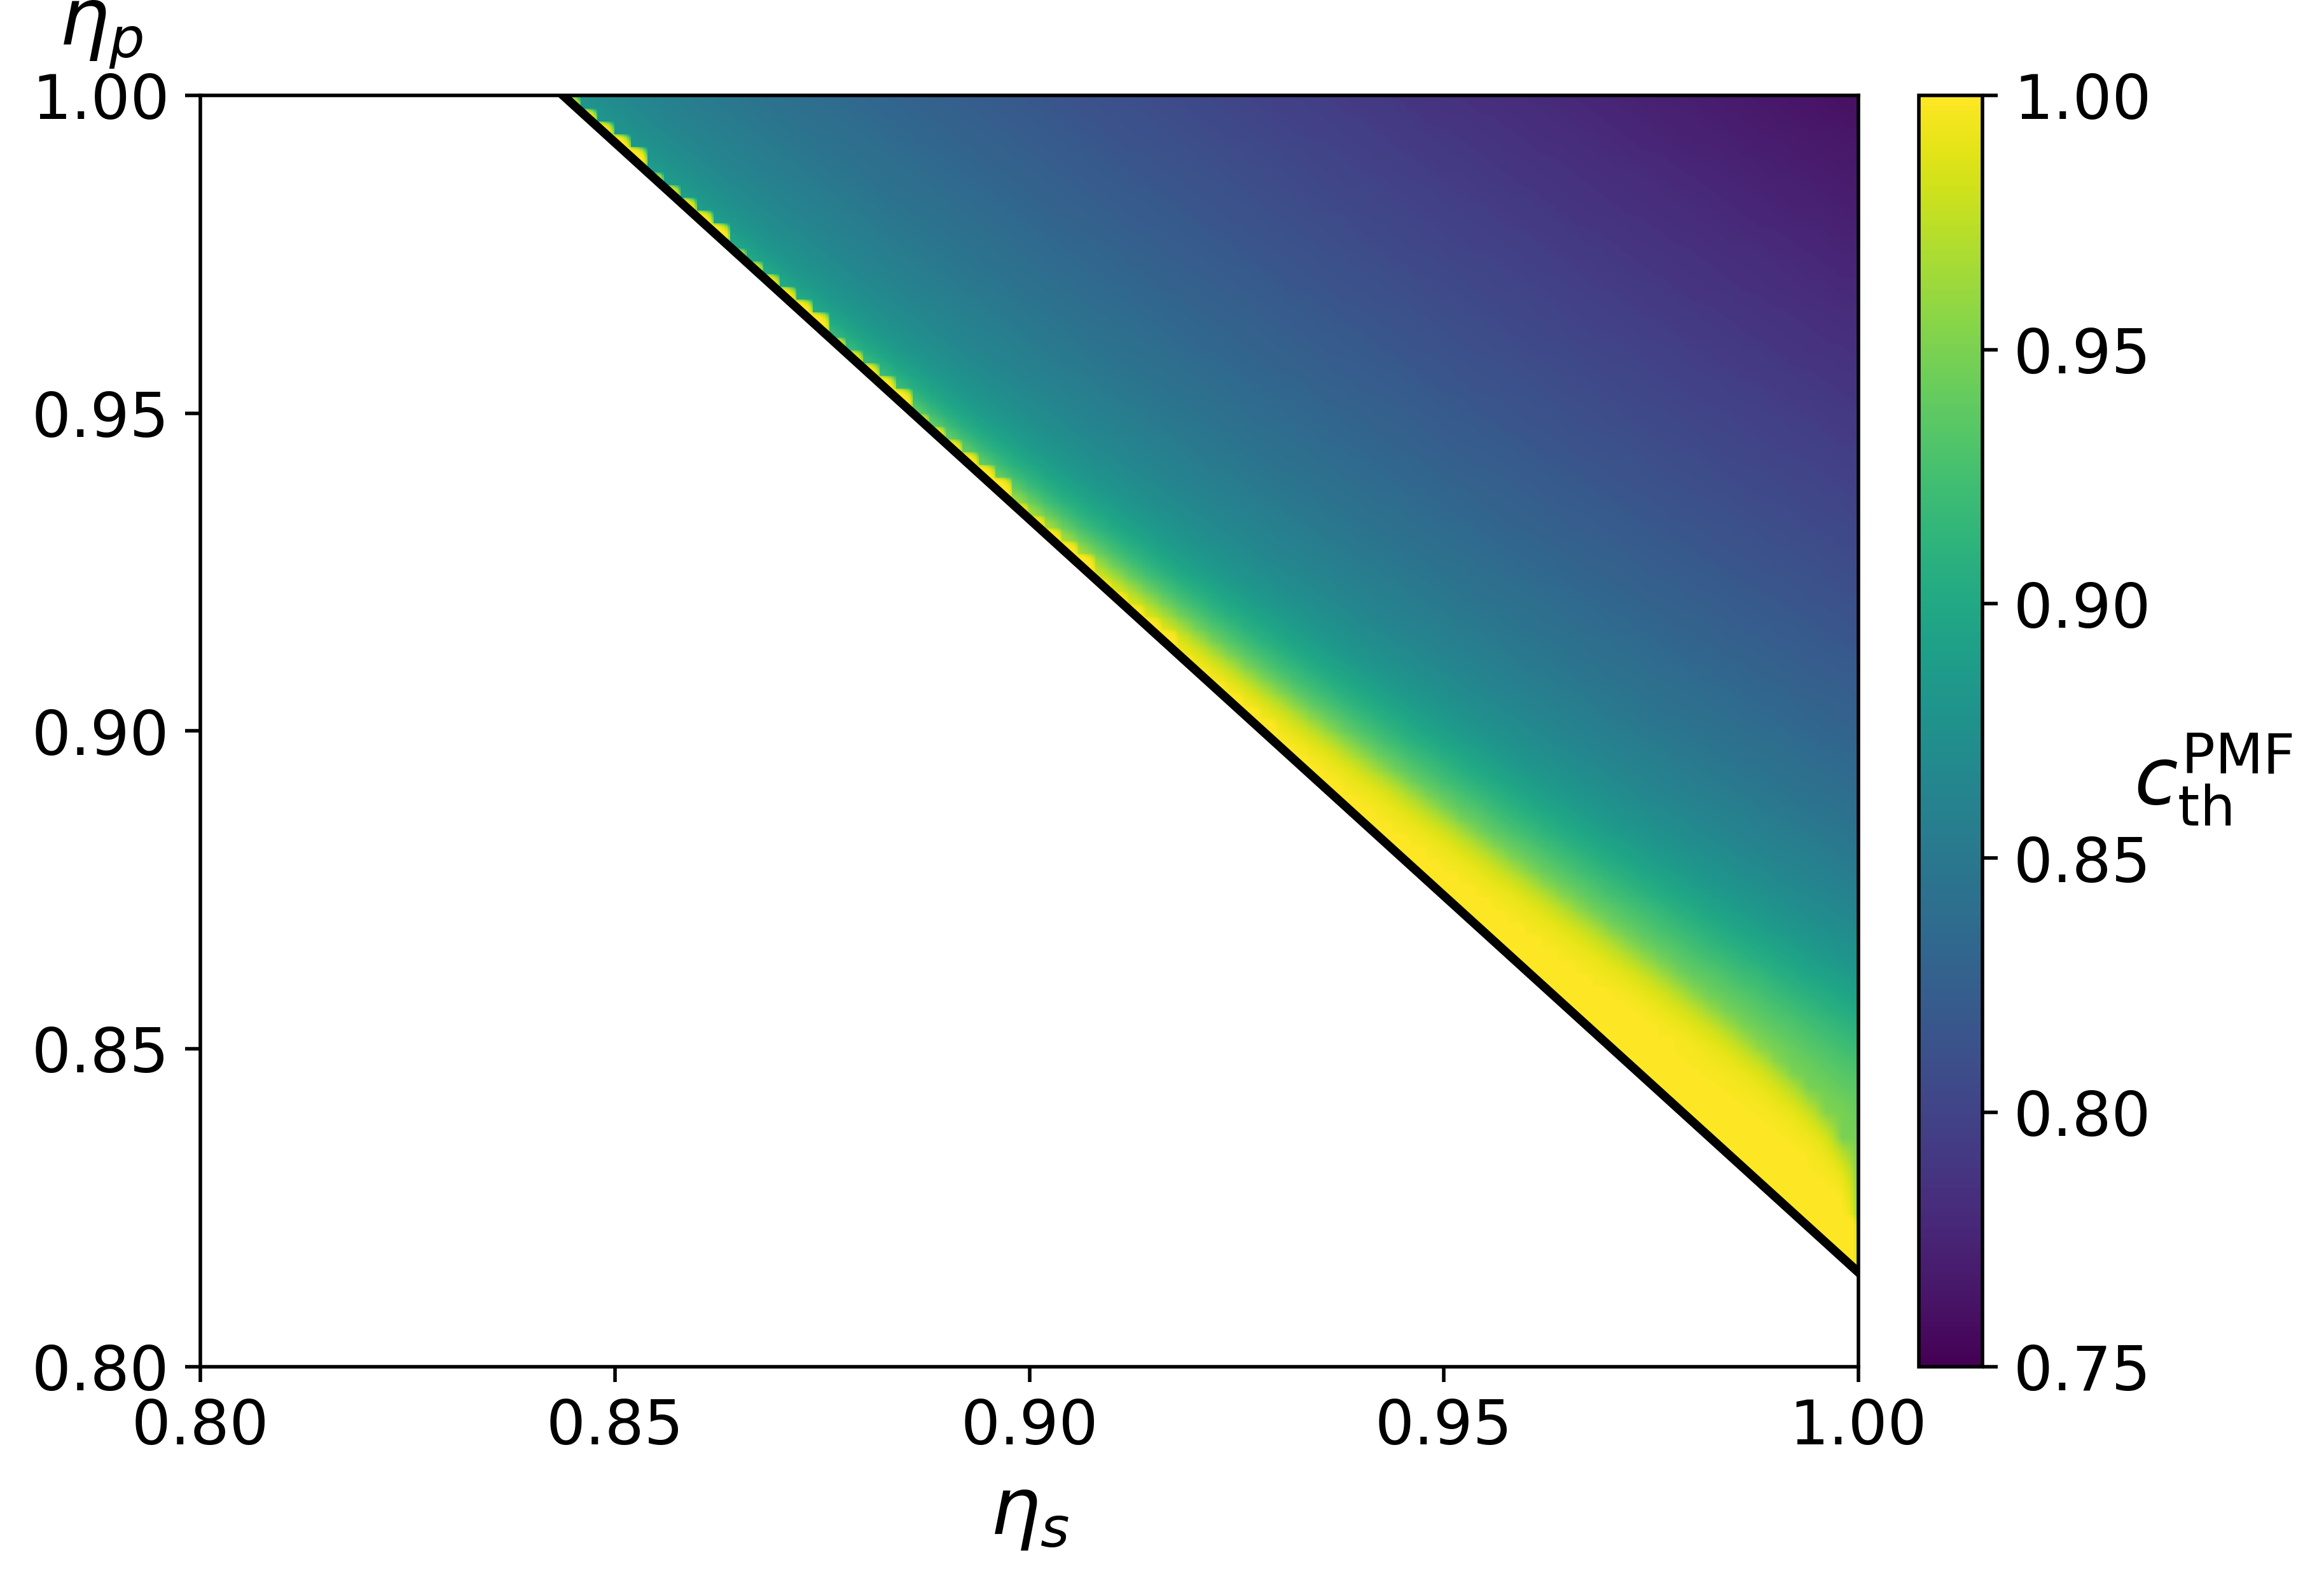

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.interpolate import RegularGridInterpolator
from scipy.ndimage import gaussian_filter

# =========================================================
# STABLE upsampling for c_th^PMF (101x101 -> 1001x1001)
# Uses LINEAR interpolation on deficit d = 1 - c_th
# (avoids cubic spline ringing / speckles near boundary)
# =========================================================

# -------------------------
# User inputs
# -------------------------
in_csv  = "cth_pmf_U2V2__20260219_125302_tidy.csv"   # coarse 101x101
out_csv = "cth_pmf_U2V2__20260219_125302_tidy_1001x1001_linear_clean.csv"

N_NEW = 1001

# Plot settings
VMIN, VMAX = 0.75, 1.00
tick_fs  = 14
label_fs = 18
cmap     = "viridis"
fig_dpi  = 500

# Optional tiny cosmetic smoothing inside mask only (0.0 recommended first)
SIGMA = 0.0

# -------------------------
# Analytic (2,2) boundary
# eta_p^th(eta_s) = 2 - (32/27) eta_s
# -------------------------
def eta_p_threshold_22(eta_s):
    eta_s = np.asarray(eta_s, dtype=float)
    return 2.0 - (32.0 / 27.0) * eta_s

# -------------------------
# NaN-aware Gaussian (optional)
# -------------------------
def nanaware_gaussian(Z, sigma):
    if sigma is None or sigma <= 0:
        return Z
    X = np.where(np.isfinite(Z), Z, 0.0)
    W = np.isfinite(Z).astype(float)
    Xs = gaussian_filter(X, sigma=sigma)
    Ws = gaussian_filter(W, sigma=sigma)
    return np.where(Ws > 1e-12, Xs / Ws, np.nan)

# -------------------------
# Load coarse CSV
# -------------------------
df = pd.read_csv(in_csv)

required = {"eta_s", "eta_p", "c_th_pmf", "q_inf", "percolating_mask"}
missing = required.difference(df.columns)
if missing:
    raise ValueError(f"Missing columns in {in_csv}: {missing}")

eta_s = np.sort(df["eta_s"].unique())
eta_p = np.sort(df["eta_p"].unique())

# Grids: rows = eta_p, cols = eta_s
Z_cth = (
    df.pivot(index="eta_p", columns="eta_s", values="c_th_pmf")
      .reindex(index=eta_p, columns=eta_s)
      .values.astype(float)
)
Z_qinf = (
    df.pivot(index="eta_p", columns="eta_s", values="q_inf")
      .reindex(index=eta_p, columns=eta_s)
      .values.astype(float)
)

# Exact analytic mask on coarse grid (ignore saved mask to avoid inconsistencies)
eta_p_th_coarse = eta_p_threshold_22(eta_s)
M_coarse = (eta_p[:, None] >= eta_p_th_coarse[None, :])

# Enforce physical ranges + mask
Z_cth = np.clip(Z_cth, 0.0, 1.0)
Z_qinf = np.clip(Z_qinf, 0.0, 1.0)

Z_cth = np.where(M_coarse, Z_cth, np.nan)
Z_qinf = np.where(M_coarse, Z_qinf, np.nan)

# -------------------------
# Interpolate deficit d = 1 - c_th
# Key trick:
#   set d=0 outside the percolating region (consistent with boundary value),
#   then linearly interpolate. This removes spline ringing at the wedge edge.
# -------------------------
EPS_D = 1e-6  # small floor for stable log interpolation

D_coarse = np.where(np.isfinite(Z_cth), 1.0 - Z_cth, 0.0)   # outside -> 0
Q_coarse = np.where(np.isfinite(Z_qinf), Z_qinf, 0.0)

# Interpolate log(deficit) instead of deficit (much more stable near sharp boundary layers)
PHI_coarse = np.log(np.clip(D_coarse, 0.0, None) + EPS_D)

interp_PHI = RegularGridInterpolator(
    (eta_p, eta_s), PHI_coarse,
    method="linear", bounds_error=False, fill_value=np.log(EPS_D)
)
interp_Q = RegularGridInterpolator(
    (eta_p, eta_s), Q_coarse,
    method="linear", bounds_error=False, fill_value=0.0
)

# -------------------------
# Dense grid (1001x1001)
# -------------------------
eta_s_new = np.linspace(float(eta_s.min()), float(eta_s.max()), N_NEW)
eta_p_new = np.linspace(float(eta_p.min()), float(eta_p.max()), N_NEW)

ES_new, EP_new = np.meshgrid(eta_s_new, eta_p_new, indexing="xy")

# Exact dense mask (pixel-perfect)
eta_p_th_new = eta_p_threshold_22(eta_s_new)
M_up = (eta_p_new[:, None] >= eta_p_th_new[None, :])

# Evaluate interpolators (RegularGridInterpolator expects points as (eta_p, eta_s))
pts = np.column_stack([EP_new.ravel(order="C"), ES_new.ravel(order="C")])

PHI_up = interp_PHI(pts).reshape(EP_new.shape, order="C")
Q_up   = interp_Q(pts).reshape(EP_new.shape, order="C")

D_up = np.exp(PHI_up) - EPS_D
D_up = np.clip(D_up, 0.0, 1.0)

# Optional very small smoothing (inside mask only)
if SIGMA and SIGMA > 0:
    D_up = nanaware_gaussian(np.where(M_up, D_up, np.nan), SIGMA)
    Q_up = nanaware_gaussian(np.where(M_up, Q_up, np.nan), SIGMA)

# Reconstruct c_th and enforce exact boundary/mask
D_up = np.clip(D_up, 0.0, 1.0)
Q_up = np.clip(Q_up, 0.0, 1.0)

Z_cth_up = 1.0 - D_up
Z_qinf_up = Q_up

# Exact mask
Z_cth_up[~M_up] = np.nan
Z_qinf_up[~M_up] = np.nan

# Enforce exact boundary behavior very near the line (prevents tiny slivers)
dist = EP_new - eta_p_threshold_22(ES_new)  # >=0 inside
# Enforce exact boundary value in a thin strip (~1 dense pixel) to prevent tiny edge artifacts
deta_p_new = eta_p_new[1] - eta_p_new[0]
near_boundary = M_up & (dist >= 0.0) & (dist <= 1.5 * deta_p_new)
Z_cth_up[near_boundary] = 1.0
Z_qinf_up[near_boundary] = 0.0

# Final physical clipping
Z_cth_up = np.where(np.isfinite(Z_cth_up), np.clip(Z_cth_up, 0.0, 1.0), np.nan)
Z_qinf_up = np.where(np.isfinite(Z_qinf_up), np.clip(Z_qinf_up, 0.0, 1.0), np.nan)

# -------------------------
# Save new tidy CSV (1001x1001)
# -------------------------
out = pd.DataFrame({
    "eta_s": ES_new.ravel(order="C"),
    "eta_p": EP_new.ravel(order="C"),
    "c_th_pmf": Z_cth_up.ravel(order="C"),
    "q_inf": Z_qinf_up.ravel(order="C"),
    "percolating_mask": M_up.astype(int).ravel(order="C"),
})
out.to_csv(out_csv, index=False)
print("Wrote:", out_csv)

# -------------------------
# Plot (same style)
# -------------------------
fig, ax = plt.subplots(figsize=(7.6, 5.2), dpi=fig_dpi)

cmap_obj = plt.get_cmap(cmap).copy()
cmap_obj.set_bad(color="white")

pc = ax.pcolormesh(
    eta_s_new, eta_p_new,
    np.ma.masked_invalid(Z_cth_up),
    shading="auto",
    cmap=cmap_obj,
    vmin=VMIN, vmax=VMAX
)

# Exact analytic boundary (smooth straight line)
xs = np.linspace(float(eta_s_new.min()), float(eta_s_new.max()), 2000)
yp_th = eta_p_threshold_22(xs)
ax.plot(xs, yp_th, color="black", linewidth=2.0)

ax.set_xlim(float(eta_s_new.min()), float(eta_s_new.max()))
ax.set_ylim(float(eta_p_new.min()), float(eta_p_new.max()))

ticks = [0.80, 0.85, 0.90, 0.95, 1.00]
ax.set_xticks([t for t in ticks if eta_s_new.min() - 1e-9 <= t <= eta_s_new.max() + 1e-9])
ax.set_yticks([t for t in ticks if eta_p_new.min() - 1e-9 <= t <= eta_p_new.max() + 1e-9])
ax.set_xticklabels([f"{t:.2f}" for t in ax.get_xticks()])
ax.set_yticklabels([f"{t:.2f}" for t in ax.get_yticks()])

ax.set_xlabel(r"$\eta_s$", fontsize=label_fs)
ax.set_ylabel(r"$\eta_p$", rotation=0, labelpad=18, fontsize=label_fs)
ax.yaxis.set_label_coords(-0.06, 1.02)
ax.tick_params(axis="both", which="both", labelsize=tick_fs)

cbar = fig.colorbar(pc, ax=ax, pad=0.03)
cbar.ax.tick_params(labelsize=tick_fs)
cbar.set_label(r"$c_{\rm th}^{\rm PMF}$", rotation=0, labelpad=14, fontsize=label_fs)

plt.tight_layout()
plt.show()

## Heatplot from MF - approximated Concurrence threshold

/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1546456429.py:89: RuntimeWarning: invalid value encountered in divide
  w_p = np.where(valid_w, w_p / w_sum, 0.0)
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1546456429.py:90: RuntimeWarning: invalid value encountered in divide
  w_u = np.where(valid_w, w_u / w_sum, 0.0)
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1546456429.py:91: RuntimeWarning: invalid value encountered in divide
  w_v = np.where(valid_w, w_v / w_sum, 0.0)


Wrote: cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline__c_th_mf_corrected.csv


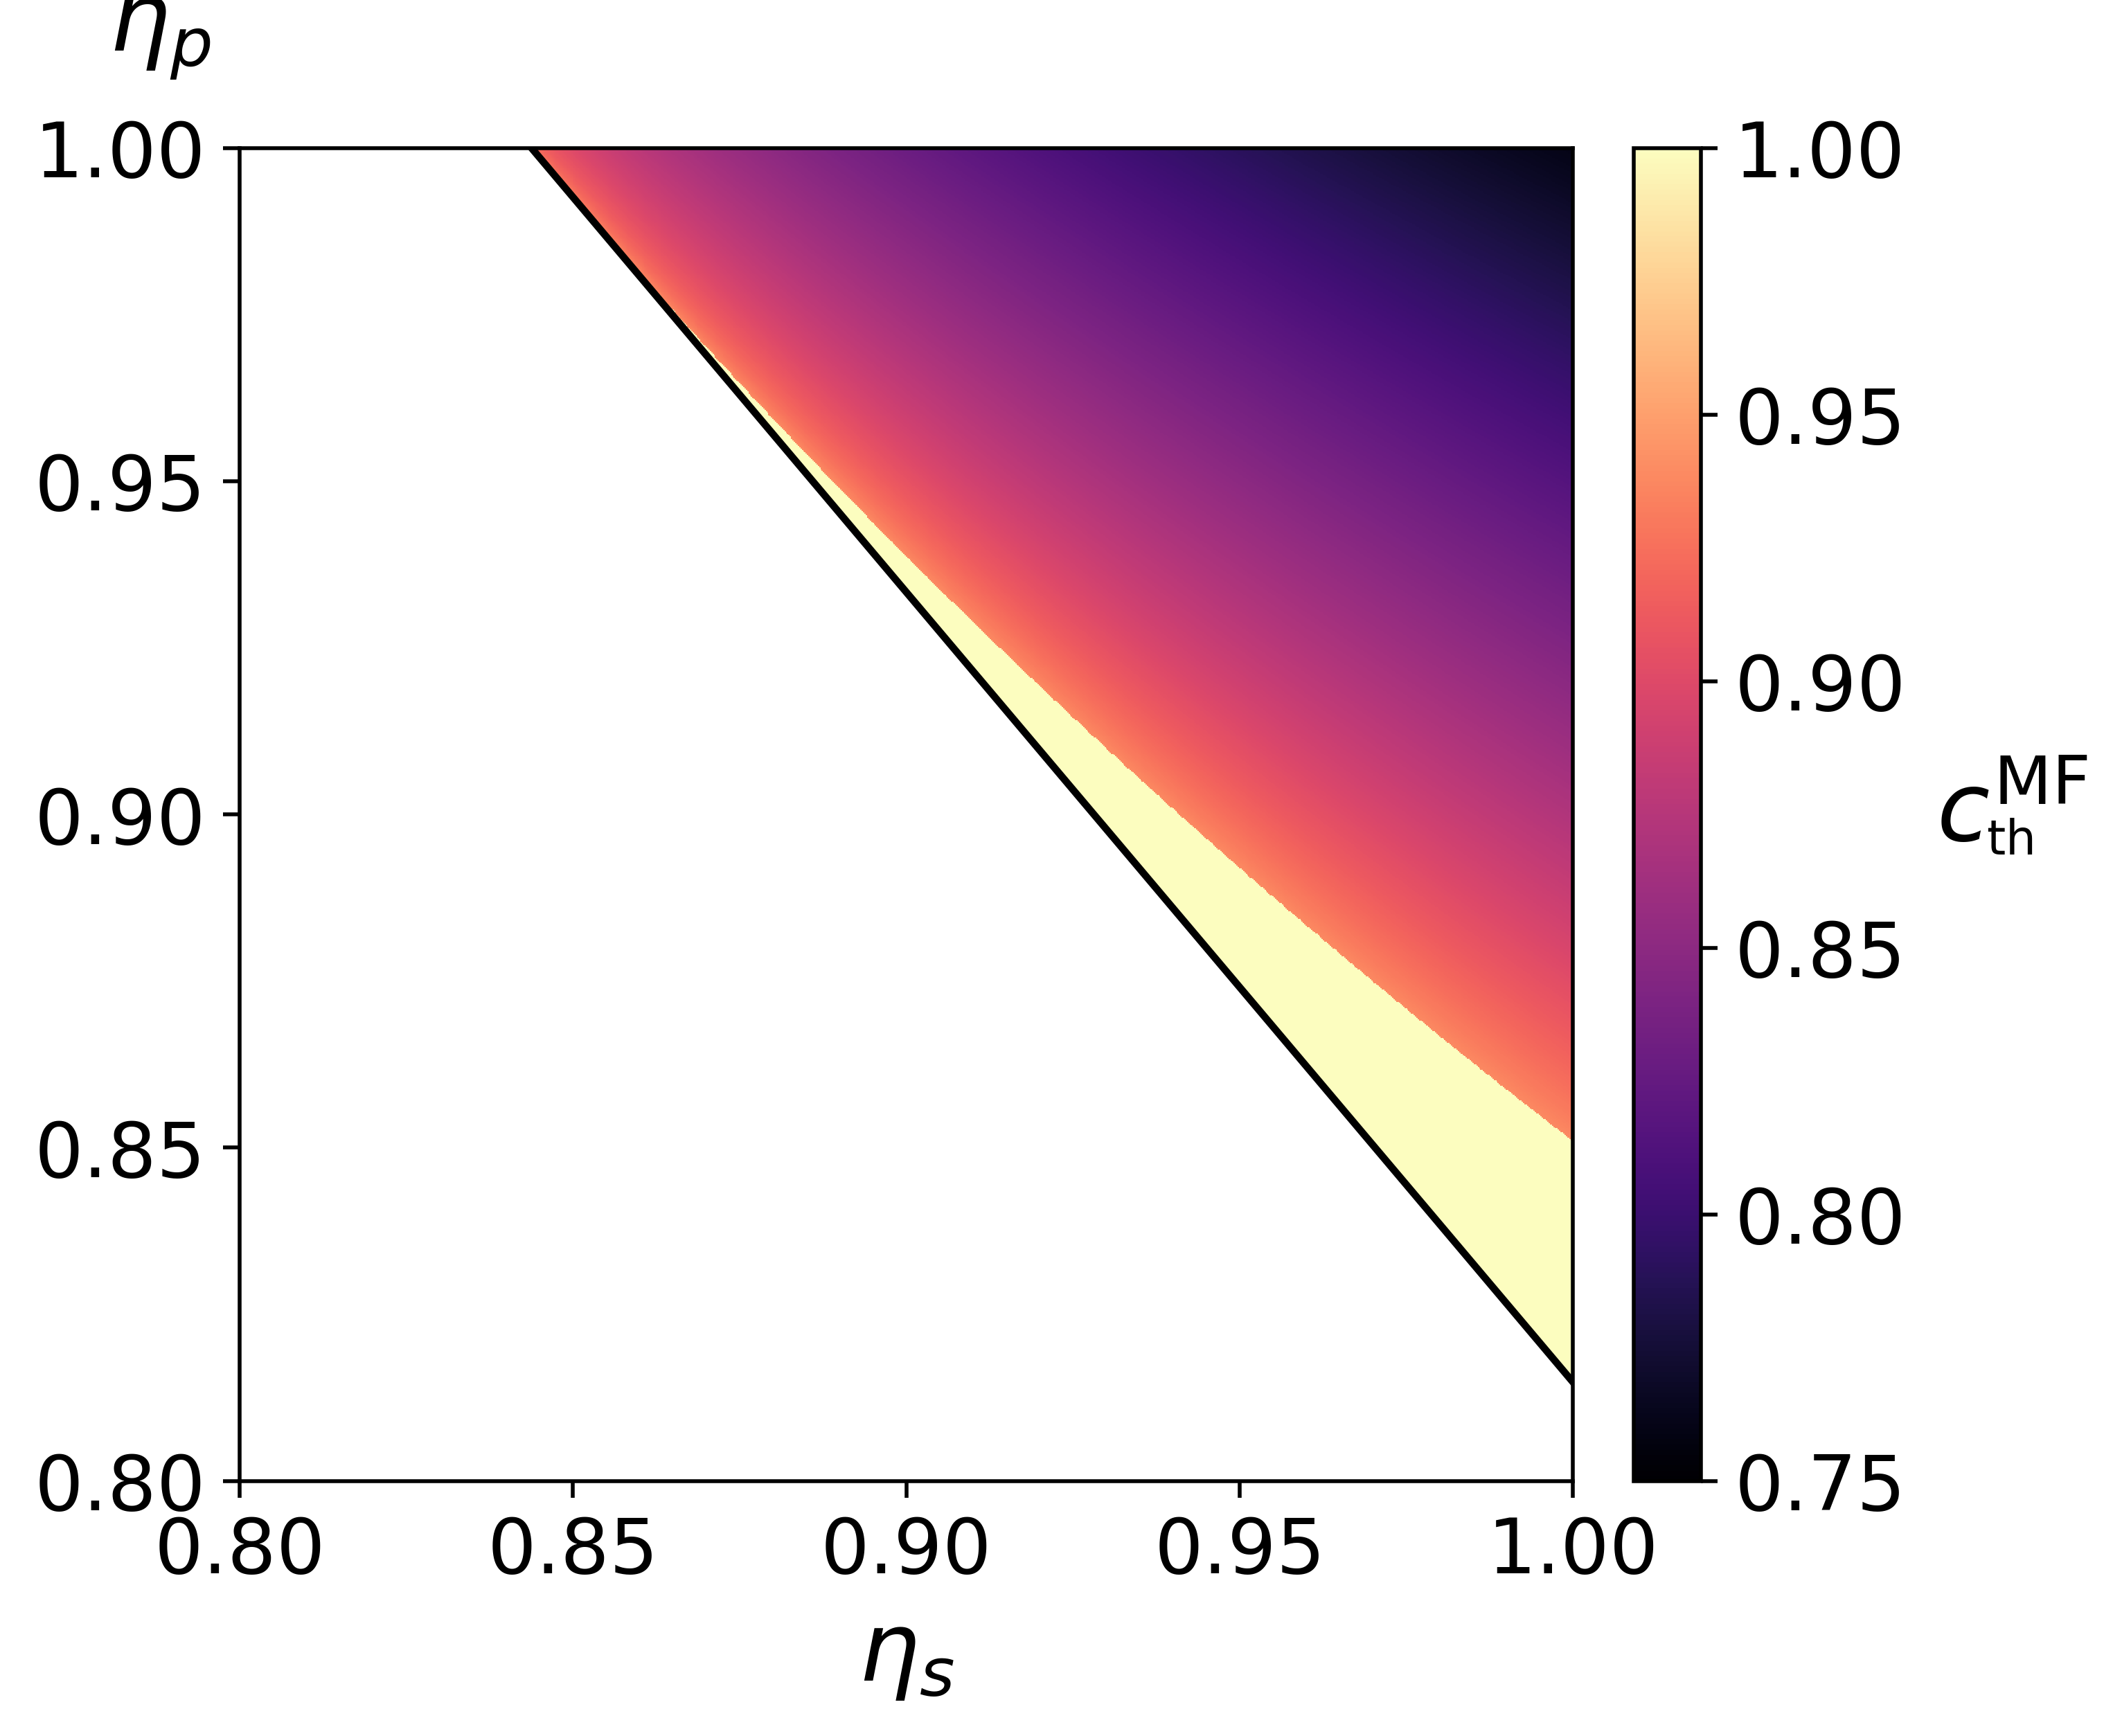

Saved corrected MF CSV: cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline__c_th_mf_corrected.csv


In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =========================================================
# 0) Operational q_inf (compute exactly on the plotting grid)
# =========================================================
def q_map(q, U, V, eta_s, eta_p):
    q = np.clip(q, 0.0, 1.0)
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    return np.clip(qU + qV - (2.0 - eta_p) * qU * qV, 0.0, 1.0)


def q_inf_grid(U, V, eta_s_grid, eta_p_grid, tol=1e-13, max_iter=20000):
    """
    Largest fixed point from q0=1 (relevant operational survival probability).
    Vectorized on the whole grid.
    """
    q = np.ones_like(eta_s_grid, dtype=np.float64)
    for _ in range(int(max_iter)):
        qn = q_map(q, U, V, eta_s_grid, eta_p_grid)
        if np.max(np.abs(qn - q)) < tol:
            return qn
        q = qn
    return q


# =========================================================
# 1) Mean-field building blocks
# =========================================================
def para_conpt_np(cu, cv):
    """
    Parallel operation concurrence (ConPT), vectorized.
    """
    cu = np.clip(cu, 0.0, 1.0)
    cv = np.clip(cv, 0.0, 1.0)

    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - cu * cu)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - cv * cv)))
    M = np.maximum(0.5, mu * mv)

    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))


def c_th_mf_from_qinf_grid_stable(
    eta_s_grid, eta_p_grid, qinf_grid, U, V,
    max_iter=80,
    y_lo=1e-12,
    y_probe=1.0 - 1e-6,   # <-- much more stable than 1-1e-12
    qinf_eps=1e-15,
    f_tol=1e-14,
    return_diagnostics=False
):
    """
    Compute c_th^MF on a grid using the y fixed-point equation:

        y = w_p Para(y^U, y^V) + w_u y^U + w_v y^V

    with weights built from q_inf.

    We define c_th^MF as the first nontrivial interior root in (0,1),
    and use a stable criterion at y_probe < 1 to decide if an interior root exists.
    If no interior root exists (below y_probe), we set c_th^MF = 1.

    This avoids numerical sign-instability near y=1.
    """
    eta_s_grid = np.asarray(eta_s_grid, dtype=float)
    eta_p_grid = np.asarray(eta_p_grid, dtype=float)
    qinf_grid  = np.asarray(qinf_grid,  dtype=float)

    c_th_mf = np.full_like(qinf_grid, np.nan, dtype=float)

    active = qinf_grid > qinf_eps
    denom = np.where(active, qinf_grid, 1.0)

    q_u = (eta_s_grid ** (U - 1)) * (qinf_grid ** U)
    q_v = (eta_s_grid ** (V - 1)) * (qinf_grid ** V)

    w_p = eta_p_grid * q_u * q_v / denom
    w_u = q_u * (1.0 - q_v) / denom
    w_v = q_v * (1.0 - q_u) / denom

    # Renormalize for numerical consistency (important near boundary)
    w_sum = w_p + w_u + w_v
    valid_w = w_sum > 0
    w_p = np.where(valid_w, w_p / w_sum, 0.0)
    w_u = np.where(valid_w, w_u / w_sum, 0.0)
    w_v = np.where(valid_w, w_v / w_sum, 0.0)

    def f_of_y(y, wp, wu, wv):
        yU = y ** U
        yV = y ** V
        Fy = wp * para_conpt_np(yU, yV) + wu * yU + wv * yV
        return Fy - y

    # Stable probe away from y=1
    f_probe = f_of_y(y_probe, w_p, w_u, w_v)

    # If f(y_probe) <= 0, assume no interior positive region before y=1 -> c_th^MF = 1
    no_interior_root = active & (f_probe <= f_tol)
    c_th_mf[no_interior_root] = 1.0

    # Bisection where an interior root exists
    do_bisect = active & (f_probe > f_tol)

    if np.any(do_bisect):
        wp = w_p[do_bisect]
        wu = w_u[do_bisect]
        wv = w_v[do_bisect]

        lo = np.full(wp.shape, y_lo, dtype=float)
        hi = np.full(wp.shape, y_probe, dtype=float)

        # f(y_lo) is expected < 0; f(y_probe) > 0 by construction on this subset
        for _ in range(int(max_iter)):
            mid = 0.5 * (lo + hi)
            f_mid = f_of_y(mid, wp, wu, wv)
            pos = f_mid > 0
            hi[pos] = mid[pos]
            lo[~pos] = mid[~pos]

        c_th_mf[do_bisect] = 0.5 * (lo + hi)

    if return_diagnostics:
        return c_th_mf, {
            "f_probe": f_probe,
            "no_interior_root_mask": no_interior_root,
            "active_mask": active,
            "w_p": w_p, "w_u": w_u, "w_v": w_v
        }
    return c_th_mf


# =========================================================
# 2) Helper: load only eta-grid from a tidy CSV (optional)
# =========================================================
def load_eta_axes_from_tidy_csv(csv_path):
    df = pd.read_csv(csv_path)
    if "eta_s" not in df.columns or "eta_p" not in df.columns:
        raise ValueError("CSV must contain columns eta_s, eta_p")
    eta_s_vals = np.sort(df["eta_s"].unique())
    eta_p_vals = np.sort(df["eta_p"].unique())
    return eta_s_vals, eta_p_vals


# =========================================================
# 3) Main corrected MF heatmap (recomputes q_inf exactly)
# =========================================================
def plot_c_th_mf_heatmap_corrected(
    *,
    # Either pass a CSV to inherit the eta-grid, or specify ranges+res directly
    in_csv_for_grid=None,
    eta_s_min=0.80, eta_s_max=1.00,
    eta_p_min=0.80, eta_p_max=1.00,
    res=1001,

    U=2, V=2,
    out_csv_path=None,

    fig_dpi=500,
    label_fs=20,
    tick_fs=16,
    cmap_name="inferno",
    vmin=0.75, vmax=1.00,

    q_tol=1e-13,
    q_max_iter=20000,
    mf_bisect_iter=80,

    boundary_line=True,
    curve_points=2000,

    return_diagnostics=False
):
    """
    Corrected MF heatmap:
    - q_inf is recomputed exactly on this grid (NOT read from spline CSV)
    - stable interior-root detection (uses y_probe)
    - analytic mask + analytic boundary line for U=V=2
    """
    if (U, V) != (2, 2):
        raise ValueError("This version uses the analytic (2,2) boundary mask. Ask if you want general U,V.")

    # Build grid
    if in_csv_for_grid is not None:
        eta_s_vals, eta_p_vals = load_eta_axes_from_tidy_csv(in_csv_for_grid)
    else:
        eta_s_vals = np.linspace(float(eta_s_min), float(eta_s_max), int(res), dtype=np.float64)
        eta_p_vals = np.linspace(float(eta_p_min), float(eta_p_max), int(res), dtype=np.float64)

    eta_s_grid, eta_p_grid = np.meshgrid(eta_s_vals, eta_p_vals, indexing="xy")

    # Exact q_inf on this exact grid
    qinf = q_inf_grid(U, V, eta_s_grid, eta_p_grid, tol=q_tol, max_iter=q_max_iter)

    # Pixel-perfect analytic mask (same geometry as black line)
    eta_p_th_1d = 2.0 - (32.0 / 27.0) * eta_s_vals
    mask = eta_p_grid >= eta_p_th_1d[None, :]

    # Compute MF threshold robustly
    if return_diagnostics:
        c_mf, diag = c_th_mf_from_qinf_grid_stable(
            eta_s_grid, eta_p_grid, qinf, U=U, V=V,
            max_iter=mf_bisect_iter,
            return_diagnostics=True
        )
    else:
        c_mf = c_th_mf_from_qinf_grid_stable(
            eta_s_grid, eta_p_grid, qinf, U=U, V=V,
            max_iter=mf_bisect_iter,
            return_diagnostics=False
        )
        diag = None

    c_mf = np.clip(c_mf, 0.0, 1.0)
    c_mf[~mask] = np.nan

    # Save tidy CSV
    if out_csv_path is None:
        if in_csv_for_grid is not None:
            root, ext = os.path.splitext(in_csv_for_grid)
            out_csv_path = f"{root}__c_th_mf_corrected.csv"
        else:
            out_csv_path = f"c_th_mf_U{U}V{V}_{len(eta_s_vals)}x{len(eta_p_vals)}_corrected.csv"

    out_df = pd.DataFrame({
        "eta_s": eta_s_grid.ravel(order="C"),
        "eta_p": eta_p_grid.ravel(order="C"),
        "c_th_mf": c_mf.ravel(order="C"),
        "q_inf": qinf.ravel(order="C"),
        "percolating_mask": mask.astype(int).ravel(order="C"),
    })
    out_df.to_csv(out_csv_path, index=False)
    print("Wrote:", out_csv_path)

    # -------------------------
    # Plot in house style
    # -------------------------
    fig, ax = plt.subplots(figsize=(8, 5), dpi=500)

    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad(color="white")

    Zm = np.ma.masked_invalid(c_mf)

    pc = ax.pcolormesh(
        eta_s_vals, eta_p_vals, Zm,
        shading="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    if boundary_line:
        xs = np.linspace(float(eta_s_vals.min()), float(eta_s_vals.max()), int(curve_points))
        yp_th = 2.0 - (32.0 / 27.0) * xs
        ax.plot(xs, yp_th, color="black", linewidth=1.5)

    ax.set_xlim(float(eta_s_vals.min()), float(eta_s_vals.max()))
    ax.set_ylim(float(eta_p_vals.min()), float(eta_p_vals.max()))
    ax.set_aspect("equal", adjustable="box")

    # ticks
    base_ticks = [0.80, 0.85, 0.90, 0.95, 1.00]
    xt = [t for t in base_ticks if eta_s_vals.min() - 1e-9 <= t <= eta_s_vals.max() + 1e-9]
    yt = [t for t in base_ticks if eta_p_vals.min() - 1e-9 <= t <= eta_p_vals.max() + 1e-9]

    if len(xt) <= 2:
        xt = np.linspace(float(eta_s_vals.min()), float(eta_s_vals.max()), 5)
    if len(yt) <= 2:
        yt = np.linspace(float(eta_p_vals.min()), float(eta_p_vals.max()), 5)

    ax.set_xticks(xt)
    ax.set_yticks(yt)
    ax.set_xticklabels([f"{t:.2f}" for t in xt])
    ax.set_yticklabels([f"{t:.2f}" for t in yt])

    # labels
    ax.set_xlabel(r"$\eta_s$", fontsize=label_fs)
    ax.set_ylabel(r"$\eta_p$", rotation=0, labelpad=18, fontsize=label_fs)
    ax.yaxis.set_label_coords(-0.06, 1.05)

    # tick font sizes
    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    # leave enough room on the right for manual horizontal cbar label
    fig.subplots_adjust(right=0.86)

    # colorbar
    cbar = fig.colorbar(pc, ax=ax, pad=0.03)
    cbar.ax.tick_params(labelsize=tick_fs)

    # draw once so cbar position is known
    fig.canvas.draw()
    bbox = cbar.ax.get_position()

    # manual right-side horizontal label: c_th^MF
    xlab = bbox.x1 + 0.085
    ylab = 0.5 * (bbox.y0 + bbox.y1)

    fig.text(
        xlab, ylab,
        r"$c^{\rm MF}$",
        fontsize=label_fs,
        ha="left",
        va="center"
    )

    fig.text(
        xlab + 0.018, ylab - 0.015,
        r"$\rm th$",
        fontsize=0.50 * label_fs,
        ha="left",
        va="center"
    )

    plt.show()

    out = {
        "out_csv": out_csv_path,
        "eta_s_vals": eta_s_vals,
        "eta_p_vals": eta_p_vals,
        "q_inf_grid": qinf,
        "c_th_mf_grid": c_mf,
        "mask": mask
    }
    if diag is not None:
        out["diagnostics"] = diag
    return out

# =========================================================
# 5) Example usage
# =========================================================

# A) Corrected full MF heatmap on the SAME 1001x1001 eta-grid as your CSV
#    (but q_inf is recomputed exactly, not read from the spline CSV)
out_full = plot_c_th_mf_heatmap_corrected(
    in_csv_for_grid="cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline.csv",
    U=2, V=2,
    cmap_name="magma",   # or "magma" if you prefer
    vmin=0.75, vmax=1.00,
    mf_bisect_iter=100
)

print("Saved corrected MF CSV:", out_full["out_csv"])


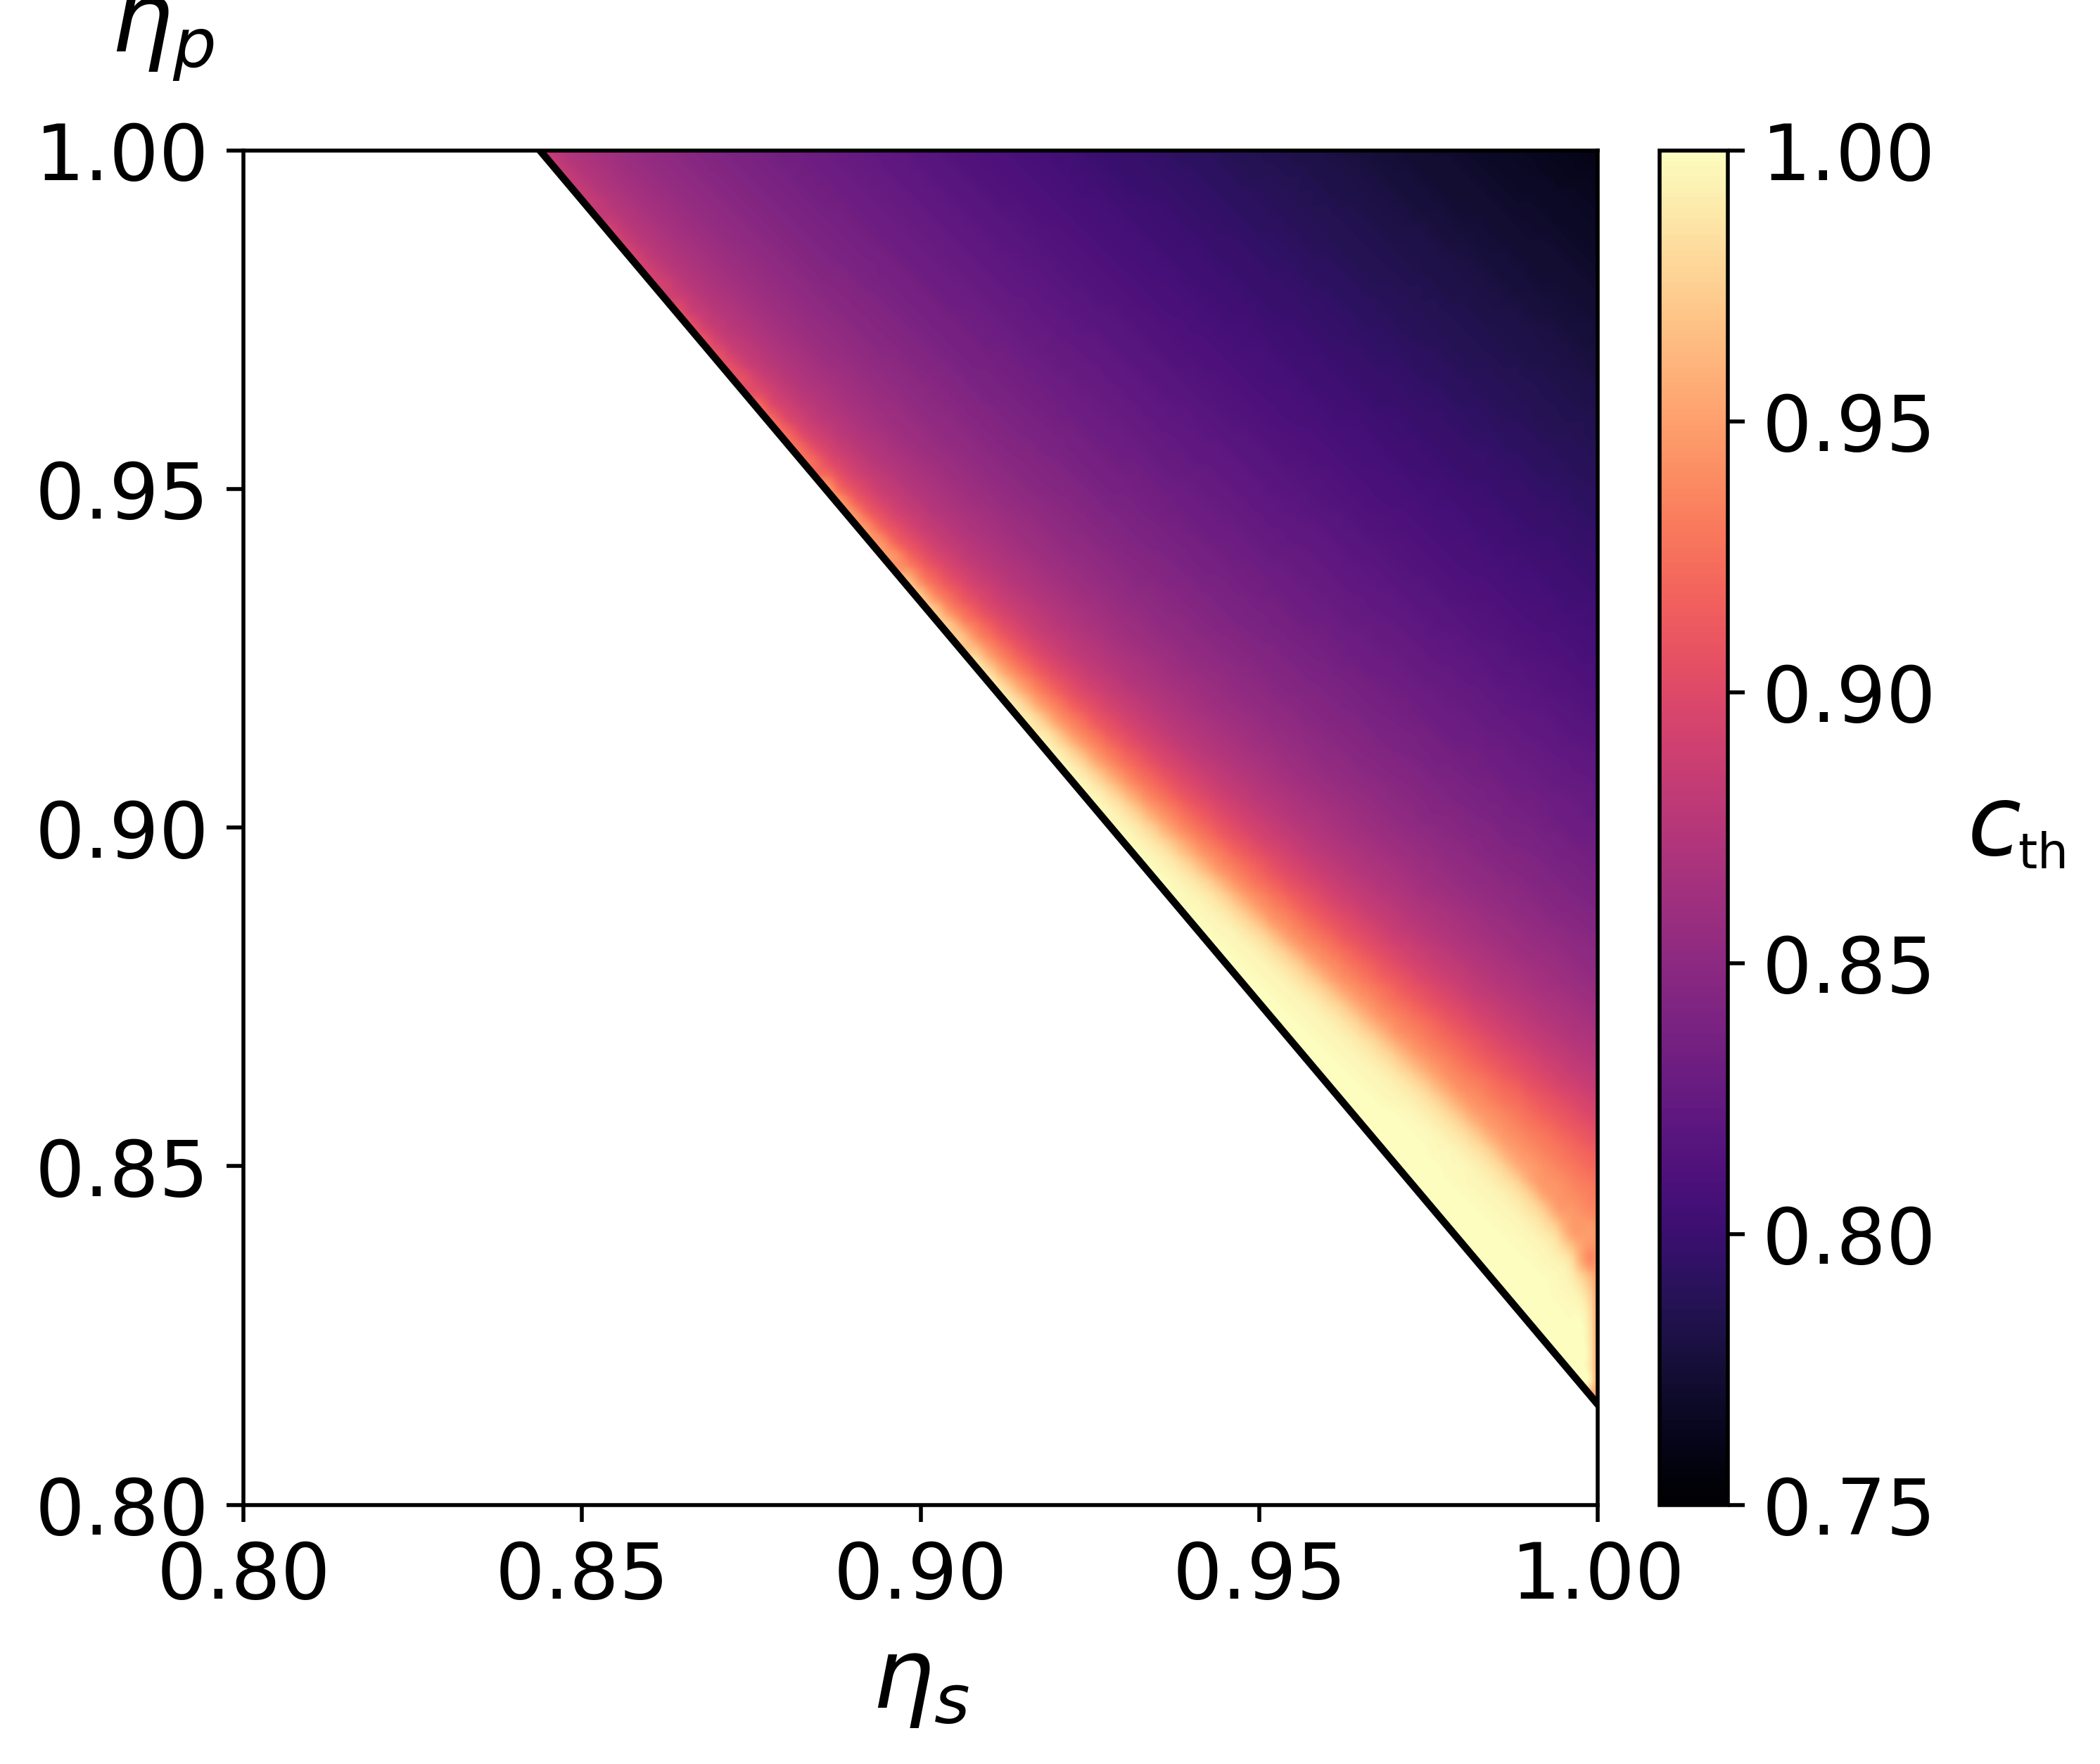

In [5]:
def plot_cth_pmf_heatmap_from_csv(
    pmf_csv="cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline.csv",
    *,
    U=2, V=2,
    out_csv_path=None,
    vmin=0.75,
    vmax=1.00,
    boundary_line=True,
    curve_points=2000,
    fig_dpi=500,
    label_fs=20,
    tick_fs=16,
    cmap_name="magma"
):
    """
    Plot c_th^PMF heatmap from the tidy 1001x1001 spline CSV
    using the same house style as the other heatmaps.
    """

    if (U, V) != (2, 2):
        raise ValueError("This plotting version is currently set up for U=V=2 boundary styling.")

    # -------------------------
    # Load grid from tidy CSV
    # -------------------------
    eta_s_vals, eta_p_vals, G = load_tidy_grid(pmf_csv, cols=("c_th_pmf",))
    c_pmf = np.array(G["c_th_pmf"], dtype=np.float64)

    eta_s_grid, eta_p_grid = np.meshgrid(eta_s_vals, eta_p_vals, indexing="xy")

    # Analytic mask for (2,2)
    eta_p_th_1d = 2.0 - (32.0 / 27.0) * eta_s_vals
    mask = eta_p_grid >= eta_p_th_1d[None, :]

    # Physical clipping + mask
    c_pmf = np.clip(c_pmf, 0.0, 1.0)
    c_pmf = np.where(mask, c_pmf, np.nan)

    Zm = np.ma.masked_invalid(c_pmf)

    # Optional tidy output
    if out_csv_path is not None:
        out_df = pd.DataFrame({
            "eta_s": eta_s_grid.ravel(order="C"),
            "eta_p": eta_p_grid.ravel(order="C"),
            "c_th_pmf": c_pmf.ravel(order="C"),
            "percolating_mask": mask.astype(int).ravel(order="C"),
        })
        out_df.to_csv(out_csv_path, index=False)
        print("Wrote:", out_csv_path)

    # -------------------------
    # Plot
    # -------------------------
    fig, ax = plt.subplots(figsize=(8, 5), dpi=500)

    cmap = plt.get_cmap(cmap_name).copy()
    cmap.set_bad(color="white")

    pc = ax.pcolormesh(
        eta_s_vals, eta_p_vals, Zm,
        shading="nearest",
        cmap=cmap,
        vmin=vmin, vmax=vmax
    )

    if boundary_line:
        xs = np.linspace(float(eta_s_vals.min()), float(eta_s_vals.max()), int(curve_points))
        yp_th = 2.0 - (32.0 / 27.0) * xs
        ax.plot(xs, yp_th, color="black", linewidth=1.5)

    ax.set_xlim(float(eta_s_vals.min()), float(eta_s_vals.max()))
    ax.set_ylim(float(eta_p_vals.min()), float(eta_p_vals.max()))
    ax.set_aspect("equal", adjustable="box")

    ticks = [0.80, 0.85, 0.90, 0.95, 1.00]
    xt = [t for t in ticks if eta_s_vals.min() - 1e-9 <= t <= eta_s_vals.max() + 1e-9]
    yt = [t for t in ticks if eta_p_vals.min() - 1e-9 <= t <= eta_p_vals.max() + 1e-9]

    ax.set_xticks(xt)
    ax.set_yticks(yt)
    ax.set_xticklabels([f"{t:.2f}" for t in xt])
    ax.set_yticklabels([f"{t:.2f}" for t in yt])

    ax.set_xlabel(r"$\eta_s$", fontsize=label_fs)
    ax.set_ylabel(r"$\eta_p$", rotation=0, labelpad=18, fontsize=label_fs)
    ax.yaxis.set_label_coords(-0.06, 1.05)
    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    # leave room on the right for manual horizontal cbar label
    fig.subplots_adjust(right=0.86)

    cbar = fig.colorbar(pc, ax=ax, pad=0.03)
    cbar.ax.tick_params(labelsize=tick_fs)

    # draw once so cbar position is known
    fig.canvas.draw()
    bbox = cbar.ax.get_position()

    # manual right-side horizontal label: c_th
    x0 = bbox.x1 + 0.085
    y0 = 0.5 * (bbox.y0 + bbox.y1)

    fig.text(
        x0, y0,
        r"$c$",
        fontsize=label_fs,
        ha="left",
        va="center"
    )

    fig.text(
        x0 + 0.018, y0 - 0.015,
        r"$\rm th$",
        fontsize=0.50 * label_fs,
        ha="left",
        va="center"
    )

    plt.show()

    return {
        "eta_s_vals": eta_s_vals,
        "eta_p_vals": eta_p_vals,
        "c_th_pmf_grid": c_pmf,
        "mask": mask,
    }


# Example call
out = plot_cth_pmf_heatmap_from_csv()

## Fixed point concurrence threshold difference from actual

/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1899520072.py:77: RuntimeWarning: invalid value encountered in divide
  w_p = np.where(valid, w_p / w_sum, 0.0)
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1899520072.py:78: RuntimeWarning: invalid value encountered in divide
  w_u = np.where(valid, w_u / w_sum, 0.0)
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1899520072.py:79: RuntimeWarning: invalid value encountered in divide
  w_v = np.where(valid, w_v / w_sum, 0.0)


Wrote: cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline__diff_vs_mf_corrected_abs.csv


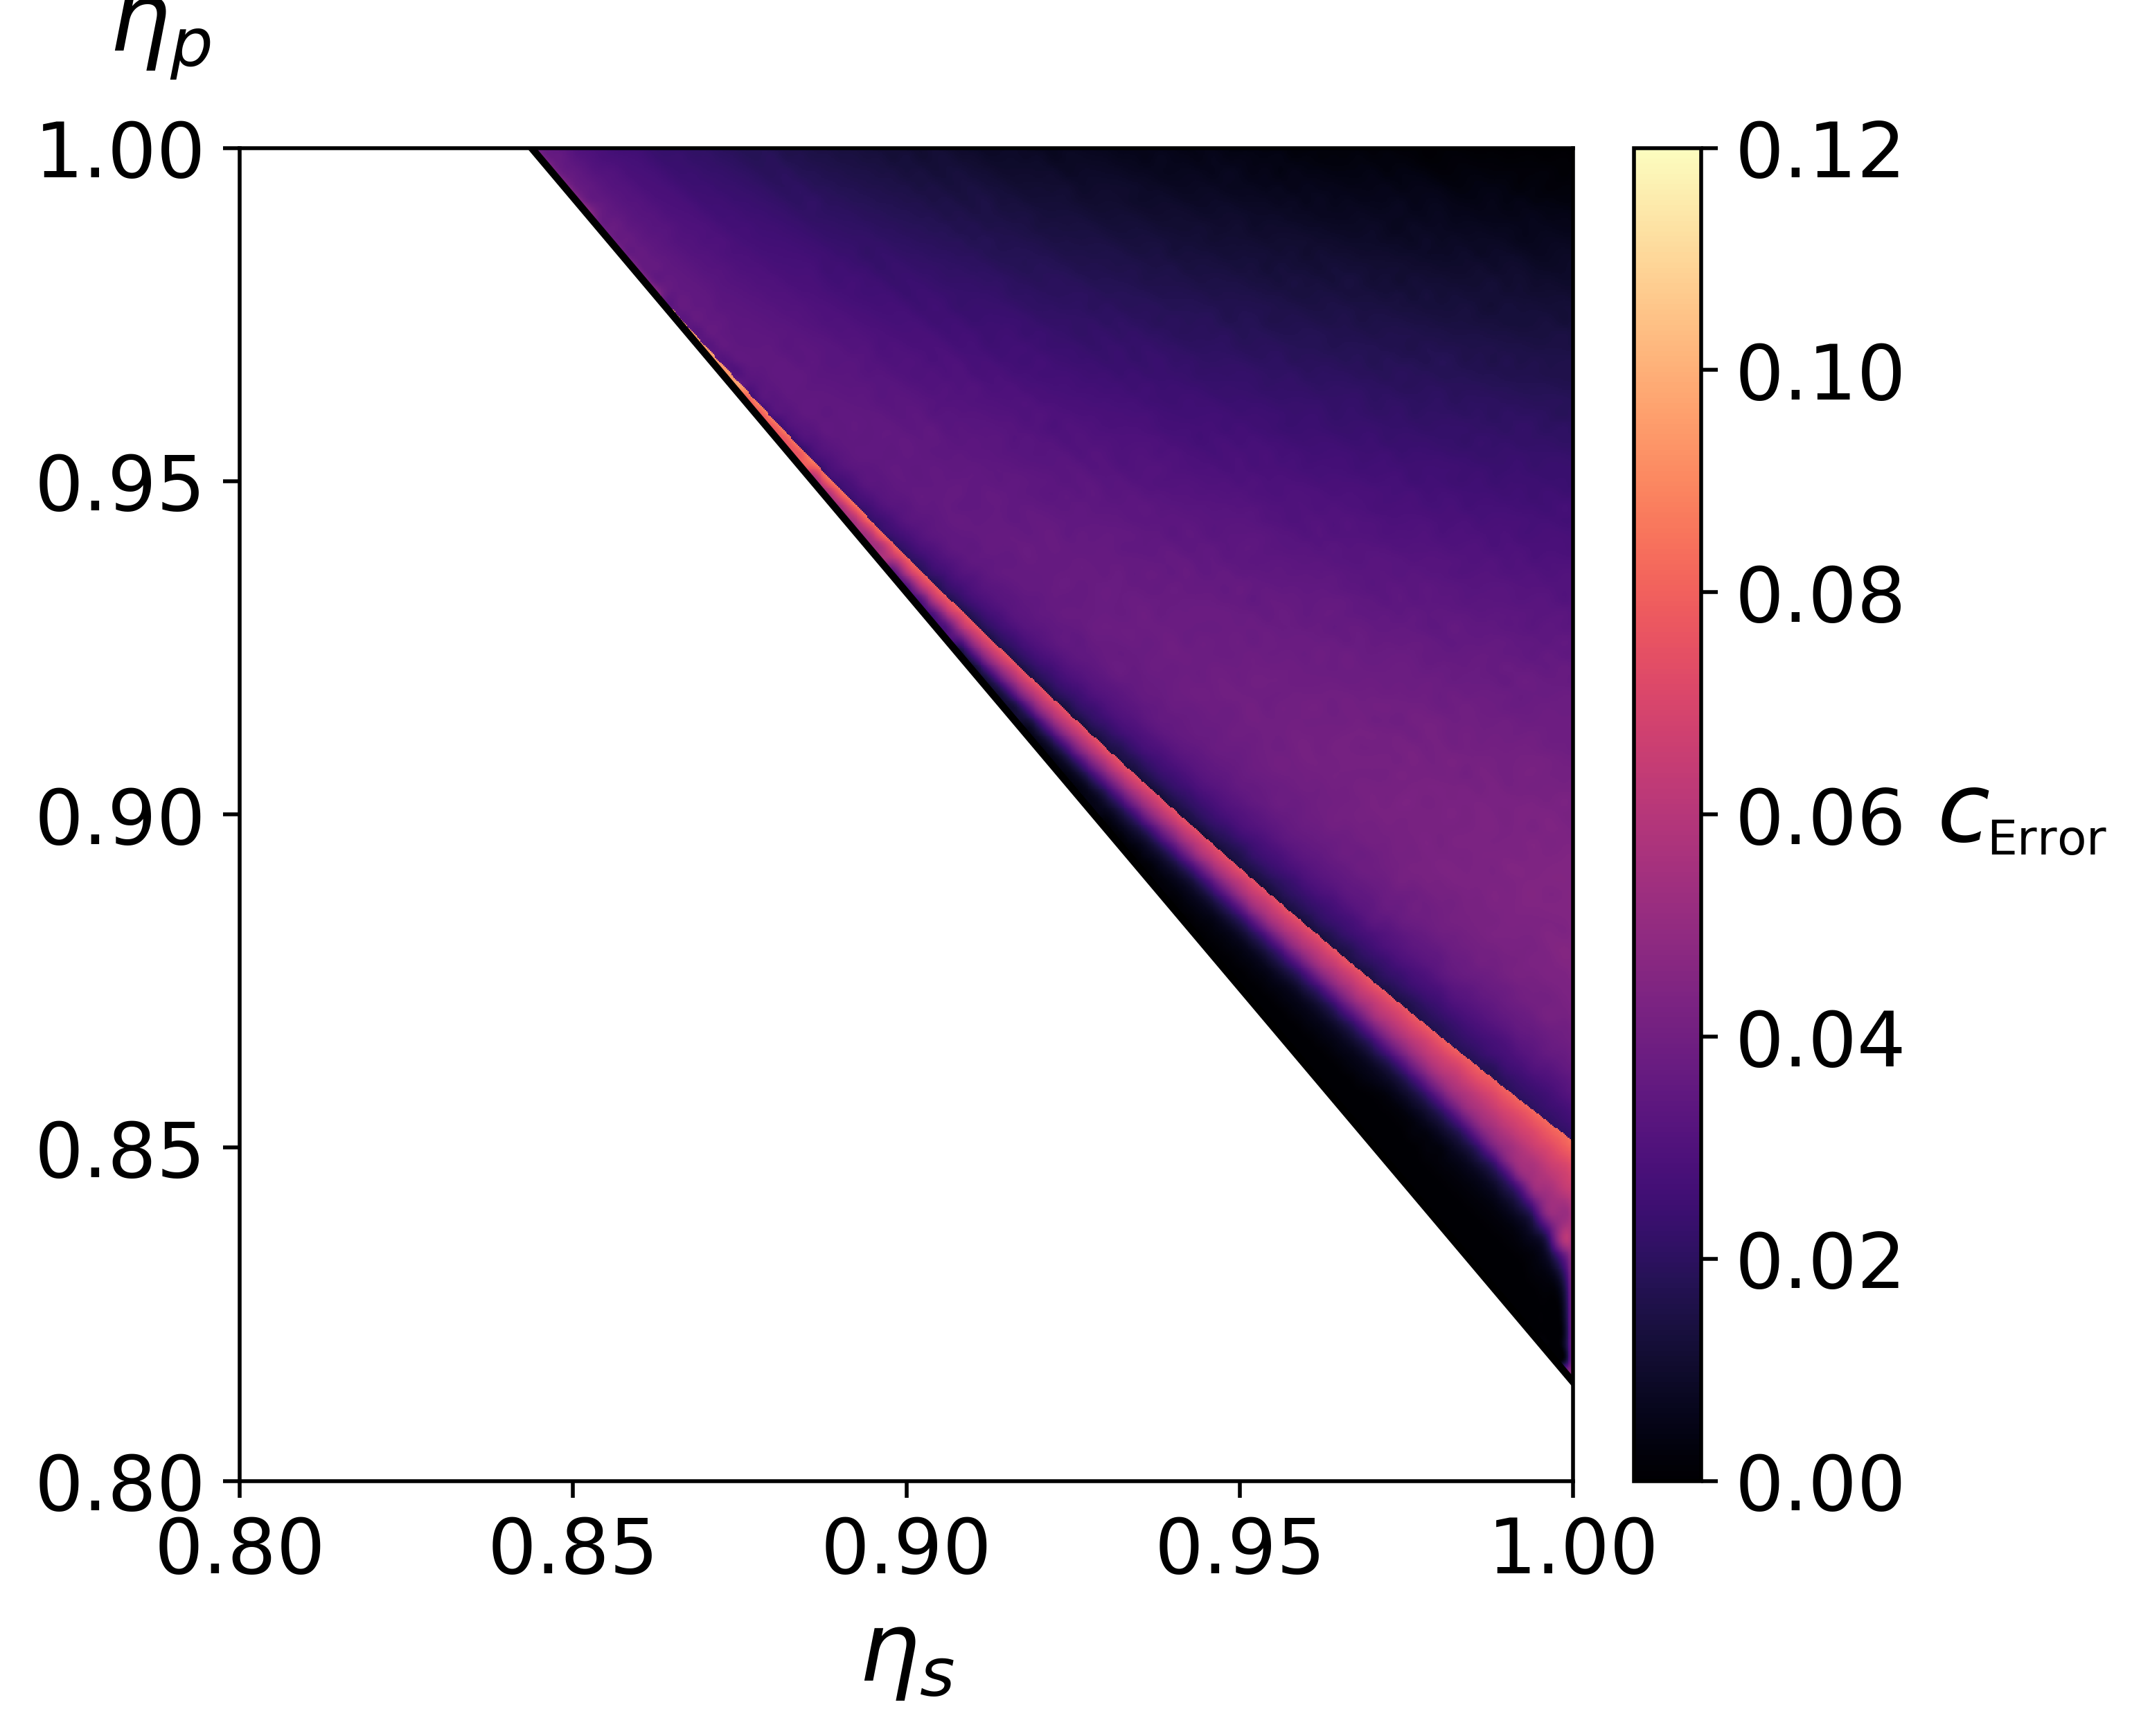

Saved (abs): cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline__diff_vs_mf_corrected_abs.csv


/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1899520072.py:77: RuntimeWarning: invalid value encountered in divide
  w_p = np.where(valid, w_p / w_sum, 0.0)
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1899520072.py:78: RuntimeWarning: invalid value encountered in divide
  w_u = np.where(valid, w_u / w_sum, 0.0)
/var/folders/93/64z8dxyx4bj_xc7q5ldfm7q80000gn/T/ipykernel_94597/1899520072.py:79: RuntimeWarning: invalid value encountered in divide
  w_v = np.where(valid, w_v / w_sum, 0.0)


Wrote: cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline__diff_vs_mf_corrected_pct.csv


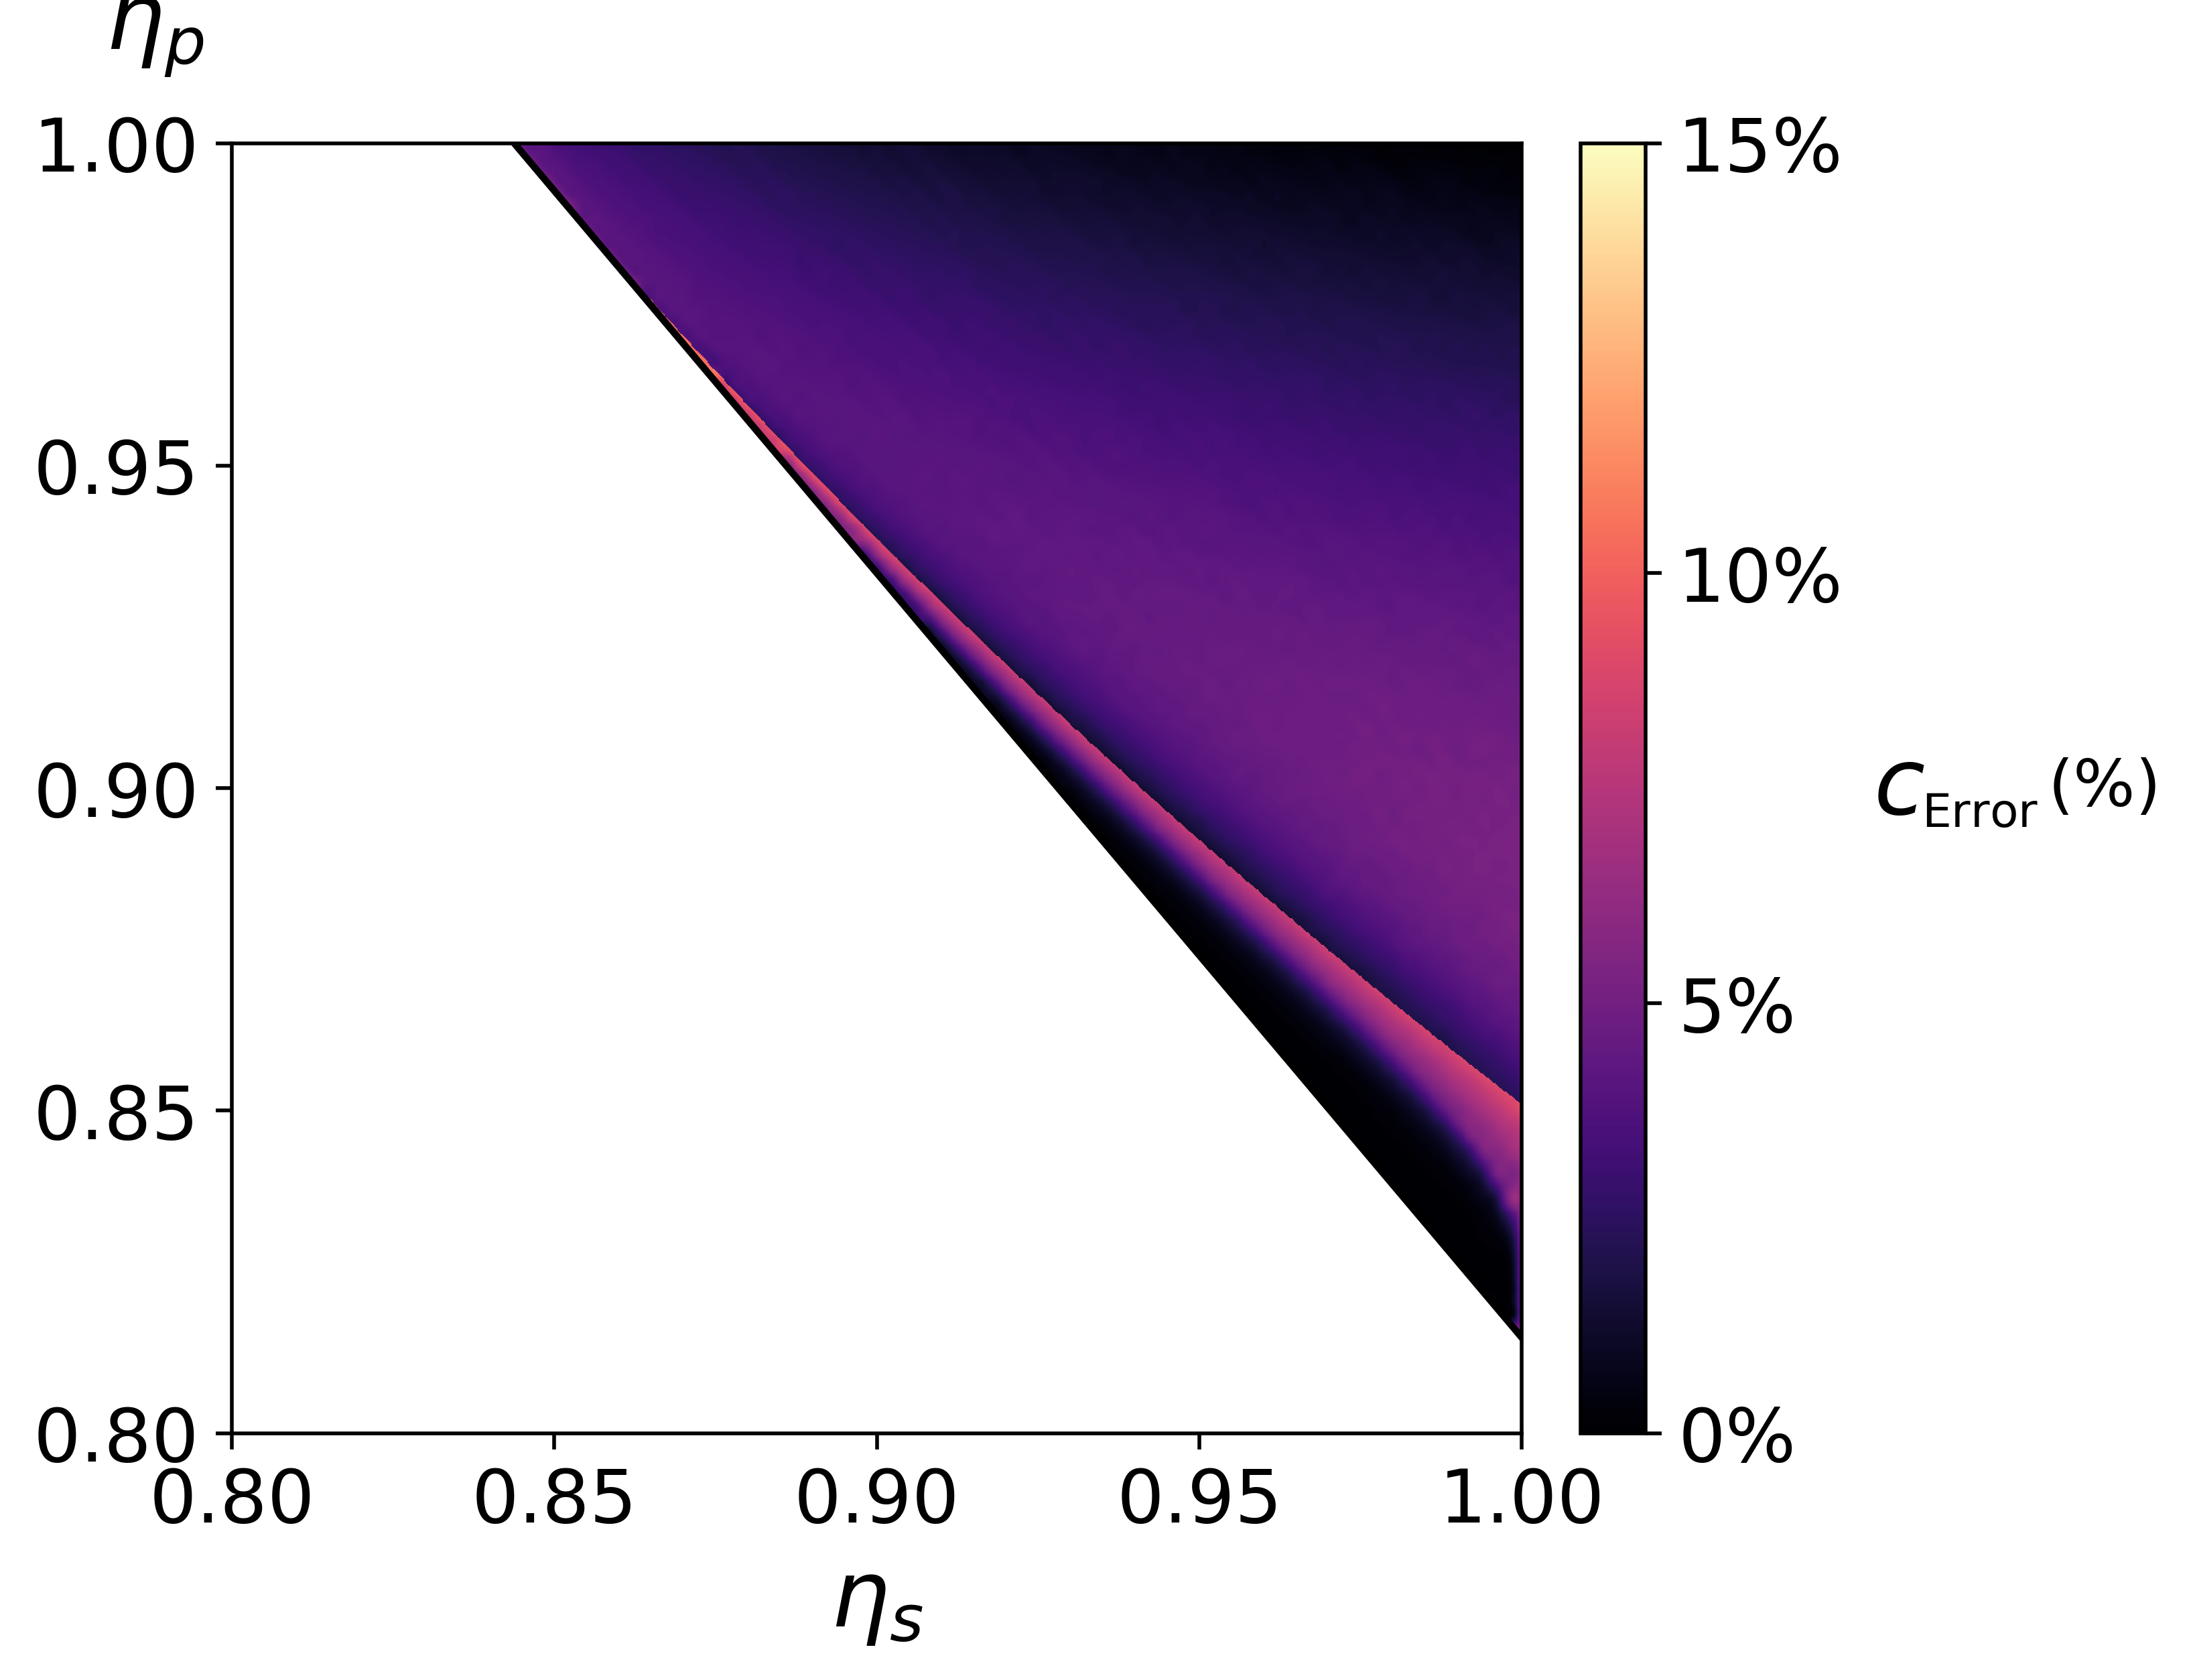

Saved (pct): cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline__diff_vs_mf_corrected_pct.csv


In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter


# =========================================================
# 0) Exact operational q_inf (recompute on plotting grid)
# =========================================================
def q_map(q, U, V, eta_s, eta_p):
    q = np.clip(q, 0.0, 1.0)
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    return np.clip(qU + qV - (2.0 - eta_p) * qU * qV, 0.0, 1.0)


def q_inf_grid(U, V, eta_s_grid, eta_p_grid, tol=1e-13, max_iter=20000):
    q = np.ones_like(eta_s_grid, dtype=np.float64)
    for _ in range(int(max_iter)):
        qn = q_map(q, U, V, eta_s_grid, eta_p_grid)
        if np.max(np.abs(qn - q)) < tol:
            return qn
        q = qn
    return q


# =========================================================
# 1) Mean-field building blocks (stable version)
# =========================================================
def para_conpt_np(cu, cv):
    """
    Parallel operation concurrence (ConPT), vectorized.
    """
    cu = np.clip(cu, 0.0, 1.0)
    cv = np.clip(cv, 0.0, 1.0)

    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - cu * cu)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - cv * cv)))
    M = np.maximum(0.5, mu * mv)

    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))


def c_th_mf_from_qinf_grid_stable(
    eta_s_grid, eta_p_grid, qinf_grid, U, V,
    max_iter=80,
    y_lo=1e-12,
    y_probe=1.0 - 1e-6,   # <- stable probe, avoids fake sign flips near y=1
    qinf_eps=1e-15,
    f_tol=1e-14
):
    """
    Compute c_th^MF using the y fixed-point equation with weights built from q_inf.
    Uses a numerically stable 'probe' criterion at y_probe<1 to decide whether an interior
    root exists; if not, returns c_th^MF = 1.
    """
    eta_s_grid = np.asarray(eta_s_grid, dtype=float)
    eta_p_grid = np.asarray(eta_p_grid, dtype=float)
    qinf_grid  = np.asarray(qinf_grid,  dtype=float)

    c_th_mf = np.full_like(qinf_grid, np.nan, dtype=float)

    active = qinf_grid > qinf_eps
    denom = np.where(active, qinf_grid, 1.0)

    q_u = (eta_s_grid ** (U - 1)) * (qinf_grid ** U)
    q_v = (eta_s_grid ** (V - 1)) * (qinf_grid ** V)

    w_p = eta_p_grid * q_u * q_v / denom
    w_u = q_u * (1.0 - q_v) / denom
    w_v = q_v * (1.0 - q_u) / denom

    # Renormalize weights (important near boundary / numerical drift)
    w_sum = w_p + w_u + w_v
    valid = w_sum > 0
    w_p = np.where(valid, w_p / w_sum, 0.0)
    w_u = np.where(valid, w_u / w_sum, 0.0)
    w_v = np.where(valid, w_v / w_sum, 0.0)

    def f_of_y(y, wp, wu, wv):
        yU = y ** U
        yV = y ** V
        Fy = wp * para_conpt_np(yU, yV) + wu * yU + wv * yV
        return Fy - y

    f_probe = f_of_y(y_probe, w_p, w_u, w_v)

    no_interior = active & (f_probe <= f_tol)
    c_th_mf[no_interior] = 1.0

    do_bisect = active & (f_probe > f_tol)
    if np.any(do_bisect):
        wp = w_p[do_bisect]
        wu = w_u[do_bisect]
        wv = w_v[do_bisect]

        lo = np.full(wp.shape, y_lo, dtype=float)
        hi = np.full(wp.shape, y_probe, dtype=float)

        for _ in range(int(max_iter)):
            mid = 0.5 * (lo + hi)
            f_mid = f_of_y(mid, wp, wu, wv)
            pos = f_mid > 0
            hi[pos] = mid[pos]
            lo[~pos] = mid[~pos]

        c_th_mf[do_bisect] = 0.5 * (lo + hi)

    return c_th_mf


# =========================================================
# 2) Load PMF grid (only need c_th_pmf + eta axes)
# =========================================================
def load_tidy_grid(csv_path, cols=("c_th_pmf",)):
    """
    Reads tidy CSV with columns eta_s, eta_p, and requested cols.
    Returns eta_s_vals, eta_p_vals, grids (eta_p rows, eta_s cols).
    """
    df = pd.read_csv(csv_path)

    if "eta_s" not in df.columns or "eta_p" not in df.columns:
        raise ValueError("CSV must contain eta_s and eta_p columns.")

    eta_s_vals = np.sort(df["eta_s"].unique())
    eta_p_vals = np.sort(df["eta_p"].unique())
    ns = len(eta_s_vals)
    np_ = len(eta_p_vals)

    if len(df) != ns * np_:
        raise ValueError(
            f"CSV does not look like a full grid: rows={len(df)} "
            f"but unique eta_s*eta_p={ns*np_}."
        )

    s_codes = pd.Categorical(df["eta_s"], categories=eta_s_vals, ordered=True).codes
    p_codes = pd.Categorical(df["eta_p"], categories=eta_p_vals, ordered=True).codes

    grids = {}
    for c in cols:
        if c not in df.columns:
            raise ValueError(f"CSV missing required column: {c}")
        arr = np.full((np_, ns), np.nan, dtype=float)
        arr[p_codes, s_codes] = df[c].to_numpy(dtype=float)
        grids[c] = arr

    return eta_s_vals, eta_p_vals, grids


# =========================================================
# 3) Main corrected difference heatmap
# =========================================================
def plot_cth_pmf_vs_mf_difference_corrected(
    pmf_1001_csv,
    U=2, V=2,
    mode="abs",               # "abs" or "pct"
    pct_denominator="pmf",    # "pmf" or "mf"
    out_csv_path=None,
    vmin=None, vmax=None,
    boundary_line=True,
    curve_points=2000,
    fig_dpi=500,
    label_fs=20,
    tick_fs=16,
    q_tol=1e-13,
    q_max_iter=20000,
    mf_bisect_iter=100
):
    """
    Produces a clean heatmap of c_th^Error = |c_th^PMF - c_th^MF|
    (or percent error), with:
      - exact q_inf recomputed on the grid,
      - stable MF threshold computation,
      - pixel-perfect analytic mask for (2,2),
      - clean percent colorbar formatting.
    Saves a tidy CSV including c_th_mf and error metrics.
    """

    if (U, V) != (2, 2):
        raise ValueError("This corrected pixel-perfect version is hard-coded for U=V=2.")

    # Load PMF threshold grid
    eta_s_vals, eta_p_vals, G = load_tidy_grid(pmf_1001_csv, cols=("c_th_pmf",))
    c_pmf = G["c_th_pmf"]

    # Build coordinate grids
    eta_s_grid, eta_p_grid = np.meshgrid(eta_s_vals, eta_p_vals, indexing="xy")

    # Exact q_inf on this exact plotting grid
    qinf = q_inf_grid(U, V, eta_s_grid, eta_p_grid, tol=q_tol, max_iter=q_max_iter)

    # Pixel-perfect analytic mask
    eta_p_th_1d = 2.0 - (32.0 / 27.0) * eta_s_vals
    mask = (eta_p_grid >= eta_p_th_1d[None, :])

    # Compute MF threshold robustly
    c_mf = c_th_mf_from_qinf_grid_stable(
        eta_s_grid, eta_p_grid, qinf, U=U, V=V, max_iter=mf_bisect_iter
    )
    c_mf = np.clip(c_mf, 0.0, 1.0)

    # Clip PMF thresholds to physical range too
    c_pmf = np.clip(c_pmf, 0.0, 1.0)

    # Apply analytic mask to both
    c_pmf = np.where(mask, c_pmf, np.nan)
    c_mf  = np.where(mask, c_mf,  np.nan)

    # Errors
    abs_diff = np.abs(c_pmf - c_mf)

    mode = mode.lower().strip()
    pct_denominator = pct_denominator.lower().strip()

    if mode == "pct":
        if pct_denominator == "mf":
            denom = np.maximum(c_mf, 1e-15)
        else:
            denom = np.maximum(c_pmf, 1e-15)

        Z = 100.0 * abs_diff / denom
        cbar_label = r"$c$"
        cbar_sub_1 = r"$\rm Error$"
        cbar_sup = r"$\%$"
    else:
        Z = abs_diff
        cbar_label = r"$c$"
        cbar_sub_1 = r"$\rm Error$"
        cbar_sup = None

    Zm = np.ma.masked_invalid(Z)

    # Save output CSV
    if out_csv_path is None:
        root, ext = os.path.splitext(pmf_1001_csv)
        suffix = "pct" if mode == "pct" else "abs"
        out_csv_path = f"{root}__diff_vs_mf_corrected_{suffix}.csv"

    out_df = pd.DataFrame({
        "eta_s": eta_s_grid.ravel(order="C"),
        "eta_p": eta_p_grid.ravel(order="C"),
        "c_th_pmf": c_pmf.ravel(order="C"),
        "c_th_mf":  c_mf.ravel(order="C"),
        "abs_diff": abs_diff.ravel(order="C"),
        "pct_diff_over_pmf": (100.0 * abs_diff / np.maximum(c_pmf, 1e-15)).ravel(order="C"),
        "pct_diff_over_mf":  (100.0 * abs_diff / np.maximum(c_mf, 1e-15)).ravel(order="C"),
        "q_inf": qinf.ravel(order="C"),
        "percolating_mask": mask.astype(int).ravel(order="C"),
    })
    out_df.to_csv(out_csv_path, index=False)
    print("Wrote:", out_csv_path)

    # ---- Plot ----
    fig, ax = plt.subplots(figsize=(8, 5), dpi=500)

    cmap = plt.get_cmap("magma").copy()
    cmap.set_bad(color="white")

    if vmin is None:
        vmin = 0.0

    if vmax is None:
        if mode == "pct":
            raw = np.nanmax(Z)
            if raw <= 10:
                vmax = np.ceil(raw / 2.0) * 2.0
            else:
                vmax = np.ceil(raw / 5.0) * 5.0
        else:
            vmax = np.ceil(np.nanmax(Z) / 0.02) * 0.02

    pc = ax.pcolormesh(
        eta_s_vals, eta_p_vals, Zm,
        shading="nearest",
        cmap=cmap,
        vmin=vmin, vmax=vmax
    )

    if boundary_line:
        xs = np.linspace(float(eta_s_vals.min()), float(eta_s_vals.max()), int(curve_points))
        yp_th = 2.0 - (32.0 / 27.0) * xs
        ax.plot(xs, yp_th, color="black", linewidth=1.5)

    ax.set_xlim(float(eta_s_vals.min()), float(eta_s_vals.max()))
    ax.set_ylim(float(eta_p_vals.min()), float(eta_p_vals.max()))
    ax.set_aspect("equal", adjustable="box")

    ticks = [0.80, 0.85, 0.90, 0.95, 1.00]
    xt = [t for t in ticks if eta_s_vals.min() - 1e-9 <= t <= eta_s_vals.max() + 1e-9]
    yt = [t for t in ticks if eta_p_vals.min() - 1e-9 <= t <= eta_p_vals.max() + 1e-9]

    ax.set_xticks(xt)
    ax.set_yticks(yt)
    ax.set_xticklabels([f"{t:.2f}" for t in xt])
    ax.set_yticklabels([f"{t:.2f}" for t in yt])

    ax.set_xlabel(r"$\eta_s$", fontsize=label_fs)
    ax.set_ylabel(r"$\eta_p$", rotation=0, labelpad=18, fontsize=label_fs)
    ax.yaxis.set_label_coords(-0.06, 1.05)
    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    # leave enough room on the right for manual horizontal colorbar label
    fig.subplots_adjust(right=0.86)

    cbar = fig.colorbar(pc, ax=ax, pad=0.03)
    cbar.ax.tick_params(labelsize=tick_fs)

    if mode == "pct":
        # choose a sensible percent tick spacing
        if vmax <= 5:
            cbar_ticks = np.arange(vmin, vmax + 1e-12, 1.0)
        elif vmax <= 10:
            cbar_ticks = np.arange(vmin, vmax + 1e-12, 2.0)
        elif vmax <= 20:
            cbar_ticks = np.arange(vmin, vmax + 1e-12, 5.0)
        else:
            step = np.ceil(vmax / 5.0)
            cbar_ticks = np.arange(vmin, vmax + 1e-12, step)

        cbar.set_ticks(cbar_ticks)
        cbar.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{x:.0f}%"))
    else:
        cbar_ticks = np.arange(vmin, vmax + 1e-12, 0.02)
        cbar.set_ticks(cbar_ticks)

    # draw once so colorbar position is known
    fig.canvas.draw()
    bbox = cbar.ax.get_position()

    # manual right-side horizontal label
    x0 = bbox.x1 + 0.085
    y0 = 0.5 * (bbox.y0 + bbox.y1)

    # main c
    fig.text(
        x0, y0,
        cbar_label,
        fontsize=label_fs,
        ha="left",
        va="center"
    )

    # subscript "Error"
    fig.text(
        x0 + 0.018, y0 - 0.015,
        cbar_sub_1,
        fontsize=0.5 * label_fs,
        ha="left",
        va="center"
    )


    # optional superscript percent for pct mode
    if cbar_sup is not None:
        fig.text(
            x0 + 0.065, y0,
            r"$(\%)$",
            fontsize=0.7 * label_fs,
            ha="left",
            va="center"
        )

    plt.show()

    return {
        "out_csv": out_csv_path,
        "eta_s_vals": eta_s_vals,
        "eta_p_vals": eta_p_vals,
        "q_inf_grid": qinf,
        "c_th_pmf_grid": c_pmf,
        "c_th_mf_grid": c_mf,
        "abs_diff_grid": abs_diff,
        "plot_grid": Z,
    }


# -------------------
# 4) Example usage
# -------------------
pmf_csv_1001 = "cth_pmf_U2V2__20260219_125302_tidy_1001x1001_spline.csv"

# Absolute error heatmap
out_abs = plot_cth_pmf_vs_mf_difference_corrected(
    pmf_1001_csv=pmf_csv_1001,
    U=2, V=2,
    mode="abs",
    vmin=0.0,
    vmax=None,   # or set e.g. 0.11 for consistent scale
    mf_bisect_iter=120
)

print("Saved (abs):", out_abs["out_csv"])

# Percent error heatmap (relative to PMF)
out_pct = plot_cth_pmf_vs_mf_difference_corrected(
    pmf_1001_csv=pmf_csv_1001,
    U=2, V=2,
    mode="pct",
    pct_denominator="pmf",
    vmin=0.0,
    vmax=None,   # or set e.g. 15
    mf_bisect_iter=120
)

print("Saved (pct):", out_pct["out_csv"])

## Convergence *time* plots

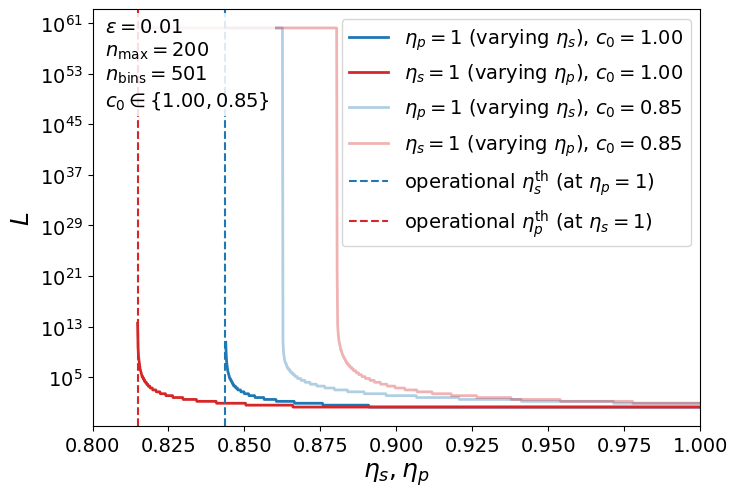

In [109]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# Self-contained convergence plot (NO dependency on your globals)
# - Namespaced "conv_" functions to avoid collisions
# - Fast-bin RG step iterated incrementally in n
# - Masks non-percolating region so curves don't exist below threshold
# ============================================================

# ---------- (A) Mean-field q_inf ----------
def conv_q_map(q, U, V, eta_s, eta_p):
    q = float(np.clip(q, 0.0, 1.0))
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    out = qU + qV - (2.0 - eta_p) * qU * qV
    return float(np.clip(out, 0.0, 1.0))

def conv_q_inf(U, V, eta_s, eta_p, tol=1e-13, max_iter=200000):
    q = 1.0
    for _ in range(int(max_iter)):
        qn = conv_q_map(q, U, V, float(eta_s), float(eta_p))
        if abs(qn - q) < tol:
            return qn
        q = qn
    return q

def conv_find_threshold_on_slice(U, V, which="eta_s", q_tol=1e-12, bisect_iter=80):
    # Finds minimal eta such that q_inf(eta) > q_tol (slice with the other eta fixed to 1)
    lo, hi = 0.0, 1.0
    if which == "eta_s":
        if conv_q_inf(U, V, hi, 1.0) <= q_tol:
            return np.nan
        for _ in range(int(bisect_iter)):
            mid = 0.5 * (lo + hi)
            if conv_q_inf(U, V, mid, 1.0) > q_tol:
                hi = mid
            else:
                lo = mid
        return hi
    elif which == "eta_p":
        if conv_q_inf(U, V, 1.0, hi) <= q_tol:
            return np.nan
        for _ in range(int(bisect_iter)):
            mid = 0.5 * (lo + hi)
            if conv_q_inf(U, V, 1.0, mid) > q_tol:
                hi = mid
            else:
                lo = mid
        return hi
    else:
        raise ValueError("which must be 'eta_s' or 'eta_p'")

# ---------- (B) Fast-bin ConPT RG (sparse bins + bincount) ----------
def conv_para_conpt_vec(a, b):
    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - a*a)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - b*b)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))

def conv_round_to_idx(x, n_bins):
    n1 = n_bins - 1
    return np.clip((x * n1 + 0.5).astype(np.int64), 0, n1).astype(np.int32)

def conv_para_idx_table(n_bins):
    x = np.linspace(0.0, 1.0, int(n_bins), dtype=np.float64)
    A = x[:, None]
    B = x[None, :]
    P = conv_para_conpt_vec(A, B)
    return conv_round_to_idx(P, n_bins)

def conv_prune_sparse(idxs, ps, p_min=0.0, max_states=None):
    if idxs.size == 0:
        return idxs, ps
    if p_min > 0.0:
        m = ps >= float(p_min)
        idxs, ps = idxs[m], ps[m]
    if max_states is not None and idxs.size > int(max_states):
        k = int(max_states)
        sel = np.argpartition(ps, -k)[-k:]
        idxs, ps = idxs[sel], ps[sel]
    order = np.argsort(idxs)
    return idxs[order], ps[order]

def conv_normalize_mass(ps, target_mass):
    s = float(ps.sum())
    if s <= 0.0:
        return ps
    return ps * (float(target_mass) / s)

def conv_mul_convolve_sparse(idxA, pA, idxB, pB, n_bins):
    # product bins: idx = round((i/(n1))*(j/(n1))*n1) = round(i*j/n1)
    n1 = n_bins - 1
    ij = (idxA[:, None].astype(np.int64) * idxB[None, :].astype(np.int64))
    out_idx = ((2 * ij + n1) // (2 * n1)).astype(np.int32)

    w = (pA[:, None] * pB[None, :]).ravel()
    out = np.bincount(out_idx.ravel(), weights=w, minlength=n_bins).astype(np.float64)

    nz = out > 0
    return np.nonzero(nz)[0].astype(np.int32), out[nz]

def conv_para_convolve_sparse(idxA, pA, idxB, pB, para_tab, n_bins):
    out_idx = para_tab[np.ix_(idxA, idxB)]
    w = (pA[:, None] * pB[None, :]).ravel()
    out = np.bincount(out_idx.ravel(), weights=w, minlength=n_bins).astype(np.float64)

    nz = out > 0
    return np.nonzero(nz)[0].astype(np.int32), out[nz]

def conv_fold_zero_bin(idxs, ps, p0):
    if idxs.size == 0:
        return idxs, ps, float(p0)
    m0 = (idxs == 0)
    if np.any(m0):
        p0 = float(p0) + float(ps[m0].sum())
        idxs, ps = idxs[~m0], ps[~m0]
    return idxs, ps, float(p0)

def conv_series_chain(idx, ps, p0, L, eta_s, n_bins, p_min=0.0, max_states=None):
    L = int(L)
    if L == 1:
        return idx, ps, float(p0)

    q = 1.0 - float(p0)
    q_chain = (q ** L) * (float(eta_s) ** (L - 1))
    p0_chain = 1.0 - q_chain

    # delta support shortcut
    if idx.size == 1:
        n1 = n_bins - 1
        x = idx[0] / n1
        xL = x ** L
        idx_out = np.array([int(xL * n1 + 0.5)], dtype=np.int32)
        ps_out = np.array([q_chain], dtype=np.float64)
        # fold any accidental 0 bin
        idx_out, ps_out, p0_chain = conv_fold_zero_bin(idx_out, ps_out, p0_chain)
        return idx_out, ps_out, p0_chain

    cur_idx, cur_p = idx, ps
    for _ in range(L - 1):
        cur_idx, cur_p = conv_mul_convolve_sparse(cur_idx, cur_p, idx, ps, n_bins)
        cur_idx, cur_p = conv_prune_sparse(cur_idx, cur_p, p_min=p_min, max_states=max_states)

    cur_p = conv_normalize_mass(cur_p, q_chain)
    cur_idx, cur_p, p0_chain = conv_fold_zero_bin(cur_idx, cur_p, p0_chain)
    return cur_idx, cur_p, p0_chain

def conv_parallel_combine(idxU, pU, p0U, idxV, pV, p0V, eta_p, para_tab, n_bins, p_min=0.0, max_states=None):
    out_dense = np.zeros(n_bins, dtype=np.float64)

    # one survives (no parallel op)
    if idxU.size:
        out_dense[idxU] += float(p0V) * pU
    if idxV.size:
        out_dense[idxV] += float(p0U) * pV

    qU = 1.0 - float(p0U)
    qV = 1.0 - float(p0V)

    if qU > 0 and qV > 0 and float(eta_p) > 0.0 and idxU.size and idxV.size:
        idxP, pP = conv_para_convolve_sparse(idxU, pU, idxV, pV, para_tab, n_bins)
        pP = conv_normalize_mass(pP, float(eta_p) * (qU * qV))
        out_dense[idxP] += pP

    nz = out_dense > 0
    idx_out = np.nonzero(nz)[0].astype(np.int32)
    p_out = out_dense[nz]

    idx_out, p_out = conv_prune_sparse(idx_out, p_out, p_min=p_min, max_states=max_states)

    # p0 computed from nonzero mass; then fold zero-bin mass into p0
    q_out = float(p_out.sum())
    p0_out = 1.0 - q_out
    idx_out, p_out, p0_out = conv_fold_zero_bin(idx_out, p_out, p0_out)

    return idx_out, p_out, p0_out

def conv_step_uv(idx, ps, p0, U, V, eta_s, eta_p, para_tab, n_bins, p_min=0.0, max_states=None):
    idxU, pU, p0U = conv_series_chain(idx, ps, p0, L=U, eta_s=eta_s, n_bins=n_bins, p_min=p_min, max_states=max_states)
    idxV, pV, p0V = conv_series_chain(idx, ps, p0, L=V, eta_s=eta_s, n_bins=n_bins, p_min=p_min, max_states=max_states)
    return conv_parallel_combine(idxU, pU, p0U, idxV, pV, p0V, eta_p=eta_p, para_tab=para_tab, n_bins=n_bins, p_min=p_min, max_states=max_states)

def conv_mean_from_sparse(idx, ps, n_bins):
    n1 = n_bins - 1
    return float((idx.astype(np.float64) / n1 * ps).sum())

# ---------- (C) Convergence time in n (incremental, early stopping) ----------
def conv_convergence_n_to_qinf(
    *, U, V, c_init, eta_s, eta_p,
    eps=0.01,
    n_max=200,
    n_bins=501,
    q_tol=1e-12,
    qinf_tol=1e-13,
    p_min=1e-12,
    max_states=None
):
    qinf = conv_q_inf(U, V, eta_s, eta_p, tol=qinf_tol)
    if (not np.isfinite(qinf)) or (qinf <= q_tol):
        return np.nan  # non-percolating => no curve below threshold

    target = float(eps) * qinf

    n_bins = int(n_bins)
    para_tab = conv_para_idx_table(n_bins)

    n1 = n_bins - 1
    c0 = float(np.clip(c_init, 0.0, 1.0))
    idx = np.array([int(c0 * n1 + 0.5)], dtype=np.int32)
    ps = np.array([1.0], dtype=np.float64)
    p0 = 0.0

    for n in range(1, int(n_max) + 1):
        idx, ps, p0 = conv_step_uv(
            idx, ps, p0,
            U=int(U), V=int(V),
            eta_s=float(eta_s), eta_p=float(eta_p),
            para_tab=para_tab,
            n_bins=n_bins,
            p_min=float(p_min),
            max_states=max_states
        )
        mu = conv_mean_from_sparse(idx, ps, n_bins)
        if abs(mu - qinf) <= target:
            return int(n)

    return int(n_max)

# ---------- (D) Plot ----------
def plot_convergence_time_two_slices(
    *,
    U=2, V=2,
    eta_min=0.80, eta_max=1.00,
    n_points=1201,         # smoother
    eps=0.01,
    n_max=200,
    n_bins=501,
    c_list=(1.00, 0.85),
    alpha_secondary=0.35,
    p_min=1e-12,
    q_tol=1e-12,
    tick_fs=14,
    label_fs=18,
):
    eta_vals = np.linspace(float(eta_min), float(eta_max), int(n_points), dtype=np.float64)

    # thresholds for dashed lines
    eta_s_th = conv_find_threshold_on_slice(U, V, which="eta_s", q_tol=q_tol)
    eta_p_th = conv_find_threshold_on_slice(U, V, which="eta_p", q_tol=q_tol)

    fig, ax = plt.subplots(figsize=(7.6, 5.2))

    for k, c0 in enumerate(c_list):
        a = 1.0 if k == 0 else float(alpha_secondary)

        # blue: eta_p = 1, varying eta_s (x axis is eta_s values)
        n_blue = np.array([
            conv_convergence_n_to_qinf(
                U=U, V=V, c_init=c0,
                eta_s=float(es), eta_p=1.0,
                eps=eps, n_max=n_max, n_bins=n_bins,
                q_tol=q_tol, p_min=p_min
            )
            for es in eta_vals
        ], dtype=np.float64)

        # red: eta_s = 1, varying eta_p (plotted against same x coordinate eta_vals)
        n_red = np.array([
            conv_convergence_n_to_qinf(
                U=U, V=V, c_init=c0,
                eta_s=1.0, eta_p=float(ep),
                eps=eps, n_max=n_max, n_bins=n_bins,
                q_tol=q_tol, p_min=p_min
            )
            for ep in eta_vals
        ], dtype=np.float64)

        # convert n -> L = U^n
        L_blue = np.where(np.isfinite(n_blue), np.power(float(U), n_blue), np.nan)
        L_red  = np.where(np.isfinite(n_red),  np.power(float(U), n_red),  np.nan)

        ax.plot(eta_vals, L_blue, color="tab:blue", lw=2.0, alpha=a,
                label=rf"$\eta_p=1$ (varying $\eta_s$), $c_0={c0:.2f}$")
        ax.plot(eta_vals, L_red, color="tab:red", lw=2.0, alpha=a,
                label=rf"$\eta_s=1$ (varying $\eta_p$), $c_0={c0:.2f}$")

    # dashed thresholds
    if np.isfinite(eta_s_th):
        ax.axvline(eta_s_th, color="tab:blue", ls="--", lw=1.5,
                   label=rf"operational $\eta_s^{{\rm th}}$ (at $\eta_p=1$)")
    if np.isfinite(eta_p_th):
        ax.axvline(eta_p_th, color="tab:red", ls="--", lw=1.5,
                   label=rf"operational $\eta_p^{{\rm th}}$ (at $\eta_s=1$)")

    ax.set_xlim(float(eta_min), float(eta_max))
    ax.set_yscale("log")

    ax.set_xlabel(r"$\eta_s,\eta_p$", fontsize=label_fs)
    ax.set_ylabel(r"$L$", fontsize=label_fs)
    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    # settings box
    txt = [
        rf"$\epsilon={eps:.3g}$",
        rf"$n_{{\max}}={int(n_max)}$",
        rf"$n_{{\rm bins}}={int(n_bins)}$",
        rf"$c_0 \in \{{{', '.join([f'{c:.2f}' for c in c_list])}\}}$",
    ]
    ax.text(
        0.02, 0.98, "\n".join(txt),
        transform=ax.transAxes, ha="left", va="top",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="none")
    )

    ax.legend(loc="upper right", frameon=True)
    plt.tight_layout()
    plt.show()

    return {"eta_vals": eta_vals, "eta_s_th": eta_s_th, "eta_p_th": eta_p_th}

# ---- Run ----
out_conv = plot_convergence_time_two_slices(
    U=2, V=2,
    eta_min=0.80, eta_max=1.00,
    n_points=1201,
    eps=0.01,
    n_max=200,
    n_bins=501,
    c_list=(1.00, 0.85),
    alpha_secondary=0.35,
    p_min=1e-12,
    q_tol=1e-12
)


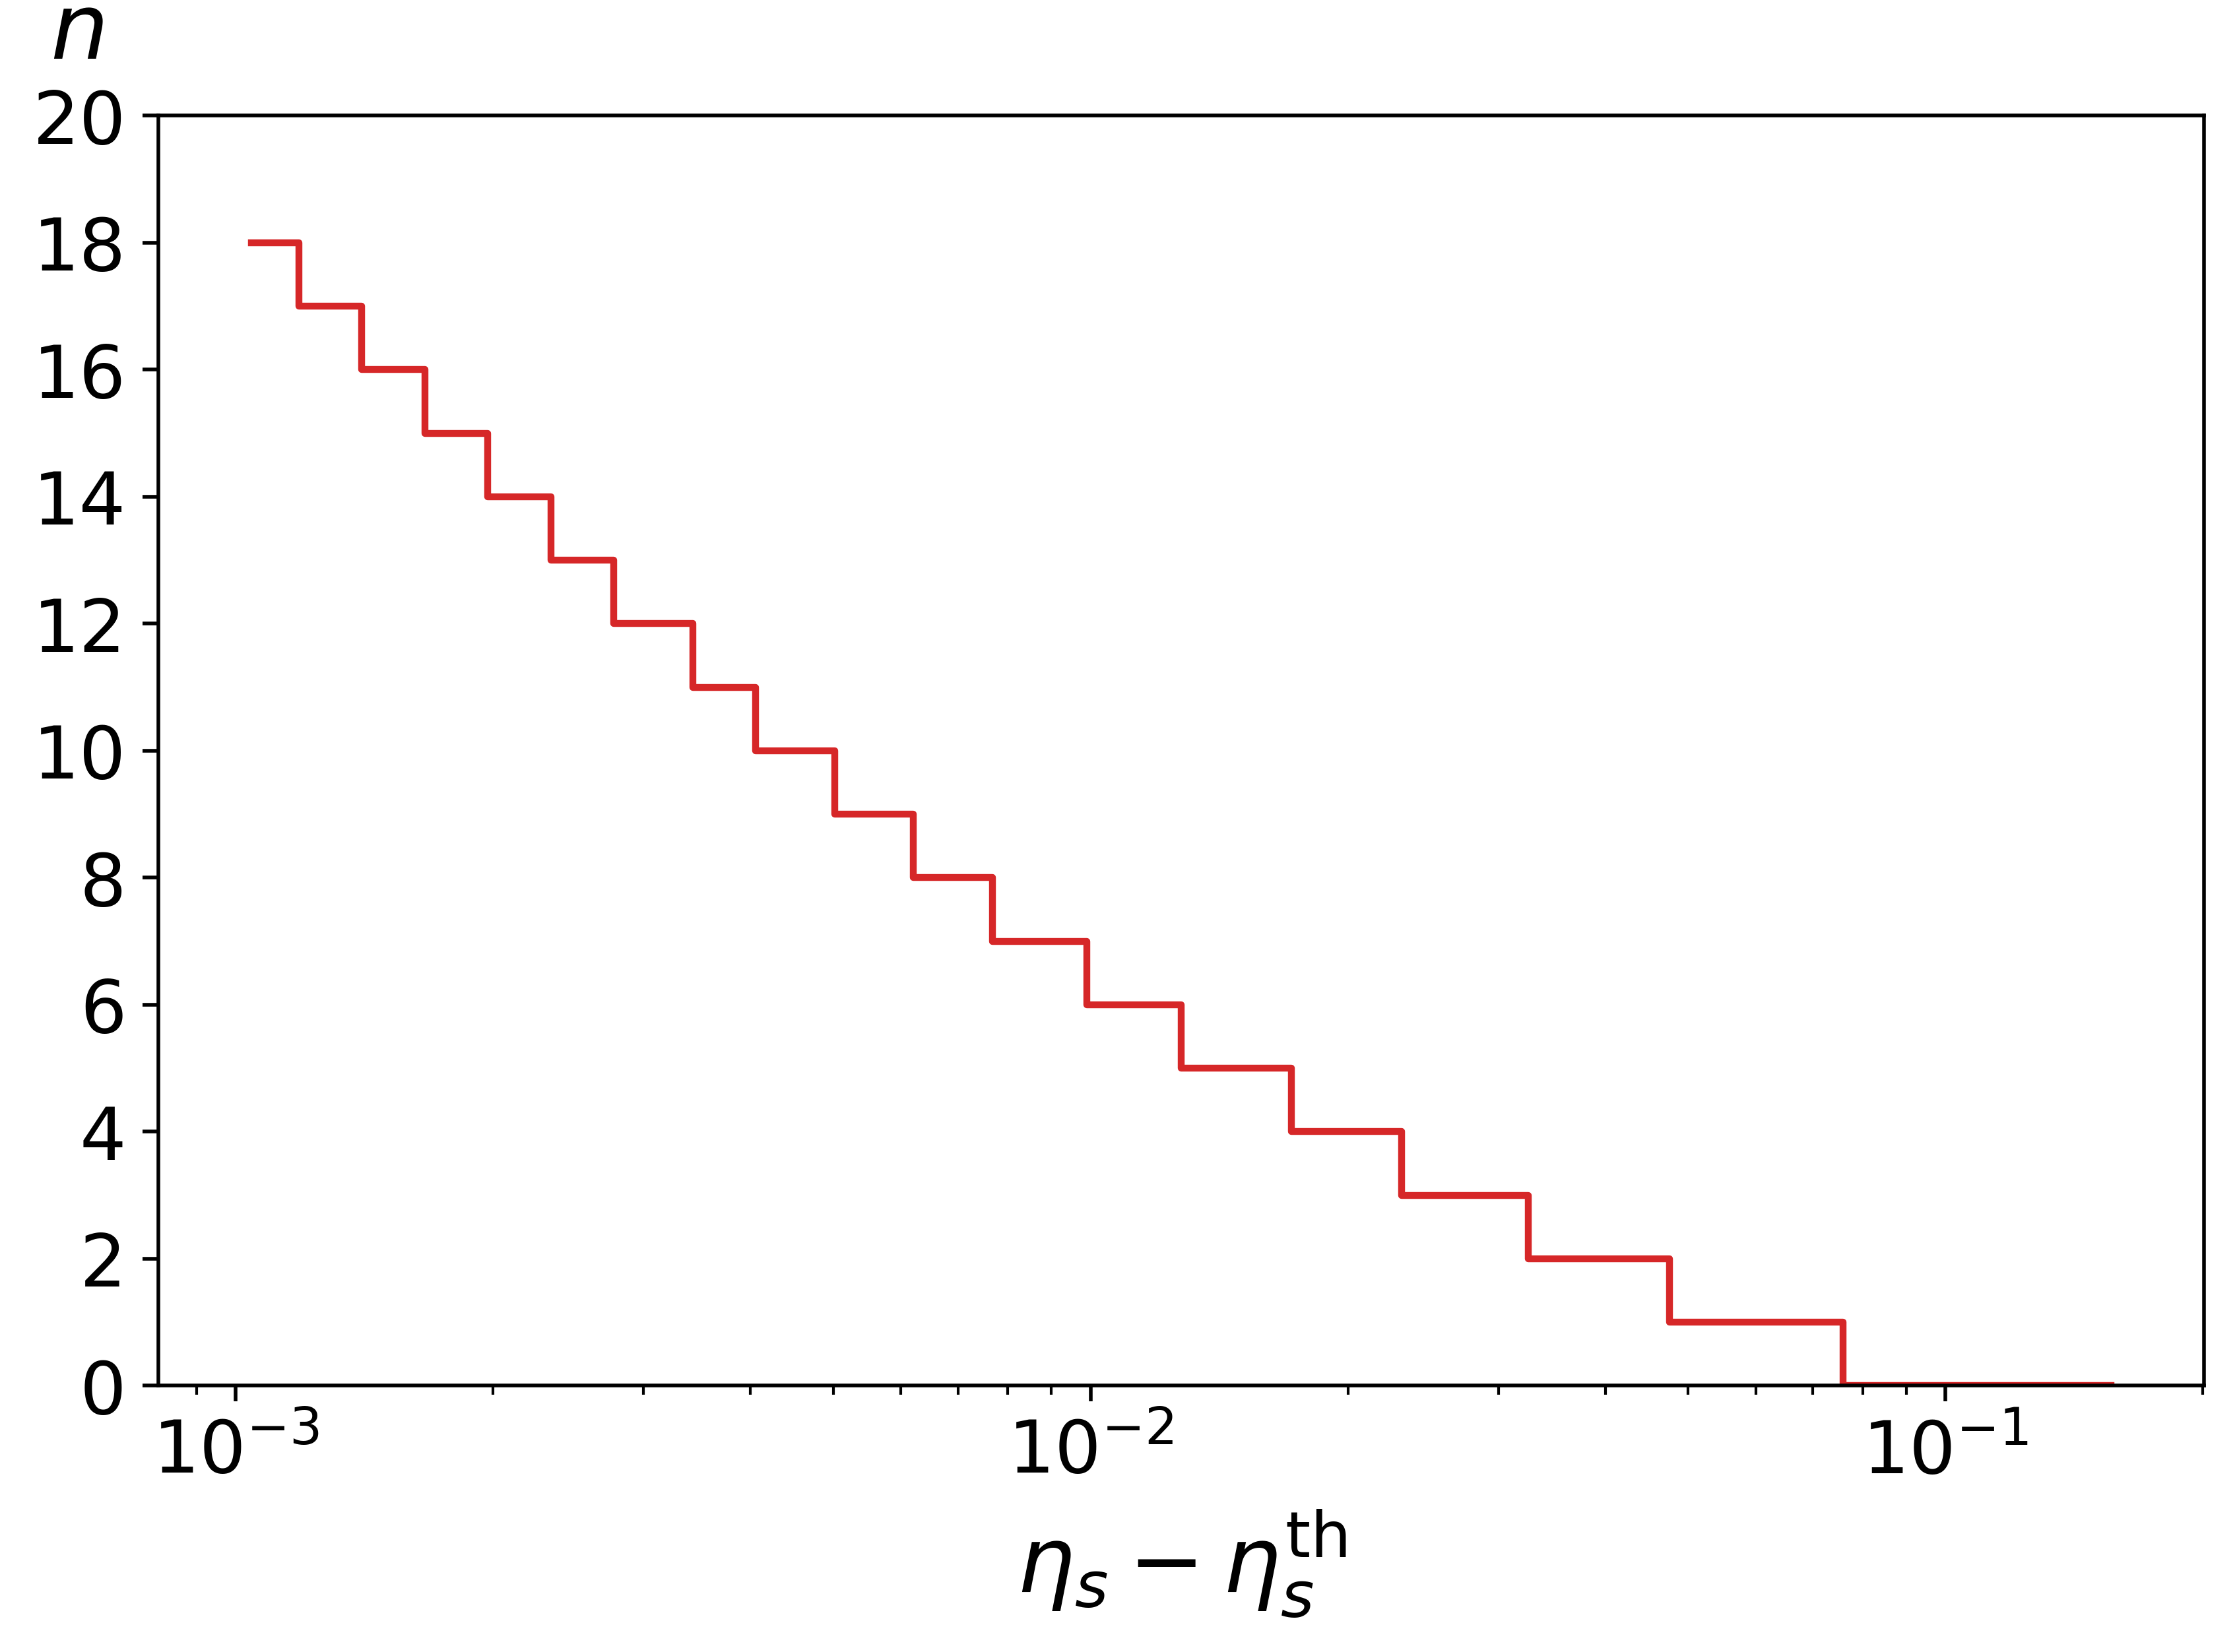

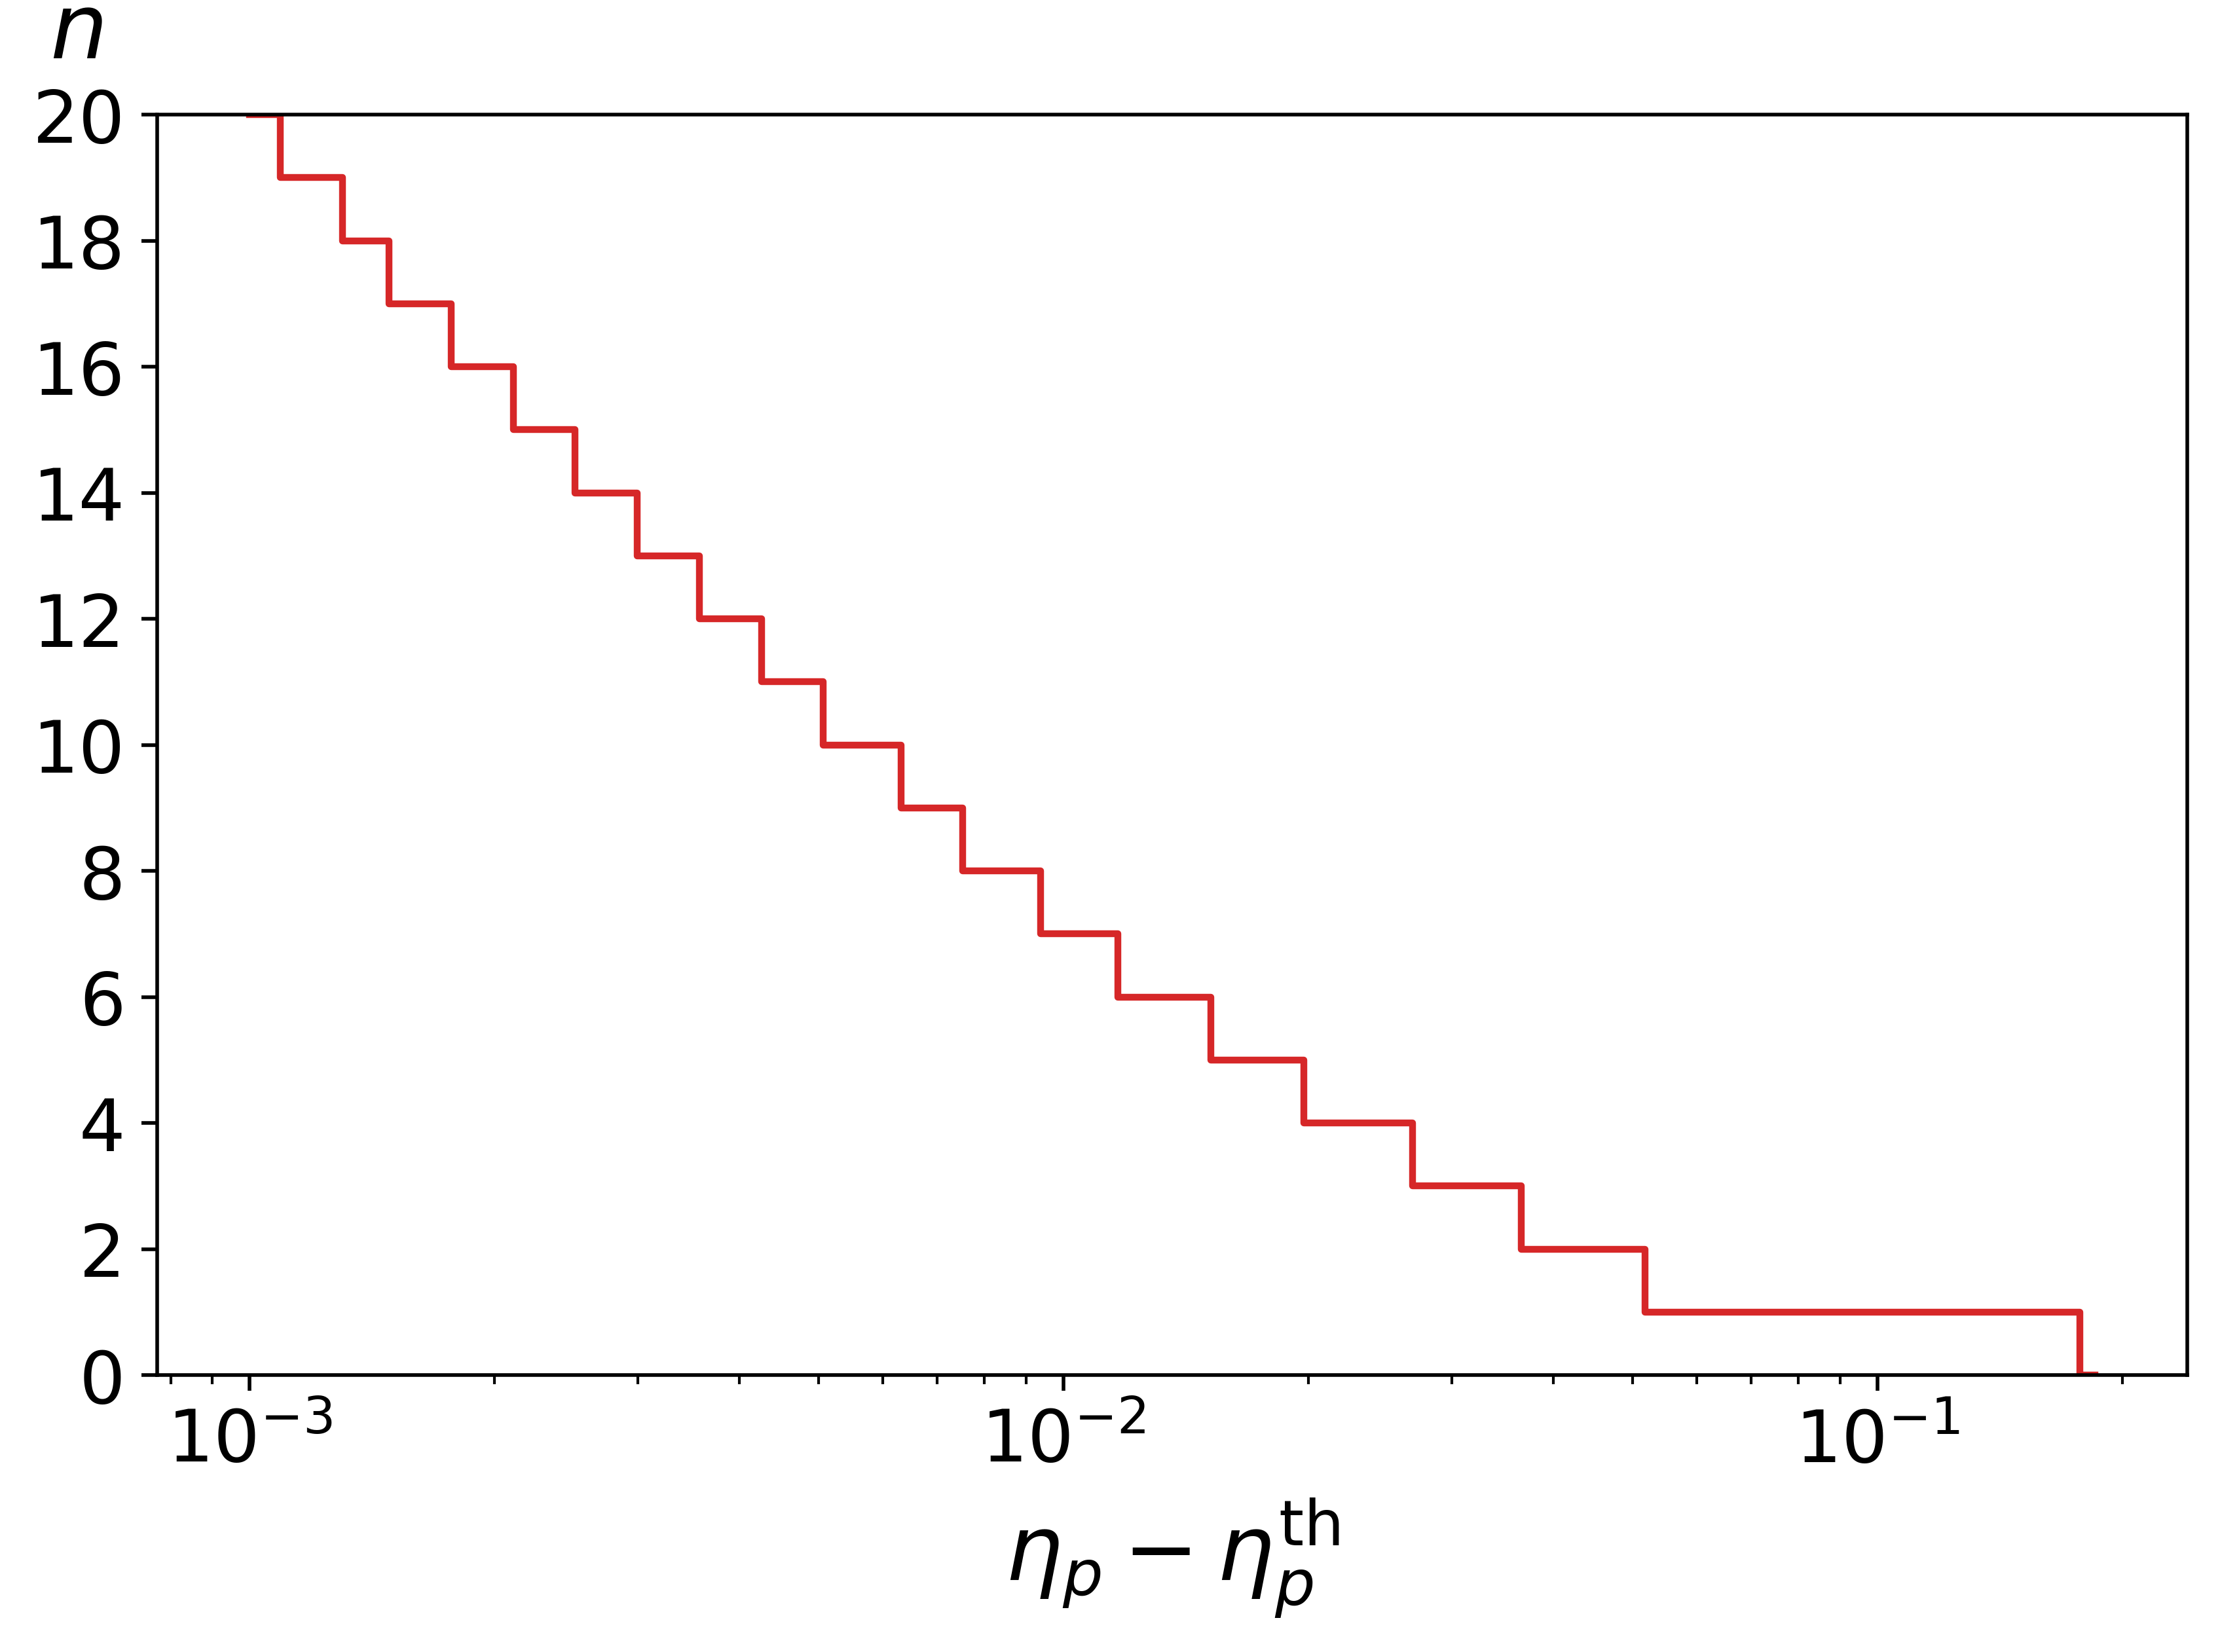

In [198]:
# ============================================================
# Convergence-to-q_inf plots for 1D threshold slices
#
# Supports three plot modes:
#   1) mode="scatter" : step curve only, n vs (eta - eta_th), log x-axis
#   2) mode="step"    : step/staircase plot with visible markers
#   3) mode="alpha"   : log-log fit for n ~ (eta - eta_th)^(-alpha)
#
# Also supports two x-sampling modes:
#   - x_spacing="linear" : sample eta linearly
#   - x_spacing="log"    : sample eta-eta_th logarithmically so plotted
#                          points are evenly distributed on the log x-axis
#
# Notes:
# - Uses same base figure style as your other plots
# - Keeps PMF / convergence calculations unchanged
# - n_start controls the first iteration n at which convergence is allowed
# - skip_first_plotted_point removes the closest-to-threshold plotted point
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import math


# -----------------------------
# Operational q-map and q_inf (survival probability)
# -----------------------------
def q_map_scalar(q, U, V, eta_s, eta_p):
    q = float(np.clip(q, 0.0, 1.0))
    qU = (eta_s ** (U - 1)) * (q ** U)
    qV = (eta_s ** (V - 1)) * (q ** V)
    out = qU + qV - (2.0 - eta_p) * qU * qV
    return float(np.clip(out, 0.0, 1.0))

def q_inf_conpt_fixed_point(U, V, eta_s, eta_p, *, tol=1e-14, max_iter=200000):
    q = 1.0
    for _ in range(max_iter):
        qn = q_map_scalar(q, U, V, eta:=(float(eta_s)), float(eta_p))
        if abs(qn - q) < tol:
            return float(qn)
        q = qn
    return float(q)


# -----------------------------
# Bin-fast PMF engine (ConPT)
# -----------------------------
_BF_CACHE = {}

def _bf_round_to_idx(x, n_bins):
    n1 = n_bins - 1
    return np.clip((x * n1 + 0.5).astype(np.int64), 0, n1).astype(np.int32)

def _bf_para_conpt_vec(a, b):
    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - a*a)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - b*b)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))

def bf_get_para_idx_table(n_bins):
    key = ("para", int(n_bins))
    if key in _BF_CACHE:
        return _BF_CACHE[key]
    x = np.linspace(0.0, 1.0, int(n_bins), dtype=np.float64)
    A = x[:, None]
    B = x[None, :]
    P = _bf_para_conpt_vec(A, B)
    tab = _bf_round_to_idx(P, n_bins)
    _BF_CACHE[key] = tab
    return tab

def bf_prune_sparse(idxs, ps, p_min=0.0, max_states=None):
    if idxs.size == 0:
        return idxs, ps
    if p_min > 0.0:
        m = ps >= p_min
        idxs, ps = idxs[m], ps[m]
    if max_states is not None and idxs.size > int(max_states):
        k = int(max_states)
        sel = np.argpartition(ps, -k)[-k:]
        idxs, ps = idxs[sel], ps[sel]
    order = np.argsort(idxs)
    return idxs[order], ps[order]

def bf_normalize_mass(ps, target_mass):
    s = float(ps.sum())
    if s <= 0.0:
        return ps
    return ps * (float(target_mass) / s)

def bf_mul_convolve_sparse(idxA, pA, idxB, pB, n_bins):
    n1 = n_bins - 1
    ij = (idxA[:, None].astype(np.int64) * idxB[None, :].astype(np.int64))
    out_idx = ((2 * ij + n1) // (2 * n1)).astype(np.int32)
    w = (pA[:, None] * pB[None, :]).ravel()
    out = np.bincount(out_idx.ravel(), weights=w, minlength=n_bins).astype(np.float64)
    nz = out > 0
    return np.nonzero(nz)[0].astype(np.int32), out[nz]

def bf_para_convolve_sparse(idxA, pA, idxB, pB, para_tab, n_bins):
    out_idx = para_tab[np.ix_(idxA, idxB)]
    w = (pA[:, None] * pB[None, :]).ravel()
    out = np.bincount(out_idx.ravel(), weights=w, minlength=n_bins).astype(np.float64)
    nz = out > 0
    return np.nonzero(nz)[0].astype(np.int32), out[nz]

def bf_series_chain(idx, ps, p0, L, eta_s, n_bins, p_min=0.0, max_states=None):
    if L == 1:
        return idx, ps, p0
    q = 1.0 - float(p0)
    q_chain = (q ** L) * (float(eta_s) ** (L - 1))
    p0_chain = 1.0 - q_chain

    if idx.size == 1:
        n1 = n_bins - 1
        x = idx[0] / n1
        xL = x ** L
        idx_out = np.array([int(xL * n1 + 0.5)], dtype=np.int32)
        p_out = np.array([q_chain], dtype=np.float64)
        return idx_out, p_out, p0_chain

    cur_idx, cur_p = idx, ps
    for _ in range(L - 1):
        cur_idx, cur_p = bf_mul_convolve_sparse(cur_idx, cur_p, idx, ps, n_bins)
        cur_idx, cur_p = bf_prune_sparse(cur_idx, cur_p, p_min=p_min, max_states=max_states)

    cur_p = bf_normalize_mass(cur_p, q_chain)
    return cur_idx, cur_p, p0_chain

def bf_parallel_combine(idxU, pU, p0U, idxV, pV, p0V, eta_p, para_tab, n_bins, p_min=0.0, max_states=None):
    out_dense = np.zeros(n_bins, dtype=np.float64)

    if idxU.size:
        out_dense[idxU] += float(p0V) * pU
    if idxV.size:
        out_dense[idxV] += float(p0U) * pV

    qU = 1.0 - float(p0U)
    qV = 1.0 - float(p0V)

    if qU > 0 and qV > 0 and float(eta_p) > 0.0 and idxU.size and idxV.size:
        idxP, pP = bf_para_convolve_sparse(idxU, pU, idxV, pV, para_tab, n_bins)
        pP = bf_normalize_mass(pP, float(eta_p) * (qU * qV))
        out_dense[idxP] += pP

    nz = out_dense > 0
    idx_out = np.nonzero(nz)[0].astype(np.int32)
    p_out = out_dense[nz]
    idx_out, p_out = bf_prune_sparse(idx_out, p_out, p_min=p_min, max_states=max_states)

    q_out = float(p_out.sum())
    p0_out = 1.0 - q_out
    return idx_out, p_out, p0_out

def bf_step_uv(idx, ps, p0, U, V, eta_s, eta_p, n_bins, para_tab, p_min=0.0, max_states=None):
    idxU, pU, p0U = bf_series_chain(idx, ps, p0, L=U, eta_s=eta_s, n_bins=n_bins, p_min=p_min, max_states=max_states)
    idxV, pV, p0V = bf_series_chain(idx, ps, p0, L=V, eta_s=eta_s, n_bins=n_bins, p_min=p_min, max_states=max_states)
    return bf_parallel_combine(idxU, pU, p0U, idxV, pV, p0V, eta_p, para_tab, n_bins, p_min=p_min, max_states=max_states)

def bf_mean(idx, ps, n_bins):
    if idx.size == 0:
        return 0.0
    x = idx.astype(np.float64) / float(n_bins - 1)
    return float((x * ps).sum())


# -----------------------------
# Convergence in terms of n
# -----------------------------
def convergence_n_to_qinf_pmf(
    *, U, V, c0, eta_s, eta_p,
    eps=0.01,
    n_bins=501,
    p_min=1e-12,
    max_states=None,
    q_tol=1e-14,
    q_mask=1e-12,
    L_cap=1e20,
    n_max=None,
    n_start=0,
):
    """
    Returns n_eps = first n such that |E[X_n] - q_inf| <= eps*q_inf,
    evaluated only if q_inf > q_mask.

    IMPORTANT:
    - Convergence checking starts at n = n_start.
    - If n_start = 0, the initial delta-distribution at c0 is checked first.
    """
    U = int(U); V = int(V)
    eta_s = float(eta_s); eta_p = float(eta_p)
    c0 = float(np.clip(c0, 0.0, 1.0))
    n_start = int(n_start)

    q_inf = q_inf_conpt_fixed_point(U, V, eta_s, eta_p, tol=q_tol)
    if q_inf <= q_mask:
        return np.nan, q_inf

    if n_max is None:
        n_max = int(math.floor(math.log(L_cap, U)))
        n_max = max(n_max, 1)

    para_tab = bf_get_para_idx_table(n_bins)
    n1 = n_bins - 1

    # initial distribution corresponds to n = 0
    idx = np.array([int(c0 * n1 + 0.5)], dtype=np.int32)
    ps = np.array([1.0], dtype=np.float64)
    p0 = 0.0

    mu = bf_mean(idx, ps, n_bins)
    if n_start <= 0 and abs(mu - q_inf) <= eps * q_inf:
        return 0, q_inf

    for n in range(1, n_max + 1):
        idx, ps, p0 = bf_step_uv(
            idx, ps, p0, U, V, eta_s, eta_p,
            n_bins, para_tab, p_min=p_min, max_states=max_states
        )
        mu = bf_mean(idx, ps, n_bins)
        if n >= n_start and abs(mu - q_inf) <= eps * q_inf:
            return n, q_inf

    return int(n_max), q_inf


# -----------------------------
# Exact operational thresholds for (2,2)
# -----------------------------
def operational_threshold_markers(U, V):
    U = int(U); V = int(V)
    if U == 2 and V == 2:
        eta_s_th_at_ep1 = 27.0 / 32.0
        eta_p_th_at_es1 = 22.0 / 27.0
        return eta_s_th_at_ep1, eta_p_th_at_es1
    return np.nan, np.nan


# -----------------------------
# Build slice data
# -----------------------------
def build_convergence_threshold_slice(
    *,
    vary="eta_s",              # "eta_s" or "eta_p"
    U=2, V=2,
    c0=1.0,
    eta_min=0.80, eta_max=1.00,
    d_eta=0.001,
    eps=0.01,
    n_bins=501,
    p_min=1e-12,
    max_states=None,
    L_cap=1e20,
    n_max=None,
    n_start=0,
    skip_first_plotted_point=True,
    x_spacing="linear",        # "linear" or "log"
    n_eta=200,                 # used for x_spacing="log"
    dx_min=None,               # used for x_spacing="log"
):
    eta_s_th, eta_p_th = operational_threshold_markers(U, V)

    if vary == "eta_s":
        eta_th = float(eta_s_th)
    elif vary == "eta_p":
        eta_th = float(eta_p_th)
    else:
        raise ValueError("vary must be 'eta_s' or 'eta_p'")

    if x_spacing == "linear":
        eta_vals = np.arange(
            float(eta_min),
            float(eta_max) + 0.5 * float(d_eta),
            float(d_eta),
            dtype=np.float64
        )
    elif x_spacing == "log":
        if dx_min is None:
            dx_min = max(float(d_eta), 1e-6)
        dx_max = float(eta_max) - eta_th
        if dx_max <= dx_min:
            raise ValueError("Need eta_max > eta_th + dx_min for log-spaced sampling.")
        dx_vals = np.logspace(np.log10(dx_min), np.log10(dx_max), int(n_eta))
        eta_vals = eta_th + dx_vals
    else:
        raise ValueError("x_spacing must be 'linear' or 'log'")

    x_raw = []
    n_vals = []
    q_vals = []

    for eta in eta_vals:
        if vary == "eta_s":
            n_conv, qinf = convergence_n_to_qinf_pmf(
                U=U, V=V, c0=c0,
                eta_s=float(eta), eta_p=1.0,
                eps=eps, n_bins=n_bins, p_min=p_min,
                max_states=max_states, L_cap=L_cap,
                n_max=n_max, n_start=n_start
            )
        else:
            n_conv, qinf = convergence_n_to_qinf_pmf(
                U=U, V=V, c0=c0,
                eta_s=1.0, eta_p=float(eta),
                eps=eps, n_bins=n_bins, p_min=p_min,
                max_states=max_states, L_cap=L_cap,
                n_max=n_max, n_start=n_start
            )

        x_raw.append(float(eta))
        n_vals.append(float(n_conv))
        q_vals.append(float(qinf))

    x_raw = np.array(x_raw, dtype=np.float64)
    n_vals = np.array(n_vals, dtype=np.float64)
    q_vals = np.array(q_vals, dtype=np.float64)

    dx = x_raw - eta_th
    m = np.isfinite(n_vals) & np.isfinite(q_vals) & (dx > 0.0)

    x_raw = x_raw[m]
    dx = dx[m]
    n_vals = n_vals[m]
    q_vals = q_vals[m]

    if skip_first_plotted_point and len(dx) > 1:
        x_raw = x_raw[1:]
        dx = dx[1:]
        n_vals = n_vals[1:]
        q_vals = q_vals[1:]

    return {
        "vary": vary,
        "eta_raw": x_raw,
        "eta_minus_th": dx,
        "n_vals": n_vals,
        "q_vals": q_vals,
        "eta_th": eta_th,
        "c0": c0,
        "n_start": n_start,
    }


# -----------------------------
# Plot helper
# -----------------------------
def plot_convergence_threshold_slice(
    data,
    *,
    mode="scatter",            # "scatter", "step", "alpha"
    tick_fs=16,
    label_fs=20,
    marker_size=32,
    line_width=1.5,
    fit_min_points=6,
    fit_use_tail_fraction=1.0, # 1.0 means use all valid points
):
    vary = data["vary"]
    dx = np.array(data["eta_minus_th"], dtype=np.float64)
    n_vals = np.array(data["n_vals"], dtype=np.float64)

    if vary == "eta_s":
        xlabel = r"$\eta_s-\eta_s^{\rm th}$"
    else:
        xlabel = r"$\eta_p-\eta_p^{\rm th}$"

    fig, ax = plt.subplots(figsize=(8, 5), dpi=500)

    if mode in ("scatter", "step"):
        order = np.argsort(dx)
        xs = dx[order]
        ys = n_vals[order]

        ax.step(xs, ys, where="post", color="tab:red", linewidth=line_width)

        if mode == "step":
            ax.scatter(xs, ys, color="tab:red", s=marker_size * 0.65)

        ax.set_xscale("log")
        ax.set_xlabel(xlabel, fontsize=label_fs)
        ax.set_ylabel(r"$n$", rotation=0, labelpad=18, fontsize=label_fs)
        ax.yaxis.set_label_coords(-0.04, 1.03)
        ax.set_ylim(0,20)

        ax.set_ylim(0, 20)
        yt = np.arange(0, 21, 2)
        ax.set_yticks(yt)
        ax.set_yticklabels([f"{int(t)}" for t in yt])

    elif mode == "alpha":
        # Fit log n = a + b log(dx), so alpha = -b
        m = np.isfinite(dx) & np.isfinite(n_vals) & (dx > 0.0) & (n_vals > 0.0)
        xfit = dx[m]
        yfit = n_vals[m]

        if len(xfit) < fit_min_points:
            raise ValueError("Not enough valid points to estimate alpha.")

        order = np.argsort(xfit)
        xfit = xfit[order]
        yfit = yfit[order]

        if fit_use_tail_fraction < 1.0:
            keep = max(fit_min_points, int(np.ceil(len(xfit) * float(fit_use_tail_fraction))))
            xfit = xfit[:keep]
            yfit = yfit[:keep]

        lx = np.log(xfit)
        ly = np.log(yfit)

        slope, intercept = np.polyfit(lx, ly, 1)
        alpha = -float(slope)

        xx = np.logspace(np.log10(np.min(xfit)), np.log10(np.max(xfit)), 400)
        yy = np.exp(intercept) * (xx ** slope)

        ax.scatter(xfit, yfit, color="tab:red", s=marker_size, label="Numerical results")
        ax.plot(
            xx, yy,
            color="tab:red",
            linewidth=line_width,
            label=rf"Fit: $n \sim (\eta-\eta^{{\rm th}})^{{-\alpha}}$, $\alpha={alpha:.3f}$"
        )

        ax.set_xscale("log")
        ax.set_yscale("log")

        ax.set_xlabel(xlabel, fontsize=label_fs)
        ax.set_ylabel(r"$n$", rotation=0, labelpad=18, fontsize=label_fs)
        ax.yaxis.set_label_coords(-0.04, 1.03)

        ax.legend(loc="upper right", frameon=True, fontsize=tick_fs)

    else:
        raise ValueError("mode must be 'scatter', 'step', or 'alpha'")

    ax.tick_params(axis="both", which="both", labelsize=tick_fs)
    plt.show()

    out = dict(data)
    if mode == "alpha":
        out["alpha"] = alpha
        out["fit_slope"] = slope
        out["fit_intercept"] = intercept
    return out


# -----------------------------
# Convenience wrappers
# -----------------------------
def plot_convergence_eta_s_threshold_distance(
    *,
    mode="scatter",
    U=2, V=2,
    c0=1.0,
    eta_min=0.80, eta_max=1.00,
    d_eta=0.001,
    eps=0.01,
    n_bins=501,
    p_min=1e-12,
    max_states=None,
    L_cap=1e20,
    n_max=None,
    n_start=0,
    skip_first_plotted_point=True,
    x_spacing="linear",
    n_eta=200,
    dx_min=None,
    tick_fs=16,
    label_fs=20,
    marker_size=32,
    line_width=1.5,
    fit_min_points=6,
    fit_use_tail_fraction=1.0,
):
    data = build_convergence_threshold_slice(
        vary="eta_s",
        U=U, V=V,
        c0=c0,
        eta_min=eta_min, eta_max=eta_max,
        d_eta=d_eta,
        eps=eps,
        n_bins=n_bins,
        p_min=p_min,
        max_states=max_states,
        L_cap=L_cap,
        n_max=n_max,
        n_start=n_start,
        skip_first_plotted_point=skip_first_plotted_point,
        x_spacing=x_spacing,
        n_eta=n_eta,
        dx_min=dx_min,
    )
    return plot_convergence_threshold_slice(
        data,
        mode=mode,
        tick_fs=tick_fs,
        label_fs=label_fs,
        marker_size=marker_size,
        line_width=line_width,
        fit_min_points=fit_min_points,
        fit_use_tail_fraction=fit_use_tail_fraction,
    )

def plot_convergence_eta_p_threshold_distance(
    *,
    mode="scatter",
    U=2, V=2,
    c0=1.0,
    eta_min=0.80, eta_max=1.00,
    d_eta=0.001,
    eps=0.01,
    n_bins=501,
    p_min=1e-12,
    max_states=None,
    L_cap=1e20,
    n_max=None,
    n_start=0,
    skip_first_plotted_point=True,
    x_spacing="linear",
    n_eta=200,
    dx_min=None,
    tick_fs=16,
    label_fs=20,
    marker_size=32,
    line_width=1.5,
    fit_min_points=6,
    fit_use_tail_fraction=1.0,
):
    data = build_convergence_threshold_slice(
        vary="eta_p",
        U=U, V=V,
        c0=c0,
        eta_min=eta_min, eta_max=eta_max,
        d_eta=d_eta,
        eps=eps,
        n_bins=n_bins,
        p_min=p_min,
        max_states=max_states,
        L_cap=L_cap,
        n_max=n_max,
        n_start=n_start,
        skip_first_plotted_point=skip_first_plotted_point,
        x_spacing=x_spacing,
        n_eta=n_eta,
        dx_min=dx_min,
    )
    return plot_convergence_threshold_slice(
        data,
        mode=mode,
        tick_fs=tick_fs,
        label_fs=label_fs,
        marker_size=marker_size,
        line_width=line_width,
        fit_min_points=fit_min_points,
        fit_use_tail_fraction=fit_use_tail_fraction,
    )


# ============================================================
# Example calls
# ============================================================

# 1) log-spaced x samples + step curve only
out_eta_s_scatter = plot_convergence_eta_s_threshold_distance(
    mode="scatter",
    x_spacing="log",
    n_eta=120,
    dx_min=1e-3,
    U=2, V=2,
    c0=1.0,
    eta_min=0.80, eta_max=1.00,
    d_eta=0.001,
    eps=0.01,
    n_bins=501,
    p_min=1e-12,
    L_cap=1e20,
    n_start=0,
    skip_first_plotted_point=True,
)

out_eta_p_scatter = plot_convergence_eta_p_threshold_distance(
    mode="scatter",
    x_spacing="log",
    n_eta=120,
    dx_min=1e-3,
    U=2, V=2,
    c0=1.0,
    eta_min=0.80, eta_max=1.00,
    d_eta=0.001,
    eps=0.01,
    n_bins=501,
    p_min=1e-12,
    L_cap=1e20,
    n_start=0,
    skip_first_plotted_point=False,
)

# 2) log-spaced x samples + step curve with visible markers
# out_eta_s_step = plot_convergence_eta_s_threshold_distance(
#     mode="step",
#     x_spacing="log",
#     n_eta=120,
#     dx_min=1e-3,
#     U=2, V=2,
#     c0=1.0
# )
#
# out_eta_p_step = plot_convergence_eta_p_threshold_distance(
#     mode="step",
#     x_spacing="log",
#     n_eta=120,
#     dx_min=1e-3,
#     U=2, V=2,
#     c0=1.0
# )

# 3) alpha-fit version
# out_eta_s_alpha = plot_convergence_eta_s_threshold_distance(
#     mode="alpha",
#     x_spacing="log",
#     n_eta=120,
#     dx_min=1e-3,
#     U=2, V=2,
#     c0=1.0,
#     fit_use_tail_fraction=0.35
# )
#
# out_eta_p_alpha = plot_convergence_eta_p_threshold_distance(
#     mode="alpha",
#     x_spacing="log",
#     n_eta=120,
#     dx_min=1e-3,
#     U=2, V=2,
#     c0=1.0,
#     fit_use_tail_fraction=0.35
# )

## Heatplot - PMF convergence

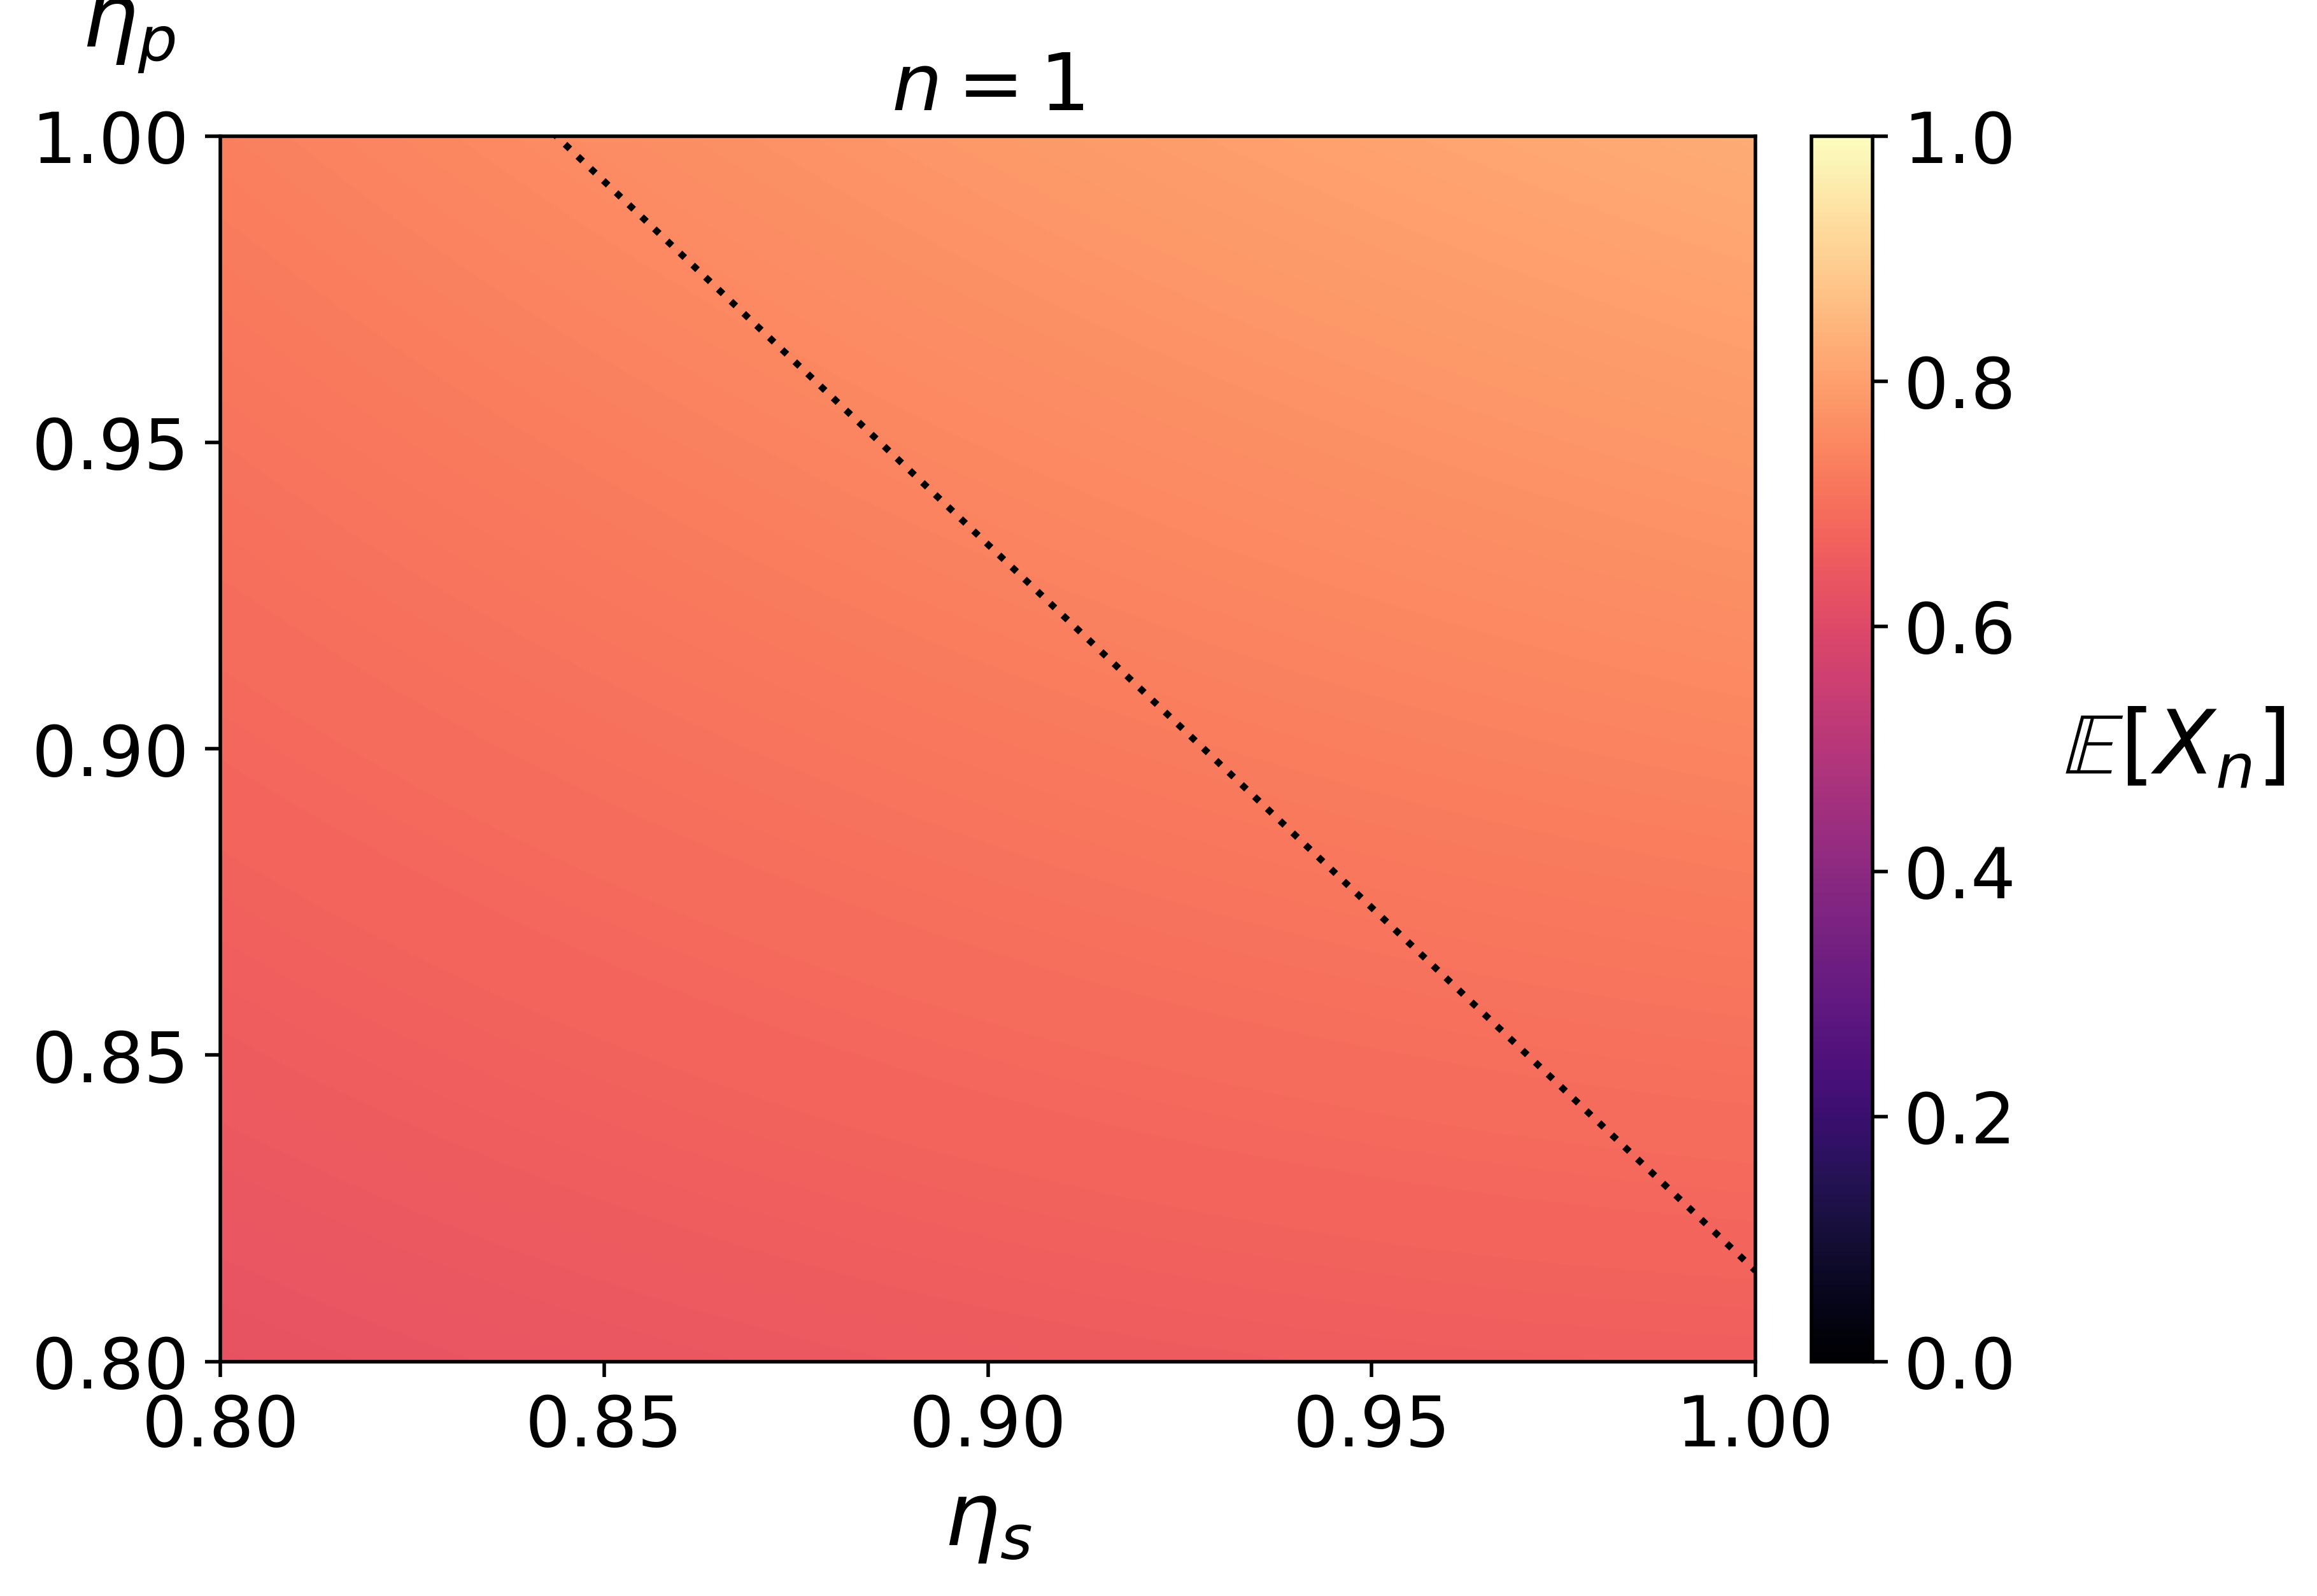

In [4]:
# ============================================================
# PMF-mean heatmap for ConPT on the (U,V)-flower
#
# Computes the ACTUAL quantized PMF mean E[X_n] at fixed generation n
# on an (eta_s, eta_p) grid, using a sparse/bin-fast PMF engine.
#
# House style:
# - figsize=(8, 5)
# - dpi=500
# - x-axis = eta_s
# - y-axis = eta_p
# - manual horizontal right-side colorbar label
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import RectBivariateSpline
from scipy.interpolate import RectBivariateSpline, RegularGridInterpolator
from scipy.ndimage import gaussian_filter
from scipy.interpolate import RectBivariateSpline, RegularGridInterpolator, RBFInterpolator
from scipy.ndimage import gaussian_filter


# -----------------------------
# Fast sparse/bin PMF engine
# -----------------------------
_BF_CACHE = {}


def _bf_round_to_idx(x, n_bins):
    n1 = n_bins - 1
    return np.clip((x * n1 + 0.5).astype(np.int64), 0, n1).astype(np.int32)


def _bf_para_conpt_vec(a, b):
    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - a * a)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - b * b)))
    M = np.maximum(0.5, mu * mv)
    return 2.0 * np.sqrt(np.maximum(0.0, M * (1.0 - M)))


def bf_get_para_idx_table(n_bins):
    key = ("para", int(n_bins))
    if key in _BF_CACHE:
        return _BF_CACHE[key]
    x = np.linspace(0.0, 1.0, int(n_bins), dtype=np.float64)
    A = x[:, None]
    B = x[None, :]
    P = _bf_para_conpt_vec(A, B)
    tab = _bf_round_to_idx(P, n_bins)
    _BF_CACHE[key] = tab
    return tab


def bf_prune_sparse(idxs, ps, p_min=0.0, max_states=None):
    if idxs.size == 0:
        return idxs, ps
    if p_min > 0.0:
        m = ps >= p_min
        idxs, ps = idxs[m], ps[m]
    if max_states is not None and idxs.size > int(max_states):
        k = int(max_states)
        sel = np.argpartition(ps, -k)[-k:]
        idxs, ps = idxs[sel], ps[sel]
    order = np.argsort(idxs)
    return idxs[order], ps[order]


def bf_normalize_mass(ps, target_mass):
    s = float(ps.sum())
    if s <= 0.0:
        return ps
    return ps * (float(target_mass) / s)


def bf_mul_convolve_sparse(idxA, pA, idxB, pB, n_bins):
    n1 = n_bins - 1
    ij = idxA[:, None].astype(np.int64) * idxB[None, :].astype(np.int64)
    out_idx = ((2 * ij + n1) // (2 * n1)).astype(np.int32)
    w = (pA[:, None] * pB[None, :]).ravel()
    out = np.bincount(out_idx.ravel(), weights=w, minlength=n_bins).astype(np.float64)
    nz = out > 0.0
    return np.nonzero(nz)[0].astype(np.int32), out[nz]


def bf_para_convolve_sparse(idxA, pA, idxB, pB, para_tab, n_bins):
    out_idx = para_tab[np.ix_(idxA, idxB)]
    w = (pA[:, None] * pB[None, :]).ravel()
    out = np.bincount(out_idx.ravel(), weights=w, minlength=n_bins).astype(np.float64)
    nz = out > 0.0
    return np.nonzero(nz)[0].astype(np.int32), out[nz]


def bf_series_chain(idx, ps, p0, L, eta_s, n_bins, p_min=0.0, max_states=None):
    """
    Reduce a chain of length L of i.i.d copies of X using series multiplication.
    The nonzero mass is scaled by eta_s^(L-1), matching the operational success.
    """
    if L == 1:
        return idx, ps, p0

    q = 1.0 - float(p0)
    q_chain = (q ** L) * (float(eta_s) ** (L - 1))
    p0_chain = 1.0 - q_chain

    # delta-support shortcut
    if idx.size == 1:
        n1 = n_bins - 1
        x = idx[0] / n1
        xL = x ** L
        idx_out = np.array([int(xL * n1 + 0.5)], dtype=np.int32)
        p_out = np.array([q_chain], dtype=np.float64)
        return idx_out, p_out, p0_chain

    cur_idx, cur_p = idx, ps
    for _ in range(L - 1):
        cur_idx, cur_p = bf_mul_convolve_sparse(cur_idx, cur_p, idx, ps, n_bins)
        cur_idx, cur_p = bf_prune_sparse(cur_idx, cur_p, p_min=p_min, max_states=max_states)

    cur_p = bf_normalize_mass(cur_p, q_chain)
    return cur_idx, cur_p, p0_chain


def bf_parallel_combine(idxU, pU, p0U, idxV, pV, p0V, eta_p, para_tab, n_bins, p_min=0.0, max_states=None):
    """
    Parallel combine two branches:
      - if one survives and the other fails -> surviving branch value
      - if both survive and parallel succeeds -> Para(...)
      - otherwise -> 0
    """
    out_dense = np.zeros(n_bins, dtype=np.float64)

    # one survives
    if idxU.size:
        out_dense[idxU] += float(p0V) * pU
    if idxV.size:
        out_dense[idxV] += float(p0U) * pV

    qU = 1.0 - float(p0U)
    qV = 1.0 - float(p0V)

    # both survive and parallel succeeds
    if qU > 0.0 and qV > 0.0 and float(eta_p) > 0.0 and idxU.size and idxV.size:
        idxP, pP = bf_para_convolve_sparse(idxU, pU, idxV, pV, para_tab, n_bins)
        pP = bf_normalize_mass(pP, float(eta_p) * (qU * qV))
        out_dense[idxP] += pP

    nz = out_dense > 0.0
    idx_out = np.nonzero(nz)[0].astype(np.int32)
    p_out = out_dense[nz]
    idx_out, p_out = bf_prune_sparse(idx_out, p_out, p_min=p_min, max_states=max_states)

    q_out = float(p_out.sum())
    p0_out = 1.0 - q_out
    return idx_out, p_out, p0_out


def bf_step_uv(idx, ps, p0, U, V, eta_s, eta_p, n_bins, para_tab, p_min=0.0, max_states=None):
    idxU, pU, p0U = bf_series_chain(
        idx, ps, p0, L=U, eta_s=eta_s, n_bins=n_bins,
        p_min=p_min, max_states=max_states
    )
    idxV, pV, p0V = bf_series_chain(
        idx, ps, p0, L=V, eta_s=eta_s, n_bins=n_bins,
        p_min=p_min, max_states=max_states
    )
    return bf_parallel_combine(
        idxU, pU, p0U, idxV, pV, p0V, eta_p, para_tab, n_bins,
        p_min=p_min, max_states=max_states
    )


def bf_mean(idx, ps, n_bins):
    if idx.size == 0:
        return 0.0
    x = idx.astype(np.float64) / float(n_bins - 1)
    return float((x * ps).sum())


# -----------------------------
# PMF mean at fixed generation n
# -----------------------------
def pmf_mean_conpt_uv(
    *,
    n,
    U=2,
    V=2,
    c_init=0.85,
    eta_s=1.0,
    eta_p=1.0,
    n_bins=2001,
    p_min=1e-12,
    max_states=None,
    para_tab=None,
):
    """
    Returns E[X_n] for the ConPT PMF, using sparse/bin quantization.

    IMPORTANT:
    - n is the generation / recursion depth.
    - n=0 corresponds to the initial deterministic edge with value c_init.
    """
    n = int(n)
    U = int(U)
    V = int(V)
    c_init = float(np.clip(c_init, 0.0, 1.0))
    eta_s = float(eta_s)
    eta_p = float(eta_p)
    n_bins = int(n_bins)

    if para_tab is None:
        para_tab = bf_get_para_idx_table(n_bins)

    n1 = n_bins - 1

    # initial delta distribution at X_0 = c_init
    idx = np.array([int(c_init * n1 + 0.5)], dtype=np.int32)
    ps = np.array([1.0], dtype=np.float64)
    p0 = 0.0

    if n == 0:
        return bf_mean(idx, ps, n_bins)

    for _ in range(n):
        idx, ps, p0 = bf_step_uv(
            idx, ps, p0, U, V, eta_s, eta_p, n_bins, para_tab,
            p_min=p_min, max_states=max_states
        )

    return bf_mean(idx, ps, n_bins)


# -----------------------------
# Heatmap builder
# -----------------------------
def compute_pmf_mean_heatmap(
    *,
    n,
    U=2,
    V=2,
    c_init=0.85,
    eta_s_min=0.80,
    eta_s_max=1.00,
    eta_p_min=0.80,
    eta_p_max=1.00,
    res=101,
    n_bins=2001,
    p_min=1e-12,
    max_states=None,
):
    """
    Compute the PMF mean heatmap E[X_n] over an (eta_s, eta_p) grid.

    res can be 11, 101, 1001, etc.
    """
    eta_s_vals = np.linspace(float(eta_s_min), float(eta_s_max), int(res), dtype=np.float64)
    eta_p_vals = np.linspace(float(eta_p_min), float(eta_p_max), int(res), dtype=np.float64)

    mean_grid = np.empty((len(eta_p_vals), len(eta_s_vals)), dtype=np.float64)

    # precompute para lookup once
    para_tab = bf_get_para_idx_table(int(n_bins))

    for j, ep in enumerate(eta_p_vals):
        for i, es in enumerate(eta_s_vals):
            mean_grid[j, i] = pmf_mean_conpt_uv(
                n=n,
                U=U,
                V=V,
                c_init=c_init,
                eta_s=float(es),
                eta_p=float(ep),
                n_bins=n_bins,
                p_min=p_min,
                max_states=max_states,
                para_tab=para_tab,
            )

    return eta_s_vals, eta_p_vals, mean_grid

def smooth_heatmap_to_display_grid(
    eta_s_vals,
    eta_p_vals,
    Z,
    *,
    display_res=1001,
    interp_method="linear",   # "linear", "spline", or "rbf"
    spline_order=3,
    post_smooth_sigma=0.0,
    rbf_smoothing=0.0,
    rbf_kernel="thin_plate_spline"
):
    """
    Interpolate a coarse heatmap Z(eta_p, eta_s) onto a finer display grid.

    interp_method:
      - "linear": safest, avoids overshoot, but preserves boxy cell geometry
      - "spline": smooth, but can ring/overshoot on coarse grids
      - "rbf": true 2D interpolation using neighbors in all directions;
               best option here for reducing diagonal staircase artifacts
    """
    eta_s_vals = np.asarray(eta_s_vals, dtype=np.float64)
    eta_p_vals = np.asarray(eta_p_vals, dtype=np.float64)
    Z = np.asarray(Z, dtype=np.float64)

    eta_s_fine = np.linspace(float(eta_s_vals.min()), float(eta_s_vals.max()), int(display_res), dtype=np.float64)
    eta_p_fine = np.linspace(float(eta_p_vals.min()), float(eta_p_vals.max()), int(display_res), dtype=np.float64)

    if interp_method == "linear":
        interp = RegularGridInterpolator(
            (eta_p_vals, eta_s_vals),
            Z,
            method="linear",
            bounds_error=False,
            fill_value=None
        )
        EP_fine, ES_fine = np.meshgrid(eta_p_fine, eta_s_fine, indexing="ij")
        pts = np.column_stack([EP_fine.ravel(), ES_fine.ravel()])
        Z_fine = interp(pts).reshape(len(eta_p_fine), len(eta_s_fine))

    elif interp_method == "spline":
        kx = min(int(spline_order), len(eta_s_vals) - 1)
        ky = min(int(spline_order), len(eta_p_vals) - 1)

        spline = RectBivariateSpline(
            eta_p_vals,
            eta_s_vals,
            Z,
            kx=kx,
            ky=ky,
            s=0.0
        )
        Z_fine = spline(eta_p_fine, eta_s_fine)

    elif interp_method == "rbf":
        ES_coarse, EP_coarse = np.meshgrid(eta_s_vals, eta_p_vals, indexing="xy")

        pts_coarse = np.column_stack([
            EP_coarse.ravel(),
            ES_coarse.ravel()
        ])
        vals_coarse = Z.ravel()

        rbf = RBFInterpolator(
            pts_coarse,
            vals_coarse,
            kernel=rbf_kernel,
            smoothing=float(rbf_smoothing)
        )

        EP_fine, ES_fine = np.meshgrid(eta_p_fine, eta_s_fine, indexing="ij")
        pts_fine = np.column_stack([
            EP_fine.ravel(),
            ES_fine.ravel()
        ])

        Z_fine = rbf(pts_fine).reshape(len(eta_p_fine), len(eta_s_fine))

    else:
        raise ValueError("interp_method must be 'linear', 'spline', or 'rbf'")

    if post_smooth_sigma > 0.0:
        Z_fine = gaussian_filter(Z_fine, sigma=float(post_smooth_sigma), mode="nearest")

    Z_fine = np.clip(Z_fine, 0.0, 1.0)
    return eta_s_fine, eta_p_fine, Z_fine


# -----------------------------
# House-style plot
# -----------------------------
def plot_pmf_mean_heatmap(
    *,
    n,
    U=2,
    V=2,
    c_init=0.85,
    eta_s_min=0.80,
    eta_s_max=1.00,
    eta_p_min=0.80,
    eta_p_max=1.00,
    res=101,
    n_bins=2001,
    p_min=1e-12,
    max_states=None,
    fig_dpi=500,
    label_fs=20,
    tick_fs=16,
    cmap_name="magma",
    vmin=0.0,
    vmax=1.0,
    smoothing=True,          # NEW
    display_res=1001,         # NEW
    spline_order=3,           # NEW
    return_grid=True,
    interp_method="linear",   # "linear" or "spline"
    post_smooth_sigma=0.0,    # optional tiny gaussian blur after interpolation
    rbf_smoothing=0.0,
    rbf_kernel="thin_plate_spline",
):
    eta_s_vals, eta_p_vals, mean_grid = compute_pmf_mean_heatmap(
        n=n,
        U=U,
        V=V,
        c_init=c_init,
        eta_s_min=eta_s_min,
        eta_s_max=eta_s_max,
        eta_p_min=eta_p_min,
        eta_p_max=eta_p_max,
        res=res,
        n_bins=n_bins,
        p_min=p_min,
        max_states=max_states,
    )
    # optional artificial smoothing for display only
    if smoothing:
        eta_s_plot, eta_p_plot, mean_grid_plot = smooth_heatmap_to_display_grid(
            eta_s_vals,
            eta_p_vals,
            mean_grid,
            display_res=display_res,
            interp_method=interp_method,
            spline_order=spline_order,
            post_smooth_sigma=post_smooth_sigma,
            rbf_smoothing=rbf_smoothing,
            rbf_kernel=rbf_kernel,
        )
        shading_mode = "auto"
    else:
        eta_s_plot, eta_p_plot, mean_grid_plot = eta_s_vals, eta_p_vals, mean_grid
        shading_mode = "nearest"

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(8, 5), dpi=500)

    cmap = plt.get_cmap(cmap_name).copy()

    pc = ax.pcolormesh(
        eta_s_plot,
        eta_p_plot,
        mean_grid_plot,
        shading=shading_mode,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax
    )

    # exact operational threshold (large-n)
    if (U, V) == (2, 2):
        xs = np.linspace(max(0.8, float(eta_s_vals.min())), float(eta_s_vals.max()), 2000)
        yp_th = 2.0 - (32.0 / 27.0) * xs
        ax.plot(xs, yp_th, color="black", linewidth=1.5, linestyle=":")

    ax.set_xlim(float(eta_s_plot.min()), float(eta_s_plot.max()))
    ax.set_ylim(float(eta_p_plot.min()), float(eta_p_plot.max()))

    ticks = [0.80, 0.85, 0.90, 0.95, 1.00]
    xt = [t for t in ticks if eta_s_vals.min() - 1e-9 <= t <= eta_s_vals.max() + 1e-9]
    yt = [t for t in ticks if eta_p_vals.min() - 1e-9 <= t <= eta_p_vals.max() + 1e-9]

    ax.set_xticks(xt)
    ax.set_yticks(yt)
    ax.set_xticklabels([f"{t:.2f}" for t in xt])
    ax.set_yticklabels([f"{t:.2f}" for t in yt])

    ax.set_xlabel(r"$\eta_s$", fontsize=label_fs)
    ax.set_ylabel(r"$\eta_p$", rotation=0, labelpad=18, fontsize=label_fs)
    ax.yaxis.set_label_coords(-0.06, 1.05)
    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    # leave enough room on the right for manual horizontal colorbar label
    fig.subplots_adjust(right=0.86)

    cbar = fig.colorbar(pc, ax=ax, pad=0.03)
    cbar.ax.tick_params(labelsize=tick_fs)
    cbar.set_ticks(np.linspace(0.0, 1.0, 6))

    # draw once so colorbar position is known
    fig.canvas.draw()
    bbox = cbar.ax.get_position()

    # manual right-side horizontal label: E[X_n]
    x0 = bbox.x1 + 0.075   # moved a bit further right because label is longer
    y0 = 0.5 * (bbox.y0 + bbox.y1)

    fig.text(
        x0, y0,
        r"$\mathbb{E}[X_n]$",
        fontsize=label_fs,
        ha="left",
        va="center"
    )

    ax.set_title(rf"$n={n}$", fontsize=18)

    plt.show()

    if return_grid:
        return {
            "eta_s_vals": eta_s_vals,
            "eta_p_vals": eta_p_vals,
            "mean_grid": mean_grid,
            "eta_s_plot": eta_s_plot,
            "eta_p_plot": eta_p_plot,
            "mean_grid_plot": mean_grid_plot,
            "n": int(n),
            "U": int(U),
            "V": int(V),
            "c_init": float(c_init),
            "smoothing": bool(smoothing),
            "display_res": int(display_res),
        }


# ============================================================
# Example calls
# ============================================================

out_11_smooth = plot_pmf_mean_heatmap(
    n=1,
    U=2,
    V=2,
    c_init=0.8,
    eta_s_min=0.80,
    eta_s_max=1.00,
    eta_p_min=0.80,
    eta_p_max=1.00,
    res=81,
    n_bins=2001,
    p_min=1e-12,
    smoothing=True,
    display_res=1001,
    interp_method="rbf",
    rbf_kernel="thin_plate_spline",
    rbf_smoothing=1e-5,
    post_smooth_sigma=0.15,
)



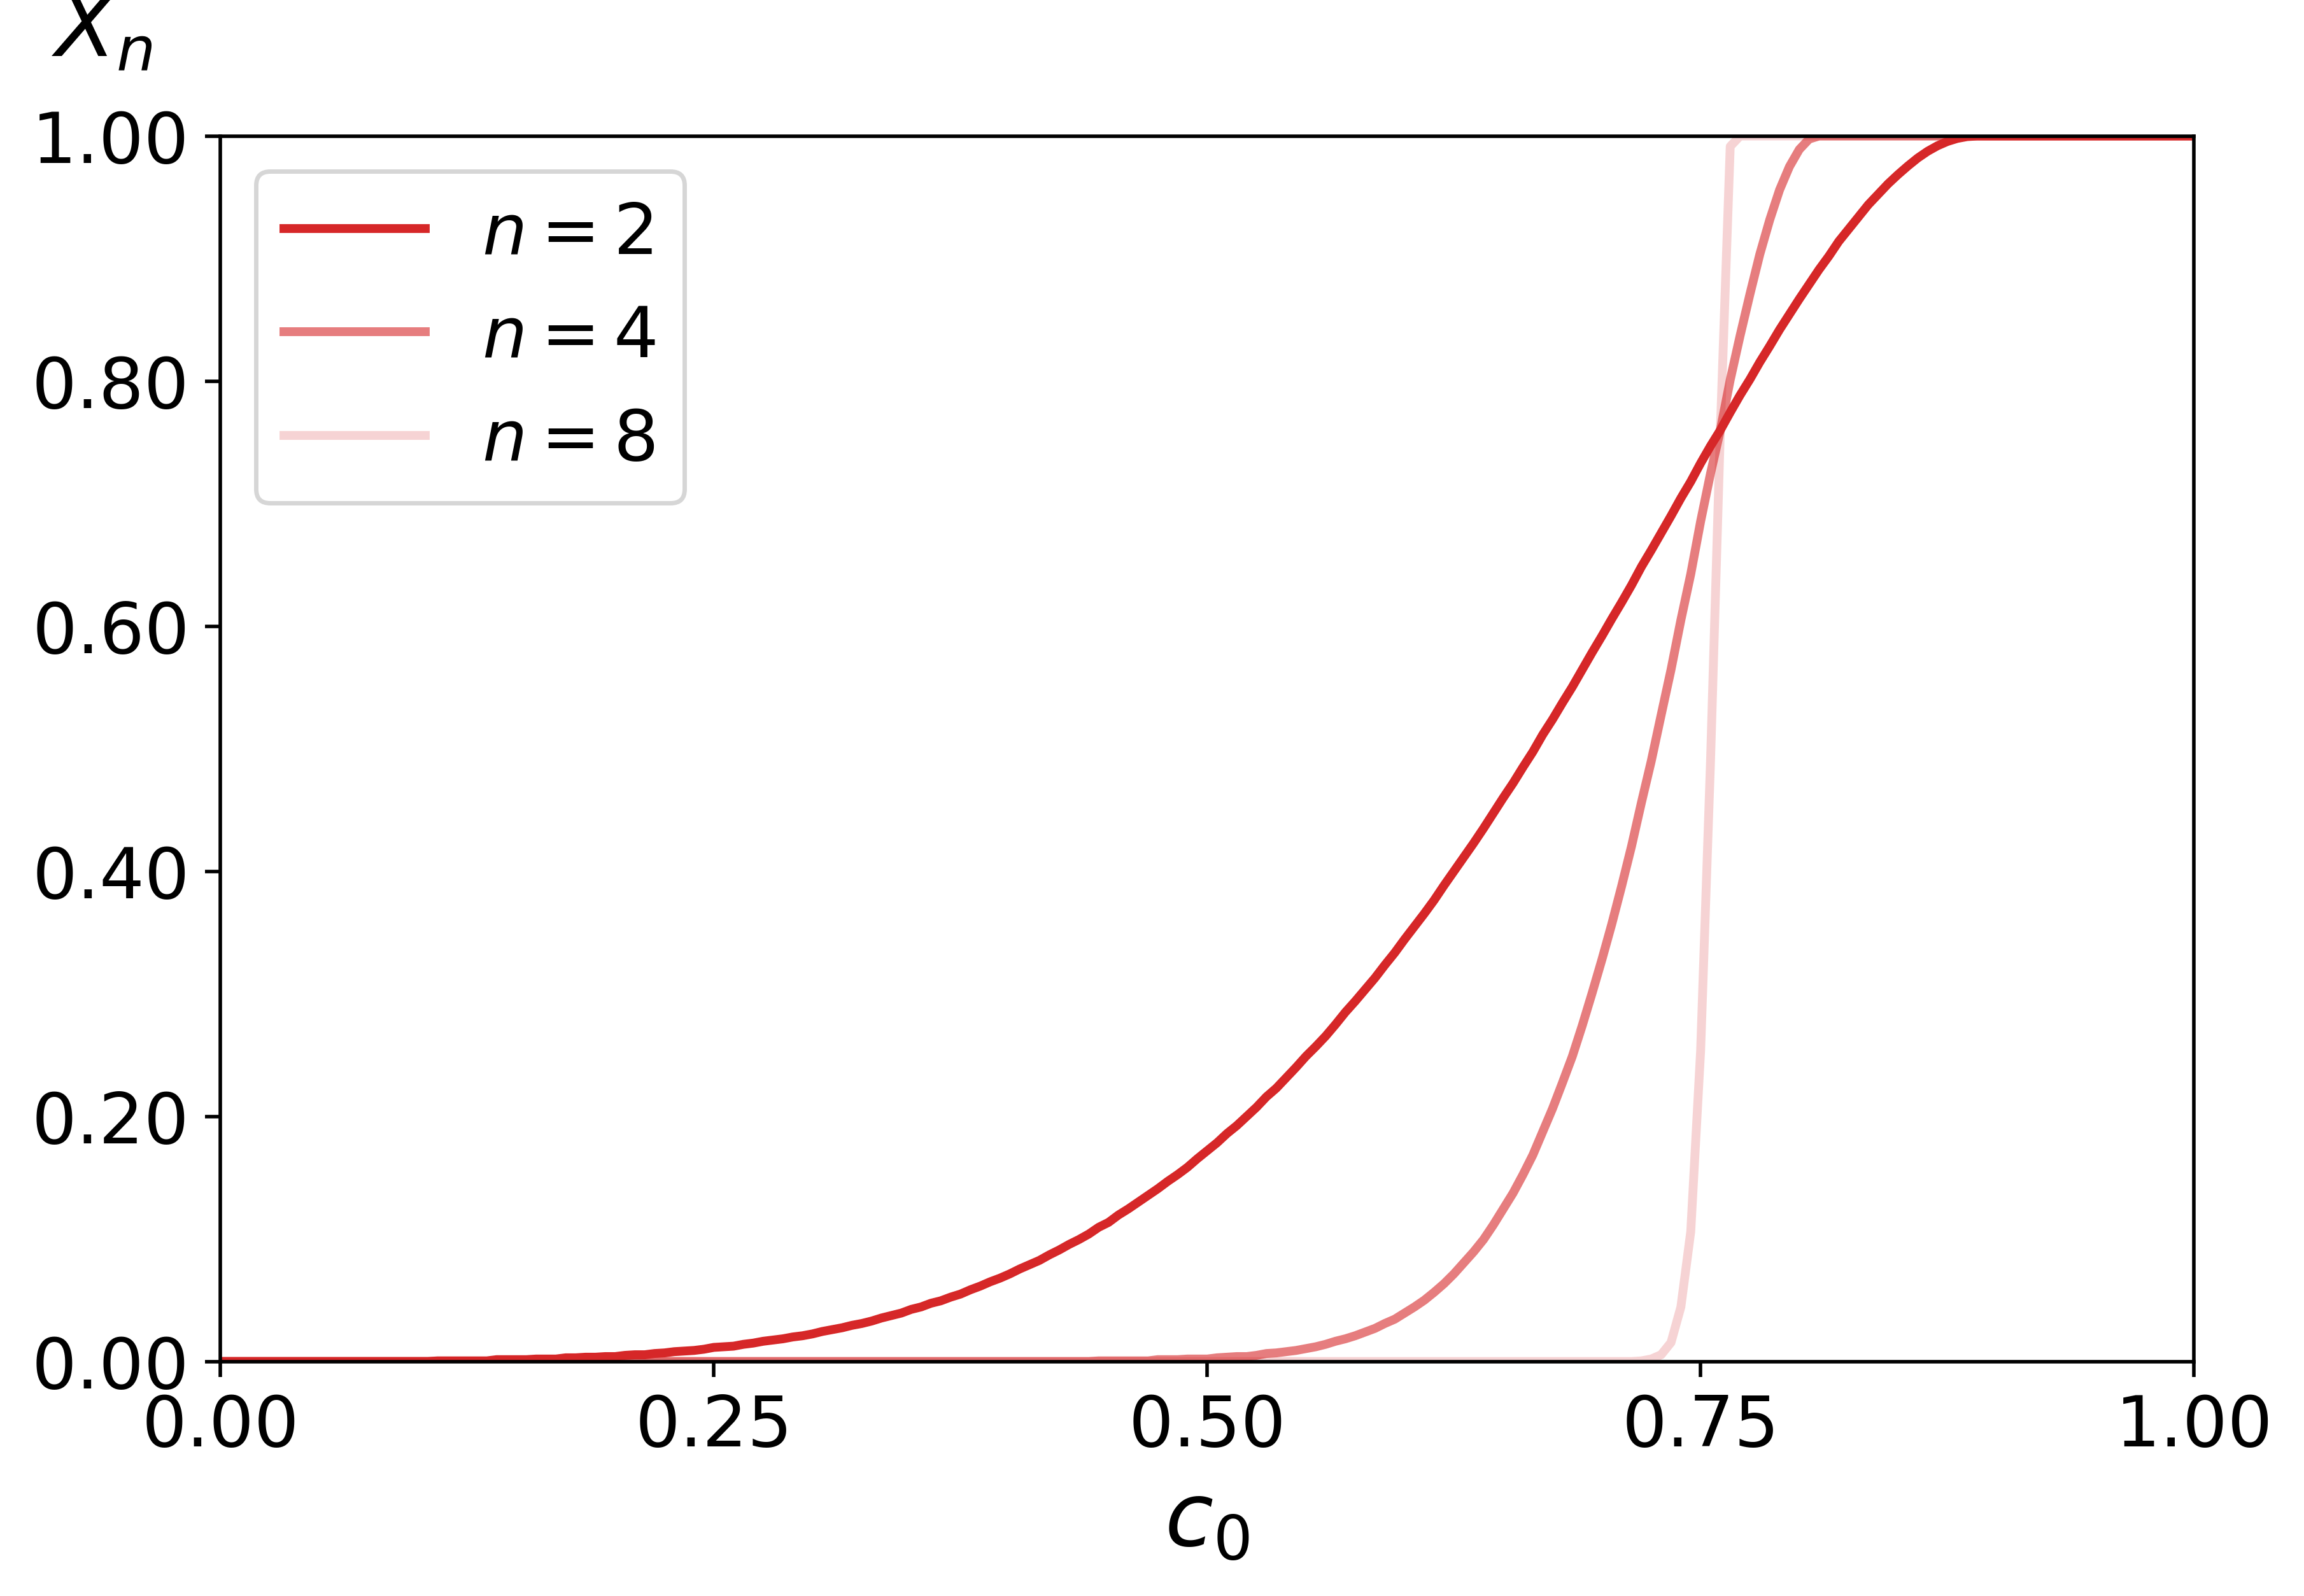

In [6]:
# ============================================================
# Transition curves: E[X_n] vs initial concurrence c_0
# Uses the PMF mean function pmf_mean_conpt_uv(...)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


def plot_EXn_vs_c0_transition_curves(
    *,
    U=2,
    V=2,
    eta_s=0.95,
    eta_p=0.95,
    n_list=(2, 4, 8),          # configurable n values
    alpha_list=(1.0, 0.8, 0.6),# matching line transparencies
    c0_min=0.0,
    c0_max=1.0,
    c0_res=201,                # number of c0 points
    n_bins=2001,
    p_min=1e-12,
    max_states=None,
    fig_dpi=500,
    label_fs=20,
    tick_fs=16,
    line_width=2.0,
    return_data=True,
):
    """
    Plot E[X_n] as a function of initial concurrence c_0 for several n values.

    Curves are evaluated using the PMF mean function:
        pmf_mean_conpt_uv(...)
    """

    n_list = list(n_list)
    alpha_list = list(alpha_list)

    if len(alpha_list) < len(n_list):
        # if too few alphas given, extend by repeating last one
        alpha_list = alpha_list + [alpha_list[-1]] * (len(n_list) - len(alpha_list))
    elif len(alpha_list) > len(n_list):
        alpha_list = alpha_list[:len(n_list)]

    c0_vals = np.linspace(float(c0_min), float(c0_max), int(c0_res), dtype=np.float64)

    curves = {}

    # ---- compute curves ----
    for n in n_list:
        y = np.empty_like(c0_vals)
        for i, c0 in enumerate(c0_vals):
            y[i] = pmf_mean_conpt_uv(
                n=int(n),
                U=U,
                V=V,
                c_init=float(c0),
                eta_s=float(eta_s),
                eta_p=float(eta_p),
                n_bins=n_bins,
                p_min=p_min,
                max_states=max_states,
            )
        curves[int(n)] = y

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(8, 5), dpi=fig_dpi)

    for n, alpha in zip(n_list, alpha_list):
        ax.plot(
            c0_vals,
            curves[int(n)],
            color="tab:red",
            alpha=float(alpha),
            linewidth=line_width,
            label=rf"$n={int(n)}$"
        )

    ax.set_xlim(float(c0_min), float(c0_max))
    ax.set_ylim(0.0, 1.0)

    xt = [0.00, 0.25, 0.50, 0.75, 1.00]
    yt = [0.00, 0.20, 0.40, 0.60, 0.80, 1.00]

    ax.set_xticks(xt)
    ax.set_yticks(yt)
    ax.set_xticklabels([f"{t:.2f}" for t in xt])
    ax.set_yticklabels([f"{t:.2f}" for t in yt])

    ax.set_xlabel(r"$c_0$", fontsize=label_fs)
    #ax.set_ylabel(r"$\mathbb{E}[X_n]$", rotation=0, labelpad=28, fontsize=label_fs)
    ax.set_ylabel(r"$X_n$", rotation=0, labelpad=28, fontsize=label_fs)
    ax.yaxis.set_label_coords(-0.06, 1.05)

    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    ax.legend(loc="upper left", frameon=True, fontsize=tick_fs)

    plt.show()

    if return_data:
        return {
            "c0_vals": c0_vals,
            "curves": curves,
            "n_list": n_list,
            "alpha_list": alpha_list,
            "U": int(U),
            "V": int(V),
            "eta_s": float(eta_s),
            "eta_p": float(eta_p),
        }


# ============================================================
# Example call
# ============================================================
out_transition = plot_EXn_vs_c0_transition_curves(
    U=2,
    V=2,
    eta_s=1.0,
    eta_p=1.0,
    n_list=(2, 4, 8),          # configurable
    alpha_list=(1.0, 0.6, 0.2),
    c0_min=0.0,
    c0_max=1.0,
    c0_res=201,
    n_bins=2001,
    p_min=1e-12,
    max_states=None,
)

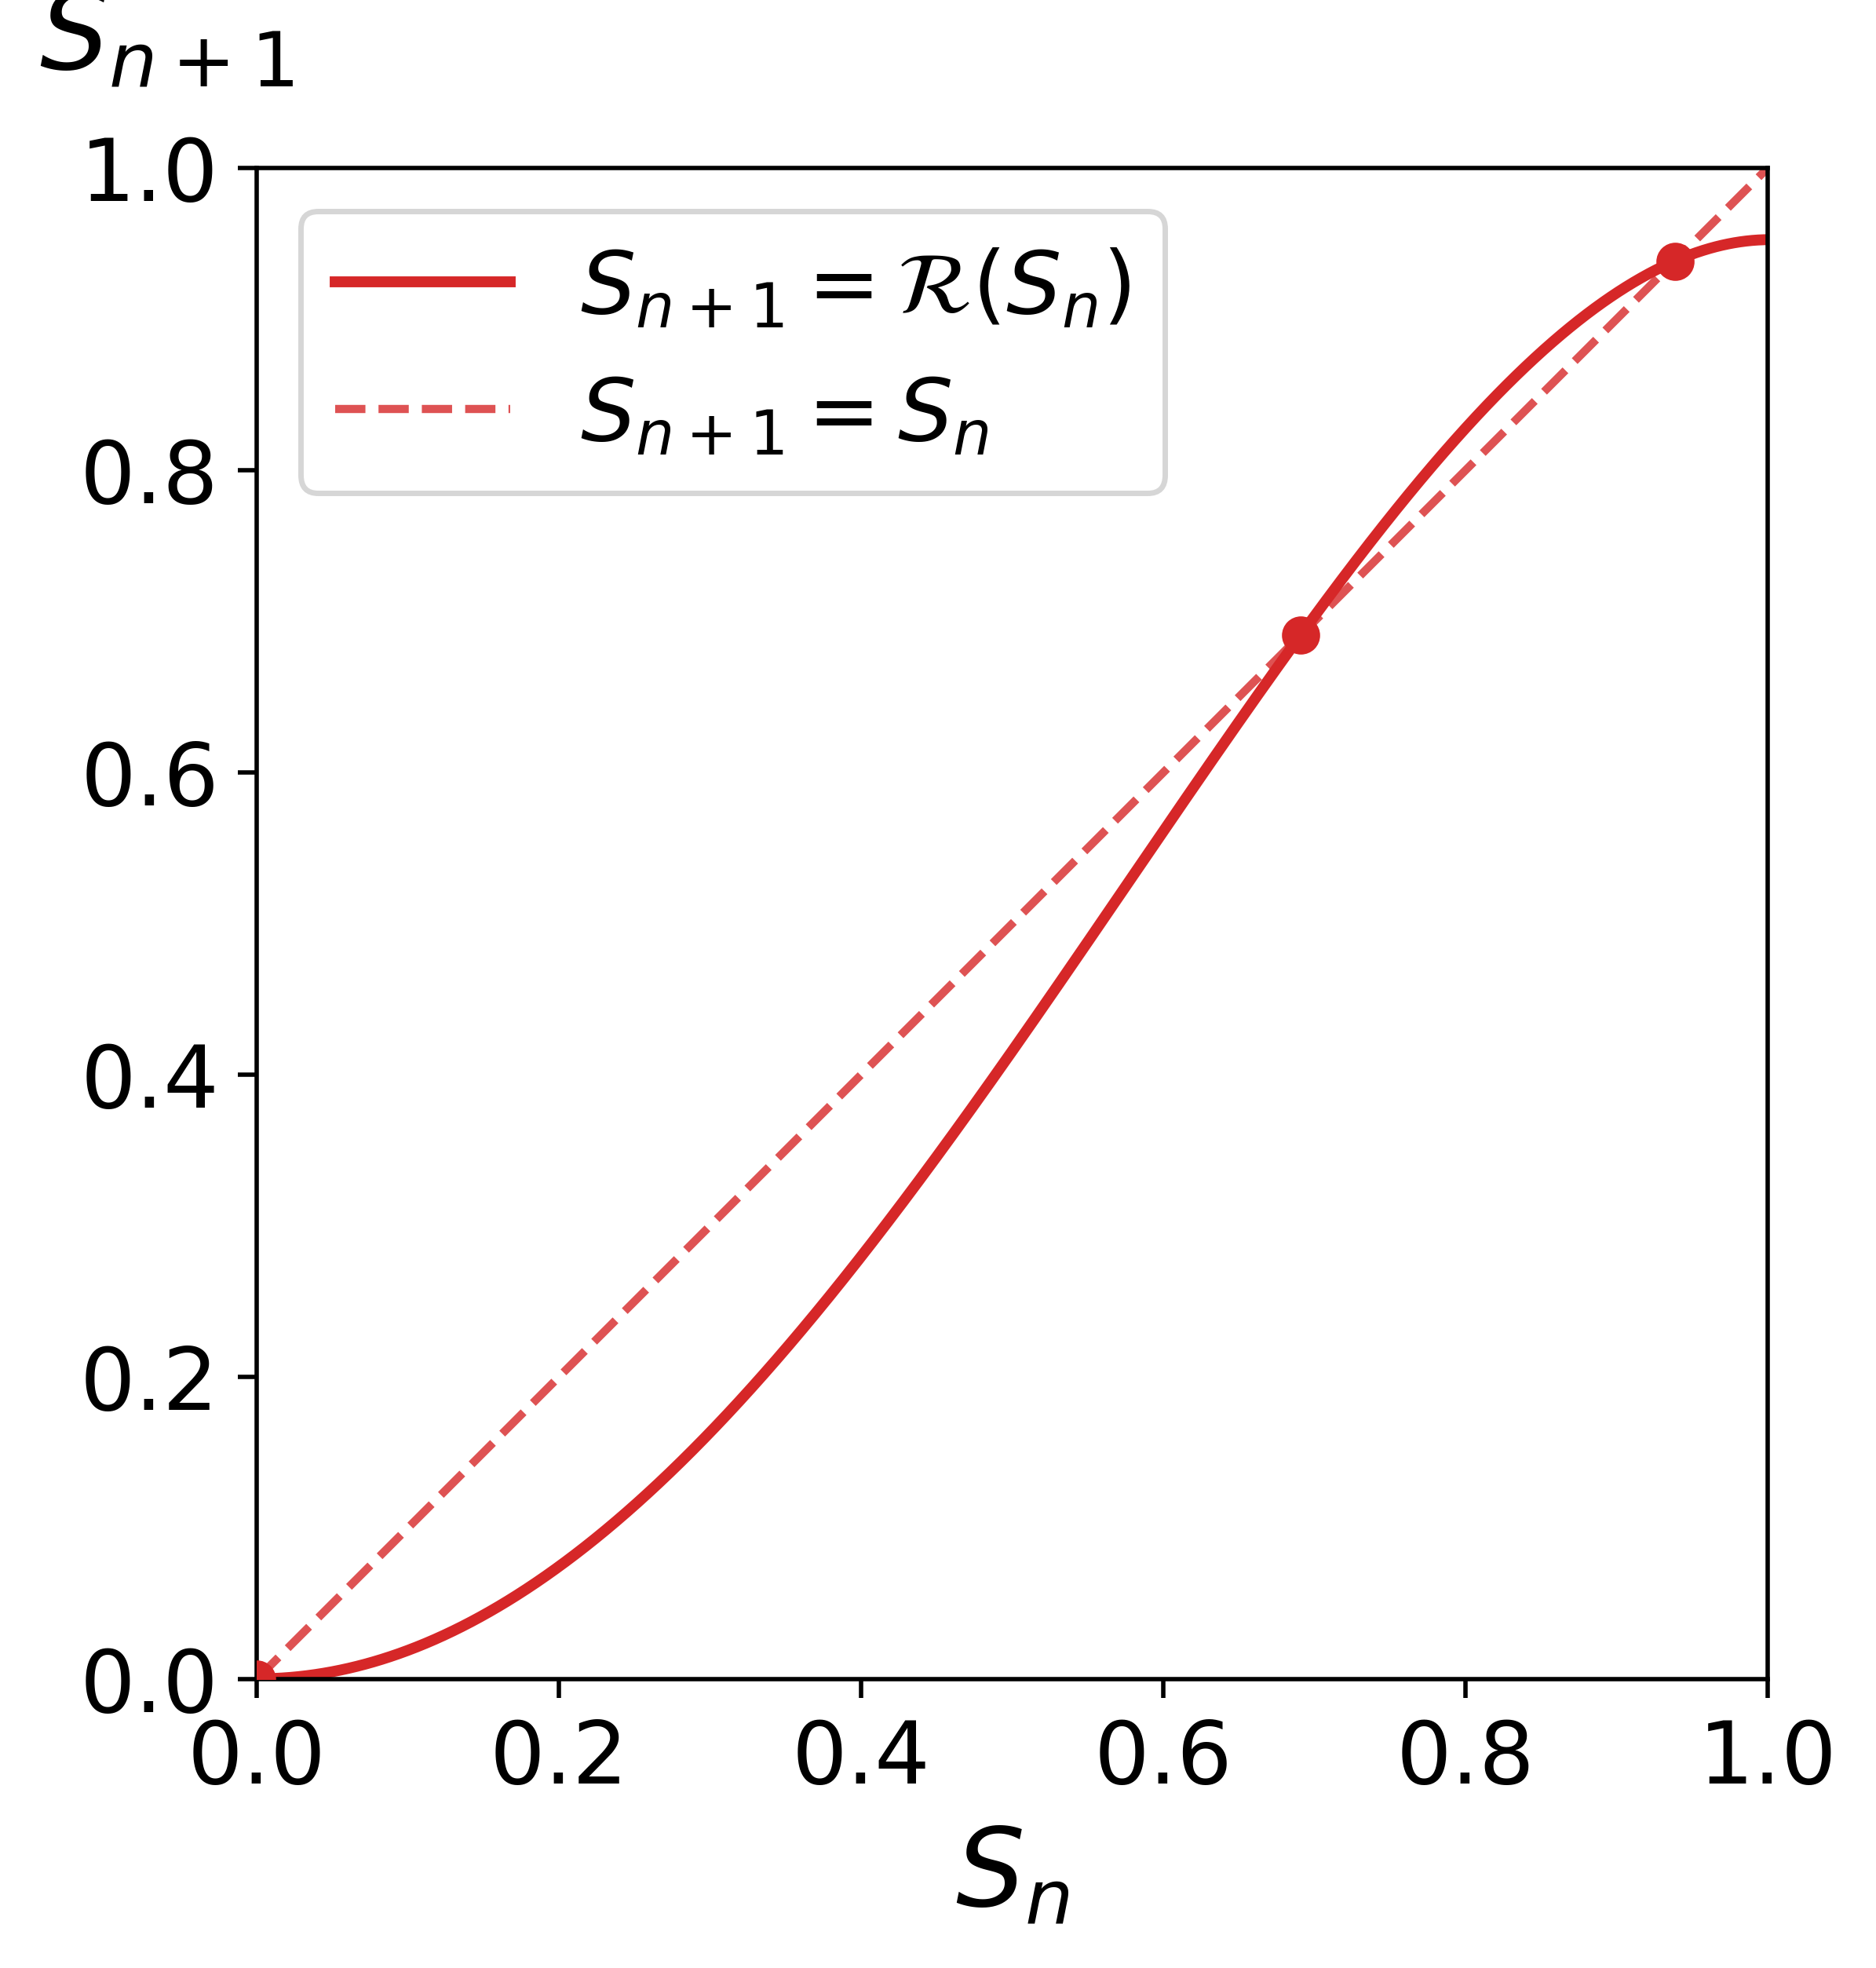

In [ ]:
## Survival probability renormalization group flow plot

import numpy as np
import matplotlib.pyplot as plt


def s_map(s, U, V, eta_s, eta_p):
    s = np.asarray(s, dtype=np.float64)
    sU = (eta_s ** (U - 1)) * (s ** U)
    sV = (eta_s ** (V - 1)) * (s ** V)
    return eta_p * sU * sV + sU * (1.0 - sV) + sV * (1.0 - sU)


def plot_s_fixed_point_map(
    *,
    U=2,
    V=2,
    eta_s=0.95,
    eta_p=0.95,
    n_curve=2000,
    fig_dpi=500,
    label_fs=20,
    tick_fs=16,
    show_fixed_points=True,
):
    # grid for s_n
    s_vals = np.linspace(0.0, 1.0, int(n_curve), dtype=np.float64)
    s_next = s_map(s_vals, U, V, eta_s, eta_p)

    fig, ax = plt.subplots(figsize=(8, 5), dpi=fig_dpi)

    # main RG / recursion curve
    ax.plot(
        s_vals,
        s_next,
        color="tab:red",
        linewidth=2.0,
        label=r"$S_{n+1}=\mathcal{R}(S_n)$"
    )

    # diagonal fixed-point line
    ax.plot(
        s_vals,
        s_vals,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        label=r"$S_{n+1}=S_n$"
    )

    # optional: mark fixed points numerically
    if show_fixed_points:
        diff = s_next - s_vals
        roots = []

        for i in range(len(s_vals) - 1):
            a, b = s_vals[i], s_vals[i + 1]
            fa, fb = diff[i], diff[i + 1]

            if fa == 0.0:
                roots.append(a)
            elif fa * fb < 0.0:
                lo, hi = a, b
                flo, fhi = fa, fb
                for _ in range(60):
                    mid = 0.5 * (lo + hi)
                    fmid = s_map(mid, U, V, eta_s, eta_p) - mid
                    if abs(fmid) < 1e-14 or (hi - lo) < 1e-12:
                        break
                    if flo * fmid <= 0.0:
                        hi, fhi = mid, fmid
                    else:
                        lo, flo = mid, fmid
                roots.append(mid)

        # deduplicate nearby roots
        roots_sorted = []
        for r in sorted(roots):
            if not roots_sorted or abs(r - roots_sorted[-1]) > 1e-4:
                roots_sorted.append(r)

        if roots_sorted:
            roots_sorted = np.array(roots_sorted, dtype=np.float64)
            ax.scatter(
                roots_sorted,
                roots_sorted,
                color="tab:red",
                s=36,
                zorder=5
            )

    ax.set_xlim(0.0, 1.0)
    ax.set_ylim(0.0, 1.0)
    ax.set_aspect("equal", adjustable="box") # make the plot SQUARE

    ticks = np.linspace(0.0, 1.0, 6)
    ax.set_xticks(ticks)
    ax.set_yticks(ticks)
    ax.set_xticklabels([f"{t:.1f}" for t in ticks])
    ax.set_yticklabels([f"{t:.1f}" for t in ticks])

    ax.set_xlabel(r"$S_n$", fontsize=label_fs)
    ax.set_ylabel(r"$S_{n+1}$", rotation=0, labelpad=18, fontsize=label_fs)
    ax.yaxis.set_label_coords(-0.06, 1.05)

    ax.tick_params(axis="both", which="both", labelsize=tick_fs)

    ax.legend(loc="upper left", frameon=True, fontsize=tick_fs)

    plt.show()

    return {
        "s_vals": s_vals,
        "s_next": s_next,
        "U": int(U),
        "V": int(V),
        "eta_s": float(eta_s),
        "eta_p": float(eta_p),
    }


# Example call
out_fixed = plot_s_fixed_point_map(
    U=2,
    V=2,
    eta_s=0.95,
    eta_p=0.95
)

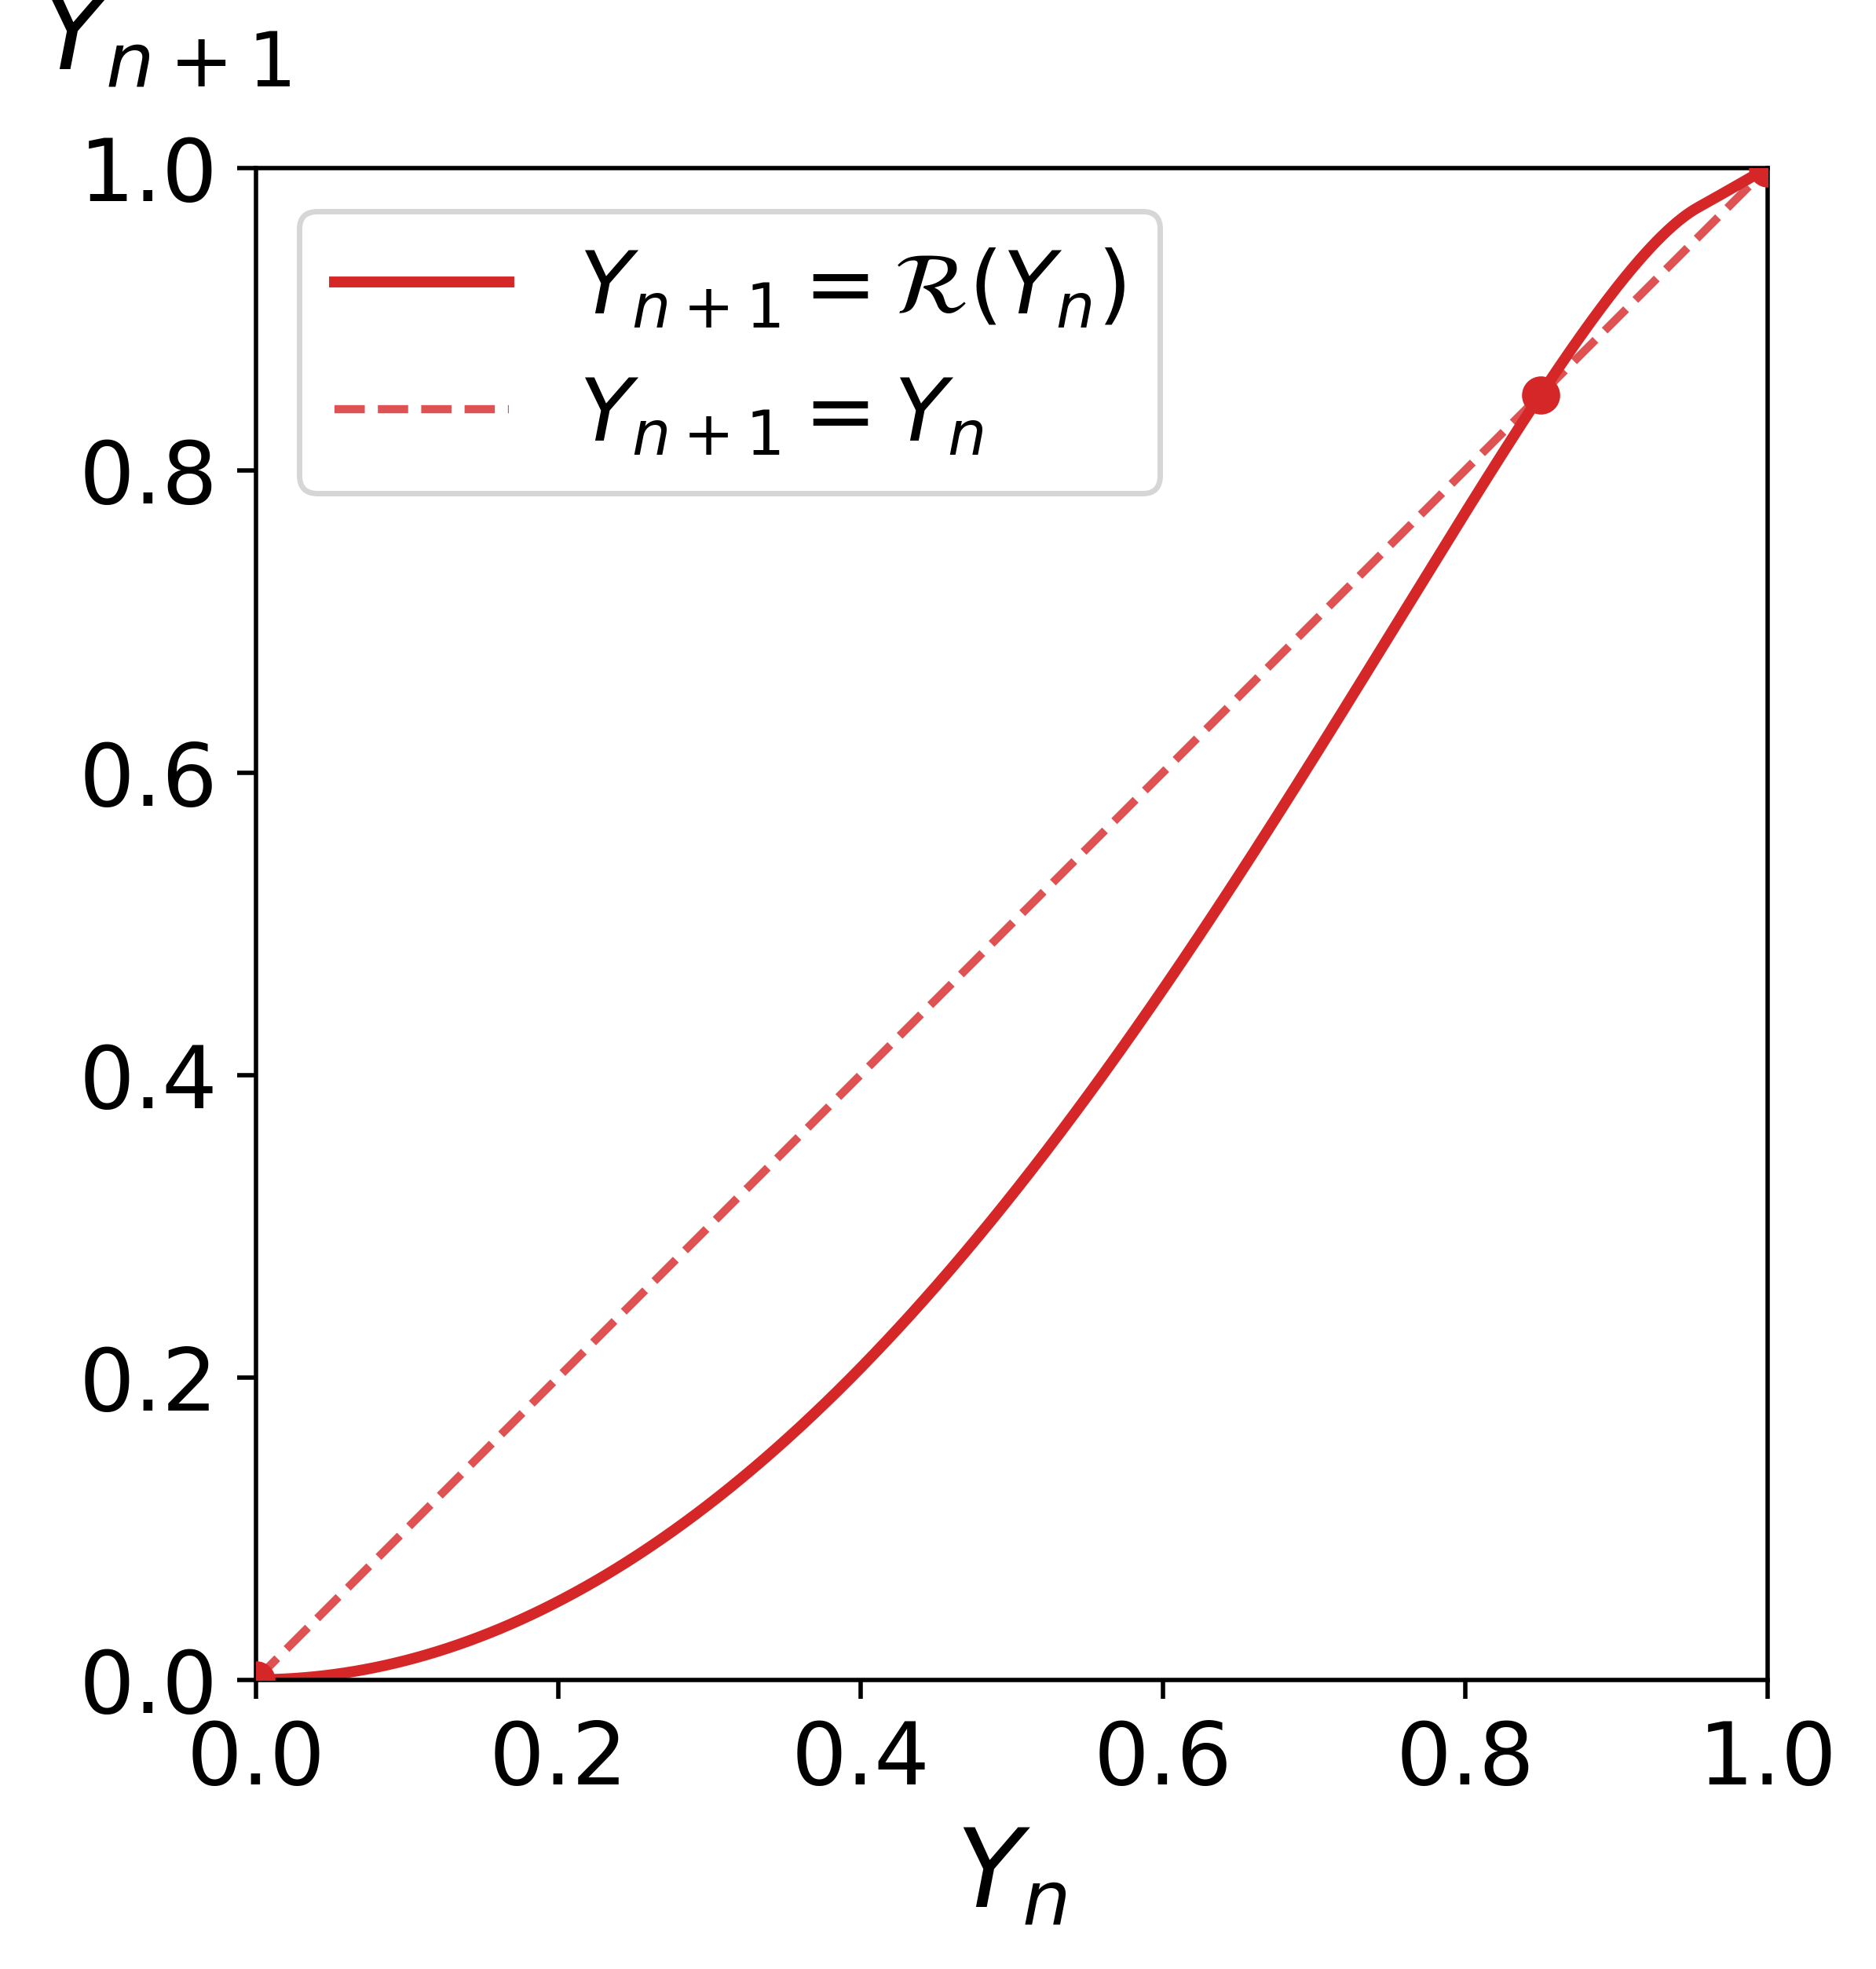

In [3]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# Survival probability map (needed to compute s_infinity)
# ============================================================

def s_map(s, U, V, eta_s, eta_p):
    s = np.asarray(s, dtype=np.float64)
    sU = (eta_s ** (U - 1)) * (s ** U)
    sV = (eta_s ** (V - 1)) * (s ** V)
    return eta_p * sU * sV + sU * (1.0 - sV) + sV * (1.0 - sU)


def compute_s_inf(U, V, eta_s, eta_p, tol=1e-14, max_iter=200000):

    s = 1.0
    for _ in range(max_iter):
        sn = s_map(s, U, V, eta_s, eta_p)
        if abs(sn - s) < tol:
            break
        s = sn

    return float(s)


# ============================================================
# Parallel concurrence map
# ============================================================

def para_conpt(a, b):

    a = np.clip(a, 0.0, 1.0)
    b = np.clip(b, 0.0, 1.0)

    mu = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - a*a)))
    mv = 0.5 * (1.0 + np.sqrt(np.maximum(0.0, 1.0 - b*b)))

    M = np.maximum(0.5, mu*mv)

    return 2.0 * np.sqrt(np.maximum(0.0, M*(1.0-M)))


# ============================================================
# Mean-field y recursion
# ============================================================

def y_map(y, U, V, eta_s, eta_p, s_inf):

    if s_inf <= 1e-14:
        return np.zeros_like(y)

    sU = (eta_s ** (U - 1)) * (s_inf ** U)
    sV = (eta_s ** (V - 1)) * (s_inf ** V)

    w_p = eta_p * sU * sV / s_inf
    w_u = sU * (1.0 - sV) / s_inf
    w_v = sV * (1.0 - sU) / s_inf

    yU = y**U
    yV = y**V

    return (
        w_p * para_conpt(yU, yV)
        + w_u * yU
        + w_v * yV
    )


# ============================================================
# Plot RG flow
# ============================================================

def plot_y_fixed_point_map(
    *,
    U=2,
    V=2,
    eta_s=0.95,
    eta_p=0.95,
    n_curve=2000,
    fig_dpi=500,
    label_fs=20,
    tick_fs=16,
    show_fixed_points=True,
):

    s_inf = compute_s_inf(U, V, eta_s, eta_p)

    y_vals = np.linspace(0.0, 1.0, int(n_curve))
    y_next = y_map(y_vals, U, V, eta_s, eta_p, s_inf)

    fig, ax = plt.subplots(figsize=(8,5), dpi=fig_dpi)

    # main recursion curve
    ax.plot(
        y_vals,
        y_next,
        color="tab:red",
        linewidth=2.0,
        label=r"$Y_{n+1}=\mathcal{R}(Y_n)$"
    )

    # diagonal
    ax.plot(
        y_vals,
        y_vals,
        color="tab:red",
        linestyle="--",
        linewidth=1.5,
        alpha=0.8,
        label=r"$Y_{n+1}=Y_n$"
    )

    # fixed points
    if show_fixed_points:

        diff = y_next - y_vals
        roots = []

        for i in range(len(y_vals)-1):

            a, b = y_vals[i], y_vals[i+1]
            fa, fb = diff[i], diff[i+1]

            if fa == 0:
                roots.append(a)

            elif fa*fb < 0:

                lo, hi = a, b
                flo, fhi = fa, fb

                for _ in range(60):

                    mid = 0.5*(lo+hi)
                    fmid = y_map(mid, U, V, eta_s, eta_p, s_inf) - mid

                    if abs(fmid) < 1e-14 or (hi-lo) < 1e-12:
                        break

                    if flo*fmid <= 0:
                        hi, fhi = mid, fmid
                    else:
                        lo, flo = mid, fmid

                roots.append(mid)

        roots_sorted = []

        for r in sorted(roots):
            if not roots_sorted or abs(r-roots_sorted[-1]) > 1e-4:
                roots_sorted.append(r)

        if roots_sorted:

            roots_sorted = np.array(roots_sorted)

            ax.scatter(
                roots_sorted,
                roots_sorted,
                color="tab:red",
                s=36,
                zorder=5
            )

    ax.set_xlim(0,1)
    ax.set_ylim(0,1)
    ax.set_aspect("equal", adjustable="box")

    ticks = np.linspace(0,1,6)

    ax.set_xticks(ticks)
    ax.set_yticks(ticks)

    ax.set_xticklabels([f"{t:.1f}" for t in ticks])
    ax.set_yticklabels([f"{t:.1f}" for t in ticks])

    ax.set_xlabel(r"$Y_n$", fontsize=label_fs)

    ax.set_ylabel(
        r"$Y_{n+1}$",
        rotation=0,
        labelpad=18,
        fontsize=label_fs
    )

    ax.yaxis.set_label_coords(-0.06,1.05)

    ax.tick_params(axis="both", labelsize=tick_fs)

    ax.legend(loc="upper left", frameon=True, fontsize=tick_fs)

    plt.show()

    return {
        "y_vals": y_vals,
        "y_next": y_next,
        "s_inf": s_inf
    }


# Example call

out = plot_y_fixed_point_map(
    U=2,
    V=2,
    eta_s=0.95,
    eta_p=0.95
)

In [3]:
plt.rcParams.update({"font.size": 14, "axes.labelsize": 18, "xtick.labelsize": 14, "ytick.labelsize": 14})


## MAKE GIF/VIDEO

In [18]:
import re
from pathlib import Path
import imageio.v2 as imageio


def natural_sort_key(s):
    """
    Human sorting so n2 < n10
    """
    s = str(s)
    return [int(text) if text.isdigit() else text.lower()
            for text in re.split(r'(\d+)', s)]


def make_mp4_from_pngs(
    folder="gif",
    output_name="animation.mp4",
    duration_ms=300,
    fps=None
):
    """
    Convert PNG frames into an MP4 animation.

    Parameters
    ----------
    folder : str
        Folder containing PNG images.
    output_name : str
        Output MP4 filename.
    duration_ms : int
        Duration per frame in milliseconds.
    fps : float
        Frames per second. If None it is computed from duration.
    """

    folder = Path(folder)

    png_files = sorted(folder.glob("*.png"), key=natural_sort_key)

    if not png_files:
        raise ValueError("No PNG files found.")

    if fps is None:
        fps = 1000 / duration_ms

    output_path = folder / output_name

    writer = imageio.get_writer(
        output_path,
        fps=fps,
        codec="libx264",
        quality=10
    )

    for file in png_files:
        img = imageio.imread(file)
        writer.append_data(img)

    writer.close()

    print(f"MP4 saved to: {output_path}")
    print(f"Frames: {len(png_files)}")
    print(f"FPS: {fps:.2f}")

    return output_path


# Example usage
make_mp4_from_pngs(
    folder="gif",
    output_name="EXn_heat_animation.mp4",
    duration_ms=500
)

IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (3907, 2389) to (3920, 2400) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
[rawvideo @ 0x1298044f0] Stream #0: not enough frames to estimate rate; consider increasing probesize


MP4 saved to: gif/EXn_heat_animation.mp4
Frames: 10
FPS: 2.00


PosixPath('gif/EXn_heat_animation.mp4')